# Phase 3 — Transformer Development

### Dataset Loading and Environment Setup
Objective: Load and verify the previously prepared Phase 3 dataset for Transformer development.
The dataset contains 16-bar musical windows with normalized melody notes, genre information, beat-level timing features, and structured chord-progression targets.
The model will learn to predict twelve relative chord roots and seven chord families.
Training, validation, and testing partitions will remain unchanged to ensure reproducibility and fair experimental comparisons.

In [2]:
import json
from pathlib import Path
from collections import Counter

import pandas as pd


# -----------------------------------
# 1. Locate project directory
# -----------------------------------

PROJECT_NAME = "vocal-harmonization"

search_paths = [
    Path.cwd(),
    *Path.cwd().parents,
    Path.home() / "Developer" / PROJECT_NAME
]

PROJECT_ROOT = None

for path in search_paths:

    candidate = (
        path / "datasets"
        / "mtg-jamendo"
        / "phase3-prepared"
        / "windows_v2_7family_timing_provisional.jsonl"
    )

    if candidate.exists():
        PROJECT_ROOT = path
        break

assert PROJECT_ROOT is not None, (
    "Could not locate the project dataset."
)


# -----------------------------------
# 2. Dataset path
# -----------------------------------

DATASET_FILE = (
    PROJECT_ROOT
    / "datasets"
    / "mtg-jamendo"
    / "phase3-prepared"
    / "windows_v2_7family_timing_provisional.jsonl"
)

print("PROJECT ROOT:")
print(PROJECT_ROOT)

print("\nDATASET FILE:")
print(DATASET_FILE)


# -----------------------------------
# 3. Define label vocabularies
# -----------------------------------

ROOT_LABELS = [
    "I", "♭II", "II", "♭III",
    "III", "IV", "♯IV", "V",
    "♭VI", "VI", "♭VII", "VII"
]

FAMILY_LABELS = [
    "MAJ",
    "MIN",
    "DOM",
    "DIM",
    "HDIM",
    "AUG",
    "SUS"
]

GENRE_LABELS = [
    "rock",
    "pop",
    "electronic",
    "folk",
    "jazz"
]

NUM_ROOTS = len(ROOT_LABELS)
NUM_FAMILIES = len(FAMILY_LABELS)
NUM_GENRES = len(GENRE_LABELS)


# -----------------------------------
# 4. Load examples
# -----------------------------------

examples = []

with open(
    DATASET_FILE,
    "r",
    encoding="utf-8"
) as file:

    for line in file:
        examples.append(json.loads(line))


# -----------------------------------
# 5. Verify dataset
# -----------------------------------

split_counts = Counter(
    ex["split"] for ex in examples
)

song_counts = {
    split: len({
        ex["track_id"]
        for ex in examples
        if ex["split"] == split
    })
    for split in ["train", "val", "test"]
}

total_notes = sum(
    len(ex["melody"])
    for ex in examples
)

total_beats = sum(
    len(ex["beat_grid"])
    for ex in examples
)

valid_targets = sum(
    target["model_target_mask"]
    for ex in examples
    for target in ex["beat_targets"]
)

assert len(examples) == 8909

assert split_counts["train"] == 6282
assert split_counts["val"] == 1405
assert split_counts["test"] == 1222

assert total_beats == 533710
assert valid_targets == 476303


# -----------------------------------
# 6. Display dataset summary
# -----------------------------------

print("\nDATASET SUMMARY")
print("--------------------------------")

print("Total windows:", len(examples))
print("Total songs:", len(set(
    ex["track_id"] for ex in examples
)))

print("Melody notes:", total_notes)
print("Beat positions:", total_beats)
print("Valid chord targets:", valid_targets)

print("\nSPLIT DISTRIBUTION")
print("--------------------------------")

display(
    pd.DataFrame([
        {
            "Split": split,
            "Windows": split_counts[split],
            "Songs": song_counts[split]
        }
        for split in ["train", "val", "test"]
    ])
)


# -----------------------------------
# 7. Inspect one example
# -----------------------------------

sample = examples[0]

print("\nSAMPLE TRAINING EXAMPLE")
print("--------------------------------")

print("Track:", sample["track_id"])
print("Split:", sample["split"])
print("Duration:", sample["duration_sec"], "seconds")

print("Melody notes:", len(sample["melody"]))
print("Beat positions:", len(sample["beat_grid"]))

print("Genre vector:", sample["genre_vector"])

print("\nFirst 5 melody notes:")

display(
    pd.DataFrame(
        sample["melody"][:5]
    )
)

print("\nFirst 10 chord targets:")

display(
    pd.DataFrame(
        sample["beat_targets"][:10]
    )[
        [
            "beat_index",
            "root_id",
            "family_id",
            "plan_label",
            "model_target_mask"
        ]
    ]
)


print("\nDataset loaded successfully!")

PROJECT ROOT:
/Users/praise/Developer/vocal-harmonization

DATASET FILE:
/Users/praise/Developer/vocal-harmonization/datasets/mtg-jamendo/phase3-prepared/windows_v2_7family_timing_provisional.jsonl

DATASET SUMMARY
--------------------------------
Total windows: 8909
Total songs: 1069
Melody notes: 633883
Beat positions: 533710
Valid chord targets: 476303

SPLIT DISTRIBUTION
--------------------------------


,Split,Windows,Songs
0,train,6282,752
1,val,1405,176
2,test,1222,141



SAMPLE TRAINING EXAMPLE
--------------------------------
Track: track_0000382
Split: train
Duration: 33.43 seconds
Melody notes: 63
Beat positions: 64
Genre vector: [0, 0, 0, 0, 0]

First 5 melody notes:


,onset_sec,duration_sec,midi_pitch,pitch_class
0,0.00000,0.23479,69,9
1,0.23479,1.06511,69,9
2,1.29990,0.59531,69,9
3,1.89521,0.57500,65,5
4,2.47021,0.13958,65,5



First 10 chord targets:


,beat_index,root_id,family_id,plan_label,model_target_mask
0,0,NaN,NaN,N.C.,0
1,1,5.0,0.0,IV:MAJ,1
2,2,5.0,0.0,IV:MAJ,1
3,3,5.0,0.0,IV:MAJ,1
4,4,5.0,0.0,IV:MAJ,1
5,5,5.0,0.0,IV:MAJ,1
6,6,5.0,0.0,IV:MAJ,1
7,7,5.0,0.0,IV:MAJ,1
8,8,NaN,NaN,NaN,0
9,9,10.0,0.0,♭VII:MAJ,1



Dataset loaded successfully!


### PyTorch Dataset Construction
Objective: Convert the prepared symbolic melody and harmonic-plan data into PyTorch tensors suitable for Transformer training.
Melody notes are represented using MIDI pitch identifiers and numerical timing features. Beat-level musical positions and genre labels are preserved.
The decoder receives previous chord-root and chord-family tokens during training. Unreliable chord annotations are represented using unknown tokens and excluded from the supervised loss.
Special tokens are reserved for sequence initialization and padding. Variable-length sequences will be handled by a custom batching function in the next step.

In [3]:
import torch
from torch.utils.data import Dataset


# -----------------------------------
# 1. Special token definitions
# -----------------------------------

ROOT_BOS = 12
ROOT_UNK = 13
ROOT_PAD = 14

FAMILY_BOS = 7
FAMILY_UNK = 8
FAMILY_PAD = 9

IGNORE_INDEX = -100


# -----------------------------------
# 2. PyTorch Dataset
# -----------------------------------

class HarmonyDataset(Dataset):

    def __init__(self, examples, split):

        self.examples = [
            ex for ex in examples
            if ex["split"] == split
        ]

    def __len__(self):

        return len(self.examples)

    def __getitem__(self, idx):

        ex = self.examples[idx]

        duration = float(ex["duration_sec"])

        melody = ex["melody"]
        beats = ex["beat_grid"]
        targets = ex["beat_targets"]

        # -----------------------------------
        # 3. Melody encoder inputs
        # -----------------------------------

        melody_pitch = torch.tensor(
            [
                int(note["midi_pitch"])
                for note in melody
            ],
            dtype=torch.long
        )

        melody_time = torch.tensor(
            [
                [
                    note["onset_sec"] / duration,
                    note["duration_sec"] / duration
                ]
                for note in melody
            ],
            dtype=torch.float32
        )

        # -----------------------------------
        # 4. Musical timing inputs
        # -----------------------------------

        beat_time = torch.tensor(
            [
                [
                    beat["time_sec"] / duration,
                    beat["duration_sec"] / duration
                ]
                for beat in beats
            ],
            dtype=torch.float32
        )

        bar_index = torch.tensor(
            [
                beat["bar_index"]
                for beat in beats
            ],
            dtype=torch.long
        )

        beat_position = torch.tensor(
            [
                beat["beat_in_bar"]
                for beat in beats
            ],
            dtype=torch.long
        )

        meter = torch.tensor(
            [
                beat["meter_numerator"]
                for beat in beats
            ],
            dtype=torch.long
        )

        # -----------------------------------
        # 5. Genre conditioning
        # -----------------------------------

        genre = torch.tensor(
            ex["genre_vector"],
            dtype=torch.float32
        )

        # -----------------------------------
        # 6. Chord prediction targets
        # -----------------------------------

        root_targets = []
        family_targets = []

        for target in targets:

            if target["model_target_mask"] == 1:

                root_targets.append(
                    int(target["root_id"])
                )

                family_targets.append(
                    int(target["family_id"])
                )

            else:

                root_targets.append(IGNORE_INDEX)
                family_targets.append(IGNORE_INDEX)

        # -----------------------------------
        # 7. Shifted decoder inputs
        # -----------------------------------

        previous_roots = [ROOT_BOS]
        previous_families = [FAMILY_BOS]

        for root, family in zip(
            root_targets[:-1],
            family_targets[:-1]
        ):

            previous_roots.append(
                root if root != IGNORE_INDEX
                else ROOT_UNK
            )

            previous_families.append(
                family if family != IGNORE_INDEX
                else FAMILY_UNK
            )

        # -----------------------------------
        # 8. Return one training example
        # -----------------------------------

        return {

            "melody_pitch": melody_pitch,
            "melody_time": melody_time,

            "beat_time": beat_time,
            "bar_index": bar_index,
            "beat_position": beat_position,
            "meter": meter,

            "genre": genre,

            "decoder_root": torch.tensor(
                previous_roots,
                dtype=torch.long
            ),

            "decoder_family": torch.tensor(
                previous_families,
                dtype=torch.long
            ),

            "target_root": torch.tensor(
                root_targets,
                dtype=torch.long
            ),

            "target_family": torch.tensor(
                family_targets,
                dtype=torch.long
            ),

            "track_id": ex["track_id"]
        }


# -----------------------------------
# 9. Create datasets
# -----------------------------------

train_dataset = HarmonyDataset(
    examples, "train"
)

val_dataset = HarmonyDataset(
    examples, "val"
)

test_dataset = HarmonyDataset(
    examples, "test"
)


# -----------------------------------
# 10. Verify dataset sizes
# -----------------------------------

print("PYTORCH DATASET PREPARATION")
print("--------------------------------")

print("Training examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))
print("Testing examples:", len(test_dataset))


# -----------------------------------
# 11. Inspect one tensorized example
# -----------------------------------

sample = train_dataset[0]

print("\nSAMPLE TENSOR SHAPES")
print("--------------------------------")

for name, value in sample.items():

    if isinstance(value, torch.Tensor):
        print(f"{name:20s} {tuple(value.shape)}")


print("\nFIRST 10 DECODER INPUTS")
print("--------------------------------")

print(
    "Previous roots:",
    sample["decoder_root"][:10].tolist()
)

print(
    "Previous families:",
    sample["decoder_family"][:10].tolist()
)


print("\nFIRST 10 EXPECTED TARGETS")
print("--------------------------------")

print(
    "Target roots:",
    sample["target_root"][:10].tolist()
)

print(
    "Target families:",
    sample["target_family"][:10].tolist()
)


print("\nPyTorch dataset construction completed!")

PYTORCH DATASET PREPARATION
--------------------------------
Training examples: 6282
Validation examples: 1405
Testing examples: 1222

SAMPLE TENSOR SHAPES
--------------------------------
melody_pitch         (63,)
melody_time          (63, 2)
beat_time            (64, 2)
bar_index            (64,)
beat_position        (64,)
meter                (64,)
genre                (5,)
decoder_root         (64,)
decoder_family       (64,)
target_root          (64,)
target_family        (64,)

FIRST 10 DECODER INPUTS
--------------------------------
Previous roots: [12, 13, 5, 5, 5, 5, 5, 5, 5, 13]
Previous families: [7, 8, 0, 0, 0, 0, 0, 0, 0, 8]

FIRST 10 EXPECTED TARGETS
--------------------------------
Target roots: [-100, 5, 5, 5, 5, 5, 5, 5, -100, 10]
Target families: [-100, 0, 0, 0, 0, 0, 0, 0, -100, 0]

PyTorch dataset construction completed!


### DataLoader and Sequence Padding
Objective: Create PyTorch DataLoaders that combine variable-length melody and chord sequences into training batches.
Melody sequences and beat-level chord sequences are padded independently to the longest sequence in each batch.
Padding masks identify artificial positions, allowing the Transformer to ignore them during attention. Unreliable chord targets remain excluded from the supervised loss using the IGNORE_INDEX value.
Training examples are shuffled, while validation examples retain a deterministic order. An initial batch size of 16 is used.

In [4]:
import torch

from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence


# -----------------------------------
# 1. Configuration
# -----------------------------------

BATCH_SIZE = 16

torch.manual_seed(42)


# -----------------------------------
# 2. Custom batching function
# -----------------------------------

def harmony_collate_fn(batch):

    # Number of melody notes and beats
    # in each window.

    melody_lengths = torch.tensor(
        [len(item["melody_pitch"]) for item in batch],
        dtype=torch.long
    )

    beat_lengths = torch.tensor(
        [len(item["target_root"]) for item in batch],
        dtype=torch.long
    )

    # -----------------------------------
    # 3. Padding configuration
    # -----------------------------------

    padding_values = {

        "melody_pitch": 0,
        "melody_time": 0.0,

        "beat_time": 0.0,
        "bar_index": 0,
        "beat_position": 0,
        "meter": 0,

        "decoder_root": ROOT_PAD,
        "decoder_family": FAMILY_PAD,

        "target_root": IGNORE_INDEX,
        "target_family": IGNORE_INDEX
    }

    padded = {}

    # -----------------------------------
    # 4. Pad variable-length tensors
    # -----------------------------------

    for name, pad_value in padding_values.items():

        sequences = [
            item[name]
            for item in batch
        ]

        padded[name] = pad_sequence(
            sequences,
            batch_first=True,
            padding_value=pad_value
        )

    # -----------------------------------
    # 5. Stack genre vectors
    # -----------------------------------

    padded["genre"] = torch.stack(
        [item["genre"] for item in batch]
    )

    # -----------------------------------
    # 6. Create padding masks
    # -----------------------------------

    max_melody_length = padded[
        "melody_pitch"
    ].shape[1]

    max_beat_length = padded[
        "target_root"
    ].shape[1]

    melody_positions = torch.arange(
        max_melody_length
    ).unsqueeze(0)

    beat_positions = torch.arange(
        max_beat_length
    ).unsqueeze(0)

    # True = padding position
    # False = real position

    padded["melody_padding_mask"] = (
        melody_positions >= melody_lengths.unsqueeze(1)
    )

    padded["beat_padding_mask"] = (
        beat_positions >= beat_lengths.unsqueeze(1)
    )

    # -----------------------------------
    # 7. Supervised target mask
    # -----------------------------------

    # True = reliable chord target

    padded["target_valid_mask"] = (
        padded["target_root"] != IGNORE_INDEX
    )

    # -----------------------------------
    # 8. Preserve metadata
    # -----------------------------------

    padded["melody_lengths"] = melody_lengths
    padded["beat_lengths"] = beat_lengths

    padded["track_ids"] = [
        item["track_id"]
        for item in batch
    ]

    return padded


# -----------------------------------
# 9. Create DataLoaders
# -----------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=harmony_collate_fn
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=harmony_collate_fn
)

# Test data remains reserved for final evaluation.


# -----------------------------------
# 10. Inspect one training batch
# -----------------------------------

batch = next(iter(train_loader))

print("PHASE 3 — DATALOADER")
print("--------------------------------")

print("Batch size:", BATCH_SIZE)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))


print("\nBATCH TENSOR SHAPES")
print("--------------------------------")

for name, value in batch.items():

    if isinstance(value, torch.Tensor):

        print(
            f"{name:25s} "
            f"{tuple(value.shape)}"
        )


# -----------------------------------
# 11. Check sequence lengths
# -----------------------------------

print("\nSEQUENCE LENGTHS")
print("--------------------------------")

print(
    "Melody lengths:",
    batch["melody_lengths"].tolist()
)

print(
    "Beat lengths:",
    batch["beat_lengths"].tolist()
)


# -----------------------------------
# 12. Verify padding masks
# -----------------------------------

assert (
    (~batch["melody_padding_mask"]).sum(dim=1)
    == batch["melody_lengths"]
).all()

assert (
    (~batch["beat_padding_mask"]).sum(dim=1)
    == batch["beat_lengths"]
).all()

assert (
    batch["target_valid_mask"]
    & batch["beat_padding_mask"]
).sum() == 0

assert torch.equal(
    batch["target_root"] != IGNORE_INDEX,
    batch["target_family"] != IGNORE_INDEX
)


print("\nPADDING VALIDATION")
print("--------------------------------")

print("Melody padding: Correct")
print("Beat padding: Correct")
print("Target masks: Correct")


# -----------------------------------
# 13. Count valid targets in batch
# -----------------------------------

print("\nBATCH TARGET STATISTICS")
print("--------------------------------")

print(
    "Real melody notes:",
    int(
        (~batch["melody_padding_mask"]).sum()
    )
)

print(
    "Real beats:",
    int(
        (~batch["beat_padding_mask"]).sum()
    )
)

print(
    "Valid chord targets:",
    int(
        batch["target_valid_mask"].sum()
    )
)


print("\nDataLoader construction completed!")

PHASE 3 — DATALOADER
--------------------------------
Batch size: 16
Training batches: 393
Validation batches: 88

BATCH TENSOR SHAPES
--------------------------------
melody_pitch              (16, 127)
melody_time               (16, 127, 2)
beat_time                 (16, 96, 2)
bar_index                 (16, 96)
beat_position             (16, 96)
meter                     (16, 96)
decoder_root              (16, 96)
decoder_family            (16, 96)
target_root               (16, 96)
target_family             (16, 96)
genre                     (16, 5)
melody_padding_mask       (16, 127)
beat_padding_mask         (16, 96)
target_valid_mask         (16, 96)
melody_lengths            (16,)
beat_lengths              (16,)

SEQUENCE LENGTHS
--------------------------------
Melody lengths: [61, 63, 40, 50, 59, 112, 60, 77, 27, 28, 127, 48, 90, 87, 72, 54]
Beat lengths: [96, 64, 64, 64, 64, 64, 64, 64, 32, 48, 64, 64, 64, 64, 96, 64]

PADDING VALIDATION
--------------------------------
Melo

### Melody and Chord Embedding Layers
Objective: Implement learnable input representations for the melody encoder and chord decoder.
Both representations use a common hidden dimension of 128.
The melody representation combines MIDI pitch embeddings, normalized note timing, and sinusoidal positional encoding.
The decoder representation combines previous chord-root and family embeddings with beat timing, bar positions, metre, and sinusoidal positional encoding.
Layer normalization and dropout are applied to the combined representations. Padding positions are set to zero.
The embeddings will be trained jointly with the Transformer. Genre conditioning will be introduced in a later experiment.

In [5]:
import math

import torch
import torch.nn as nn


# -----------------------------------
# 1. Configuration
# -----------------------------------

D_MODEL = 128
DROPOUT = 0.1


# -----------------------------------
# 2. Sinusoidal positional encoding
# -----------------------------------

def add_positional_encoding(x):

    """
    x shape:
        (batch_size, sequence_length, d_model)
    """

    batch_size, seq_len, d_model = x.shape

    positions = torch.arange(
        seq_len,
        device=x.device,
        dtype=x.dtype
    ).unsqueeze(1)

    frequencies = torch.exp(
        torch.arange(
            0,
            d_model,
            2,
            device=x.device,
            dtype=x.dtype
        )
        * (-math.log(10000.0) / d_model)
    )

    angles = positions * frequencies

    pe = torch.zeros(
        seq_len,
        d_model,
        device=x.device,
        dtype=x.dtype
    )

    pe[:, 0::2] = torch.sin(angles)
    pe[:, 1::2] = torch.cos(angles)

    return x + pe.unsqueeze(0)


# -----------------------------------
# 3. Embedding module
# -----------------------------------

class HarmonyInputEmbeddings(nn.Module):

    def __init__(
        self,
        d_model=128,
        dropout=0.1
    ):

        super().__init__()

        # -----------------------------------
        # Melody embeddings
        # -----------------------------------

        # MIDI pitches: 0–127

        self.pitch_embedding = nn.Embedding(
            128,
            d_model
        )

        # Normalized onset + duration

        self.melody_time_projection = nn.Linear(
            2,
            d_model
        )

        # -----------------------------------
        # Decoder chord embeddings
        # -----------------------------------

        # 12 roots + BOS + UNK + PAD

        self.root_embedding = nn.Embedding(
            15,
            d_model,
            padding_idx=ROOT_PAD
        )

        # 7 families + BOS + UNK + PAD

        self.family_embedding = nn.Embedding(
            10,
            d_model,
            padding_idx=FAMILY_PAD
        )

        # -----------------------------------
        # Musical timing embeddings
        # -----------------------------------

        self.beat_time_projection = nn.Linear(
            2,
            d_model
        )

        # Bars 0–15

        self.bar_embedding = nn.Embedding(
            16,
            d_model
        )

        # Beat positions 1–9
        # 0 reserved for padding

        self.beat_position_embedding = nn.Embedding(
            10,
            d_model,
            padding_idx=0
        )

        # Metre values 2–9
        # 0 reserved for padding

        self.meter_embedding = nn.Embedding(
            10,
            d_model,
            padding_idx=0
        )

        # -----------------------------------
        # Normalization and dropout
        # -----------------------------------

        self.melody_norm = nn.LayerNorm(
            d_model
        )

        self.decoder_norm = nn.LayerNorm(
            d_model
        )

        self.dropout = nn.Dropout(
            dropout
        )

    # -----------------------------------
    # 4. Melody encoder embeddings
    # -----------------------------------

    def embed_melody(self, batch):

        pitch = self.pitch_embedding(
            batch["melody_pitch"]
        )

        timing = self.melody_time_projection(
            batch["melody_time"]
        )

        x = pitch + timing

        # Add note-order information.
        x = add_positional_encoding(x)

        x = self.melody_norm(x)

        x = self.dropout(x)

        # Zero artificial padding positions.
        x = x.masked_fill(
            batch["melody_padding_mask"].unsqueeze(-1),
            0.0
        )

        return x

    # -----------------------------------
    # 5. Chord decoder embeddings
    # -----------------------------------

    def embed_decoder(self, batch):

        root = self.root_embedding(
            batch["decoder_root"]
        )

        family = self.family_embedding(
            batch["decoder_family"]
        )

        timing = self.beat_time_projection(
            batch["beat_time"]
        )

        bar = self.bar_embedding(
            batch["bar_index"]
        )

        position = self.beat_position_embedding(
            batch["beat_position"]
        )

        meter = self.meter_embedding(
            batch["meter"]
        )

        # Combine the representations.
        x = (
            root
            + family
            + timing
            + bar
            + position
            + meter
        )

        # Add beat-order information.
        x = add_positional_encoding(x)

        x = self.decoder_norm(x)

        x = self.dropout(x)

        # Zero artificial padding positions.
        x = x.masked_fill(
            batch["beat_padding_mask"].unsqueeze(-1),
            0.0
        )

        return x

    # -----------------------------------
    # 6. Forward pass
    # -----------------------------------

    def forward(self, batch):

        melody_embeddings = self.embed_melody(
            batch
        )

        decoder_embeddings = self.embed_decoder(
            batch
        )

        return (
            melody_embeddings,
            decoder_embeddings
        )


# -----------------------------------
# 7. Create embedding module
# -----------------------------------

embedding_model = HarmonyInputEmbeddings(
    d_model=D_MODEL,
    dropout=DROPOUT
)

embedding_model.eval()


# -----------------------------------
# 8. Test with our existing batch
# -----------------------------------

with torch.no_grad():

    melody_emb, decoder_emb = embedding_model(
        batch
    )


print("PHASE 3 — INPUT EMBEDDINGS")
print("--------------------------------")

print(
    "Embedding dimension:",
    D_MODEL
)

print(
    "Melody embedding shape:",
    tuple(melody_emb.shape)
)

print(
    "Decoder embedding shape:",
    tuple(decoder_emb.shape)
)


# -----------------------------------
# 9. Verify dimensions
# -----------------------------------

assert melody_emb.shape == (
    BATCH_SIZE,
    batch["melody_pitch"].shape[1],
    D_MODEL
)

assert decoder_emb.shape == (
    BATCH_SIZE,
    batch["decoder_root"].shape[1],
    D_MODEL
)


# -----------------------------------
# 10. Verify padding outputs are zero
# -----------------------------------

melody_padding_values = melody_emb[
    batch["melody_padding_mask"]
]

decoder_padding_values = decoder_emb[
    batch["beat_padding_mask"]
]

assert torch.all(
    melody_padding_values == 0
)

assert torch.all(
    decoder_padding_values == 0
)


print("\nPADDING CHECK")
print("--------------------------------")

print("Melody padding embeddings: Zero")
print("Decoder padding embeddings: Zero")


# -----------------------------------
# 11. Parameter count
# -----------------------------------

embedding_parameters = sum(
    p.numel()
    for p in embedding_model.parameters()
    if p.requires_grad
)

print("\nTRAINABLE EMBEDDING PARAMETERS")
print("--------------------------------")

print(
    f"{embedding_parameters:,}"
)


# -----------------------------------
# 12. Inspect one embedding vector
# -----------------------------------

print("\nEXAMPLE MELODY EMBEDDING")
print("--------------------------------")

print(
    melody_emb[0, 0, :12]
)


print("\nEmbedding construction completed!")

PHASE 3 — INPUT EMBEDDINGS
--------------------------------
Embedding dimension: 128
Melody embedding shape: (16, 127, 128)
Decoder embedding shape: (16, 96, 128)

PADDING CHECK
--------------------------------
Melody padding embeddings: Zero
Decoder padding embeddings: Zero

TRAINABLE EMBEDDING PARAMETERS
--------------------------------
25,472

EXAMPLE MELODY EMBEDDING
--------------------------------
tensor([-1.1836,  1.0335,  1.5247, -0.4558,  0.5378,  0.5492,  0.5620,  0.0759,
        -1.7891,  0.8724,  0.9358, -0.4907])

Embedding construction completed!


## Transformer Architecture

### Transformer Encoder–Decoder Architecture
Objective: Construct the initial melody-to-chord Transformer using a two-layer melody encoder and two-layer autoregressive chord decoder.
The encoder applies multi-head self-attention to the embedded melody sequence. The decoder uses causal self-attention over preceding chord tokens and cross-attention over the encoded melody.
Melody and chord padding masks prevent attention to artificial sequence positions. A causal attention mask prevents the decoder from accessing future chord tokens.
Two classification heads independently predict the relative root and chord family at each beat.
This initial model excludes genre conditioning and serves as the foundation for subsequent architectural and conditioning experiments.

In [6]:
import torch
import torch.nn as nn
import torch.nn.functional as F


# -----------------------------------
# 1. Transformer configuration
# -----------------------------------

NUM_ENCODER_LAYERS = 2
NUM_DECODER_LAYERS = 2

NUM_ATTENTION_HEADS = 4
DIM_FEEDFORWARD = 512


# -----------------------------------
# 2. Causal attention mask
# -----------------------------------

def create_causal_mask(seq_len, device):

    """
    Shape: (seq_len, seq_len)

    True  = cannot attend
    False = can attend

    Prevents the decoder from seeing
    future chord tokens.
    """

    return torch.triu(
        torch.ones(
            seq_len,
            seq_len,
            dtype=torch.bool,
            device=device
        ),
        diagonal=1
    )


# -----------------------------------
# 3. Harmony Transformer
# -----------------------------------

class HarmonyTransformer(nn.Module):

    def __init__(
        self,
        d_model=128,
        nhead=4,
        num_encoder_layers=2,
        num_decoder_layers=2,
        dim_feedforward=512,
        dropout=0.1
    ):

        super().__init__()

        # -----------------------------------
        # Input embeddings
        # -----------------------------------

        self.embeddings = HarmonyInputEmbeddings(
            d_model=d_model,
            dropout=dropout
        )

        # -----------------------------------
        # Melody encoder
        # -----------------------------------

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_encoder_layers,
            norm=nn.LayerNorm(d_model),
            enable_nested_tensor=False
        )

        # -----------------------------------
        # Chord decoder
        # -----------------------------------

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_decoder_layers,
            norm=nn.LayerNorm(d_model)
        )

        # -----------------------------------
        # Prediction heads
        # -----------------------------------

        self.root_head = nn.Linear(
            d_model,
            NUM_ROOTS
        )

        self.family_head = nn.Linear(
            d_model,
            NUM_FAMILIES
        )

    # -----------------------------------
    # 4. Forward pass
    # -----------------------------------

    def forward(self, batch):

        # A. Create input embeddings

        melody_emb, decoder_emb = self.embeddings(
            batch
        )

        # B. Encode the complete melody

        memory = self.encoder(
            melody_emb,
            src_key_padding_mask=batch[
                "melody_padding_mask"
            ]
        )

        # C. Create decoder causal mask

        seq_len = decoder_emb.shape[1]

        causal_mask = create_causal_mask(
            seq_len,
            decoder_emb.device
        )

        # D. Decode the chord progression

        decoder_output = self.decoder(
            tgt=decoder_emb,
            memory=memory,
            tgt_mask=causal_mask,
            tgt_key_padding_mask=batch[
                "beat_padding_mask"
            ],
            memory_key_padding_mask=batch[
                "melody_padding_mask"
            ]
        )

        # E. Predict chord root and family

        root_logits = self.root_head(
            decoder_output
        )

        family_logits = self.family_head(
            decoder_output
        )

        return root_logits, family_logits


# -----------------------------------
# 5. Initialize model
# -----------------------------------

torch.manual_seed(42)

model = HarmonyTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

model.eval()


# -----------------------------------
# 6. Test forward pass
# -----------------------------------

with torch.no_grad():

    root_logits, family_logits = model(batch)


print("PHASE 3 — TRANSFORMER ARCHITECTURE")
print("--------------------------------")

print("Encoder layers:", NUM_ENCODER_LAYERS)
print("Decoder layers:", NUM_DECODER_LAYERS)
print("Attention heads:", NUM_ATTENTION_HEADS)
print("Embedding dimension:", D_MODEL)
print("Feed-forward dimension:", DIM_FEEDFORWARD)


# -----------------------------------
# 7. Verify output shapes
# -----------------------------------

print("\nMODEL OUTPUT SHAPES")
print("--------------------------------")

print(
    "Root logits:",
    tuple(root_logits.shape)
)

print(
    "Family logits:",
    tuple(family_logits.shape)
)

assert root_logits.shape == (
    batch["target_root"].shape[0],
    batch["target_root"].shape[1],
    NUM_ROOTS
)

assert family_logits.shape == (
    batch["target_family"].shape[0],
    batch["target_family"].shape[1],
    NUM_FAMILIES
)

assert torch.isfinite(root_logits).all()
assert torch.isfinite(family_logits).all()


# -----------------------------------
# 8. Count trainable parameters
# -----------------------------------

total_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nMODEL PARAMETERS")
print("--------------------------------")

print(f"Total trainable: {total_parameters:,}")


# -----------------------------------
# 9. Test initial loss calculation
# -----------------------------------

root_loss = F.cross_entropy(
    root_logits.reshape(-1, NUM_ROOTS),
    batch["target_root"].reshape(-1),
    ignore_index=IGNORE_INDEX
)

family_loss = F.cross_entropy(
    family_logits.reshape(-1, NUM_FAMILIES),
    batch["target_family"].reshape(-1),
    ignore_index=IGNORE_INDEX
)

total_loss = root_loss + family_loss

assert torch.isfinite(total_loss)


print("\nINITIAL UNTRAINED LOSSES")
print("--------------------------------")

print(f"Root loss:   {root_loss.item():.4f}")
print(f"Family loss: {family_loss.item():.4f}")
print(f"Total loss:  {total_loss.item():.4f}")


# -----------------------------------
# 10. Verify causal mask
# -----------------------------------

mask = create_causal_mask(
    5,
    device=root_logits.device
)

print("\nCAUSAL ATTENTION MASK")
print("--------------------------------")

print(mask.int())


print("\nTransformer forward pass successful!")

PHASE 3 — TRANSFORMER ARCHITECTURE
--------------------------------
Encoder layers: 2
Decoder layers: 2
Attention heads: 4
Embedding dimension: 128
Feed-forward dimension: 512

MODEL OUTPUT SHAPES
--------------------------------
Root logits: (16, 96, 12)
Family logits: (16, 96, 7)

MODEL PARAMETERS
--------------------------------
Total trainable: 954,131

INITIAL UNTRAINED LOSSES
--------------------------------
Root loss:   2.4470
Family loss: 1.9217
Total loss:  4.3687

CAUSAL ATTENTION MASK
--------------------------------
tensor([[0, 1, 1, 1, 1],
        [0, 0, 1, 1, 1],
        [0, 0, 0, 1, 1],
        [0, 0, 0, 0, 1],
        [0, 0, 0, 0, 0]], dtype=torch.int32)

Transformer forward pass successful!


### Training Configuration and Gradient Verification
Objective: Configure the initial Transformer training experiment and verify that gradients propagate through the encoder, decoder, and output prediction heads.
The model uses AdamW optimization with an initial learning rate of 0.0003 and weight decay of 0.01.
Root and family predictions are supervised using separate cross-entropy losses. Unreliable chord targets and padded positions are excluded.
The initial experiment uses unweighted losses. Class-imbalance strategies will be investigated separately.
Before training, a backward-pass test verifies that the network's parameters receive valid gradients.

In [7]:
# ==========================================
# PHASE 3 — TRAINING CONFIGURATION
# ==========================================

import torch
import torch.nn.functional as F


# ------------------------------------------
# 1. Training hyperparameters
# ------------------------------------------

LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01

MAX_EPOCHS = 20
EARLY_STOPPING_PATIENCE = 5

GRAD_CLIP_NORM = 1.0


# ------------------------------------------
# 2. Optimizer
# ------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ------------------------------------------
# 3. Loss function
# ------------------------------------------

def compute_harmony_loss(
    root_logits,
    family_logits,
    target_root,
    target_family
):

    root_loss = F.cross_entropy(
        root_logits.reshape(-1, NUM_ROOTS),
        target_root.reshape(-1),
        ignore_index=IGNORE_INDEX
    )

    family_loss = F.cross_entropy(
        family_logits.reshape(-1, NUM_FAMILIES),
        target_family.reshape(-1),
        ignore_index=IGNORE_INDEX
    )

    total_loss = root_loss + family_loss

    return {
        "total": total_loss,
        "root": root_loss,
        "family": family_loss
    }


# ------------------------------------------
# 4. Test gradient propagation
# ------------------------------------------

model.train()

optimizer.zero_grad(set_to_none=True)

root_logits, family_logits = model(batch)

losses = compute_harmony_loss(
    root_logits,
    family_logits,
    batch["target_root"],
    batch["target_family"]
)

losses["total"].backward()


# ------------------------------------------
# 5. Inspect gradients
# ------------------------------------------

gradient_checks = {

    "Melody pitch embedding":
        model.embeddings.pitch_embedding.weight,

    "Encoder self-attention":
        model.encoder.layers[0].self_attn.in_proj_weight,

    "Decoder self-attention":
        model.decoder.layers[0].self_attn.in_proj_weight,

    "Decoder cross-attention":
        model.decoder.layers[0].multihead_attn.in_proj_weight,

    "Root prediction head":
        model.root_head.weight,

    "Family prediction head":
        model.family_head.weight
}


print("PHASE 3 — TRAINING CONFIGURATION")
print("--------------------------------")

print(f"Learning rate: {LEARNING_RATE}")
print(f"Weight decay: {WEIGHT_DECAY}")
print(f"Maximum epochs: {MAX_EPOCHS}")
print(f"Early stopping patience: {EARLY_STOPPING_PATIENCE}")
print(f"Gradient clipping: {GRAD_CLIP_NORM}")


print("\nBACKWARD PASS — GRADIENT CHECK")
print("--------------------------------")

for name, parameter in gradient_checks.items():

    gradient = parameter.grad

    assert gradient is not None, (
        f"No gradient: {name}"
    )

    assert torch.isfinite(gradient).all(), (
        f"Invalid gradient: {name}"
    )

    gradient_norm = gradient.norm().item()

    assert gradient_norm > 0, (
        f"Zero gradient: {name}"
    )

    print(
        f"{name:28s} "
        f"{gradient_norm:.6f}  OK"
    )


# ------------------------------------------
# 6. Inspect loss values
# ------------------------------------------

print("\nLOSS VERIFICATION")
print("--------------------------------")

print(
    f"Root loss:   "
    f"{losses['root'].item():.4f}"
)

print(
    f"Family loss: "
    f"{losses['family'].item():.4f}"
)

print(
    f"Total loss:  "
    f"{losses['total'].item():.4f}"
)


# ------------------------------------------
# 7. Final validation
# ------------------------------------------

assert torch.isfinite(losses["total"])

# Clear gradients after testing.
# No optimizer step is performed.

optimizer.zero_grad(set_to_none=True)

model.eval()

print("\nGradient propagation successful!")
print("Optimizer initialized.")
print("Model parameters unchanged.")
print("Ready to implement training loop.")

PHASE 3 — TRAINING CONFIGURATION
--------------------------------
Learning rate: 0.0003
Weight decay: 0.01
Maximum epochs: 20
Early stopping patience: 5
Gradient clipping: 1.0

BACKWARD PASS — GRADIENT CHECK
--------------------------------
Melody pitch embedding       0.046322  OK
Encoder self-attention       0.460881  OK
Decoder self-attention       1.159939  OK
Decoder cross-attention      1.004093  OK
Root prediction head         2.372203  OK
Family prediction head       4.919641  OK

LOSS VERIFICATION
--------------------------------
Root loss:   2.4482
Family loss: 1.9324
Total loss:  4.3806

Gradient propagation successful!
Optimizer initialized.
Model parameters unchanged.
Ready to implement training loop.


### Transformer Training and Validation
Objective: Implement the supervised training and validation pipeline for the initial melody-conditioned, genre-independent Transformer.
Training uses teacher forcing, AdamW optimization, combined root and chord-family cross-entropy losses, and gradient clipping.
Validation measures root accuracy, root macro-F1, family accuracy, family macro-F1, and joint root-family accuracy. Song-averaged accuracy is also recorded for comparison with the statistical baseline.
All metrics exclude unreliable chord targets and padding. Macro-F1 is calculated across the complete output vocabulary.
Model selection uses validation loss, with checkpointing and early stopping. The test dataset remains untouched.
An initial two-epoch run is performed to verify the training pipeline before the full experiment.

In [8]:
# ==========================================
# PHASE 3 — TRAINING AND VALIDATION
# ==========================================

import time
from pathlib import Path
from collections import defaultdict

import torch
import pandas as pd


# ------------------------------------------
# 1. Experiment configuration
# ------------------------------------------

SEED = 42

# First run: verify training with 2 epochs.
# Later we will use MAX_EPOCHS = 20.

EPOCHS_TO_RUN = 2

EXPERIMENT_NAME = "phase3_transformer_no_genre"

CHECKPOINT_DIR = (
    PROJECT_ROOT
    / "experiments"
    / "pasan"
    / "checkpoints"
)

CHECKPOINT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"{EXPERIMENT_NAME}_best.pt"
)


# ------------------------------------------
# 2. Initialize a fresh model
# ------------------------------------------

torch.manual_seed(SEED)

model = HarmonyTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ------------------------------------------
# 3. Macro-F1 from confusion matrix
# ------------------------------------------

def macro_f1_from_confusion(confusion):

    confusion = confusion.float()

    tp = confusion.diag()

    actual = confusion.sum(dim=1)
    predicted = confusion.sum(dim=0)

    denominator = actual + predicted

    f1 = torch.where(
        denominator > 0,
        2 * tp / denominator.clamp(min=1),
        torch.zeros_like(tp)
    )

    return f1.mean().item()


# ------------------------------------------
# 4. Training function
# ------------------------------------------

def train_one_epoch(model, loader, optimizer):

    model.train()

    root_loss_sum = 0.0
    family_loss_sum = 0.0
    total_valid = 0

    for batch in loader:

        optimizer.zero_grad(set_to_none=True)

        # Forward pass
        root_logits, family_logits = model(batch)

        # Calculate losses
        losses = compute_harmony_loss(
            root_logits,
            family_logits,
            batch["target_root"],
            batch["target_family"]
        )

        # Backpropagation
        losses["total"].backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP_NORM
        )

        # Update model parameters
        optimizer.step()

        # Accumulate losses by valid beat count
        n_valid = int(
            batch["target_valid_mask"].sum().item()
        )

        root_loss_sum += (
            losses["root"].item() * n_valid
        )

        family_loss_sum += (
            losses["family"].item() * n_valid
        )

        total_valid += n_valid

    mean_root_loss = root_loss_sum / total_valid
    mean_family_loss = family_loss_sum / total_valid

    return {
        "root_loss": mean_root_loss,
        "family_loss": mean_family_loss,
        "total_loss": mean_root_loss + mean_family_loss
    }


# ------------------------------------------
# 5. Validation function
# ------------------------------------------

@torch.no_grad()
def validate_model(model, loader):

    model.eval()

    root_confusion = torch.zeros(
        NUM_ROOTS, NUM_ROOTS,
        dtype=torch.long
    )

    family_confusion = torch.zeros(
        NUM_FAMILIES, NUM_FAMILIES,
        dtype=torch.long
    )

    root_loss_sum = 0.0
    family_loss_sum = 0.0

    total_valid = 0
    total_joint_correct = 0

    # Track individual song performance
    song_stats = defaultdict(
        lambda: {
            "total": 0,
            "root": 0,
            "family": 0,
            "joint": 0
        }
    )

    for batch in loader:

        root_logits, family_logits = model(batch)

        losses = compute_harmony_loss(
            root_logits,
            family_logits,
            batch["target_root"],
            batch["target_family"]
        )

        target_root = batch["target_root"]
        target_family = batch["target_family"]

        valid = batch["target_valid_mask"]

        pred_root = root_logits.argmax(dim=-1)
        pred_family = family_logits.argmax(dim=-1)

        n_valid = int(valid.sum().item())

        root_loss_sum += (
            losses["root"].item() * n_valid
        )

        family_loss_sum += (
            losses["family"].item() * n_valid
        )

        total_valid += n_valid

        # ----------------------------------
        # Confusion matrices
        # ----------------------------------

        true_r = target_root[valid]
        pred_r = pred_root[valid]

        true_f = target_family[valid]
        pred_f = pred_family[valid]

        root_confusion += torch.bincount(
            true_r * NUM_ROOTS + pred_r,
            minlength=NUM_ROOTS ** 2
        ).reshape(NUM_ROOTS, NUM_ROOTS)

        family_confusion += torch.bincount(
            true_f * NUM_FAMILIES + pred_f,
            minlength=NUM_FAMILIES ** 2
        ).reshape(NUM_FAMILIES, NUM_FAMILIES)

        # ----------------------------------
        # Joint chord accuracy
        # ----------------------------------

        joint_correct = (
            (pred_root == target_root)
            & (pred_family == target_family)
            & valid
        )

        total_joint_correct += int(
            joint_correct.sum().item()
        )

        # ----------------------------------
        # Song-level statistics
        # ----------------------------------

        for i, track_id in enumerate(
            batch["track_ids"]
        ):

            song_valid = valid[i]

            song_root_correct = (
                (pred_root[i] == target_root[i])
                & song_valid
            )

            song_family_correct = (
                (pred_family[i] == target_family[i])
                & song_valid
            )

            stats = song_stats[track_id]

            stats["total"] += int(
                song_valid.sum().item()
            )

            stats["root"] += int(
                song_root_correct.sum().item()
            )

            stats["family"] += int(
                song_family_correct.sum().item()
            )

            stats["joint"] += int(
                joint_correct[i].sum().item()
            )

    # --------------------------------------
    # Calculate overall metrics
    # --------------------------------------

    root_accuracy = (
        root_confusion.diag().sum().item()
        / total_valid
    )

    family_accuracy = (
        family_confusion.diag().sum().item()
        / total_valid
    )

    joint_accuracy = (
        total_joint_correct / total_valid
    )

    root_macro_f1 = macro_f1_from_confusion(
        root_confusion
    )

    family_macro_f1 = macro_f1_from_confusion(
        family_confusion
    )

    mean_root_loss = root_loss_sum / total_valid
    mean_family_loss = family_loss_sum / total_valid

    # --------------------------------------
    # Song-averaged accuracy
    # --------------------------------------

    song_metrics = {
        "root": [],
        "family": [],
        "joint": []
    }

    for stats in song_stats.values():

        if stats["total"] == 0:
            continue

        for metric in song_metrics:

            song_metrics[metric].append(
                stats[metric] / stats["total"]
            )

    return {

        "root_loss": mean_root_loss,
        "family_loss": mean_family_loss,
        "total_loss": mean_root_loss + mean_family_loss,

        "root_accuracy": root_accuracy,
        "root_macro_f1": root_macro_f1,

        "family_accuracy": family_accuracy,
        "family_macro_f1": family_macro_f1,

        "joint_accuracy": joint_accuracy,

        "song_root_accuracy":
            sum(song_metrics["root"])
            / len(song_metrics["root"]),

        "song_family_accuracy":
            sum(song_metrics["family"])
            / len(song_metrics["family"]),

        "song_joint_accuracy":
            sum(song_metrics["joint"])
            / len(song_metrics["joint"])
    }


# ------------------------------------------
# 6. Training loop
# ------------------------------------------

history = []

best_val_loss = float("inf")
epochs_without_improvement = 0

print("PHASE 3 — TRANSFORMER TRAINING")
print("--------------------------------")

print("Experiment:", EXPERIMENT_NAME)
print("Epochs:", EPOCHS_TO_RUN)
print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))

print("\nTraining started...\n")


for epoch in range(1, EPOCHS_TO_RUN + 1):

    start_time = time.perf_counter()

    # Train
    train_metrics = train_one_epoch(
        model,
        train_loader,
        optimizer
    )

    # Validate
    val_metrics = validate_model(
        model,
        val_loader
    )

    elapsed = time.perf_counter() - start_time

    # Save history
    row = {
        "epoch": epoch,
        "train_loss": train_metrics["total_loss"],
        "val_loss": val_metrics["total_loss"],
        "root_accuracy": val_metrics["root_accuracy"],
        "root_macro_f1": val_metrics["root_macro_f1"],
        "family_accuracy": val_metrics["family_accuracy"],
        "family_macro_f1": val_metrics["family_macro_f1"],
        "joint_accuracy": val_metrics["joint_accuracy"],
        "song_root_accuracy": val_metrics["song_root_accuracy"],
        "song_family_accuracy": val_metrics["song_family_accuracy"],
        "song_joint_accuracy": val_metrics["song_joint_accuracy"],
        "epoch_seconds": elapsed
    }

    history.append(row)

    # --------------------------------------
    # Best checkpoint
    # --------------------------------------

    improved = (
        val_metrics["total_loss"]
        < best_val_loss - 1e-4
    )

    if improved:

        best_val_loss = val_metrics["total_loss"]

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "validation_metrics": val_metrics,
                "seed": SEED,
                "experiment": EXPERIMENT_NAME
            },
            CHECKPOINT_PATH
        )

    else:

        epochs_without_improvement += 1

    # --------------------------------------
    # Display epoch results
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss: {train_metrics['total_loss']:.4f} | "
        f"Val loss: {val_metrics['total_loss']:.4f} | "
        f"Root: {val_metrics['root_accuracy']:.4f} | "
        f"Family: {val_metrics['family_accuracy']:.4f} | "
        f"Joint: {val_metrics['joint_accuracy']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    # --------------------------------------
    # Early stopping
    # --------------------------------------

    if (
        epochs_without_improvement
        >= EARLY_STOPPING_PATIENCE
    ):

        print("\nEarly stopping triggered.")
        break


# ------------------------------------------
# 7. Training summary
# ------------------------------------------

history_df = pd.DataFrame(history)

print("\nTRAINING HISTORY")
print("--------------------------------")

display(
    history_df[
        [
            "epoch",
            "train_loss",
            "val_loss",
            "root_accuracy",
            "root_macro_f1",
            "family_accuracy",
            "family_macro_f1",
            "joint_accuracy",
            "epoch_seconds"
        ]
    ].round(4)
)


# ------------------------------------------
# 8. Best checkpoint
# ------------------------------------------

best_epoch = history_df.loc[
    history_df["val_loss"].idxmin()
]

print("\nBEST VALIDATION RESULT")
print("--------------------------------")

print("Epoch:", int(best_epoch["epoch"]))
print(f"Validation loss: {best_epoch['val_loss']:.4f}")
print(f"Root accuracy: {best_epoch['root_accuracy']:.4f}")
print(f"Family accuracy: {best_epoch['family_accuracy']:.4f}")
print(f"Joint accuracy: {best_epoch['joint_accuracy']:.4f}")

print("\nCheckpoint saved:")
print(CHECKPOINT_PATH)

print("\nTraining run completed!")

PHASE 3 — TRANSFORMER TRAINING
--------------------------------
Experiment: phase3_transformer_no_genre
Epochs: 2
Training windows: 6282
Validation windows: 1405

Training started...

Epoch 01 | Train loss: 1.1625 | Val loss: 0.9333 | Root: 0.8236 | Family: 0.9038 | Joint: 0.8116 | Time: 21.2s | BEST
Epoch 02 | Train loss: 0.9719 | Val loss: 0.8923 | Root: 0.8319 | Family: 0.9068 | Joint: 0.8207 | Time: 20.7s | BEST

TRAINING HISTORY
--------------------------------


,epoch,train_loss,val_loss,root_accuracy,root_macro_f1,family_accuracy,family_macro_f1,joint_accuracy,epoch_seconds
0,1,1.1625,0.9333,0.8236,0.7505,0.9038,0.6021,0.8116,21.1503
1,2,0.9719,0.8923,0.8319,0.7670,0.9068,0.5755,0.8207,20.6906



BEST VALIDATION RESULT
--------------------------------
Epoch: 2
Validation loss: 0.8923
Root accuracy: 0.8319
Family accuracy: 0.9068
Joint accuracy: 0.8207

Checkpoint saved:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_transformer_no_genre_best.pt

Training run completed!


### Chord-Repetition Baseline and Transition Analysis
Objective: Investigate whether the initial Transformer's high teacher-forced validation accuracy reflects meaningful chord prediction or primarily the continuation of existing chords.
A persistence baseline predicts the same chord as the previous beat. Where the previous chord is unavailable, it predicts the most frequent training chord.
Performance is evaluated over all reliable validation targets and separately for chord repetitions, chord transitions, and positions without reliable previous chords.
This analysis helps identify whether the model learns harmonic transitions beyond simple chord repetition.

In [9]:
# ==========================================
# PHASE 3 — CHORD REPETITION ANALYSIS
# ==========================================

from collections import Counter, defaultdict
import torch
import pandas as pd


# ------------------------------------------
# 1. Find the most frequent training chord
# ------------------------------------------

chord_counts = Counter()

for ex in examples:

    if ex["split"] != "train":
        continue

    for target in ex["beat_targets"]:

        if target["model_target_mask"] == 1:

            chord_counts[
                (
                    int(target["root_id"]),
                    int(target["family_id"])
                )
            ] += 1


fallback_root, fallback_family = (
    chord_counts.most_common(1)[0][0]
)

print("MOST FREQUENT TRAINING CHORD")
print("--------------------------------")

print(
    f"{ROOT_LABELS[fallback_root]}:"
    f"{FAMILY_LABELS[fallback_family]}"
)


# ------------------------------------------
# 2. Define evaluation groups
# ------------------------------------------

groups = [
    "All valid beats",
    "Previous chord known",
    "Repeated chords",
    "Chord transitions",
    "Previous chord unknown"
]

stats = defaultdict(
    lambda: {
        "total": 0,

        "model_root": 0,
        "model_family": 0,
        "model_joint": 0,

        "copy_root": 0,
        "copy_family": 0,
        "copy_joint": 0
    }
)


# ------------------------------------------
# 3. Evaluate Transformer and copy baseline
# ------------------------------------------

model.eval()

with torch.no_grad():

    for batch in val_loader:

        root_logits, family_logits = model(batch)

        pred_root = root_logits.argmax(dim=-1)
        pred_family = family_logits.argmax(dim=-1)

        true_root = batch["target_root"]
        true_family = batch["target_family"]

        prev_root = batch["decoder_root"]
        prev_family = batch["decoder_family"]

        valid = batch["target_valid_mask"]

        # Previous chord is reliable.
        previous_known = (
            (prev_root < NUM_ROOTS)
            & (prev_family < NUM_FAMILIES)
        )

        # Copy previous chord when available.
        # Otherwise use the training majority chord.

        copy_root = torch.where(
            previous_known,
            prev_root,
            torch.full_like(
                prev_root,
                fallback_root
            )
        )

        copy_family = torch.where(
            previous_known,
            prev_family,
            torch.full_like(
                prev_family,
                fallback_family
            )
        )

        # ----------------------------------
        # Identify repetitions and changes
        # ----------------------------------

        same_chord = (
            (true_root == prev_root)
            & (true_family == prev_family)
        )

        masks = {

            "All valid beats":
                valid,

            "Previous chord known":
                valid & previous_known,

            "Repeated chords":
                valid & previous_known & same_chord,

            "Chord transitions":
                valid & previous_known & ~same_chord,

            "Previous chord unknown":
                valid & ~previous_known
        }

        # ----------------------------------
        # Calculate correctness
        # ----------------------------------

        model_root_correct = (
            pred_root == true_root
        )

        model_family_correct = (
            pred_family == true_family
        )

        model_joint_correct = (
            model_root_correct
            & model_family_correct
        )

        copy_root_correct = (
            copy_root == true_root
        )

        copy_family_correct = (
            copy_family == true_family
        )

        copy_joint_correct = (
            copy_root_correct
            & copy_family_correct
        )

        # ----------------------------------
        # Accumulate statistics
        # ----------------------------------

        correctness = {

            "model_root": model_root_correct,
            "model_family": model_family_correct,
            "model_joint": model_joint_correct,

            "copy_root": copy_root_correct,
            "copy_family": copy_family_correct,
            "copy_joint": copy_joint_correct
        }

        for group_name, mask in masks.items():

            stats[group_name]["total"] += int(
                mask.sum().item()
            )

            for metric, correct in correctness.items():

                stats[group_name][metric] += int(
                    (correct & mask).sum().item()
                )


# ------------------------------------------
# 4. Create comparison table
# ------------------------------------------

rows = []

for group_name in groups:

    s = stats[group_name]
    n = s["total"]

    if n == 0:
        continue

    rows.append({

        "Group": group_name,

        "Beats": n,

        "Transformer Root": s["model_root"] / n,
        "Copy Root": s["copy_root"] / n,

        "Transformer Family": s["model_family"] / n,
        "Copy Family": s["copy_family"] / n,

        "Transformer Joint": s["model_joint"] / n,
        "Copy Joint": s["copy_joint"] / n
    })


comparison_df = pd.DataFrame(rows)


print("\nTRANSFORMER VS CHORD-REPETITION BASELINE")
print("--------------------------------")

display(
    comparison_df.round(4)
)


# ------------------------------------------
# 5. How often do chords change?
# ------------------------------------------

known = stats["Previous chord known"]["total"]

repeated = stats["Repeated chords"]["total"]

changed = stats["Chord transitions"]["total"]


print("\nCHORD REPETITION STATISTICS")
print("--------------------------------")

print("Beats with known previous chord:", known)

print(
    f"Repeated chords: {repeated} "
    f"({repeated / known:.2%})"
)

print(
    f"Chord transitions: {changed} "
    f"({changed / known:.2%})"
)


# ------------------------------------------
# 6. Transition performance
# ------------------------------------------

transition_stats = stats["Chord transitions"]

if changed > 0:

    transformer_transition_accuracy = (
        transition_stats["model_joint"] / changed
    )

    copy_transition_accuracy = (
        transition_stats["copy_joint"] / changed
    )

    print("\nCHORD TRANSITION ACCURACY")
    print("--------------------------------")

    print(
        "Transformer:",
        f"{transformer_transition_accuracy:.2%}"
    )

    print(
        "Copy baseline:",
        f"{copy_transition_accuracy:.2%}"
    )


print("\nChord repetition analysis completed!")

MOST FREQUENT TRAINING CHORD
--------------------------------
VI:MIN

TRANSFORMER VS CHORD-REPETITION BASELINE
--------------------------------


,Group,Beats,Transformer Root,Copy Root,Transformer Family,Copy Family,Transformer Joint,Copy Joint
0,All valid beats,77718,0.8319,0.8163,0.9068,0.8765,0.8207,0.8113
1,Previous chord known,68542,0.8949,0.8950,0.9423,0.9428,0.8927,0.8940
2,Repeated chords,61275,0.9993,1.0000,0.9990,1.0000,0.9984,1.0000
3,Chord transitions,7267,0.0147,0.0094,0.4642,0.4603,0.0017,0.0000
4,Previous chord unknown,9176,0.3612,0.2285,0.6420,0.3810,0.2835,0.1938



CHORD REPETITION STATISTICS
--------------------------------
Beats with known previous chord: 68542
Repeated chords: 61275 (89.40%)
Chord transitions: 7267 (10.60%)

CHORD TRANSITION ACCURACY
--------------------------------
Transformer: 0.17%
Copy baseline: 0.00%

Chord repetition analysis completed!


### Non-Autoregressive Melody-to-Chord Transformer
Objective: Implement a melody-conditioned Transformer that predicts beat-level chord progressions without receiving previous chord labels.
The melody encoder processes pitch, onset, duration, and positional information.
The decoder receives beat-level timing, bar position, and metre representations. Bidirectional self-attention allows interaction between all beat positions, while cross-attention connects each beat to the encoded melody.
Separate classification heads predict chord root and family.
This architecture removes teacher forcing and enables parallel chord prediction. Genre conditioning remains disabled for the initial experiment.

In [11]:
# ==========================================
# PHASE 3 — NON-AUTOREGRESSIVE TRANSFORMER
# ==========================================

import torch
import torch.nn as nn


class HarmonyDirectTransformer(nn.Module):

    def __init__(
        self,
        d_model=128,
        nhead=4,
        num_encoder_layers=2,
        num_decoder_layers=2,
        dim_feedforward=512,
        dropout=0.1
    ):

        super().__init__()

        # ----------------------------------
        # 1. Melody embeddings
        # ----------------------------------

        self.pitch_embedding = nn.Embedding(
            128, d_model
        )

        self.melody_time_projection = nn.Linear(
            2, d_model
        )

        self.melody_norm = nn.LayerNorm(d_model)

        # ----------------------------------
        # 2. Beat-query embeddings
        # ----------------------------------

        # No previous chord embeddings!

        self.beat_time_projection = nn.Linear(
            2, d_model
        )

        self.bar_embedding = nn.Embedding(
            16, d_model
        )

        self.beat_position_embedding = nn.Embedding(
            10, d_model,
            padding_idx=0
        )

        self.meter_embedding = nn.Embedding(
            10, d_model,
            padding_idx=0
        )

        self.beat_norm = nn.LayerNorm(d_model)

        self.dropout = nn.Dropout(dropout)

        # ----------------------------------
        # 3. Melody encoder
        # ----------------------------------

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.encoder = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_encoder_layers,
            norm=nn.LayerNorm(d_model),
            enable_nested_tensor=False
        )

        # ----------------------------------
        # 4. Beat-query decoder
        # ----------------------------------

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.decoder = nn.TransformerDecoder(
            decoder_layer,
            num_layers=num_decoder_layers,
            norm=nn.LayerNorm(d_model)
        )

        # ----------------------------------
        # 5. Prediction heads
        # ----------------------------------

        self.root_head = nn.Linear(
            d_model, NUM_ROOTS
        )

        self.family_head = nn.Linear(
            d_model, NUM_FAMILIES
        )

    def forward(self, batch):

        # ----------------------------------
        # 6. Encode melody
        # ----------------------------------

        melody = (
            self.pitch_embedding(
                batch["melody_pitch"]
            )
            +
            self.melody_time_projection(
                batch["melody_time"]
            )
        )

        melody = add_positional_encoding(melody)

        melody = self.dropout(
            self.melody_norm(melody)
        )

        melody = melody.masked_fill(
            batch["melody_padding_mask"].unsqueeze(-1),
            0.0
        )

        memory = self.encoder(
            melody,
            src_key_padding_mask=batch[
                "melody_padding_mask"
            ]
        )

        # ----------------------------------
        # 7. Create beat queries
        # ----------------------------------

        beats = (
            self.beat_time_projection(
                batch["beat_time"]
            )
            +
            self.bar_embedding(
                batch["bar_index"]
            )
            +
            self.beat_position_embedding(
                batch["beat_position"]
            )
            +
            self.meter_embedding(
                batch["meter"]
            )
        )

        beats = add_positional_encoding(beats)

        beats = self.dropout(
            self.beat_norm(beats)
        )

        beats = beats.masked_fill(
            batch["beat_padding_mask"].unsqueeze(-1),
            0.0
        )

        # ----------------------------------
        # 8. Decode without chord history
        # ----------------------------------

        # No causal mask.
        # No previous chords.
        # All beat positions can interact.

        decoded = self.decoder(
            tgt=beats,
            memory=memory,
            tgt_key_padding_mask=batch[
                "beat_padding_mask"
            ],
            memory_key_padding_mask=batch[
                "melody_padding_mask"
            ]
        )

        # ----------------------------------
        # 9. Predict root and family
        # ----------------------------------

        root_logits = self.root_head(decoded)

        family_logits = self.family_head(decoded)

        return root_logits, family_logits


# ==========================================
# 10. Initialize the new model
# ==========================================

torch.manual_seed(42)

direct_model = HarmonyDirectTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

direct_model.eval()


# ==========================================
# 11. Test without any chord inputs
# ==========================================

# Explicitly provide ONLY permitted inputs.
# This prevents accidental chord-label leakage.
# Select a fresh batch explicitly
batch = next(iter(train_loader))

input_keys = [
    "melody_pitch",
    "melody_time",
    "melody_padding_mask",
    "beat_time",
    "bar_index",
    "beat_position",
    "meter",
    "beat_padding_mask"
]

direct_inputs = {
    key: batch[key]
    for key in input_keys
}

with torch.no_grad():

    root_logits, family_logits = direct_model(
        direct_inputs
    )


# ==========================================
# 12. Verify predictions
# ==========================================

print("PHASE 3 — DIRECT TRANSFORMER")
print("--------------------------------")

print("Encoder layers:", NUM_ENCODER_LAYERS)
print("Decoder layers:", NUM_DECODER_LAYERS)
print("Attention heads:", NUM_ATTENTION_HEADS)

print("\nOUTPUT SHAPES")
print("--------------------------------")

print("Root:", tuple(root_logits.shape))
print("Family:", tuple(family_logits.shape))

# Validate dynamically using actual batch dimensions

batch_size = batch["melody_pitch"].shape[0]
num_beats = batch["target_root"].shape[1]

assert root_logits.shape == (
    batch_size, num_beats, NUM_ROOTS
)

assert family_logits.shape == (
    batch_size, num_beats, NUM_FAMILIES
)

assert torch.isfinite(root_logits).all()
assert torch.isfinite(family_logits).all()


# ==========================================
# 13. Verify initial loss
# ==========================================

losses = compute_harmony_loss(
    root_logits,
    family_logits,
    batch["target_root"],
    batch["target_family"]
)

print("\nINITIAL UNTRAINED LOSS")
print("--------------------------------")

print(f"Root: {losses['root'].item():.4f}")
print(f"Family: {losses['family'].item():.4f}")
print(f"Total: {losses['total'].item():.4f}")


# ==========================================
# 14. Count parameters
# ==========================================

parameters = sum(
    p.numel()
    for p in direct_model.parameters()
    if p.requires_grad
)

print("\nMODEL PARAMETERS")
print("--------------------------------")

print(f"Trainable: {parameters:,}")


# ==========================================
# 15. Confirm input independence
# ==========================================

print("\nINPUT VERIFICATION")
print("--------------------------------")

print("Melody inputs: YES")
print("Beat timing inputs: YES")
print("Previous chord inputs: NO")
print("Ground-truth chord inputs: NO")
print("Genre inputs: NO")
print("Causal masking: NO")

print("\nDirect Transformer forward pass successful!")

PHASE 3 — DIRECT TRANSFORMER
--------------------------------
Encoder layers: 2
Decoder layers: 2
Attention heads: 4

OUTPUT SHAPES
--------------------------------
Root: (16, 96, 12)
Family: (16, 96, 7)

INITIAL UNTRAINED LOSS
--------------------------------
Root: 2.5921
Family: 2.1895
Total: 4.7816

MODEL PARAMETERS
--------------------------------
Trainable: 950,931

INPUT VERIFICATION
--------------------------------
Melody inputs: YES
Beat timing inputs: YES
Previous chord inputs: NO
Ground-truth chord inputs: NO
Genre inputs: NO
Causal masking: NO

Direct Transformer forward pass successful!


### Initial Training of the Non-Autoregressive Transformer
Objective: Train the melody-conditioned Transformer without previous chord inputs or genre conditioning.
The experiment uses the same training and validation partitions, optimizer configuration, and loss functions as the autoregressive baseline.
Validation measures root accuracy, family accuracy, joint accuracy, and macro-F1. Since no previous chord labels are provided, teacher forcing is not required.
An initial two-epoch experiment is conducted before longer training. The best model is saved using validation loss.

In [12]:
# ==========================================
# PHASE 3 — DIRECT TRANSFORMER TRAINING
# ==========================================

import time
import torch
import pandas as pd


# ------------------------------------------
# 1. Experiment configuration
# ------------------------------------------

DIRECT_EXPERIMENT_NAME = "phase3_direct_transformer_no_genre"

DIRECT_EPOCHS = 2

DIRECT_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"{DIRECT_EXPERIMENT_NAME}_best.pt"
)


# ------------------------------------------
# 2. Initialize optimizer
# ------------------------------------------

direct_optimizer = torch.optim.AdamW(
    direct_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ------------------------------------------
# 3. Training history
# ------------------------------------------

direct_history = []

best_direct_val_loss = float("inf")
direct_epochs_without_improvement = 0


print("PHASE 3 — DIRECT TRANSFORMER TRAINING")
print("--------------------------------")

print("Experiment:", DIRECT_EXPERIMENT_NAME)
print("Epochs:", DIRECT_EPOCHS)
print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))

print("\nPrevious chord inputs: NO")
print("Teacher forcing: NO")
print("Genre conditioning: NO")

print("\nTraining started...\n")


# ------------------------------------------
# 4. Training loop
# ------------------------------------------

for epoch in range(1, DIRECT_EPOCHS + 1):

    start_time = time.perf_counter()

    # Train for one epoch.
    # The direct model internally uses only
    # melody and beat-position inputs.

    train_metrics = train_one_epoch(
        direct_model,
        train_loader,
        direct_optimizer
    )

    # Validate without teacher forcing.

    val_metrics = validate_model(
        direct_model,
        val_loader
    )

    elapsed = time.perf_counter() - start_time


    # --------------------------------------
    # 5. Store metrics
    # --------------------------------------

    row = {
        "epoch": epoch,

        "train_loss": train_metrics["total_loss"],
        "val_loss": val_metrics["total_loss"],

        "root_accuracy": val_metrics["root_accuracy"],
        "root_macro_f1": val_metrics["root_macro_f1"],

        "family_accuracy": val_metrics["family_accuracy"],
        "family_macro_f1": val_metrics["family_macro_f1"],

        "joint_accuracy": val_metrics["joint_accuracy"],

        "song_root_accuracy": val_metrics["song_root_accuracy"],
        "song_family_accuracy": val_metrics["song_family_accuracy"],
        "song_joint_accuracy": val_metrics["song_joint_accuracy"],

        "epoch_seconds": elapsed
    }

    direct_history.append(row)


    # --------------------------------------
    # 6. Save best checkpoint
    # --------------------------------------

    improved = (
        val_metrics["total_loss"]
        < best_direct_val_loss - 1e-4
    )

    if improved:

        best_direct_val_loss = val_metrics["total_loss"]

        direct_epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    direct_model.state_dict(),

                "optimizer_state_dict":
                    direct_optimizer.state_dict(),

                "validation_metrics": val_metrics,

                "experiment": DIRECT_EXPERIMENT_NAME,
                "architecture": "non_autoregressive",
                "genre_conditioning": False,
                "teacher_forcing": False,

                "seed": 42
            },
            DIRECT_CHECKPOINT_PATH
        )

    else:

        direct_epochs_without_improvement += 1


    # --------------------------------------
    # 7. Print epoch results
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train loss: {train_metrics['total_loss']:.4f} | "
        f"Val loss: {val_metrics['total_loss']:.4f} | "
        f"Root: {val_metrics['root_accuracy']:.4f} | "
        f"Family: {val_metrics['family_accuracy']:.4f} | "
        f"Joint: {val_metrics['joint_accuracy']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )


# ------------------------------------------
# 8. Display training history
# ------------------------------------------

direct_history_df = pd.DataFrame(
    direct_history
)

print("\nDIRECT TRANSFORMER TRAINING HISTORY")
print("--------------------------------")

display(
    direct_history_df[
        [
            "epoch",
            "train_loss",
            "val_loss",
            "root_accuracy",
            "root_macro_f1",
            "family_accuracy",
            "family_macro_f1",
            "joint_accuracy",
            "epoch_seconds"
        ]
    ].round(4)
)


# ------------------------------------------
# 9. Best validation result
# ------------------------------------------

best_direct_epoch = direct_history_df.loc[
    direct_history_df["val_loss"].idxmin()
]

print("\nBEST VALIDATION RESULT")
print("--------------------------------")

print("Epoch:", int(best_direct_epoch["epoch"]))

print(
    f"Validation loss: "
    f"{best_direct_epoch['val_loss']:.4f}"
)

print(
    f"Root accuracy: "
    f"{best_direct_epoch['root_accuracy']:.4f}"
)

print(
    f"Family accuracy: "
    f"{best_direct_epoch['family_accuracy']:.4f}"
)

print(
    f"Joint accuracy: "
    f"{best_direct_epoch['joint_accuracy']:.4f}"
)

print("\nCheckpoint saved:")
print(DIRECT_CHECKPOINT_PATH)

print("\nDirect Transformer training completed!")

PHASE 3 — DIRECT TRANSFORMER TRAINING
--------------------------------
Experiment: phase3_direct_transformer_no_genre
Epochs: 2
Training windows: 6282
Validation windows: 1405

Previous chord inputs: NO
Teacher forcing: NO
Genre conditioning: NO

Training started...

Epoch 01 | Train loss: 2.6576 | Val loss: 2.5370 | Root: 0.3757 | Family: 0.5654 | Joint: 0.2451 | Time: 21.0s | BEST
Epoch 02 | Train loss: 2.5656 | Val loss: 2.5904 | Root: 0.3437 | Family: 0.5521 | Joint: 0.2075 | Time: 20.5s

DIRECT TRANSFORMER TRAINING HISTORY
--------------------------------


,epoch,train_loss,val_loss,root_accuracy,root_macro_f1,family_accuracy,family_macro_f1,joint_accuracy,epoch_seconds
0,1,2.6576,2.5370,0.3757,0.1291,0.5654,0.1590,0.2451,20.9538
1,2,2.5656,2.5904,0.3437,0.1396,0.5521,0.1442,0.2075,20.4787



BEST VALIDATION RESULT
--------------------------------
Epoch: 1
Validation loss: 2.5370
Root accuracy: 0.3757
Family accuracy: 0.5654
Joint accuracy: 0.2451

Checkpoint saved:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_direct_transformer_no_genre_best.pt

Direct Transformer training completed!


### Chord-Transition and Melody-Dependence Evaluation
Objective: Evaluate whether the non-autoregressive Transformer learns meaningful harmonic progressions and uses melodic information.
The best validation checkpoint is evaluated on reliable beat-level targets. Performance is measured separately for repeated chords and harmonic transitions.
Chord-change detection precision, recall, and F1 are calculated by comparing predicted changes with annotated changes.
A melody-shuffling experiment replaces each validation window's melody with another window's melody while preserving its beat-grid information. This tests sensitivity to melodic input.
The original training model and optimizer remain unchanged.

In [16]:
# ==========================================
# PHASE 3 — DIRECT TRANSFORMER DIAGNOSTICS
# ==========================================

from copy import deepcopy
from collections import defaultdict

import torch
import pandas as pd


# ------------------------------------------
# 1. Load best checkpoint for evaluation
# ------------------------------------------

checkpoint = torch.load(
    DIRECT_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

# Separate evaluation copy.
# Do not overwrite our training model.

eval_model = deepcopy(direct_model)

eval_model.load_state_dict(
    checkpoint["model_state_dict"]
)

eval_model.eval()

print("PHASE 3 — DIRECT TRANSFORMER DIAGNOSTICS")
print("--------------------------------")

print("Checkpoint epoch:", checkpoint["epoch"])
print("Validation windows:", len(val_dataset))


# ------------------------------------------
# 2. Define permitted model inputs
# ------------------------------------------

DIRECT_INPUT_KEYS = [
    "melody_pitch",
    "melody_time",
    "melody_padding_mask",
    "beat_time",
    "bar_index",
    "beat_position",
    "meter",
    "beat_padding_mask"
]


# ------------------------------------------
# 3. Evaluation statistics
# ------------------------------------------

stats = defaultdict(float)


# ------------------------------------------
# 4. Evaluate validation dataset
# ------------------------------------------

with torch.no_grad():

    for val_batch in val_loader:

        # ----------------------------------
        # A. Original melody predictions
        # ----------------------------------

        inputs = {
            key: val_batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        root_logits, family_logits = eval_model(
            inputs
        )

        pred_root = root_logits.argmax(dim=-1)
        pred_family = family_logits.argmax(dim=-1)

        true_root = val_batch["target_root"]
        true_family = val_batch["target_family"]

        valid = val_batch["target_valid_mask"]

        n_valid = int(valid.sum().item())

        stats["valid_beats"] += n_valid

        # Original prediction accuracy

        root_correct = pred_root == true_root
        family_correct = pred_family == true_family

        joint_correct = (
            root_correct & family_correct
        )

        stats["original_root"] += (
            root_correct & valid
        ).sum().item()

        stats["original_family"] += (
            family_correct & valid
        ).sum().item()

        stats["original_joint"] += (
            joint_correct & valid
        ).sum().item()

        original_losses = compute_harmony_loss(
            root_logits,
            family_logits,
            true_root,
            true_family
        )

        stats["original_loss"] += (
            original_losses["total"].item()
            * n_valid
        )

        # ----------------------------------
        # B. True chord transitions
        # ----------------------------------

        # Compare consecutive beats only
        # when BOTH targets are reliable.

        valid_pairs = (
            valid[:, 1:] & valid[:, :-1]
        )

        true_changes = (
            (true_root[:, 1:] != true_root[:, :-1])
            |
            (true_family[:, 1:] != true_family[:, :-1])
        )

        predicted_changes = (
            (pred_root[:, 1:] != pred_root[:, :-1])
            |
            (pred_family[:, 1:] != pred_family[:, :-1])
        )

        transition_mask = (
            valid_pairs & true_changes
        )

        repetition_mask = (
            valid_pairs & ~true_changes
        )

        stats["valid_pairs"] += (
            valid_pairs.sum().item()
        )

        stats["true_transitions"] += (
            transition_mask.sum().item()
        )

        stats["true_repetitions"] += (
            repetition_mask.sum().item()
        )

        stats["predicted_transitions"] += (
            (predicted_changes & valid_pairs)
            .sum().item()
        )

        # ----------------------------------
        # C. Accuracy at transitions
        # ----------------------------------

        current_joint_correct = (
            joint_correct[:, 1:]
        )

        stats["transition_correct"] += (
            current_joint_correct
            & transition_mask
        ).sum().item()

        stats["repetition_correct"] += (
            current_joint_correct
            & repetition_mask
        ).sum().item()

        # ----------------------------------
        # D. Transition detection
        # ----------------------------------

        stats["change_tp"] += (
            predicted_changes
            & true_changes
            & valid_pairs
        ).sum().item()

        stats["change_fp"] += (
            predicted_changes
            & ~true_changes
            & valid_pairs
        ).sum().item()

        stats["change_fn"] += (
            ~predicted_changes
            & true_changes
            & valid_pairs
        ).sum().item()

        # ----------------------------------
        # E. Melody-shuffling experiment
        # ----------------------------------

        # Replace each complete melody with
        # another melody from the same batch.
        #
        # Preserve the ORIGINAL beat grid
        # and target chord progression.

        shuffled_inputs = dict(inputs)

        batch_size = inputs[
            "melody_pitch"
        ].shape[0]

        assert batch_size > 1

        permutation = torch.roll(
            torch.arange(batch_size),
            shifts=1
        )

        for key in [
            "melody_pitch",
            "melody_time",
            "melody_padding_mask"
        ]:

            shuffled_inputs[key] = (
                inputs[key][permutation]
            )

        shuffled_root_logits, shuffled_family_logits = (
            eval_model(shuffled_inputs)
        )

        shuffled_root = (
            shuffled_root_logits.argmax(dim=-1)
        )

        shuffled_family = (
            shuffled_family_logits.argmax(dim=-1)
        )

        # Shuffled melody accuracy

        stats["shuffled_root"] += (
            (shuffled_root == true_root)
            & valid
        ).sum().item()

        stats["shuffled_family"] += (
            (shuffled_family == true_family)
            & valid
        ).sum().item()

        stats["shuffled_joint"] += (
            (shuffled_root == true_root)
            & (shuffled_family == true_family)
            & valid
        ).sum().item()

        # How often did predictions change?

        prediction_changed = (
            (shuffled_root != pred_root)
            |
            (shuffled_family != pred_family)
        )

        stats["prediction_changed"] += (
            prediction_changed & valid
        ).sum().item()

        shuffled_losses = compute_harmony_loss(
            shuffled_root_logits,
            shuffled_family_logits,
            true_root,
            true_family
        )

        stats["shuffled_loss"] += (
            shuffled_losses["total"].item()
            * n_valid
        )


# ==========================================
# 5. Overall accuracy comparison
# ==========================================

n = stats["valid_beats"]

comparison = pd.DataFrame([
    {
        "Input": "Original melody",
        "Root accuracy": stats["original_root"] / n,
        "Family accuracy": stats["original_family"] / n,
        "Joint accuracy": stats["original_joint"] / n,
        "Total loss": stats["original_loss"] / n
    },
    {
        "Input": "Shuffled melody",
        "Root accuracy": stats["shuffled_root"] / n,
        "Family accuracy": stats["shuffled_family"] / n,
        "Joint accuracy": stats["shuffled_joint"] / n,
        "Total loss": stats["shuffled_loss"] / n
    }
])

print("\nMELODY DEPENDENCE")
print("--------------------------------")

display(comparison.round(4))

print(
    "Predictions changed after melody shuffle:",
    f"{stats['prediction_changed'] / n:.2%}"
)


# ==========================================
# 6. Chord repetition and transition results
# ==========================================

pairs = stats["valid_pairs"]
transitions = stats["true_transitions"]
repetitions = stats["true_repetitions"]

print("\nCHORD CHANGE FREQUENCY")
print("--------------------------------")

print("Valid consecutive beat pairs:", int(pairs))

print(
    "Actual chord-change rate:",
    f"{transitions / pairs:.2%}"
)

print(
    "Predicted chord-change rate:",
    f"{stats['predicted_transitions'] / pairs:.2%}"
)


print("\nCHORD PREDICTION ACCURACY")
print("--------------------------------")

print(
    "Joint accuracy on repeated chords:",
    f"{stats['repetition_correct'] / repetitions:.2%}"
)

print(
    "Joint accuracy on chord transitions:",
    f"{stats['transition_correct'] / transitions:.2%}"
)


# ==========================================
# 7. Chord-change detection metrics
# ==========================================

tp = stats["change_tp"]
fp = stats["change_fp"]
fn = stats["change_fn"]

precision = (
    tp / (tp + fp)
    if (tp + fp) > 0 else 0.0
)

recall = (
    tp / (tp + fn)
    if (tp + fn) > 0 else 0.0
)

f1 = (
    2 * precision * recall / (precision + recall)
    if (precision + recall) > 0 else 0.0
)

print("\nCHORD-CHANGE DETECTION")
print("--------------------------------")

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")


# ==========================================
# 8. Final summary
# ==========================================

print("\nDIAGNOSTIC SUMMARY")
print("--------------------------------")

print("Best checkpoint evaluated:", checkpoint["epoch"])
print("Original training model: Unchanged")
print("Original optimizer: Unchanged")
print("Test dataset: Not accessed")

print("\nDiagnostic evaluation completed!")

PHASE 3 — DIRECT TRANSFORMER DIAGNOSTICS
--------------------------------
Checkpoint epoch: 3
Validation windows: 1405

MELODY DEPENDENCE
--------------------------------


,Input,Root accuracy,Family accuracy,Joint accuracy,Total loss
0,Original melody,0.3677,0.5860,0.2600,2.5264
1,Shuffled melody,0.3309,0.5692,0.2308,2.6222


Predictions changed after melody shuffle: 48.62%

CHORD CHANGE FREQUENCY
--------------------------------
Valid consecutive beat pairs: 68542
Actual chord-change rate: 10.60%
Predicted chord-change rate: 5.68%

CHORD PREDICTION ACCURACY
--------------------------------
Joint accuracy on repeated chords: 27.81%
Joint accuracy on chord transitions: 18.25%

CHORD-CHANGE DETECTION
--------------------------------
Precision: 0.1351
Recall:    0.0724
F1-score:  0.0943

DIAGNOSTIC SUMMARY
--------------------------------
Best checkpoint evaluated: 3
Original training model: Unchanged
Original optimizer: Unchanged
Test dataset: Not accessed

Diagnostic evaluation completed!


### Extended Direct Transformer Training
Objective: Continue the existing non-autoregressive Transformer experiment from Epoch 2, targeting a maximum of 20 epochs.
The experiment preserves the trained model parameters, AdamW optimizer state, dataset partitions, and existing training history.
Root and family classification losses are optimized using the same training configuration.
Validation performance is measured after every epoch. The best-performing model is saved according to validation loss, and early stopping is applied after five consecutive epochs without meaningful improvement.
The test dataset remains reserved for final evaluation.

In [15]:
# ==========================================
# PHASE 3 — EXTENDED TRAINING (20 EPOCHS)
# ==========================================

import time
import torch
import pandas as pd


# ------------------------------------------
# 1. Configuration
# ------------------------------------------

TOTAL_EPOCHS = 30
PATIENCE = 20
MIN_IMPROVEMENT = 1e-4

LATEST_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"{DIRECT_EXPERIMENT_NAME}_latest.pt"
)


# ------------------------------------------
# 2. Verify existing training state
# ------------------------------------------

assert len(direct_history) >= 2, (
    "Previous training history is missing."
)

assert direct_history[0]["epoch"] == 1
assert direct_history[1]["epoch"] == 2

assert DIRECT_CHECKPOINT_PATH.exists(), (
    "Best checkpoint not found."
)

# Continue from existing model and optimizer.
# Do NOT reinitialize either one.

start_epoch = direct_history[-1]["epoch"] + 1


# ------------------------------------------
# 3. Recover best validation loss
# ------------------------------------------

best_direct_val_loss = float("inf")
direct_epochs_without_improvement = 0

for record in direct_history:

    if (
        record["val_loss"]
        < best_direct_val_loss - MIN_IMPROVEMENT
    ):

        best_direct_val_loss = record["val_loss"]
        direct_epochs_without_improvement = 0

    else:

        direct_epochs_without_improvement += 1


print("PHASE 3 — EXTENDED TRANSFORMER TRAINING")
print("--------------------------------")

print("Experiment:", DIRECT_EXPERIMENT_NAME)
print("Last completed epoch:", start_epoch - 1)
print("Maximum total epochs:", TOTAL_EPOCHS)

print(
    "Best previous validation loss:",
    round(best_direct_val_loss, 4)
)

print(
    "Epochs without improvement:",
    direct_epochs_without_improvement
)

print("\nContinuing training...\n")


# ------------------------------------------
# 4. Continue training
# ------------------------------------------

for epoch in range(start_epoch, TOTAL_EPOCHS + 1):

    start_time = time.perf_counter()

    # --------------------------------------
    # Train
    # --------------------------------------

    train_metrics = train_one_epoch(
        direct_model,
        train_loader,
        direct_optimizer
    )

    # --------------------------------------
    # Validate
    # --------------------------------------

    val_metrics = validate_model(
        direct_model,
        val_loader
    )

    elapsed = time.perf_counter() - start_time


    # --------------------------------------
    # Store metrics
    # --------------------------------------

    row = {

        "epoch": epoch,

        "train_loss": train_metrics["total_loss"],
        "val_loss": val_metrics["total_loss"],

        "root_accuracy": val_metrics["root_accuracy"],
        "root_macro_f1": val_metrics["root_macro_f1"],

        "family_accuracy": val_metrics["family_accuracy"],
        "family_macro_f1": val_metrics["family_macro_f1"],

        "joint_accuracy": val_metrics["joint_accuracy"],

        "song_root_accuracy":
            val_metrics["song_root_accuracy"],

        "song_family_accuracy":
            val_metrics["song_family_accuracy"],

        "song_joint_accuracy":
            val_metrics["song_joint_accuracy"],

        "epoch_seconds": elapsed
    }

    direct_history.append(row)


    # --------------------------------------
    # Check validation improvement
    # --------------------------------------

    improved = (
        val_metrics["total_loss"]
        < best_direct_val_loss - MIN_IMPROVEMENT
    )

    if improved:

        best_direct_val_loss = val_metrics["total_loss"]

        direct_epochs_without_improvement = 0

        # Save best-performing model.

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    direct_model.state_dict(),

                "optimizer_state_dict":
                    direct_optimizer.state_dict(),

                "validation_metrics": val_metrics,

                "experiment": DIRECT_EXPERIMENT_NAME,
                "architecture": "non_autoregressive",

                "genre_conditioning": False,
                "teacher_forcing": False,

                "seed": 42
            },
            DIRECT_CHECKPOINT_PATH
        )

    else:

        direct_epochs_without_improvement += 1


    # --------------------------------------
    # Save latest training state
    # --------------------------------------

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                direct_model.state_dict(),

            "optimizer_state_dict":
                direct_optimizer.state_dict(),

            "history": direct_history,

            "best_val_loss": best_direct_val_loss,

            "epochs_without_improvement":
                direct_epochs_without_improvement,

            "experiment": DIRECT_EXPERIMENT_NAME
        },
        LATEST_CHECKPOINT_PATH
    )


    # --------------------------------------
    # Print epoch results
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train: {train_metrics['total_loss']:.4f} | "
        f"Val: {val_metrics['total_loss']:.4f} | "
        f"Root: {val_metrics['root_accuracy']:.4f} | "
        f"Family: {val_metrics['family_accuracy']:.4f} | "
        f"Joint: {val_metrics['joint_accuracy']:.4f} | "
        f"Root F1: {val_metrics['root_macro_f1']:.4f} | "
        f"Family F1: {val_metrics['family_macro_f1']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )


    # --------------------------------------
    # Early stopping
    # --------------------------------------

    if (
        direct_epochs_without_improvement
        >= PATIENCE
    ):

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


# ==========================================
# 5. Training history
# ==========================================

direct_history_df = pd.DataFrame(
    direct_history
)

print("\nCOMPLETE TRAINING HISTORY")
print("--------------------------------")

display(
    direct_history_df[
        [
            "epoch",
            "train_loss",
            "val_loss",
            "root_accuracy",
            "root_macro_f1",
            "family_accuracy",
            "family_macro_f1",
            "joint_accuracy",
            "epoch_seconds"
        ]
    ].round(4)
)


# ==========================================
# 6. Find best-performing epoch
# ==========================================

best_record = direct_history_df.loc[
    direct_history_df["val_loss"].idxmin()
]

print("\nBEST VALIDATION PERFORMANCE")
print("--------------------------------")

print("Best epoch:", int(best_record["epoch"]))

print(
    f"Validation loss: "
    f"{best_record['val_loss']:.4f}"
)

print(
    f"Root accuracy: "
    f"{best_record['root_accuracy']:.4f}"
)

print(
    f"Root macro-F1: "
    f"{best_record['root_macro_f1']:.4f}"
)

print(
    f"Family accuracy: "
    f"{best_record['family_accuracy']:.4f}"
)

print(
    f"Family macro-F1: "
    f"{best_record['family_macro_f1']:.4f}"
)

print(
    f"Joint accuracy: "
    f"{best_record['joint_accuracy']:.4f}"
)


# ==========================================
# 7. Summary
# ==========================================

print("\nTRAINING SUMMARY")
print("--------------------------------")

print(
    "Total completed epochs:",
    len(direct_history)
)

print("\nBest checkpoint:")
print(DIRECT_CHECKPOINT_PATH)

print("\nLatest checkpoint:")
print(LATEST_CHECKPOINT_PATH)

print("\nExtended training completed!")

PHASE 3 — EXTENDED TRANSFORMER TRAINING
--------------------------------
Experiment: phase3_direct_transformer_no_genre
Last completed epoch: 8
Maximum total epochs: 30
Best previous validation loss: 2.5264
Epochs without improvement: 5

Continuing training...

Epoch 09 | Train: 2.4116 | Val: 2.5623 | Root: 0.3655 | Family: 0.5742 | Joint: 0.2473 | Root F1: 0.1480 | Family F1: 0.1648 | Time: 20.5s
Epoch 10 | Train: 2.3923 | Val: 2.5671 | Root: 0.3642 | Family: 0.5704 | Joint: 0.2374 | Root F1: 0.1445 | Family F1: 0.1616 | Time: 20.3s
Epoch 11 | Train: 2.3694 | Val: 2.6381 | Root: 0.3459 | Family: 0.5720 | Joint: 0.2473 | Root F1: 0.1381 | Family F1: 0.1682 | Time: 20.7s
Epoch 12 | Train: 2.3498 | Val: 2.6257 | Root: 0.3519 | Family: 0.5611 | Joint: 0.2454 | Root F1: 0.1446 | Family F1: 0.1816 | Time: 21.2s
Epoch 13 | Train: 2.3285 | Val: 2.6297 | Root: 0.3576 | Family: 0.5634 | Joint: 0.2390 | Root F1: 0.1511 | Family F1: 0.1701 | Time: 21.1s
Epoch 14 | Train: 2.3083 | Val: 2.6656 | Ro

,epoch,train_loss,val_loss,root_accuracy,root_macro_f1,family_accuracy,family_macro_f1,joint_accuracy,epoch_seconds
0,1,2.6576,2.5370,0.3757,0.1291,0.5654,0.1590,0.2451,20.9538
1,2,2.5656,2.5904,0.3437,0.1396,0.5521,0.1442,0.2075,20.4787
2,3,2.5426,2.5264,0.3677,0.1367,0.5860,0.1681,0.2600,20.7116
3,4,2.5131,2.5428,0.3634,0.1331,0.5695,0.1647,0.2594,20.4916
4,5,2.4944,2.5588,0.3582,0.1473,0.5723,0.1598,0.2434,20.4907
5,6,2.4726,2.5455,0.3543,0.1348,0.5640,0.1575,0.2404,20.3399
6,7,2.4520,2.5768,0.3626,0.1533,0.5628,0.1613,0.2546,20.2962
7,8,2.4318,2.5697,0.3645,0.1446,0.5749,0.1644,0.2535,20.4500
8,9,2.4116,2.5623,0.3655,0.1480,0.5742,0.1648,0.2473,20.5183
9,10,2.3923,2.5671,0.3642,0.1445,0.5704,0.1616,0.2374,20.3317



BEST VALIDATION PERFORMANCE
--------------------------------
Best epoch: 3
Validation loss: 2.5264
Root accuracy: 0.3677
Root macro-F1: 0.1367
Family accuracy: 0.5860
Family macro-F1: 0.1681
Joint accuracy: 0.2600

TRAINING SUMMARY
--------------------------------
Total completed epochs: 23

Best checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_direct_transformer_no_genre_best.pt

Latest checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_direct_transformer_no_genre_latest.pt

Extended training completed!


### Class-Imbalance Analysis and Loss Weight Preparation
Objective: Calculate class frequencies and prepare class weights for a new Transformer training experiment.
Root and chord-family frequencies are calculated exclusively from reliable training targets. Validation and test labels are not used to determine weights.
Smoothed inverse-frequency weighting reduces the dominance of common classes without assigning excessively large weights to rare classes.
Weights are capped to improve training stability. The original unweighted experiment is preserved for comparison.
Chord-transition imbalance will be investigated separately.

In [17]:
# ==========================================
# PHASE 3 — CLASS WEIGHT PREPARATION
# ==========================================

import torch
import pandas as pd


# ------------------------------------------
# 1. Count training labels
# ------------------------------------------

root_counts = torch.zeros(
    NUM_ROOTS, dtype=torch.long
)

family_counts = torch.zeros(
    NUM_FAMILIES, dtype=torch.long
)

for ex in examples:

    if ex["split"] != "train":
        continue

    for target in ex["beat_targets"]:

        if target["model_target_mask"] != 1:
            continue

        root_counts[int(target["root_id"])] += 1
        family_counts[int(target["family_id"])] += 1


assert root_counts.sum() == family_counts.sum()

print("VALID TRAINING TARGETS")
print("--------------------------------")

print("Total:", root_counts.sum().item())


# ------------------------------------------
# 2. Smoothed inverse-frequency weighting
# ------------------------------------------

def calculate_class_weights(
    counts,
    power=0.5,
    min_weight=0.5,
    max_weight=4.0
):

    counts = counts.float()

    present = counts > 0

    weights = torch.zeros_like(counts)

    # Use only observed classes.
    mean_count = counts[present].mean()

    # Smoothed inverse frequency.
    weights[present] = (
        mean_count / counts[present]
    ) ** power

    # Normalize so the frequency-weighted
    # average weight is approximately 1.
    average_weight = (
        (weights * counts).sum()
        / counts.sum()
    )

    weights[present] /= average_weight

    # Limit extreme weights.
    weights[present] = weights[present].clamp(
        min=min_weight,
        max=max_weight
    )

    return weights


# ------------------------------------------
# 3. Calculate root and family weights
# ------------------------------------------

root_class_weights = calculate_class_weights(
    root_counts
)

family_class_weights = calculate_class_weights(
    family_counts
)


# ------------------------------------------
# 4. Display root distribution
# ------------------------------------------

root_df = pd.DataFrame({

    "Root": ROOT_LABELS,

    "Training beats": root_counts.tolist(),

    "Percentage": (
        root_counts.float()
        / root_counts.sum()
        * 100
    ).tolist(),

    "Loss weight": root_class_weights.tolist()

})

print("\nROOT CLASS DISTRIBUTION")
print("--------------------------------")

display(
    root_df.sort_values(
        "Training beats",
        ascending=False
    ).round(4)
)


# ------------------------------------------
# 5. Display family distribution
# ------------------------------------------

family_df = pd.DataFrame({

    "Family": FAMILY_LABELS,

    "Training beats": family_counts.tolist(),

    "Percentage": (
        family_counts.float()
        / family_counts.sum()
        * 100
    ).tolist(),

    "Loss weight": family_class_weights.tolist()

})

print("\nCHORD FAMILY DISTRIBUTION")
print("--------------------------------")

display(
    family_df.sort_values(
        "Training beats",
        ascending=False
    ).round(4)
)


# ------------------------------------------
# 6. Verify weights
# ------------------------------------------

assert torch.isfinite(
    root_class_weights
).all()

assert torch.isfinite(
    family_class_weights
).all()

assert (root_class_weights >= 0).all()
assert (family_class_weights >= 0).all()

print("\nWEIGHT VERIFICATION")
print("--------------------------------")

print("Root weights: Valid")
print("Family weights: Valid")

print(
    "Root weight range:",
    round(root_class_weights.min().item(), 4),
    "to",
    round(root_class_weights.max().item(), 4)
)

print(
    "Family weight range:",
    round(family_class_weights.min().item(), 4),
    "to",
    round(family_class_weights.max().item(), 4)
)

print("\nClass-weight preparation completed!")

VALID TRAINING TARGETS
--------------------------------
Total: 332670

ROOT CLASS DISTRIBUTION
--------------------------------


,Root,Training beats,Percentage,Loss weight
9,VI,89112,26.7869,0.6863
0,I,57435,17.2649,0.8548
5,IV,53014,15.9359,0.8897
7,V,52561,15.7997,0.8936
2,II,41199,12.3843,1.0093
4,III,26940,8.0981,1.2481
10,♭VII,4795,1.4414,2.9585
11,VII,2891,0.8690,3.8101
8,♭VI,1498,0.4503,4.0000
3,♭III,1470,0.4419,4.0000



CHORD FAMILY DISTRIBUTION
--------------------------------


,Family,Training beats,Percentage,Loss weight
0,MAJ,183504,55.1610,0.7918
1,MIN,136160,40.9294,0.9193
2,DOM,11193,3.3646,3.2062
6,SUS,1040,0.3126,4.0000
3,DIM,484,0.1455,4.0000
4,HDIM,213,0.0640,4.0000
5,AUG,76,0.0228,4.0000



WEIGHT VERIFICATION
--------------------------------
Root weights: Valid
Family weights: Valid
Root weight range: 0.6863 to 4.0
Family weight range: 0.7918 to 4.0

Class-weight preparation completed!


### Class-Weighted Transformer Training
Objective: Investigate whether class-weighted cross-entropy improves chord-root and chord-family prediction compared with the unweighted Transformer.
A new non-autoregressive Transformer is initialized using the same architecture, random seed, dataset partitions, and optimization settings as the baseline.
Root and family class weights are calculated exclusively from training data using smoothed inverse-frequency weighting with a maximum weight of 4.0.
Training uses weighted cross-entropy, while validation uses ordinary cross-entropy to maintain comparability with the original model. Root accuracy, family accuracy, macro-F1, and joint chord accuracy are recorded.
Training runs for a maximum of 20 epochs, with early stopping after five consecutive epochs without validation-loss improvement. The test dataset remains untouched.

In [18]:
# ==========================================
# PHASE 3 — CLASS-WEIGHTED TRANSFORMER
# ==========================================

import time
import torch
import torch.nn.functional as F
import pandas as pd


# ------------------------------------------
# 1. Experiment configuration
# ------------------------------------------

WEIGHTED_EXPERIMENT_NAME = (
    "phase3_direct_transformer_weighted"
)

WEIGHTED_MAX_EPOCHS = 20
WEIGHTED_PATIENCE = 5

WEIGHTED_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"{WEIGHTED_EXPERIMENT_NAME}_best.pt"
)

WEIGHTED_LATEST_PATH = (
    CHECKPOINT_DIR
    / f"{WEIGHTED_EXPERIMENT_NAME}_latest.pt"
)


# ------------------------------------------
# 2. Initialize a fresh Transformer
# ------------------------------------------

# Same seed and architecture as the
# original direct Transformer.

torch.manual_seed(42)

weighted_model = HarmonyDirectTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)


weighted_optimizer = torch.optim.AdamW(
    weighted_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ------------------------------------------
# 3. Define weighted loss
# ------------------------------------------

def compute_weighted_harmony_loss(
    root_logits,
    family_logits,
    target_root,
    target_family
):

    root_loss = F.cross_entropy(
        root_logits.reshape(-1, NUM_ROOTS),
        target_root.reshape(-1),
        weight=root_class_weights,
        ignore_index=IGNORE_INDEX
    )

    family_loss = F.cross_entropy(
        family_logits.reshape(-1, NUM_FAMILIES),
        target_family.reshape(-1),
        weight=family_class_weights,
        ignore_index=IGNORE_INDEX
    )

    return {
        "root": root_loss,
        "family": family_loss,
        "total": root_loss + family_loss
    }


# ------------------------------------------
# 4. Weighted training function
# ------------------------------------------

def train_weighted_epoch(
    model,
    loader,
    optimizer
):

    model.train()

    root_loss_sum = 0.0
    family_loss_sum = 0.0

    root_weight_sum = 0.0
    family_weight_sum = 0.0

    for train_batch in loader:

        optimizer.zero_grad(set_to_none=True)

        # Only melody and beat information
        # enters the direct Transformer.

        model_inputs = {
            key: train_batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        root_logits, family_logits = model(
            model_inputs
        )

        losses = compute_weighted_harmony_loss(
            root_logits,
            family_logits,
            train_batch["target_root"],
            train_batch["target_family"]
        )

        # Backpropagation

        losses["total"].backward()

        # Gradient clipping

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP_NORM
        )

        # Update parameters

        optimizer.step()

        # ----------------------------------
        # Accumulate weighted losses
        # ----------------------------------

        valid = train_batch["target_valid_mask"]

        root_weight_total = (
            root_class_weights[
                train_batch["target_root"][valid]
            ].sum().item()
        )

        family_weight_total = (
            family_class_weights[
                train_batch["target_family"][valid]
            ].sum().item()
        )

        root_loss_sum += (
            losses["root"].item()
            * root_weight_total
        )

        family_loss_sum += (
            losses["family"].item()
            * family_weight_total
        )

        root_weight_sum += root_weight_total
        family_weight_sum += family_weight_total

    mean_root = root_loss_sum / root_weight_sum
    mean_family = family_loss_sum / family_weight_sum

    return {
        "root_loss": mean_root,
        "family_loss": mean_family,
        "total_loss": mean_root + mean_family
    }


# ------------------------------------------
# 5. Training setup
# ------------------------------------------

weighted_history = []

best_weighted_val_loss = float("inf")
weighted_no_improvement = 0


print("PHASE 3 — CLASS-WEIGHTED TRAINING")
print("--------------------------------")

print("Experiment:", WEIGHTED_EXPERIMENT_NAME)
print("Maximum epochs:", WEIGHTED_MAX_EPOCHS)
print("Early stopping patience:", WEIGHTED_PATIENCE)

print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))

print("\nLoss function: Weighted Cross-Entropy")
print("Root class weights: Enabled")
print("Family class weights: Enabled")

print("\nGenre conditioning: Disabled")
print("Previous chord inputs: Disabled")

print("\nTraining started...\n")


# ==========================================
# 6. Training loop
# ==========================================

for epoch in range(
    1,
    WEIGHTED_MAX_EPOCHS + 1
):

    start_time = time.perf_counter()

    # --------------------------------------
    # Train with weighted loss
    # --------------------------------------

    train_metrics = train_weighted_epoch(
        weighted_model,
        train_loader,
        weighted_optimizer
    )

    # --------------------------------------
    # Validate with standard loss
    # --------------------------------------

    # This preserves comparability with
    # our unweighted baseline.

    val_metrics = validate_model(
        weighted_model,
        val_loader
    )

    elapsed = time.perf_counter() - start_time


    # --------------------------------------
    # Record results
    # --------------------------------------

    row = {
        "epoch": epoch,

        "weighted_train_loss":
            train_metrics["total_loss"],

        "val_loss":
            val_metrics["total_loss"],

        "root_accuracy":
            val_metrics["root_accuracy"],

        "root_macro_f1":
            val_metrics["root_macro_f1"],

        "family_accuracy":
            val_metrics["family_accuracy"],

        "family_macro_f1":
            val_metrics["family_macro_f1"],

        "joint_accuracy":
            val_metrics["joint_accuracy"],

        "song_root_accuracy":
            val_metrics["song_root_accuracy"],

        "song_family_accuracy":
            val_metrics["song_family_accuracy"],

        "song_joint_accuracy":
            val_metrics["song_joint_accuracy"],

        "epoch_seconds": elapsed
    }

    weighted_history.append(row)


    # --------------------------------------
    # Check validation improvement
    # --------------------------------------

    improved = (
        val_metrics["total_loss"]
        < best_weighted_val_loss - 1e-4
    )

    if improved:

        best_weighted_val_loss = (
            val_metrics["total_loss"]
        )

        weighted_no_improvement = 0

        # Save best-performing model

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    weighted_model.state_dict(),

                "optimizer_state_dict":
                    weighted_optimizer.state_dict(),

                "validation_metrics": val_metrics,

                "root_class_weights":
                    root_class_weights,

                "family_class_weights":
                    family_class_weights,

                "experiment":
                    WEIGHTED_EXPERIMENT_NAME,

                "loss_type":
                    "weighted_cross_entropy",

                "seed": 42
            },
            WEIGHTED_CHECKPOINT_PATH
        )

    else:

        weighted_no_improvement += 1


    # --------------------------------------
    # Save latest state
    # --------------------------------------

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                weighted_model.state_dict(),

            "optimizer_state_dict":
                weighted_optimizer.state_dict(),

            "history": weighted_history,

            "best_val_loss":
                best_weighted_val_loss,

            "epochs_without_improvement":
                weighted_no_improvement
        },
        WEIGHTED_LATEST_PATH
    )


    # --------------------------------------
    # Print epoch results
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train(W): {train_metrics['total_loss']:.4f} | "
        f"Val: {val_metrics['total_loss']:.4f} | "
        f"Root: {val_metrics['root_accuracy']:.4f} | "
        f"Family: {val_metrics['family_accuracy']:.4f} | "
        f"Joint: {val_metrics['joint_accuracy']:.4f} | "
        f"Root F1: {val_metrics['root_macro_f1']:.4f} | "
        f"Family F1: {val_metrics['family_macro_f1']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )


    # --------------------------------------
    # Early stopping
    # --------------------------------------

    if weighted_no_improvement >= WEIGHTED_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


# ==========================================
# 7. Training history
# ==========================================

weighted_history_df = pd.DataFrame(
    weighted_history
)

print("\nWEIGHTED TRANSFORMER TRAINING HISTORY")
print("--------------------------------")

display(
    weighted_history_df[
        [
            "epoch",
            "weighted_train_loss",
            "val_loss",
            "root_accuracy",
            "root_macro_f1",
            "family_accuracy",
            "family_macro_f1",
            "joint_accuracy",
            "epoch_seconds"
        ]
    ].round(4)
)


# ==========================================
# 8. Best checkpoint
# ==========================================

best_weighted = weighted_history_df.loc[
    weighted_history_df["val_loss"].idxmin()
]

print("\nBEST WEIGHTED MODEL")
print("--------------------------------")

print("Epoch:", int(best_weighted["epoch"]))
print(f"Val loss: {best_weighted['val_loss']:.4f}")

print(
    f"Root accuracy: "
    f"{best_weighted['root_accuracy']:.4f}"
)

print(
    f"Root macro-F1: "
    f"{best_weighted['root_macro_f1']:.4f}"
)

print(
    f"Family accuracy: "
    f"{best_weighted['family_accuracy']:.4f}"
)

print(
    f"Family macro-F1: "
    f"{best_weighted['family_macro_f1']:.4f}"
)

print(
    f"Joint accuracy: "
    f"{best_weighted['joint_accuracy']:.4f}"
)


# ==========================================
# 9. Compare with unweighted baseline
# ==========================================

best_unweighted = min(
    direct_history,
    key=lambda x: x["val_loss"]
)

comparison_df = pd.DataFrame([
    {
        "Model": "Unweighted",
        "Root accuracy": best_unweighted["root_accuracy"],
        "Root macro-F1": best_unweighted["root_macro_f1"],
        "Family accuracy": best_unweighted["family_accuracy"],
        "Family macro-F1": best_unweighted["family_macro_f1"],
        "Joint accuracy": best_unweighted["joint_accuracy"]
    },
    {
        "Model": "Class-weighted",
        "Root accuracy": best_weighted["root_accuracy"],
        "Root macro-F1": best_weighted["root_macro_f1"],
        "Family accuracy": best_weighted["family_accuracy"],
        "Family macro-F1": best_weighted["family_macro_f1"],
        "Joint accuracy": best_weighted["joint_accuracy"]
    }
])

print("\nUNWEIGHTED VS CLASS-WEIGHTED")
print("--------------------------------")

display(comparison_df.round(4))


# ==========================================
# 10. Final summary
# ==========================================

print("\nTRAINING SUMMARY")
print("--------------------------------")

print("Completed epochs:", len(weighted_history))

print("\nBest checkpoint:")
print(WEIGHTED_CHECKPOINT_PATH)

print("\nLatest checkpoint:")
print(WEIGHTED_LATEST_PATH)

print("\nClass-weighted training completed!")

PHASE 3 — CLASS-WEIGHTED TRAINING
--------------------------------
Experiment: phase3_direct_transformer_weighted
Maximum epochs: 20
Early stopping patience: 5
Training windows: 6282
Validation windows: 1405

Loss function: Weighted Cross-Entropy
Root class weights: Enabled
Family class weights: Enabled

Genre conditioning: Disabled
Previous chord inputs: Disabled

Training started...

Epoch 01 | Train(W): 3.1539 | Val: 2.7441 | Root: 0.3456 | Family: 0.5711 | Joint: 0.2831 | Root F1: 0.1412 | Family F1: 0.1631 | Time: 21.2s | BEST
Epoch 02 | Train(W): 3.0277 | Val: 2.7515 | Root: 0.3110 | Family: 0.5659 | Joint: 0.2134 | Root F1: 0.1496 | Family F1: 0.1562 | Time: 20.4s
Epoch 03 | Train(W): 2.9757 | Val: 2.6933 | Root: 0.3600 | Family: 0.5487 | Joint: 0.2915 | Root F1: 0.1566 | Family F1: 0.1757 | Time: 20.1s | BEST
Epoch 04 | Train(W): 2.9375 | Val: 2.6217 | Root: 0.3717 | Family: 0.5688 | Joint: 0.3016 | Root F1: 0.1608 | Family F1: 0.1637 | Time: 20.2s | BEST
Epoch 05 | Train(W): 2

,epoch,weighted_train_loss,val_loss,root_accuracy,root_macro_f1,family_accuracy,family_macro_f1,joint_accuracy,epoch_seconds
0,1,3.1539,2.7441,0.3456,0.1412,0.5711,0.1631,0.2831,21.1797
1,2,3.0277,2.7515,0.3110,0.1496,0.5659,0.1562,0.2134,20.3966
2,3,2.9757,2.6933,0.3600,0.1566,0.5487,0.1757,0.2915,20.1105
3,4,2.9375,2.6217,0.3717,0.1608,0.5688,0.1637,0.3016,20.2194
4,5,2.9001,2.6669,0.3374,0.1586,0.5785,0.1739,0.2614,21.0619
5,6,2.8634,2.6810,0.3403,0.1679,0.5671,0.1757,0.2625,20.5716
6,7,2.8160,2.6818,0.3305,0.1625,0.5682,0.1782,0.2618,20.6651
7,8,2.7887,2.7897,0.3206,0.1661,0.5182,0.1715,0.2235,20.8313
8,9,2.7439,2.7079,0.3315,0.1583,0.5506,0.1717,0.2481,20.2925



BEST WEIGHTED MODEL
--------------------------------
Epoch: 4
Val loss: 2.6217
Root accuracy: 0.3717
Root macro-F1: 0.1608
Family accuracy: 0.5688
Family macro-F1: 0.1637
Joint accuracy: 0.3016

UNWEIGHTED VS CLASS-WEIGHTED
--------------------------------


,Model,Root accuracy,Root macro-F1,Family accuracy,Family macro-F1,Joint accuracy
0,Unweighted,0.3677,0.1367,0.5860,0.1681,0.2600
1,Class-weighted,0.3717,0.1608,0.5688,0.1637,0.3016



TRAINING SUMMARY
--------------------------------
Completed epochs: 9

Best checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_direct_transformer_weighted_best.pt

Latest checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_direct_transformer_weighted_latest.pt

Class-weighted training completed!


### Class-Level and Harmonic-Transition Evaluation
Objective: Compare the best unweighted and class-weighted Transformer checkpoints using identical validation data.
Individual chord-family precision, recall, and F1 are calculated to examine the effects of class imbalance.
Harmonic-transition evaluation measures the predicted chord-change frequency, transition detection precision, recall, F1, and chord accuracy at actual transitions.
Both models are evaluated without previous chord inputs or teacher forcing. No model parameters are modified, and the test dataset remains untouched.

In [19]:
# ==========================================
# PHASE 3 — WEIGHTED VS UNWEIGHTED DIAGNOSTICS
# ==========================================

import torch
import pandas as pd


# ------------------------------------------
# 1. Load a saved model checkpoint
# ------------------------------------------

def load_direct_checkpoint(path):

    saved = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    evaluation_model = HarmonyDirectTransformer(
        d_model=D_MODEL,
        nhead=NUM_ATTENTION_HEADS,
        num_encoder_layers=NUM_ENCODER_LAYERS,
        num_decoder_layers=NUM_DECODER_LAYERS,
        dim_feedforward=DIM_FEEDFORWARD,
        dropout=DROPOUT
    )

    evaluation_model.load_state_dict(
        saved["model_state_dict"]
    )

    evaluation_model.eval()

    return evaluation_model, saved["epoch"]


# ------------------------------------------
# 2. Evaluate model
# ------------------------------------------

@torch.no_grad()
def evaluate_direct_diagnostics(model):

    family_confusion = torch.zeros(
        NUM_FAMILIES, NUM_FAMILIES,
        dtype=torch.long
    )

    stats = {
        "valid": 0,
        "joint_correct": 0,
        "valid_pairs": 0,
        "true_changes": 0,
        "predicted_changes": 0,
        "change_tp": 0,
        "change_fp": 0,
        "change_fn": 0,
        "transition_correct": 0
    }

    for val_batch in val_loader:

        # Only melody and beat information.
        inputs = {
            key: val_batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        root_logits, family_logits = model(inputs)

        pred_root = root_logits.argmax(-1)
        pred_family = family_logits.argmax(-1)

        true_root = val_batch["target_root"]
        true_family = val_batch["target_family"]

        valid = val_batch["target_valid_mask"]

        joint_correct = (
            (pred_root == true_root)
            & (pred_family == true_family)
        )

        stats["valid"] += valid.sum().item()

        stats["joint_correct"] += (
            joint_correct & valid
        ).sum().item()

        # ----------------------------------
        # Family confusion matrix
        # ----------------------------------

        true_f = true_family[valid]
        pred_f = pred_family[valid]

        family_confusion += torch.bincount(
            true_f * NUM_FAMILIES + pred_f,
            minlength=NUM_FAMILIES ** 2
        ).reshape(NUM_FAMILIES, NUM_FAMILIES)

        # ----------------------------------
        # Harmonic transitions
        # ----------------------------------

        # Both adjacent targets must be valid.
        valid_pairs = valid[:, 1:] & valid[:, :-1]

        true_change = (
            (true_root[:, 1:] != true_root[:, :-1])
            |
            (true_family[:, 1:] != true_family[:, :-1])
        )

        pred_change = (
            (pred_root[:, 1:] != pred_root[:, :-1])
            |
            (pred_family[:, 1:] != pred_family[:, :-1])
        )

        stats["valid_pairs"] += (
            valid_pairs.sum().item()
        )

        stats["true_changes"] += (
            (true_change & valid_pairs).sum().item()
        )

        stats["predicted_changes"] += (
            (pred_change & valid_pairs).sum().item()
        )

        stats["change_tp"] += (
            (pred_change & true_change & valid_pairs)
            .sum().item()
        )

        stats["change_fp"] += (
            (pred_change & ~true_change & valid_pairs)
            .sum().item()
        )

        stats["change_fn"] += (
            (~pred_change & true_change & valid_pairs)
            .sum().item()
        )

        stats["transition_correct"] += (
            joint_correct[:, 1:]
            & true_change
            & valid_pairs
        ).sum().item()

    # --------------------------------------
    # Calculate transition metrics
    # --------------------------------------

    tp = stats["change_tp"]
    fp = stats["change_fp"]
    fn = stats["change_fn"]

    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)

    change_f1 = (
        2 * precision * recall
        / max(precision + recall, 1e-12)
    )

    summary = {
        "Joint accuracy":
            stats["joint_correct"] / stats["valid"],

        "Predicted change rate":
            stats["predicted_changes"]
            / stats["valid_pairs"],

        "Transition chord accuracy":
            stats["transition_correct"]
            / max(stats["true_changes"], 1),

        "Change precision": precision,
        "Change recall": recall,
        "Change F1": change_f1
    }

    return summary, family_confusion


# ------------------------------------------
# 3. Evaluate both saved checkpoints
# ------------------------------------------

experiments = {
    "Unweighted": DIRECT_CHECKPOINT_PATH,
    "Class-weighted": WEIGHTED_CHECKPOINT_PATH
}

results = {}
family_matrices = {}

for name, path in experiments.items():

    evaluation_model, epoch = load_direct_checkpoint(
        path
    )

    summary, confusion = evaluate_direct_diagnostics(
        evaluation_model
    )

    summary["Best epoch"] = epoch

    results[name] = summary
    family_matrices[name] = confusion


# ------------------------------------------
# 4. Transition comparison
# ------------------------------------------

comparison = pd.DataFrame.from_dict(
    results,
    orient="index"
)

comparison.index.name = "Model"

print("HARMONIC TRANSITION COMPARISON")
print("--------------------------------")

display(comparison.round(4))


# ------------------------------------------
# 5. Per-family precision, recall and F1
# ------------------------------------------

def family_metrics(confusion):

    confusion = confusion.float()

    tp = confusion.diag()

    support = confusion.sum(dim=1)
    predicted = confusion.sum(dim=0)

    precision = tp / predicted.clamp(min=1)
    recall = tp / support.clamp(min=1)

    f1 = (
        2 * precision * recall
        / (precision + recall).clamp(min=1e-12)
    )

    return support, precision, recall, f1


rows = []

for family_id, family_name in enumerate(FAMILY_LABELS):

    row = {"Family": family_name}

    for model_name in experiments:

        support, precision, recall, f1 = (
            family_metrics(
                family_matrices[model_name]
            )
        )

        row["Validation beats"] = int(
            support[family_id]
        )

        row[f"{model_name} Precision"] = (
            precision[family_id].item()
        )

        row[f"{model_name} Recall"] = (
            recall[family_id].item()
        )

        row[f"{model_name} F1"] = (
            f1[family_id].item()
        )

    rows.append(row)


family_comparison = pd.DataFrame(rows)

print("\nPER-FAMILY PERFORMANCE")
print("--------------------------------")

display(family_comparison.round(4))


# ------------------------------------------
# 6. F1 improvement by family
# ------------------------------------------

family_comparison["F1 improvement"] = (
    family_comparison["Class-weighted F1"]
    - family_comparison["Unweighted F1"]
)

print("\nCLASS-WEIGHTING EFFECT BY FAMILY")
print("--------------------------------")

display(
    family_comparison[
        [
            "Family",
            "Validation beats",
            "Unweighted F1",
            "Class-weighted F1",
            "F1 improvement"
        ]
    ].sort_values(
        "F1 improvement",
        ascending=False
    ).round(4)
)


print("\nDiagnostic comparison completed!")
print("Model parameters unchanged.")
print("Test dataset not accessed.")

HARMONIC TRANSITION COMPARISON
--------------------------------


,Joint accuracy,Predicted change rate,Transition chord accuracy,Change precision,Change recall,Change F1,Best epoch
Model,,,,,,,
Unweighted,0.2600,0.0568,0.1825,0.1351,0.0724,0.0943,3
Class-weighted,0.3016,0.0659,0.2115,0.1374,0.0855,0.1054,4



PER-FAMILY PERFORMANCE
--------------------------------


,Family,Validation beats,Unweighted Precision,Unweighted Recall,Unweighted F1,Class-weighted Precision,Class-weighted Recall,Class-weighted F1
0,MAJ,41430,0.6111,0.6704,0.6394,0.6821,0.4334,0.530
1,MIN,33889,0.5507,0.5244,0.5372,0.5114,0.7746,0.616
2,DOM,2192,0.0000,0.0000,0.0000,0.0000,0.0000,0.000
3,DIM,65,0.0000,0.0000,0.0000,0.0000,0.0000,0.000
4,HDIM,53,0.0000,0.0000,0.0000,0.0000,0.0000,0.000
5,AUG,9,0.0000,0.0000,0.0000,0.0000,0.0000,0.000
6,SUS,80,0.0000,0.0000,0.0000,0.0000,0.0000,0.000



CLASS-WEIGHTING EFFECT BY FAMILY
--------------------------------


,Family,Validation beats,Unweighted F1,Class-weighted F1,F1 improvement
1,MIN,33889,0.5372,0.616,0.0788
2,DOM,2192,0.0000,0.000,0.0000
3,DIM,65,0.0000,0.000,0.0000
4,HDIM,53,0.0000,0.000,0.0000
5,AUG,9,0.0000,0.000,0.0000
6,SUS,80,0.0000,0.000,0.0000
0,MAJ,41430,0.6394,0.530,-0.1094



Diagnostic comparison completed!
Model parameters unchanged.
Test dataset not accessed.


### Temporal Cross-Attention Analysis
Objective: Investigate whether the trained Transformer learns temporal relationships between melody notes and chord prediction positions.
Attention weights are extracted from the final decoder layer's melody cross-attention mechanism.
For each reliable beat-level chord target, the analysis measures the proportion of attention assigned to melody notes overlapping the beat and notes within one beat of it.
Results are compared against uniform attention over valid melody notes.
Both the unweighted and class-weighted Transformer checkpoints are evaluated without modifying their parameters.
The findings will guide the design of a Gaussian temporal attention mechanism.

In [20]:
# ==========================================
# PHASE 3 — TEMPORAL ATTENTION ANALYSIS
# ==========================================

import torch
import pandas as pd


# ------------------------------------------
# 1. Load model checkpoints
# ------------------------------------------

attention_experiments = {
    "Unweighted": DIRECT_CHECKPOINT_PATH,
    "Class-weighted": WEIGHTED_CHECKPOINT_PATH
}


# ------------------------------------------
# 2. Extract actual cross-attention weights
# ------------------------------------------

@torch.no_grad()
def extract_cross_attention(model, batch):

    """
    Extract attention weights from the final
    decoder layer's melody cross-attention.

    Output:
        (batch, heads, beats, melody_notes)
    """

    cross_attention = (
        model.decoder.layers[-1].multihead_attn
    )

    captured = {}

    def capture_inputs(module, args, kwargs):

        captured["query"] = args[0]
        captured["key"] = args[1]
        captured["value"] = args[2]

        captured["key_padding_mask"] = kwargs.get(
            "key_padding_mask"
        )

        captured["attn_mask"] = kwargs.get(
            "attn_mask"
        )

    # Capture the inputs actually reaching
    # the last decoder cross-attention layer.

    handle = cross_attention.register_forward_pre_hook(
        capture_inputs,
        with_kwargs=True
    )

    try:

        inputs = {
            key: batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        model(inputs)

    finally:

        handle.remove()

    assert "query" in captured, (
        "Cross-attention inputs were not captured."
    )

    # Recalculate attention with weight
    # extraction enabled.
    #
    # The model normally uses need_weights=False.
    # We use the same trained projections.

    _, attention_weights = cross_attention(
        query=captured["query"],
        key=captured["key"],
        value=captured["value"],
        key_padding_mask=captured["key_padding_mask"],
        attn_mask=captured["attn_mask"],
        need_weights=True,
        average_attn_weights=False
    )

    return attention_weights


# ------------------------------------------
# 3. Measure temporal attention locality
# ------------------------------------------

@torch.no_grad()
def evaluate_attention_locality(model):

    model.eval()

    num_heads = NUM_ATTENTION_HEADS

    overlap_mass_sum = torch.zeros(
        num_heads, dtype=torch.float64
    )

    nearby_mass_sum = torch.zeros(
        num_heads, dtype=torch.float64
    )

    uniform_overlap_sum = 0.0
    uniform_nearby_sum = 0.0

    total_queries = 0

    for val_batch in val_loader:

        # ----------------------------------
        # A. Extract cross-attention
        # ----------------------------------

        attention = extract_cross_attention(
            model, val_batch
        )

        # Shape:
        # (B, H, number_of_beats, number_of_notes)

        assert attention.shape[1] == num_heads

        # ----------------------------------
        # B. Melody timing
        # ----------------------------------

        melody_start = (
            val_batch["melody_time"][:, :, 0]
            .unsqueeze(1)
        )

        melody_end = melody_start + (
            val_batch["melody_time"][:, :, 1]
            .unsqueeze(1)
        )

        # ----------------------------------
        # C. Beat timing
        # ----------------------------------

        beat_start = (
            val_batch["beat_time"][:, :, 0]
            .unsqueeze(2)
        )

        beat_duration = (
            val_batch["beat_time"][:, :, 1]
            .unsqueeze(2)
        )

        beat_end = beat_start + beat_duration

        # ----------------------------------
        # D. Temporal distance
        # ----------------------------------

        # Distance is zero when a melody note
        # overlaps the beat.
        #
        # Otherwise, measure the gap between
        # the note interval and beat interval.

        gap = torch.maximum(
            melody_start - beat_end,
            beat_start - melody_end
        ).clamp(min=0.0)

        # Express gap in units of beat duration.

        gap_in_beats = (
            gap / beat_duration.clamp(min=1e-6)
        )

        # ----------------------------------
        # E. Identify nearby melody notes
        # ----------------------------------

        real_notes = (
            ~val_batch["melody_padding_mask"]
        ).unsqueeze(1)

        # Notes overlapping the current beat.

        overlapping = (
            (gap <= 1e-7) & real_notes
        )

        # Notes overlapping or within one
        # beat-duration of the current beat.

        nearby = (
            (gap_in_beats <= 1.0) & real_notes
        )

        # ----------------------------------
        # F. Reliable prediction positions
        # ----------------------------------

        valid_beats = val_batch[
            "target_valid_mask"
        ]

        num_valid = int(valid_beats.sum())

        # ----------------------------------
        # G. Attention mass on local notes
        # ----------------------------------

        # attention: (B, H, T, S)
        # nearby:    (B, T, S)

        overlap_mass = (
            attention
            * overlapping.unsqueeze(1)
        ).sum(dim=-1)

        nearby_mass = (
            attention
            * nearby.unsqueeze(1)
        ).sum(dim=-1)

        # Exclude unreliable beat positions.

        query_mask = (
            valid_beats.unsqueeze(1)
        )

        overlap_mass_sum += (
            (overlap_mass * query_mask)
            .sum(dim=(0, 2))
            .double()
            .cpu()
        )

        nearby_mass_sum += (
            (nearby_mass * query_mask)
            .sum(dim=(0, 2))
            .double()
            .cpu()
        )

        # ----------------------------------
        # H. Uniform-attention comparison
        # ----------------------------------

        # If attention were distributed equally
        # across every real melody note, what
        # proportion would be temporally nearby?

        real_note_counts = (
            real_notes.sum(dim=-1)
            .clamp(min=1)
        )

        uniform_overlap = (
            overlapping.sum(dim=-1)
            / real_note_counts
        )

        uniform_nearby = (
            nearby.sum(dim=-1)
            / real_note_counts
        )

        uniform_overlap_sum += (
            (uniform_overlap * valid_beats)
            .sum()
            .item()
        )

        uniform_nearby_sum += (
            (uniform_nearby * valid_beats)
            .sum()
            .item()
        )

        total_queries += num_valid

    # --------------------------------------
    # I. Calculate averages
    # --------------------------------------

    assert total_queries > 0

    return {
        "overlap_mass":
            overlap_mass_sum / total_queries,

        "nearby_mass":
            nearby_mass_sum / total_queries,

        "uniform_overlap":
            uniform_overlap_sum / total_queries,

        "uniform_nearby":
            uniform_nearby_sum / total_queries,

        "total_queries": total_queries
    }


# ==========================================
# 4. Evaluate both Transformers
# ==========================================

attention_results = {}

for name, checkpoint_path in attention_experiments.items():

    evaluation_model, epoch = load_direct_checkpoint(
        checkpoint_path
    )

    print(f"Analyzing: {name} (Epoch {epoch})")

    result = evaluate_attention_locality(
        evaluation_model
    )

    result["epoch"] = epoch

    attention_results[name] = result


# ==========================================
# 5. Model-level comparison
# ==========================================

rows = []

for name, result in attention_results.items():

    rows.append({
        "Model": name,
        "Epoch": result["epoch"],

        "Overlap attention":
            result["overlap_mass"].mean().item(),

        "Uniform overlap":
            result["uniform_overlap"],

        "Within 1 beat":
            result["nearby_mass"].mean().item(),

        "Uniform within 1 beat":
            result["uniform_nearby"]
    })


locality_df = pd.DataFrame(rows)

print("\nTEMPORAL CROSS-ATTENTION LOCALITY")
print("--------------------------------")

display(locality_df.round(4))


# ==========================================
# 6. Individual attention-head analysis
# ==========================================

head_rows = []

for name, result in attention_results.items():

    for head in range(NUM_ATTENTION_HEADS):

        head_rows.append({
            "Model": name,
            "Attention head": head + 1,

            "Overlap attention":
                result["overlap_mass"][head].item(),

            "Within 1 beat":
                result["nearby_mass"][head].item(),

            "Uniform within 1 beat":
                result["uniform_nearby"]
        })


head_df = pd.DataFrame(head_rows)

print("\nINDIVIDUAL ATTENTION HEADS")
print("--------------------------------")

display(head_df.round(4))


# ==========================================
# 7. Final summary
# ==========================================

print("\nANALYSIS SUMMARY")
print("--------------------------------")

print(
    "Validation queries analyzed:",
    attention_results["Unweighted"]["total_queries"]
)

print("Models evaluated: 2")
print("Decoder layer analyzed: Final layer")
print("Model weights changed: NO")
print("Test dataset accessed: NO")

print("\nTemporal attention analysis completed!")

Analyzing: Unweighted (Epoch 3)
Analyzing: Class-weighted (Epoch 4)

TEMPORAL CROSS-ATTENTION LOCALITY
--------------------------------


,Model,Epoch,Overlap attention,Uniform overlap,Within 1 beat,Uniform within 1 beat
0,Unweighted,3,0.0302,0.03,0.0615,0.0608
1,Class-weighted,4,0.0310,0.03,0.0630,0.0608



INDIVIDUAL ATTENTION HEADS
--------------------------------


,Model,Attention head,Overlap attention,Within 1 beat,Uniform within 1 beat
0,Unweighted,1,0.0300,0.0612,0.0608
1,Unweighted,2,0.0300,0.0612,0.0608
2,Unweighted,3,0.0305,0.0618,0.0608
3,Unweighted,4,0.0305,0.0619,0.0608
4,Class-weighted,1,0.0310,0.0633,0.0608
5,Class-weighted,2,0.0309,0.0626,0.0608
6,Class-weighted,3,0.0311,0.0632,0.0608
7,Class-weighted,4,0.0310,0.0630,0.0608



ANALYSIS SUMMARY
--------------------------------
Validation queries analyzed: 77718
Models evaluated: 2
Decoder layer analyzed: Final layer
Model weights changed: NO
Test dataset accessed: NO

Temporal attention analysis completed!


### Gaussian Temporal Attention Bias
Objective: Construct a temporal attention bias that encourages chord prediction positions to attend to nearby melody notes.
Temporal distance is calculated between each beat interval and melody-note interval. Overlapping intervals receive zero penalty, while increasingly distant notes receive a larger negative attention bias.
The bias is expressed in units of local beat duration, supporting different tempos and musical metres.
This step verifies the bias matrix before integrating it into the Transformer's cross-attention mechanism.

Code Cell 17

In [21]:
# ==========================================
# PHASE 3 — GAUSSIAN TEMPORAL ATTENTION BIAS
# ==========================================

import torch


# ------------------------------------------
# 1. Temporal attention configuration
# ------------------------------------------

TEMPORAL_SIGMA = 1.0
TEMPORAL_STRENGTH = 1.0


# ------------------------------------------
# 2. Build temporal attention bias
# ------------------------------------------

def build_temporal_attention_bias(
    batch,
    num_heads=4,
    sigma_beats=1.0,
    strength=1.0
):

    assert sigma_beats > 0
    assert strength >= 0

    # Beat intervals: (B, T, 1)

    beat_start = batch[
        "beat_time"
    ][:, :, 0].unsqueeze(-1)

    beat_duration = batch[
        "beat_time"
    ][:, :, 1].unsqueeze(-1)

    beat_end = beat_start + beat_duration


    # Melody intervals: (B, 1, S)

    note_start = batch[
        "melody_time"
    ][:, :, 0].unsqueeze(1)

    note_duration = batch[
        "melody_time"
    ][:, :, 1].unsqueeze(1)

    note_end = note_start + note_duration


    # --------------------------------------
    # 3. Calculate interval distance
    # --------------------------------------

    # Zero if note overlaps the beat.

    gap = torch.maximum(
        note_start - beat_end,
        beat_start - note_end
    ).clamp(min=0.0)


    # Convert temporal distance into beats.

    distance_beats = (
        gap / beat_duration.clamp(min=1e-6)
    )


    # --------------------------------------
    # 4. Gaussian attention bias
    # --------------------------------------

    bias = -0.5 * strength * (
        distance_beats / sigma_beats
    ).square()

    # Prevent unnecessarily extreme penalties.

    bias = bias.clamp(min=-20.0)


    # --------------------------------------
    # 5. Mask padded melody notes
    # --------------------------------------

    note_padding = batch[
        "melody_padding_mask"
    ].unsqueeze(1)

    bias = bias.masked_fill(
        note_padding,
        float("-inf")
    )


    # --------------------------------------
    # 6. Expand across attention heads
    # --------------------------------------

    B, T, S = bias.shape

    attention_bias = (
        bias.unsqueeze(1)
        .expand(B, num_heads, T, S)
        .reshape(B * num_heads, T, S)
    )

    return attention_bias, distance_beats


# ==========================================
# 7. Test with a fresh training batch
# ==========================================

batch = next(iter(train_loader))

temporal_bias, temporal_distances = (
    build_temporal_attention_bias(
        batch,
        num_heads=NUM_ATTENTION_HEADS,
        sigma_beats=TEMPORAL_SIGMA,
        strength=TEMPORAL_STRENGTH
    )
)


# ==========================================
# 8. Verify dimensions
# ==========================================

B = batch["melody_pitch"].shape[0]
S = batch["melody_pitch"].shape[1]
T = batch["beat_time"].shape[1]

assert temporal_bias.shape == (
    B * NUM_ATTENTION_HEADS,
    T,
    S
)

assert temporal_distances.shape == (B, T, S)


# ==========================================
# 9. Verify valid and padded positions
# ==========================================

# Inspect one attention head per sample.

bias_per_sample = temporal_bias.reshape(
    B, NUM_ATTENTION_HEADS, T, S
)[:, 0]

real_notes = (
    ~batch["melody_padding_mask"]
).unsqueeze(1).expand(B, T, S)

assert torch.isfinite(
    bias_per_sample[real_notes]
).all()

assert torch.isneginf(
    bias_per_sample[~real_notes]
).all()


# ==========================================
# 10. Inspect temporal penalties
# ==========================================

print("PHASE 3 — GAUSSIAN TEMPORAL BIAS")
print("--------------------------------")

print("Sigma (beats):", TEMPORAL_SIGMA)
print("Strength:", TEMPORAL_STRENGTH)

print("\nMATRIX SHAPES")
print("--------------------------------")

print("Batch size:", B)
print("Maximum beats:", T)
print("Maximum melody notes:", S)

print(
    "Attention bias:",
    tuple(temporal_bias.shape)
)


# ------------------------------------------
# Example from first window
# ------------------------------------------

sample_index = 0

valid_beat_index = int(
    batch["target_valid_mask"][0]
    .nonzero(as_tuple=True)[0][0]
)

distances = temporal_distances[
    sample_index,
    valid_beat_index
]

penalties = bias_per_sample[
    sample_index,
    valid_beat_index
]

valid_notes = ~batch[
    "melody_padding_mask"
][sample_index]

nearby = valid_notes & (distances <= 1.0)
distant = valid_notes & (distances > 1.0)

print("\nEXAMPLE BEAT")
print("--------------------------------")

print("Beat index:", valid_beat_index)

print("Nearby melody notes:", int(nearby.sum()))
print("Distant melody notes:", int(distant.sum()))

if nearby.any():
    print(
        "Average nearby bias:",
        round(penalties[nearby].mean().item(), 4)
    )

if distant.any():
    print(
        "Average distant bias:",
        round(penalties[distant].mean().item(), 4)
    )


print("\nVALIDATION")
print("--------------------------------")

print("Matrix dimensions: Correct")
print("Valid attention biases: Finite")
print("Padded melody positions: Masked")

print("\nTemporal attention bias constructed!")

PHASE 3 — GAUSSIAN TEMPORAL BIAS
--------------------------------
Sigma (beats): 1.0
Strength: 1.0

MATRIX SHAPES
--------------------------------
Batch size: 16
Maximum beats: 64
Maximum melody notes: 116
Attention bias: (64, 64, 116)

EXAMPLE BEAT
--------------------------------
Beat index: 0
Nearby melody notes: 1
Distant melody notes: 56
Average nearby bias: 0.0
Average distant bias: -19.0943

VALIDATION
--------------------------------
Matrix dimensions: Correct
Valid attention biases: Finite
Padded melody positions: Masked

Temporal attention bias constructed!


### Transformer with Gaussian Temporal Cross-Attention
Objective: Integrate a Gaussian temporal bias into the cross-attention mechanism of the non-autoregressive Transformer.
The architecture retains two encoder layers, two decoder layers, four attention heads, and 128-dimensional embeddings.
The temporal bias is calculated from melody-note intervals and beat intervals, encouraging attention to temporally nearby notes.
This bias is applied to both decoder cross-attention layers without introducing additional trainable parameters.
The implementation is verified against the original Transformer using a zero-strength bias, which should reproduce the original predictions.
Genre conditioning remains disabled. The new temporal model will be trained separately and compared against the existing class-weighted Transformer.

In [22]:
# ==========================================
# PHASE 3 — TEMPORAL TRANSFORMER ARCHITECTURE
# ==========================================

import torch
import torch.nn as nn


# ------------------------------------------
# 1. Temporal attention configuration
# ------------------------------------------

TEMPORAL_SIGMA = 2.0
TEMPORAL_STRENGTH = 1.0


# ------------------------------------------
# 2. Temporal Transformer
# ------------------------------------------

class HarmonyTemporalTransformer(HarmonyDirectTransformer):

    def __init__(
        self,
        d_model=128,
        nhead=4,
        num_encoder_layers=2,
        num_decoder_layers=2,
        dim_feedforward=512,
        dropout=0.1,
        sigma_beats=2.0,
        temporal_strength=1.0
    ):

        super().__init__(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout
        )

        self.num_heads = nhead
        self.sigma_beats = sigma_beats
        self.temporal_strength = temporal_strength


    # --------------------------------------
    # 3. Forward pass
    # --------------------------------------

    def forward(self, batch):

        # ----------------------------------
        # A. Melody embeddings
        # ----------------------------------

        melody = (
            self.pitch_embedding(
                batch["melody_pitch"]
            )
            +
            self.melody_time_projection(
                batch["melody_time"]
            )
        )

        melody = add_positional_encoding(melody)

        melody = self.dropout(
            self.melody_norm(melody)
        )

        melody = melody.masked_fill(
            batch["melody_padding_mask"].unsqueeze(-1),
            0.0
        )


        # ----------------------------------
        # B. Melody encoder
        # ----------------------------------

        memory = self.encoder(
            melody,
            src_key_padding_mask=batch[
                "melody_padding_mask"
            ]
        )


        # ----------------------------------
        # C. Beat-query embeddings
        # ----------------------------------

        beats = (
            self.beat_time_projection(
                batch["beat_time"]
            )
            +
            self.bar_embedding(
                batch["bar_index"]
            )
            +
            self.beat_position_embedding(
                batch["beat_position"]
            )
            +
            self.meter_embedding(
                batch["meter"]
            )
        )

        beats = add_positional_encoding(beats)

        beats = self.dropout(
            self.beat_norm(beats)
        )

        beats = beats.masked_fill(
            batch["beat_padding_mask"].unsqueeze(-1),
            0.0
        )


        # ----------------------------------
        # D. Build temporal attention bias
        # ----------------------------------

        temporal_bias, _ = build_temporal_attention_bias(
            batch,
            num_heads=self.num_heads,
            sigma_beats=self.sigma_beats,
            strength=self.temporal_strength
        )


        # ----------------------------------
        # E. Transformer decoder
        # ----------------------------------

        # memory_mask adds the Gaussian bias
        # to melody cross-attention scores.
        #
        # This mask also contains -inf for
        # padded melody notes, so we do not
        # supply a second memory padding mask.

        decoded = self.decoder(
            tgt=beats,
            memory=memory,

            memory_mask=temporal_bias,

            tgt_key_padding_mask=batch[
                "beat_padding_mask"
            ]
        )


        # ----------------------------------
        # F. Chord prediction heads
        # ----------------------------------

        root_logits = self.root_head(
            decoded
        )

        family_logits = self.family_head(
            decoded
        )

        return root_logits, family_logits


# ==========================================
# 4. Verify temporal implementation
# ==========================================

# Use an existing trained model as a reference.
# This is only for implementation testing.

direct_model.eval()

# Create a temporal model with zero bias.
# With strength=0, it should behave like
# the original direct Transformer.

zero_bias_model = HarmonyTemporalTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    sigma_beats=TEMPORAL_SIGMA,
    temporal_strength=0.0
)

zero_bias_model.load_state_dict(
    direct_model.state_dict()
)

zero_bias_model.eval()


# ------------------------------------------
# 5. Select a validation batch
# ------------------------------------------

sample_batch = next(iter(val_loader))

sample_inputs = {
    key: sample_batch[key]
    for key in DIRECT_INPUT_KEYS
}


# ------------------------------------------
# 6. Compare standard vs zero-bias model
# ------------------------------------------

with torch.no_grad():

    standard_root, standard_family = direct_model(
        sample_inputs
    )

    zero_root, zero_family = zero_bias_model(
        sample_inputs
    )


root_difference = (
    standard_root - zero_root
).abs().max().item()

family_difference = (
    standard_family - zero_family
).abs().max().item()


print("PHASE 3 — TEMPORAL TRANSFORMER")
print("--------------------------------")

print("Sigma (beats):", TEMPORAL_SIGMA)
print("Temporal strength:", TEMPORAL_STRENGTH)


print("\nZERO-BIAS EQUIVALENCE TEST")
print("--------------------------------")

print(
    "Maximum root difference:",
    f"{root_difference:.8f}"
)

print(
    "Maximum family difference:",
    f"{family_difference:.8f}"
)

assert torch.allclose(
    standard_root,
    zero_root,
    atol=1e-4,
    rtol=1e-4
)

assert torch.allclose(
    standard_family,
    zero_family,
    atol=1e-4,
    rtol=1e-4
)

print("Zero temporal bias reproduces standard model: YES")


# ==========================================
# 7. Verify that temporal bias changes output
# ==========================================

# Copy the same trained weights into a model
# with temporal attention enabled.

temporal_probe = HarmonyTemporalTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    sigma_beats=TEMPORAL_SIGMA,
    temporal_strength=TEMPORAL_STRENGTH
)

temporal_probe.load_state_dict(
    direct_model.state_dict()
)

temporal_probe.eval()


with torch.no_grad():

    temporal_root, temporal_family = temporal_probe(
        sample_inputs
    )


temporal_root_difference = (
    temporal_root - standard_root
).abs().max().item()

temporal_family_difference = (
    temporal_family - standard_family
).abs().max().item()


print("\nTEMPORAL BIAS EFFECT")
print("--------------------------------")

print(
    "Maximum root difference:",
    f"{temporal_root_difference:.6f}"
)

print(
    "Maximum family difference:",
    f"{temporal_family_difference:.6f}"
)


assert temporal_root_difference > 0
assert temporal_family_difference > 0

assert torch.isfinite(temporal_root).all()
assert torch.isfinite(temporal_family).all()


# ==========================================
# 8. Initialize a fresh temporal model
# ==========================================

# The actual experiment will train from
# scratch, not from the existing checkpoint.

torch.manual_seed(42)

temporal_model = HarmonyTemporalTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    sigma_beats=TEMPORAL_SIGMA,
    temporal_strength=TEMPORAL_STRENGTH
)

temporal_model.eval()


# ------------------------------------------
# 9. Verify new model output
# ------------------------------------------

with torch.no_grad():

    root_logits, family_logits = temporal_model(
        sample_inputs
    )


B = sample_batch["target_root"].shape[0]
T = sample_batch["target_root"].shape[1]

assert root_logits.shape == (
    B, T, NUM_ROOTS
)

assert family_logits.shape == (
    B, T, NUM_FAMILIES
)


# ------------------------------------------
# 10. Parameter count
# ------------------------------------------

parameter_count = sum(
    p.numel()
    for p in temporal_model.parameters()
    if p.requires_grad
)

print("\nNEW MODEL CONFIGURATION")
print("--------------------------------")

print("Encoder layers:", NUM_ENCODER_LAYERS)
print("Decoder layers:", NUM_DECODER_LAYERS)

print("Attention heads:", NUM_ATTENTION_HEADS)

print("Embedding dimension:", D_MODEL)

print("Root output:", tuple(root_logits.shape))
print("Family output:", tuple(family_logits.shape))

print("Trainable parameters:", f"{parameter_count:,}")

assert parameter_count == 950931


# ------------------------------------------
# 11. Final verification
# ------------------------------------------

print("\nARCHITECTURE VERIFICATION")
print("--------------------------------")

print("Previous chord inputs: NO")
print("Genre conditioning: NO")

print("Temporal cross-attention: ENABLED")
print("Decoder layers receiving bias: BOTH")

print("Additional trainable parameters: 0")

print("\nTemporal Transformer constructed successfully!")

PHASE 3 — TEMPORAL TRANSFORMER
--------------------------------
Sigma (beats): 2.0
Temporal strength: 1.0

ZERO-BIAS EQUIVALENCE TEST
--------------------------------
Maximum root difference: 0.00000000
Maximum family difference: 0.00000000
Zero temporal bias reproduces standard model: YES

TEMPORAL BIAS EFFECT
--------------------------------
Maximum root difference: 3.172639
Maximum family difference: 2.240791

NEW MODEL CONFIGURATION
--------------------------------
Encoder layers: 2
Decoder layers: 2
Attention heads: 4
Embedding dimension: 128
Root output: (16, 64, 12)
Family output: (16, 64, 7)
Trainable parameters: 950,931

ARCHITECTURE VERIFICATION
--------------------------------
Previous chord inputs: NO
Genre conditioning: NO
Temporal cross-attention: ENABLED
Decoder layers receiving bias: BOTH
Additional trainable parameters: 0

Temporal Transformer constructed successfully!


### Training the Gaussian Temporal-Attention Transformer
Objective: Evaluate whether explicit temporal alignment between melody notes and chord prediction positions improves harmonization.
A new Transformer is initialized with the same architecture, random seed, training data, and optimization settings as the class-weighted baseline.
Gaussian temporal attention bias is applied to both decoder cross-attention layers, using a width of two beats and strength of 1.0.
Root and family predictions are optimized using class-weighted cross-entropy. Validation uses ordinary cross-entropy for consistent model selection.
Training is limited to 20 epochs with early stopping. Root accuracy, family accuracy, macro-F1, and joint accuracy are recorded.
The best checkpoint is preserved for subsequent transition, melody-dependence, and temporal-attention analyses.

In [23]:
# ==========================================
# PHASE 3 — TEMPORAL TRANSFORMER TRAINING
# ==========================================

import time
import torch
import pandas as pd


# ------------------------------------------
# 1. Experiment configuration
# ------------------------------------------

TEMPORAL_EXPERIMENT_NAME = (
    "phase3_temporal_transformer_weighted"
)

TEMPORAL_MAX_EPOCHS = 20
TEMPORAL_PATIENCE = 5
TEMPORAL_MIN_IMPROVEMENT = 1e-4

TEMPORAL_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"{TEMPORAL_EXPERIMENT_NAME}_best.pt"
)

TEMPORAL_LATEST_PATH = (
    CHECKPOINT_DIR
    / f"{TEMPORAL_EXPERIMENT_NAME}_latest.pt"
)


# ------------------------------------------
# 2. Initialize fresh temporal model
# ------------------------------------------

torch.manual_seed(42)

temporal_model = HarmonyTemporalTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    sigma_beats=TEMPORAL_SIGMA,
    temporal_strength=TEMPORAL_STRENGTH
)


# ------------------------------------------
# 3. Initialize optimizer
# ------------------------------------------

temporal_optimizer = torch.optim.AdamW(
    temporal_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ------------------------------------------
# 4. Training state
# ------------------------------------------

temporal_history = []

best_temporal_val_loss = float("inf")
temporal_no_improvement = 0


print("PHASE 3 — TEMPORAL TRANSFORMER TRAINING")
print("--------------------------------")

print("Experiment:", TEMPORAL_EXPERIMENT_NAME)
print("Maximum epochs:", TEMPORAL_MAX_EPOCHS)

print("Temporal sigma:", TEMPORAL_SIGMA)
print("Temporal strength:", TEMPORAL_STRENGTH)

print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))

print("\nTraining loss: Class-weighted CE")
print("Validation loss: Standard CE")

print("Previous chord inputs: NO")
print("Genre conditioning: NO")

print("\nTraining started...\n")


# ==========================================
# 5. Training loop
# ==========================================

for epoch in range(1, TEMPORAL_MAX_EPOCHS + 1):

    start_time = time.perf_counter()

    # --------------------------------------
    # Train
    # --------------------------------------

    # Reuse weighted training function.
    # Temporal bias is applied internally
    # by HarmonyTemporalTransformer.

    train_metrics = train_weighted_epoch(
        temporal_model,
        train_loader,
        temporal_optimizer
    )

    # --------------------------------------
    # Validate
    # --------------------------------------

    val_metrics = validate_model(
        temporal_model,
        val_loader
    )

    elapsed = time.perf_counter() - start_time


    # --------------------------------------
    # Record metrics
    # --------------------------------------

    row = {
        "epoch": epoch,

        "weighted_train_loss":
            train_metrics["total_loss"],

        "val_loss":
            val_metrics["total_loss"],

        "root_accuracy":
            val_metrics["root_accuracy"],

        "root_macro_f1":
            val_metrics["root_macro_f1"],

        "family_accuracy":
            val_metrics["family_accuracy"],

        "family_macro_f1":
            val_metrics["family_macro_f1"],

        "joint_accuracy":
            val_metrics["joint_accuracy"],

        "song_root_accuracy":
            val_metrics["song_root_accuracy"],

        "song_family_accuracy":
            val_metrics["song_family_accuracy"],

        "song_joint_accuracy":
            val_metrics["song_joint_accuracy"],

        "epoch_seconds": elapsed
    }

    temporal_history.append(row)


    # --------------------------------------
    # Check validation improvement
    # --------------------------------------

    improved = (
        val_metrics["total_loss"]
        < best_temporal_val_loss
        - TEMPORAL_MIN_IMPROVEMENT
    )

    if improved:

        best_temporal_val_loss = (
            val_metrics["total_loss"]
        )

        temporal_no_improvement = 0

        # Save best checkpoint.

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    temporal_model.state_dict(),

                "optimizer_state_dict":
                    temporal_optimizer.state_dict(),

                "validation_metrics": val_metrics,

                "experiment":
                    TEMPORAL_EXPERIMENT_NAME,

                "architecture": "temporal_transformer",

                "loss_type": "weighted_cross_entropy",

                "temporal_sigma": TEMPORAL_SIGMA,
                "temporal_strength": TEMPORAL_STRENGTH,

                "genre_conditioning": False,
                "teacher_forcing": False,

                "seed": 42
            },
            TEMPORAL_CHECKPOINT_PATH
        )

    else:

        temporal_no_improvement += 1


    # --------------------------------------
    # Save latest training state
    # --------------------------------------

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                temporal_model.state_dict(),

            "optimizer_state_dict":
                temporal_optimizer.state_dict(),

            "history": temporal_history,

            "best_val_loss":
                best_temporal_val_loss,

            "epochs_without_improvement":
                temporal_no_improvement,

            "temporal_sigma": TEMPORAL_SIGMA,
            "temporal_strength": TEMPORAL_STRENGTH
        },
        TEMPORAL_LATEST_PATH
    )


    # --------------------------------------
    # Print results
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train(W): {train_metrics['total_loss']:.4f} | "
        f"Val: {val_metrics['total_loss']:.4f} | "
        f"Root: {val_metrics['root_accuracy']:.4f} | "
        f"Family: {val_metrics['family_accuracy']:.4f} | "
        f"Joint: {val_metrics['joint_accuracy']:.4f} | "
        f"Root F1: {val_metrics['root_macro_f1']:.4f} | "
        f"Family F1: {val_metrics['family_macro_f1']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )


    # --------------------------------------
    # Early stopping
    # --------------------------------------

    if temporal_no_improvement >= TEMPORAL_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


# ==========================================
# 6. Display training history
# ==========================================

temporal_history_df = pd.DataFrame(
    temporal_history
)

print("\nTEMPORAL TRANSFORMER TRAINING HISTORY")
print("--------------------------------")

display(
    temporal_history_df[
        [
            "epoch",
            "weighted_train_loss",
            "val_loss",
            "root_accuracy",
            "root_macro_f1",
            "family_accuracy",
            "family_macro_f1",
            "joint_accuracy",
            "epoch_seconds"
        ]
    ].round(4)
)


# ==========================================
# 7. Find best epoch
# ==========================================

best_temporal = temporal_history_df.loc[
    temporal_history_df["val_loss"].idxmin()
]

print("\nBEST TEMPORAL MODEL")
print("--------------------------------")

print("Epoch:", int(best_temporal["epoch"]))

print(
    f"Validation loss: "
    f"{best_temporal['val_loss']:.4f}"
)

print(
    f"Root accuracy: "
    f"{best_temporal['root_accuracy']:.4f}"
)

print(
    f"Root macro-F1: "
    f"{best_temporal['root_macro_f1']:.4f}"
)

print(
    f"Family accuracy: "
    f"{best_temporal['family_accuracy']:.4f}"
)

print(
    f"Family macro-F1: "
    f"{best_temporal['family_macro_f1']:.4f}"
)

print(
    f"Joint accuracy: "
    f"{best_temporal['joint_accuracy']:.4f}"
)


# ==========================================
# 8. Compare against existing models
# ==========================================

best_unweighted = min(
    direct_history,
    key=lambda x: x["val_loss"]
)

best_weighted = min(
    weighted_history,
    key=lambda x: x["val_loss"]
)

comparison_df = pd.DataFrame([
    {
        "Model": "Direct (unweighted)",
        "Val loss": best_unweighted["val_loss"],
        "Root F1": best_unweighted["root_macro_f1"],
        "Family F1": best_unweighted["family_macro_f1"],
        "Joint accuracy": best_unweighted["joint_accuracy"]
    },
    {
        "Model": "Direct (weighted)",
        "Val loss": best_weighted["val_loss"],
        "Root F1": best_weighted["root_macro_f1"],
        "Family F1": best_weighted["family_macro_f1"],
        "Joint accuracy": best_weighted["joint_accuracy"]
    },
    {
        "Model": "Temporal (weighted)",
        "Val loss": best_temporal["val_loss"],
        "Root F1": best_temporal["root_macro_f1"],
        "Family F1": best_temporal["family_macro_f1"],
        "Joint accuracy": best_temporal["joint_accuracy"]
    }
])

print("\nMODEL COMPARISON")
print("--------------------------------")

display(comparison_df.round(4))


# ==========================================
# 9. Final summary
# ==========================================

print("\nTRAINING SUMMARY")
print("--------------------------------")

print("Completed epochs:", len(temporal_history))

print("\nBest checkpoint:")
print(TEMPORAL_CHECKPOINT_PATH)

print("\nLatest checkpoint:")
print(TEMPORAL_LATEST_PATH)

print("\nTemporal Transformer training completed!")

PHASE 3 — TEMPORAL TRANSFORMER TRAINING
--------------------------------
Experiment: phase3_temporal_transformer_weighted
Maximum epochs: 20
Temporal sigma: 2.0
Temporal strength: 1.0
Training windows: 6282
Validation windows: 1405

Training loss: Class-weighted CE
Validation loss: Standard CE
Previous chord inputs: NO
Genre conditioning: NO

Training started...

Epoch 01 | Train(W): 3.0769 | Val: 2.6790 | Root: 0.3637 | Family: 0.5731 | Joint: 0.2870 | Root F1: 0.1675 | Family F1: 0.1652 | Time: 20.7s | BEST
Epoch 02 | Train(W): 2.9159 | Val: 2.6674 | Root: 0.3415 | Family: 0.5883 | Joint: 0.2411 | Root F1: 0.1863 | Family F1: 0.1660 | Time: 20.6s | BEST
Epoch 03 | Train(W): 2.8586 | Val: 2.6447 | Root: 0.3746 | Family: 0.5535 | Joint: 0.2966 | Root F1: 0.1825 | Family F1: 0.1754 | Time: 20.5s | BEST
Epoch 04 | Train(W): 2.8144 | Val: 2.5484 | Root: 0.3832 | Family: 0.5861 | Joint: 0.3096 | Root F1: 0.1972 | Family F1: 0.1706 | Time: 20.7s | BEST
Epoch 05 | Train(W): 2.7773 | Val: 2.5

,epoch,weighted_train_loss,val_loss,root_accuracy,root_macro_f1,family_accuracy,family_macro_f1,joint_accuracy,epoch_seconds
0,1,3.0769,2.6790,0.3637,0.1675,0.5731,0.1652,0.2870,20.6582
1,2,2.9159,2.6674,0.3415,0.1863,0.5883,0.1660,0.2411,20.5848
2,3,2.8586,2.6447,0.3746,0.1825,0.5535,0.1754,0.2966,20.4947
3,4,2.8144,2.5484,0.3832,0.1972,0.5861,0.1706,0.3096,20.7335
4,5,2.7773,2.5798,0.3690,0.1943,0.5888,0.1767,0.2962,20.4786
5,6,2.7336,2.6260,0.3577,0.1901,0.5804,0.1783,0.2831,20.5926
6,7,2.6882,2.6058,0.3592,0.1902,0.5718,0.1864,0.2847,21.5368
7,8,2.6505,2.7051,0.3505,0.1883,0.5486,0.1782,0.2620,20.9330
8,9,2.5993,2.6447,0.3546,0.1879,0.5668,0.1783,0.2693,20.2891



BEST TEMPORAL MODEL
--------------------------------
Epoch: 4
Validation loss: 2.5484
Root accuracy: 0.3832
Root macro-F1: 0.1972
Family accuracy: 0.5861
Family macro-F1: 0.1706
Joint accuracy: 0.3096

MODEL COMPARISON
--------------------------------


,Model,Val loss,Root F1,Family F1,Joint accuracy
0,Direct (unweighted),2.5264,0.1367,0.1681,0.2600
1,Direct (weighted),2.6217,0.1608,0.1637,0.3016
2,Temporal (weighted),2.5484,0.1972,0.1706,0.3096



TRAINING SUMMARY
--------------------------------
Completed epochs: 9

Best checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_temporal_transformer_weighted_best.pt

Latest checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_temporal_transformer_weighted_latest.pt

Temporal Transformer training completed!


### Flat 84-Class Chord Prediction Architecture
Objective: Investigate an alternative chord representation where the Transformer predicts complete root–family combinations as individual classification labels.
The chord vocabulary contains 84 possible labels, formed from twelve relative roots and seven chord families.
The existing non-autoregressive Transformer architecture is preserved, replacing the separate root and family prediction heads with a single 84-class classification head.
Chord targets are encoded using a fixed deterministic mapping. Unreliable targets remain excluded from training.
Class frequencies and smoothed loss weights are calculated using training data only.
This experiment will allow comparison between factorized root–family prediction and flat joint-chord classification.

In [24]:
# ==========================================
# PHASE 3 — FLAT 84-CLASS CHORD TRANSFORMER
# ==========================================

import torch
import torch.nn as nn
import pandas as pd


# ------------------------------------------
# 1. Define fixed joint vocabulary
# ------------------------------------------

NUM_JOINT_CLASSES = NUM_ROOTS * NUM_FAMILIES

JOINT_LABELS = [
    f"{root}:{family}"
    for root in ROOT_LABELS
    for family in FAMILY_LABELS
]

JOINT_TO_ID = {
    label: idx
    for idx, label in enumerate(JOINT_LABELS)
}

assert NUM_JOINT_CLASSES == 84
assert len(JOINT_LABELS) == 84

print("PHASE 3 — 84-CLASS CHORD REPRESENTATION")
print("--------------------------------")

print("Root classes:", NUM_ROOTS)
print("Family classes:", NUM_FAMILIES)
print("Joint chord classes:", NUM_JOINT_CLASSES)


# ------------------------------------------
# 2. Convert root + family into joint IDs
# ------------------------------------------

def make_joint_targets(
    target_root,
    target_family
):
    """
    Input:
        target_root   (B, T)
        target_family (B, T)

    Output:
        joint_targets (B, T)

    Joint ID = root_id * 7 + family_id

    Unreliable positions remain -100.
    """

    valid = (
        (target_root != IGNORE_INDEX)
        &
        (target_family != IGNORE_INDEX)
    )

    joint_targets = torch.full_like(
        target_root,
        IGNORE_INDEX
    )

    joint_targets[valid] = (
        target_root[valid] * NUM_FAMILIES
        +
        target_family[valid]
    )

    return joint_targets


# ------------------------------------------
# 3. Test label conversion
# ------------------------------------------

sample_batch = next(iter(train_loader))

joint_targets = make_joint_targets(
    sample_batch["target_root"],
    sample_batch["target_family"]
)

valid = sample_batch["target_valid_mask"]

assert joint_targets.shape == (
    sample_batch["target_root"].shape
)

assert (joint_targets[~valid] == IGNORE_INDEX).all()

assert (
    (joint_targets[valid] >= 0)
    &
    (joint_targets[valid] < NUM_JOINT_CLASSES)
).all()


# Verify that joint labels can be decoded
# back into their original components.

decoded_roots = (
    joint_targets[valid] // NUM_FAMILIES
)

decoded_families = (
    joint_targets[valid] % NUM_FAMILIES
)

assert torch.equal(
    decoded_roots,
    sample_batch["target_root"][valid]
)

assert torch.equal(
    decoded_families,
    sample_batch["target_family"][valid]
)

print("\nLABEL CONVERSION")
print("--------------------------------")

print("Root + family → Joint ID: Correct")
print("Joint ID → Root + family: Correct")
print("Unreliable targets: Preserved")


# ------------------------------------------
# 4. Count training chord classes
# ------------------------------------------

joint_counts = torch.zeros(
    NUM_JOINT_CLASSES,
    dtype=torch.long
)

for ex in examples:

    if ex["split"] != "train":
        continue

    for target in ex["beat_targets"]:

        if target["model_target_mask"] != 1:
            continue

        root_id = int(target["root_id"])
        family_id = int(target["family_id"])

        joint_id = (
            root_id * NUM_FAMILIES
            +
            family_id
        )

        joint_counts[joint_id] += 1


# ------------------------------------------
# 5. Check vocabulary coverage
# ------------------------------------------

observed_classes = int(
    (joint_counts > 0).sum()
)

missing_classes = int(
    (joint_counts == 0).sum()
)

assert joint_counts.sum().item() == 332670

print("\nTRAINING VOCABULARY COVERAGE")
print("--------------------------------")

print(
    "Valid training targets:",
    joint_counts.sum().item()
)

print("Total possible classes:", NUM_JOINT_CLASSES)
print("Observed classes:", observed_classes)
print("Unobserved classes:", missing_classes)


# ------------------------------------------
# 6. Calculate class weights
# ------------------------------------------

# Reuse our existing smoothed and capped
# class-weighting function.
#
# Classes absent from training receive
# zero weight.

joint_class_weights = calculate_class_weights(
    joint_counts,
    power=0.5,
    min_weight=0.5,
    max_weight=4.0
)


# ------------------------------------------
# 7. Display most common chord classes
# ------------------------------------------

joint_df = pd.DataFrame({

    "Chord": JOINT_LABELS,

    "Training beats": joint_counts.tolist(),

    "Percentage": (
        joint_counts.float()
        / joint_counts.sum()
        * 100
    ).tolist(),

    "Loss weight": joint_class_weights.tolist()
})

print("\nMOST COMMON JOINT CHORD CLASSES")
print("--------------------------------")

display(
    joint_df.sort_values(
        "Training beats",
        ascending=False
    ).head(15).round(4)
)


# ==========================================
# 8. Build flat 84-class Transformer
# ==========================================

class HarmonyJoint84Transformer(HarmonyDirectTransformer):

    def __init__(
        self,
        d_model=128,
        nhead=4,
        num_encoder_layers=2,
        num_decoder_layers=2,
        dim_feedforward=512,
        dropout=0.1
    ):

        super().__init__(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout
        )

        # Remove the two separate prediction heads.
        #
        # Identity layers allow us to reuse
        # the exact existing encoder/decoder
        # implementation and obtain its
        # 128-dimensional decoder states.

        self.root_head = nn.Identity()
        self.family_head = nn.Identity()

        # New joint classification head.

        self.joint_head = nn.Linear(
            d_model,
            NUM_JOINT_CLASSES
        )

    def forward(self, batch):

        # The parent model computes melody
        # encoding and beat-level decoding.
        #
        # Both original heads are now Identity,
        # so the first returned tensor is the
        # decoder hidden representation.

        decoded, _ = super().forward(batch)

        # Predict one of 84 chord classes.

        joint_logits = self.joint_head(
            decoded
        )

        return joint_logits


# ==========================================
# 9. Initialize the model
# ==========================================

torch.manual_seed(42)

joint_model = HarmonyJoint84Transformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

joint_model.eval()


# ==========================================
# 10. Test forward pass
# ==========================================

# Only melody and beat inputs.
# No chord labels enter the model.

joint_inputs = {
    key: sample_batch[key]
    for key in DIRECT_INPUT_KEYS
}

with torch.no_grad():

    joint_logits = joint_model(
        joint_inputs
    )


# ------------------------------------------
# 11. Verify output
# ------------------------------------------

B = sample_batch["target_root"].shape[0]
T = sample_batch["target_root"].shape[1]

assert joint_logits.shape == (
    B, T, NUM_JOINT_CLASSES
)

assert torch.isfinite(joint_logits).all()

print("\nJOINT TRANSFORMER OUTPUT")
print("--------------------------------")

print("Batch size:", B)
print("Beat positions:", T)

print(
    "Joint logits:",
    tuple(joint_logits.shape)
)


# ------------------------------------------
# 12. Verify initial loss
# ------------------------------------------

joint_loss = nn.functional.cross_entropy(
    joint_logits.reshape(
        -1,
        NUM_JOINT_CLASSES
    ),
    joint_targets.reshape(-1),
    ignore_index=IGNORE_INDEX
)

assert torch.isfinite(joint_loss)

print("\nINITIAL UNTRAINED LOSS")
print("--------------------------------")

print(f"Joint loss: {joint_loss.item():.4f}")


# ------------------------------------------
# 13. Count parameters
# ------------------------------------------

joint_parameters = sum(
    p.numel()
    for p in joint_model.parameters()
    if p.requires_grad
)

print("\nMODEL PARAMETERS")
print("--------------------------------")

print(
    "Trainable parameters:",
    f"{joint_parameters:,}"
)

print(
    "Previous direct Transformer:",
    "950,931"
)


# ------------------------------------------
# 14. Verify predictions can be decoded
# ------------------------------------------

predicted_joint = joint_logits.argmax(
    dim=-1
)

predicted_roots = (
    predicted_joint // NUM_FAMILIES
)

predicted_families = (
    predicted_joint % NUM_FAMILIES
)

assert predicted_roots.shape == (B, T)
assert predicted_families.shape == (B, T)

print("\nPREDICTION DECODING")
print("--------------------------------")

print("84-class prediction → Root: Correct")
print("84-class prediction → Family: Correct")


# ==========================================
# 15. Final verification
# ==========================================

print("\nARCHITECTURE VERIFICATION")
print("--------------------------------")

print("Encoder layers:", NUM_ENCODER_LAYERS)
print("Decoder layers:", NUM_DECODER_LAYERS)

print("Attention heads:", NUM_ATTENTION_HEADS)
print("Embedding dimension:", D_MODEL)

print("Prediction heads: 1")
print("Output classes: 84")

print("Previous chord inputs: NO")
print("Teacher forcing: NO")
print("Genre conditioning: NO")
print("Temporal attention: NO")

print("\n84-class Transformer constructed successfully!")

PHASE 3 — 84-CLASS CHORD REPRESENTATION
--------------------------------
Root classes: 12
Family classes: 7
Joint chord classes: 84

LABEL CONVERSION
--------------------------------
Root + family → Joint ID: Correct
Joint ID → Root + family: Correct
Unreliable targets: Preserved

TRAINING VOCABULARY COVERAGE
--------------------------------
Valid training targets: 332670
Total possible classes: 84
Observed classes: 68
Unobserved classes: 16

MOST COMMON JOINT CHORD CLASSES
--------------------------------


,Chord,Training beats,Percentage,Loss weight
64,VI:MIN,79505,23.8991,0.5000
0,I:MAJ,54501,16.3829,0.5837
35,IV:MAJ,51634,15.5211,0.5997
49,V:MAJ,45640,13.7193,0.6379
15,II:MIN,32574,9.7917,0.7550
29,III:MIN,17038,5.1216,1.0440
63,VI:MAJ,8342,2.5076,1.4920
28,III:MAJ,8256,2.4817,1.4997
14,II:MAJ,6595,1.9824,1.6780
70,♭VII:MAJ,4368,1.3130,2.0619



JOINT TRANSFORMER OUTPUT
--------------------------------
Batch size: 16
Beat positions: 64
Joint logits: (16, 64, 84)

INITIAL UNTRAINED LOSS
--------------------------------
Joint loss: 4.3850

MODEL PARAMETERS
--------------------------------
Trainable parameters: 959,316
Previous direct Transformer: 950,931

PREDICTION DECODING
--------------------------------
84-class prediction → Root: Correct
84-class prediction → Family: Correct

ARCHITECTURE VERIFICATION
--------------------------------
Encoder layers: 2
Decoder layers: 2
Attention heads: 4
Embedding dimension: 128
Prediction heads: 1
Output classes: 84
Previous chord inputs: NO
Teacher forcing: NO
Genre conditioning: NO
Temporal attention: NO

84-class Transformer constructed successfully!


### Training the Flat 84-Class Transformer
Objective: Evaluate whether direct classification of complete root–family chord combinations improves harmonization compared with factorized root and family prediction.
A new non-autoregressive Transformer is initialized using the same architecture, random seed, dataset partitions, and optimization settings as the previous models.
The model predicts one of 84 possible chord combinations per beat. Training uses smoothed, capped class-weighted cross-entropy, with weights derived exclusively from training examples.
Validation measures root accuracy, root macro-F1, family accuracy, family macro-F1, joint chord accuracy, and song-averaged accuracy.
The best checkpoint is selected using unweighted validation cross-entropy. Training runs for up to 20 epochs with early stopping.
Genre conditioning and temporal attention remain disabled to isolate the effect of output representation.

In [25]:
# ==========================================
# PHASE 3 — 84-CLASS TRANSFORMER TRAINING
# ==========================================

import time
import torch
import torch.nn.functional as F
import pandas as pd

from collections import defaultdict


# ------------------------------------------
# 1. Experiment configuration
# ------------------------------------------

JOINT_EXPERIMENT_NAME = (
    "phase3_joint84_transformer_weighted"
)

JOINT_MAX_EPOCHS = 20
JOINT_PATIENCE = 5
JOINT_MIN_IMPROVEMENT = 1e-4

JOINT_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"{JOINT_EXPERIMENT_NAME}_best.pt"
)

JOINT_LATEST_PATH = (
    CHECKPOINT_DIR
    / f"{JOINT_EXPERIMENT_NAME}_latest.pt"
)


# ------------------------------------------
# 2. Initialize fresh model
# ------------------------------------------

torch.manual_seed(42)

joint_model = HarmonyJoint84Transformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

joint_optimizer = torch.optim.AdamW(
    joint_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ==========================================
# 3. Joint classification loss
# ==========================================

def compute_joint_loss(
    logits,
    targets,
    weighted=True
):

    weights = (
        joint_class_weights
        if weighted
        else None
    )

    return F.cross_entropy(
        logits.reshape(-1, NUM_JOINT_CLASSES),
        targets.reshape(-1),
        weight=weights,
        ignore_index=IGNORE_INDEX
    )


# ==========================================
# 4. Training function
# ==========================================

def train_joint_epoch(
    model,
    loader,
    optimizer
):

    model.train()

    loss_sum = 0.0
    total_weight = 0.0

    for train_batch in loader:

        optimizer.zero_grad(set_to_none=True)

        # Only melody and beat information.
        inputs = {
            key: train_batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        # Create 84-class targets.
        targets = make_joint_targets(
            train_batch["target_root"],
            train_batch["target_family"]
        )

        # Forward pass.
        logits = model(inputs)

        # Weighted cross-entropy.
        loss = compute_joint_loss(
            logits,
            targets,
            weighted=True
        )

        # Backpropagation.
        loss.backward()

        # Gradient clipping.
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP_NORM
        )

        # Update parameters.
        optimizer.step()

        # Accumulate weighted loss.
        valid = targets != IGNORE_INDEX

        batch_weight = (
            joint_class_weights[targets[valid]]
            .sum()
            .item()
        )

        loss_sum += loss.item() * batch_weight
        total_weight += batch_weight

    return loss_sum / total_weight


# ==========================================
# 5. Validation function
# ==========================================

@torch.no_grad()
def validate_joint_model(
    model,
    loader
):

    model.eval()

    root_confusion = torch.zeros(
        NUM_ROOTS,
        NUM_ROOTS,
        dtype=torch.long
    )

    family_confusion = torch.zeros(
        NUM_FAMILIES,
        NUM_FAMILIES,
        dtype=torch.long
    )

    total_loss = 0.0
    total_valid = 0
    total_joint_correct = 0

    # Song-level statistics.
    song_stats = defaultdict(
        lambda: {
            "total": 0,
            "root": 0,
            "family": 0,
            "joint": 0
        }
    )

    for val_batch in loader:

        inputs = {
            key: val_batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        logits = model(inputs)

        # ----------------------------------
        # A. Joint targets
        # ----------------------------------

        joint_targets = make_joint_targets(
            val_batch["target_root"],
            val_batch["target_family"]
        )

        valid = joint_targets != IGNORE_INDEX

        n_valid = int(valid.sum().item())

        # Unweighted validation loss.
        loss = compute_joint_loss(
            logits,
            joint_targets,
            weighted=False
        )

        total_loss += loss.item() * n_valid
        total_valid += n_valid

        # ----------------------------------
        # B. Predict complete chords
        # ----------------------------------

        pred_joint = logits.argmax(dim=-1)

        # Decode joint predictions.
        pred_root = (
            pred_joint // NUM_FAMILIES
        )

        pred_family = (
            pred_joint % NUM_FAMILIES
        )

        true_root = val_batch["target_root"]
        true_family = val_batch["target_family"]

        # ----------------------------------
        # C. Correctness
        # ----------------------------------

        root_correct = (
            pred_root == true_root
        )

        family_correct = (
            pred_family == true_family
        )

        joint_correct = (
            root_correct
            & family_correct
            & valid
        )

        total_joint_correct += int(
            joint_correct.sum().item()
        )

        # ----------------------------------
        # D. Root confusion matrix
        # ----------------------------------

        true_r = true_root[valid]
        pred_r = pred_root[valid]

        root_confusion += torch.bincount(
            true_r * NUM_ROOTS + pred_r,
            minlength=NUM_ROOTS ** 2
        ).reshape(NUM_ROOTS, NUM_ROOTS)

        # ----------------------------------
        # E. Family confusion matrix
        # ----------------------------------

        true_f = true_family[valid]
        pred_f = pred_family[valid]

        family_confusion += torch.bincount(
            true_f * NUM_FAMILIES + pred_f,
            minlength=NUM_FAMILIES ** 2
        ).reshape(NUM_FAMILIES, NUM_FAMILIES)

        # ----------------------------------
        # F. Song-level accuracy
        # ----------------------------------

        for i, track_id in enumerate(
            val_batch["track_ids"]
        ):

            song_valid = valid[i]

            stats = song_stats[track_id]

            stats["total"] += int(
                song_valid.sum().item()
            )

            stats["root"] += int(
                (
                    root_correct[i]
                    & song_valid
                ).sum().item()
            )

            stats["family"] += int(
                (
                    family_correct[i]
                    & song_valid
                ).sum().item()
            )

            stats["joint"] += int(
                joint_correct[i].sum().item()
            )

    # --------------------------------------
    # G. Overall metrics
    # --------------------------------------

    root_accuracy = (
        root_confusion.diag().sum().item()
        / total_valid
    )

    family_accuracy = (
        family_confusion.diag().sum().item()
        / total_valid
    )

    joint_accuracy = (
        total_joint_correct / total_valid
    )

    root_macro_f1 = macro_f1_from_confusion(
        root_confusion
    )

    family_macro_f1 = macro_f1_from_confusion(
        family_confusion
    )

    # --------------------------------------
    # H. Song-averaged metrics
    # --------------------------------------

    song_means = {}

    for metric in ["root", "family", "joint"]:

        values = [
            stats[metric] / stats["total"]
            for stats in song_stats.values()
            if stats["total"] > 0
        ]

        song_means[metric] = (
            sum(values) / len(values)
        )

    return {
        "val_loss": total_loss / total_valid,

        "root_accuracy": root_accuracy,
        "root_macro_f1": root_macro_f1,

        "family_accuracy": family_accuracy,
        "family_macro_f1": family_macro_f1,

        "joint_accuracy": joint_accuracy,

        "song_root_accuracy":
            song_means["root"],

        "song_family_accuracy":
            song_means["family"],

        "song_joint_accuracy":
            song_means["joint"]
    }


# ==========================================
# 6. Training setup
# ==========================================

joint_history = []

best_joint_val_loss = float("inf")
joint_no_improvement = 0


print("PHASE 3 — 84-CLASS TRANSFORMER TRAINING")
print("--------------------------------")

print("Experiment:", JOINT_EXPERIMENT_NAME)

print("Maximum epochs:", JOINT_MAX_EPOCHS)
print("Early stopping patience:", JOINT_PATIENCE)

print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))

print("\nOutput classes:", NUM_JOINT_CLASSES)
print("Observed training classes:", observed_classes)

print("\nTraining loss: Weighted Joint CE")
print("Validation loss: Standard Joint CE")

print("Previous chord inputs: NO")
print("Genre conditioning: NO")
print("Temporal attention: NO")

print("\nTraining started...\n")


# ==========================================
# 7. Training loop
# ==========================================

for epoch in range(1, JOINT_MAX_EPOCHS + 1):

    start_time = time.perf_counter()

    # --------------------------------------
    # Train
    # --------------------------------------

    train_loss = train_joint_epoch(
        joint_model,
        train_loader,
        joint_optimizer
    )

    # --------------------------------------
    # Validate
    # --------------------------------------

    val_metrics = validate_joint_model(
        joint_model,
        val_loader
    )

    elapsed = time.perf_counter() - start_time

    # --------------------------------------
    # Record metrics
    # --------------------------------------

    row = {
        "epoch": epoch,

        "weighted_train_loss": train_loss,

        "val_loss":
            val_metrics["val_loss"],

        "root_accuracy":
            val_metrics["root_accuracy"],

        "root_macro_f1":
            val_metrics["root_macro_f1"],

        "family_accuracy":
            val_metrics["family_accuracy"],

        "family_macro_f1":
            val_metrics["family_macro_f1"],

        "joint_accuracy":
            val_metrics["joint_accuracy"],

        "song_root_accuracy":
            val_metrics["song_root_accuracy"],

        "song_family_accuracy":
            val_metrics["song_family_accuracy"],

        "song_joint_accuracy":
            val_metrics["song_joint_accuracy"],

        "epoch_seconds": elapsed
    }

    joint_history.append(row)

    # --------------------------------------
    # Check for improvement
    # --------------------------------------

    improved = (
        val_metrics["val_loss"]
        < best_joint_val_loss
        - JOINT_MIN_IMPROVEMENT
    )

    if improved:

        best_joint_val_loss = (
            val_metrics["val_loss"]
        )

        joint_no_improvement = 0

        # Save best checkpoint.
        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    joint_model.state_dict(),

                "optimizer_state_dict":
                    joint_optimizer.state_dict(),

                "validation_metrics": val_metrics,

                "experiment":
                    JOINT_EXPERIMENT_NAME,

                "architecture":
                    "direct_joint84",

                "loss_type":
                    "weighted_joint_cross_entropy",

                "num_classes": NUM_JOINT_CLASSES,

                "joint_labels": JOINT_LABELS,

                "joint_class_weights":
                    joint_class_weights,

                "genre_conditioning": False,
                "temporal_attention": False,

                "seed": 42
            },
            JOINT_CHECKPOINT_PATH
        )

    else:

        joint_no_improvement += 1

    # --------------------------------------
    # Save latest state
    # --------------------------------------

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                joint_model.state_dict(),

            "optimizer_state_dict":
                joint_optimizer.state_dict(),

            "history": joint_history,

            "best_val_loss":
                best_joint_val_loss,

            "epochs_without_improvement":
                joint_no_improvement
        },
        JOINT_LATEST_PATH
    )

    # --------------------------------------
    # Print epoch results
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train(W): {train_loss:.4f} | "
        f"Val: {val_metrics['val_loss']:.4f} | "
        f"Root: {val_metrics['root_accuracy']:.4f} | "
        f"Family: {val_metrics['family_accuracy']:.4f} | "
        f"Joint: {val_metrics['joint_accuracy']:.4f} | "
        f"Root F1: {val_metrics['root_macro_f1']:.4f} | "
        f"Family F1: {val_metrics['family_macro_f1']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    # --------------------------------------
    # Early stopping
    # --------------------------------------

    if joint_no_improvement >= JOINT_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


# ==========================================
# 8. Display training history
# ==========================================

joint_history_df = pd.DataFrame(
    joint_history
)

print("\n84-CLASS TRANSFORMER TRAINING HISTORY")
print("--------------------------------")

display(
    joint_history_df[
        [
            "epoch",
            "weighted_train_loss",
            "val_loss",
            "root_accuracy",
            "root_macro_f1",
            "family_accuracy",
            "family_macro_f1",
            "joint_accuracy",
            "epoch_seconds"
        ]
    ].round(4)
)


# ==========================================
# 9. Best checkpoint
# ==========================================

best_joint = joint_history_df.loc[
    joint_history_df["val_loss"].idxmin()
]

print("\nBEST 84-CLASS MODEL")
print("--------------------------------")

print("Epoch:", int(best_joint["epoch"]))

print(
    f"Validation loss: "
    f"{best_joint['val_loss']:.4f}"
)

print(
    f"Root accuracy: "
    f"{best_joint['root_accuracy']:.4f}"
)

print(
    f"Root macro-F1: "
    f"{best_joint['root_macro_f1']:.4f}"
)

print(
    f"Family accuracy: "
    f"{best_joint['family_accuracy']:.4f}"
)

print(
    f"Family macro-F1: "
    f"{best_joint['family_macro_f1']:.4f}"
)

print(
    f"Joint accuracy: "
    f"{best_joint['joint_accuracy']:.4f}"
)


# ==========================================
# 10. Compare against factorized model
# ==========================================

best_factorized = min(
    weighted_history,
    key=lambda x: x["val_loss"]
)

comparison_df = pd.DataFrame([
    {
        "Model": "Factorized (12 + 7)",

        "Root accuracy":
            best_factorized["root_accuracy"],

        "Root macro-F1":
            best_factorized["root_macro_f1"],

        "Family accuracy":
            best_factorized["family_accuracy"],

        "Family macro-F1":
            best_factorized["family_macro_f1"],

        "Joint accuracy":
            best_factorized["joint_accuracy"]
    },
    {
        "Model": "Flat (84 classes)",

        "Root accuracy":
            best_joint["root_accuracy"],

        "Root macro-F1":
            best_joint["root_macro_f1"],

        "Family accuracy":
            best_joint["family_accuracy"],

        "Family macro-F1":
            best_joint["family_macro_f1"],

        "Joint accuracy":
            best_joint["joint_accuracy"]
    }
])

print("\nFACTORIZED VS FLAT CLASSIFICATION")
print("--------------------------------")

display(comparison_df.round(4))


# ==========================================
# 11. Final summary
# ==========================================

print("\nTRAINING SUMMARY")
print("--------------------------------")

print("Completed epochs:", len(joint_history))

print("\nBest checkpoint:")
print(JOINT_CHECKPOINT_PATH)

print("\nLatest checkpoint:")
print(JOINT_LATEST_PATH)

print("\n84-class Transformer training completed!")

PHASE 3 — 84-CLASS TRANSFORMER TRAINING
--------------------------------
Experiment: phase3_joint84_transformer_weighted
Maximum epochs: 20
Early stopping patience: 5
Training windows: 6282
Validation windows: 1405

Output classes: 84
Observed training classes: 68

Training loss: Weighted Joint CE
Validation loss: Standard Joint CE
Previous chord inputs: NO
Genre conditioning: NO
Temporal attention: NO

Training started...

Epoch 01 | Train(W): 2.9919 | Val: 2.3773 | Root: 0.3582 | Family: 0.5639 | Joint: 0.2978 | Root F1: 0.1374 | Family F1: 0.1631 | Time: 20.6s | BEST
Epoch 02 | Train(W): 2.7700 | Val: 2.3567 | Root: 0.3349 | Family: 0.5703 | Joint: 0.2853 | Root F1: 0.1558 | Family F1: 0.1674 | Time: 20.9s | BEST
Epoch 03 | Train(W): 2.6961 | Val: 2.3083 | Root: 0.3696 | Family: 0.5524 | Joint: 0.3160 | Root F1: 0.1450 | Family F1: 0.1668 | Time: 20.9s | BEST
Epoch 04 | Train(W): 2.6310 | Val: 2.3762 | Root: 0.3281 | Family: 0.5516 | Joint: 0.2596 | Root F1: 0.1655 | Family F1: 0.16

,epoch,weighted_train_loss,val_loss,root_accuracy,root_macro_f1,family_accuracy,family_macro_f1,joint_accuracy,epoch_seconds
0,1,2.9919,2.3773,0.3582,0.1374,0.5639,0.1631,0.2978,20.6445
1,2,2.7700,2.3567,0.3349,0.1558,0.5703,0.1674,0.2853,20.8822
2,3,2.6961,2.3083,0.3696,0.1450,0.5524,0.1668,0.3160,20.8879
3,4,2.6310,2.3762,0.3281,0.1655,0.5516,0.1688,0.2596,20.5111
4,5,2.5758,2.3405,0.3435,0.1679,0.5469,0.1659,0.2826,20.1774
5,6,2.5170,2.3512,0.3387,0.1627,0.5331,0.1660,0.2695,20.4250
6,7,2.4659,2.4062,0.3234,0.1566,0.5110,0.1602,0.2570,20.8410
7,8,2.4210,2.4211,0.3085,0.1646,0.5070,0.1612,0.2382,20.7177



BEST 84-CLASS MODEL
--------------------------------
Epoch: 3
Validation loss: 2.3083
Root accuracy: 0.3696
Root macro-F1: 0.1450
Family accuracy: 0.5524
Family macro-F1: 0.1668
Joint accuracy: 0.3160

FACTORIZED VS FLAT CLASSIFICATION
--------------------------------


,Model,Root accuracy,Root macro-F1,Family accuracy,Family macro-F1,Joint accuracy
0,Factorized (12 + 7),0.3717,0.1608,0.5688,0.1637,0.3016
1,Flat (84 classes),0.3696,0.1450,0.5524,0.1668,0.3160



TRAINING SUMMARY
--------------------------------
Completed epochs: 8

Best checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_joint84_transformer_weighted_best.pt

Latest checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_joint84_transformer_weighted_latest.pt

84-class Transformer training completed!


### Temporal-Attention Ablation Evaluation
Objective: Evaluate the effect of Gaussian temporal cross-attention on melody-to-chord prediction.
The best checkpoints of the class-weighted baseline and temporal-attention Transformer are evaluated using identical validation data.
Performance is compared using root accuracy, family accuracy, macro-F1, joint chord accuracy, chord-change detection, and accuracy at harmonic transitions.
Both models use the same output representation and training loss. Their primary difference is the Gaussian temporal attention bias.
The test dataset remains untouched.

In [26]:
# ==========================================
# PHASE 3 — TEMPORAL ATTENTION EVALUATION
# ==========================================

import torch
import pandas as pd


# ------------------------------------------
# 1. Verify checkpoints
# ------------------------------------------

assert WEIGHTED_CHECKPOINT_PATH.exists(), (
    "Weighted baseline checkpoint missing."
)

assert TEMPORAL_CHECKPOINT_PATH.exists(), (
    "Temporal checkpoint missing. Run Cell 19 first."
)


# ------------------------------------------
# 2. Load weighted baseline
# ------------------------------------------

weighted_eval, weighted_epoch = (
    load_direct_checkpoint(
        WEIGHTED_CHECKPOINT_PATH
    )
)


# ------------------------------------------
# 3. Load temporal Transformer
# ------------------------------------------

temporal_checkpoint = torch.load(
    TEMPORAL_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

temporal_eval = HarmonyTemporalTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    sigma_beats=temporal_checkpoint["temporal_sigma"],
    temporal_strength=temporal_checkpoint["temporal_strength"]
)

temporal_eval.load_state_dict(
    temporal_checkpoint["model_state_dict"]
)

temporal_eval.eval()

temporal_epoch = temporal_checkpoint["epoch"]


# ------------------------------------------
# 4. Evaluate both models
# ------------------------------------------

evaluation_models = {
    "Weighted baseline": (
        weighted_eval,
        weighted_epoch
    ),
    "Temporal Transformer": (
        temporal_eval,
        temporal_epoch
    )
}

comparison_rows = []


for name, (evaluation_model, epoch) in (
    evaluation_models.items()
):

    # Standard validation metrics
    metrics = validate_model(
        evaluation_model,
        val_loader
    )

    # Chord-transition diagnostics
    diagnostics, _ = evaluate_direct_diagnostics(
        evaluation_model
    )

    comparison_rows.append({

        "Model": name,
        "Best epoch": epoch,

        "Validation loss":
            metrics["total_loss"],

        "Root accuracy":
            metrics["root_accuracy"],

        "Root macro-F1":
            metrics["root_macro_f1"],

        "Family accuracy":
            metrics["family_accuracy"],

        "Family macro-F1":
            metrics["family_macro_f1"],

        "Joint accuracy":
            metrics["joint_accuracy"],

        "Predicted change rate":
            diagnostics["Predicted change rate"],

        "Transition chord accuracy":
            diagnostics["Transition chord accuracy"],

        "Change precision":
            diagnostics["Change precision"],

        "Change recall":
            diagnostics["Change recall"],

        "Change F1":
            diagnostics["Change F1"]
    })


# ------------------------------------------
# 5. Overall performance
# ------------------------------------------

comparison_df = pd.DataFrame(
    comparison_rows
)

print("PHASE 3 — TEMPORAL ATTENTION COMPARISON")
print("--------------------------------")

display(
    comparison_df[
        [
            "Model",
            "Best epoch",
            "Validation loss",
            "Root accuracy",
            "Root macro-F1",
            "Family accuracy",
            "Family macro-F1",
            "Joint accuracy"
        ]
    ].round(4)
)


# ------------------------------------------
# 6. Harmonic transition comparison
# ------------------------------------------

print("\nHARMONIC TRANSITION COMPARISON")
print("--------------------------------")

display(
    comparison_df[
        [
            "Model",
            "Predicted change rate",
            "Transition chord accuracy",
            "Change precision",
            "Change recall",
            "Change F1"
        ]
    ].round(4)
)


# ------------------------------------------
# 7. Calculate improvements
# ------------------------------------------

baseline = comparison_df.iloc[0]
temporal = comparison_df.iloc[1]

print("\nTEMPORAL ATTENTION EFFECT")
print("--------------------------------")

for metric in [
    "Root accuracy",
    "Root macro-F1",
    "Family accuracy",
    "Family macro-F1",
    "Joint accuracy",
    "Transition chord accuracy",
    "Change F1"
]:

    difference = (
        temporal[metric] - baseline[metric]
    )

    print(
        f"{metric:28s}"
        f"{difference:+.4f}"
    )


# ------------------------------------------
# 8. Verification
# ------------------------------------------

print("\nEVALUATION SUMMARY")
print("--------------------------------")

print("Models compared: 2")
print("Validation dataset: Same")
print("Output representation: Same")
print("Training loss configuration: Same")
print("Previous chord inputs: NO")
print("Genre conditioning: NO")
print("Test dataset accessed: NO")

print("\nTemporal evaluation completed!")

PHASE 3 — TEMPORAL ATTENTION COMPARISON
--------------------------------


,Model,Best epoch,Validation loss,Root accuracy,Root macro-F1,Family accuracy,Family macro-F1,Joint accuracy
0,Weighted baseline,4,2.6217,0.3717,0.1608,0.5688,0.1637,0.3016
1,Temporal Transformer,4,2.5484,0.3832,0.1972,0.5861,0.1706,0.3096



HARMONIC TRANSITION COMPARISON
--------------------------------


,Model,Predicted change rate,Transition chord accuracy,Change precision,Change recall,Change F1
0,Weighted baseline,0.0659,0.2115,0.1374,0.0855,0.1054
1,Temporal Transformer,0.1375,0.2218,0.1164,0.1510,0.1314



TEMPORAL ATTENTION EFFECT
--------------------------------
Root accuracy               +0.0115
Root macro-F1               +0.0364
Family accuracy             +0.0173
Family macro-F1             +0.0069
Joint accuracy              +0.0081
Transition chord accuracy   +0.0103
Change F1                   +0.0261

EVALUATION SUMMARY
--------------------------------
Models compared: 2
Validation dataset: Same
Output representation: Same
Training loss configuration: Same
Previous chord inputs: NO
Genre conditioning: NO
Test dataset accessed: NO

Temporal evaluation completed!


### Genre-Conditioned Transformer Architecture
Objective: Introduce explicit genre conditioning into the non-autoregressive melody-to-chord Transformer.
A five-dimensional multi-hot genre vector is projected into the 128-dimensional Transformer embedding space and added to the decoder's beat-query representations.
The architecture retains two encoder layers, two decoder layers, four attention heads, and separate root and family prediction heads.
The model does not receive previous chords or ground-truth chord labels as inputs.
A zero-genre equivalence test verifies that the architecture behaves identically to the original direct Transformer when no genre information is supplied.
Temporal attention remains disabled to isolate the effect of genre conditioning.

In [27]:
# ==========================================
# PHASE 3 — GENRE-CONDITIONED TRANSFORMER
# ==========================================

import torch
import torch.nn as nn


# ------------------------------------------
# 1. Genre-conditioned architecture
# ------------------------------------------

class HarmonyGenreTransformer(HarmonyDirectTransformer):

    def __init__(
        self,
        d_model=128,
        nhead=4,
        num_encoder_layers=2,
        num_decoder_layers=2,
        dim_feedforward=512,
        dropout=0.1
    ):

        super().__init__(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout
        )

        # Five genre values -> 128 dimensions.
        #
        # bias=False ensures an all-zero
        # genre vector produces zero embedding.

        self.genre_projection = nn.Linear(
            NUM_GENRES,
            d_model,
            bias=False
        )

    # --------------------------------------
    # 2. Forward pass
    # --------------------------------------

    def forward(self, batch):

        # ==================================
        # A. Melody embeddings
        # ==================================

        melody = (
            self.pitch_embedding(
                batch["melody_pitch"]
            )
            +
            self.melody_time_projection(
                batch["melody_time"]
            )
        )

        melody = add_positional_encoding(melody)

        melody = self.dropout(
            self.melody_norm(melody)
        )

        melody = melody.masked_fill(
            batch["melody_padding_mask"].unsqueeze(-1),
            0.0
        )

        # ==================================
        # B. Melody encoder
        # ==================================

        memory = self.encoder(
            melody,
            src_key_padding_mask=batch[
                "melody_padding_mask"
            ]
        )

        # ==================================
        # C. Beat-query embeddings
        # ==================================

        beats = (
            self.beat_time_projection(
                batch["beat_time"]
            )
            +
            self.bar_embedding(
                batch["bar_index"]
            )
            +
            self.beat_position_embedding(
                batch["beat_position"]
            )
            +
            self.meter_embedding(
                batch["meter"]
            )
        )

        # ==================================
        # D. Genre conditioning
        # ==================================

        # (B, 5) -> (B, 128)

        genre_embedding = self.genre_projection(
            batch["genre"]
        )

        # (B, 128) -> (B, 1, 128)
        #
        # Broadcast the genre information
        # across every beat position.

        beats = (
            beats
            + genre_embedding.unsqueeze(1)
        )

        # ==================================
        # E. Positional encoding
        # ==================================

        beats = add_positional_encoding(beats)

        beats = self.dropout(
            self.beat_norm(beats)
        )

        beats = beats.masked_fill(
            batch["beat_padding_mask"].unsqueeze(-1),
            0.0
        )

        # ==================================
        # F. Transformer decoder
        # ==================================

        decoded = self.decoder(
            tgt=beats,
            memory=memory,

            tgt_key_padding_mask=batch[
                "beat_padding_mask"
            ],

            memory_key_padding_mask=batch[
                "melody_padding_mask"
            ]
        )

        # ==================================
        # G. Predict root and family
        # ==================================

        root_logits = self.root_head(decoded)

        family_logits = self.family_head(decoded)

        return root_logits, family_logits


# ==========================================
# 3. Initialize model
# ==========================================

torch.manual_seed(42)

genre_model = HarmonyGenreTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

genre_model.eval()


# ==========================================
# 4. Prepare a fresh batch
# ==========================================

sample_batch = next(iter(val_loader))

GENRE_INPUT_KEYS = DIRECT_INPUT_KEYS + ["genre"]

genre_inputs = {
    key: sample_batch[key]
    for key in GENRE_INPUT_KEYS
}


# ==========================================
# 5. Verify forward pass
# ==========================================

with torch.no_grad():

    root_logits, family_logits = genre_model(
        genre_inputs
    )


B = sample_batch["target_root"].shape[0]
T = sample_batch["target_root"].shape[1]

assert root_logits.shape == (
    B, T, NUM_ROOTS
)

assert family_logits.shape == (
    B, T, NUM_FAMILIES
)

assert torch.isfinite(root_logits).all()
assert torch.isfinite(family_logits).all()


print("PHASE 3 — GENRE-CONDITIONED TRANSFORMER")
print("--------------------------------")

print("Root output:", tuple(root_logits.shape))
print("Family output:", tuple(family_logits.shape))

print("Genre input:", tuple(sample_batch["genre"].shape))


# ==========================================
# 6. Zero-genre equivalence test
# ==========================================

# Create a standard direct Transformer.
# Copy only the common backbone weights
# from the new genre model.

baseline_probe = HarmonyDirectTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

genre_state = genre_model.state_dict()

baseline_probe.load_state_dict({
    key: genre_state[key]
    for key in baseline_probe.state_dict()
})

baseline_probe.eval()


# Set all genre values to zero.

zero_genre_inputs = dict(genre_inputs)

zero_genre_inputs["genre"] = torch.zeros_like(
    genre_inputs["genre"]
)

with torch.no_grad():

    baseline_root, baseline_family = (
        baseline_probe(zero_genre_inputs)
    )

    zero_root, zero_family = (
        genre_model(zero_genre_inputs)
    )


root_difference = (
    baseline_root - zero_root
).abs().max().item()

family_difference = (
    baseline_family - zero_family
).abs().max().item()


assert torch.allclose(
    baseline_root, zero_root,
    atol=1e-5, rtol=1e-5
)

assert torch.allclose(
    baseline_family, zero_family,
    atol=1e-5, rtol=1e-5
)


print("\nZERO-GENRE EQUIVALENCE")
print("--------------------------------")

print("Root difference:", f"{root_difference:.8f}")
print("Family difference:", f"{family_difference:.8f}")
print("Zero genre matches baseline: YES")


# ==========================================
# 7. Verify genre affects predictions
# ==========================================

# Temporarily activate the Rock condition
# for the first example.
#
# This is an implementation test, not
# an evaluation of genre control.

changed_inputs = dict(zero_genre_inputs)

changed_genre = torch.zeros_like(
    genre_inputs["genre"]
)

changed_genre[0, 0] = 1.0

changed_inputs["genre"] = changed_genre


with torch.no_grad():

    changed_root, changed_family = (
        genre_model(changed_inputs)
    )


root_genre_difference = (
    changed_root[0] - zero_root[0]
).abs().max().item()

family_genre_difference = (
    changed_family[0] - zero_family[0]
).abs().max().item()


assert root_genre_difference > 1e-6
assert family_genre_difference > 1e-6


print("\nGENRE CONDITIONING TEST")
print("--------------------------------")

print(
    "Root logit difference:",
    f"{root_genre_difference:.6f}"
)

print(
    "Family logit difference:",
    f"{family_genre_difference:.6f}"
)

print("Genre input affects model output: YES")


# ==========================================
# 8. Count parameters
# ==========================================

total_parameters = sum(
    p.numel()
    for p in genre_model.parameters()
    if p.requires_grad
)

genre_parameters = sum(
    p.numel()
    for p in genre_model.genre_projection.parameters()
)

print("\nMODEL PARAMETERS")
print("--------------------------------")

print("Total trainable:", f"{total_parameters:,}")
print("Genre parameters:", f"{genre_parameters:,}")


# ==========================================
# 9. Inspect genre coverage
# ==========================================

print("\nDATASET GENRE COVERAGE")
print("--------------------------------")

for split in ["train", "val"]:

    subset = [
        ex for ex in examples
        if ex["split"] == split
    ]

    tagged = sum(
        any(ex["genre_vector"])
        for ex in subset
    )

    print(
        f"{split}: "
        f"{tagged:,} / {len(subset):,} "
        f"windows have selected genre tags"
    )


# ==========================================
# 10. Final verification
# ==========================================

print("\nARCHITECTURE VERIFICATION")
print("--------------------------------")

print("Encoder layers: 2")
print("Decoder layers: 2")
print("Attention heads: 4")
print("Embedding dimension: 128")

print("Genre conditioning: ENABLED")
print("Temporal attention: DISABLED")

print("Previous chord inputs: NO")
print("Teacher forcing: NO")

print("\nGenre Transformer constructed successfully!")

PHASE 3 — GENRE-CONDITIONED TRANSFORMER
--------------------------------
Root output: (16, 64, 12)
Family output: (16, 64, 7)
Genre input: (16, 5)

ZERO-GENRE EQUIVALENCE
--------------------------------
Root difference: 0.00000000
Family difference: 0.00000000
Zero genre matches baseline: YES

GENRE CONDITIONING TEST
--------------------------------
Root logit difference: 0.187719
Family logit difference: 0.209490
Genre input affects model output: YES

MODEL PARAMETERS
--------------------------------
Total trainable: 951,571
Genre parameters: 640

DATASET GENRE COVERAGE
--------------------------------
train: 4,814 / 6,282 windows have selected genre tags
val: 1,085 / 1,405 windows have selected genre tags

ARCHITECTURE VERIFICATION
--------------------------------
Encoder layers: 2
Decoder layers: 2
Attention heads: 4
Embedding dimension: 128
Genre conditioning: ENABLED
Temporal attention: DISABLED
Previous chord inputs: NO
Teacher forcing: NO

Genre Transformer constructed successf

### Training the Genre-Conditioned Transformer
Objective: Evaluate whether explicit genre conditioning improves melody-to-chord prediction.
A fresh Transformer is trained using five-dimensional multi-hot genre vectors projected into the decoder's embedding space.
The model retains the architecture of the direct Transformer, with two encoder layers, two decoder layers, four attention heads, and separate root and chord-family prediction heads.
Class-weighted cross-entropy is used for training, while unweighted validation cross-entropy determines checkpoint selection.
Training uses the existing artist-disjoint training and validation partitions, with a maximum of 20 epochs and early stopping after five epochs without improvement.
Genre information is explicitly supplied during both training and validation. Temporal attention remains disabled to isolate genre conditioning.
Performance is measured using root accuracy, family accuracy, joint accuracy, macro-F1, and song-averaged accuracy.

In [28]:
# ==========================================
# PHASE 3 — GENRE TRANSFORMER TRAINING
# ==========================================

import time
import torch
import torch.nn.functional as F
import pandas as pd

from collections import defaultdict


# ==========================================
# 1. Experiment configuration
# ==========================================

GENRE_EXPERIMENT_NAME = (
    "phase3_genre_transformer_weighted"
)

GENRE_MAX_EPOCHS = 20
GENRE_PATIENCE = 5
GENRE_MIN_IMPROVEMENT = 1e-4

GENRE_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"{GENRE_EXPERIMENT_NAME}_best.pt"
)

GENRE_LATEST_PATH = (
    CHECKPOINT_DIR
    / f"{GENRE_EXPERIMENT_NAME}_latest.pt"
)


# ==========================================
# 2. Initialize fresh model
# ==========================================

torch.manual_seed(42)

genre_model = HarmonyGenreTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

genre_optimizer = torch.optim.AdamW(
    genre_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ==========================================
# 3. Define genre-aware weighted loss
# ==========================================

def compute_genre_loss(
    root_logits,
    family_logits,
    batch,
    weighted=True
):

    root_weights = (
        root_class_weights if weighted else None
    )

    family_weights = (
        family_class_weights if weighted else None
    )

    root_loss = F.cross_entropy(
        root_logits.reshape(-1, NUM_ROOTS),
        batch["target_root"].reshape(-1),
        weight=root_weights,
        ignore_index=IGNORE_INDEX
    )

    family_loss = F.cross_entropy(
        family_logits.reshape(-1, NUM_FAMILIES),
        batch["target_family"].reshape(-1),
        weight=family_weights,
        ignore_index=IGNORE_INDEX
    )

    return root_loss + family_loss


# ==========================================
# 4. Training function
# ==========================================

def train_genre_epoch(model, loader, optimizer):

    model.train()

    total_loss = 0.0
    total_valid = 0

    for train_batch in loader:

        optimizer.zero_grad(set_to_none=True)

        # IMPORTANT:
        # Include the genre vector.

        inputs = {
            key: train_batch[key]
            for key in GENRE_INPUT_KEYS
        }

        # Forward pass.
        root_logits, family_logits = model(inputs)

        # Weighted root + family loss.
        loss = compute_genre_loss(
            root_logits,
            family_logits,
            train_batch,
            weighted=True
        )

        # Backpropagation.
        loss.backward()

        # Gradient clipping.
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP_NORM
        )

        optimizer.step()

        # Record batch-weighted average.
        n_valid = int(
            train_batch["target_valid_mask"]
            .sum()
            .item()
        )

        total_loss += loss.item() * n_valid
        total_valid += n_valid

    return total_loss / total_valid


# ==========================================
# 5. Validation function
# ==========================================

@torch.no_grad()
def validate_genre_model(model, loader):

    model.eval()

    root_confusion = torch.zeros(
        NUM_ROOTS,
        NUM_ROOTS,
        dtype=torch.long
    )

    family_confusion = torch.zeros(
        NUM_FAMILIES,
        NUM_FAMILIES,
        dtype=torch.long
    )

    total_loss = 0.0
    total_valid = 0
    total_joint_correct = 0

    song_stats = defaultdict(
        lambda: {
            "total": 0,
            "root": 0,
            "family": 0,
            "joint": 0
        }
    )

    for val_batch in loader:

        # IMPORTANT:
        # Validation must also receive genre.

        inputs = {
            key: val_batch[key]
            for key in GENRE_INPUT_KEYS
        }

        root_logits, family_logits = model(inputs)

        # ----------------------------------
        # A. Validation loss
        # ----------------------------------

        loss = compute_genre_loss(
            root_logits,
            family_logits,
            val_batch,
            weighted=False
        )

        valid = val_batch["target_valid_mask"]

        n_valid = int(valid.sum().item())

        total_loss += loss.item() * n_valid
        total_valid += n_valid

        # ----------------------------------
        # B. Predictions
        # ----------------------------------

        pred_root = root_logits.argmax(dim=-1)
        pred_family = family_logits.argmax(dim=-1)

        true_root = val_batch["target_root"]
        true_family = val_batch["target_family"]

        root_correct = pred_root == true_root
        family_correct = pred_family == true_family

        joint_correct = (
            root_correct
            & family_correct
            & valid
        )

        total_joint_correct += int(
            joint_correct.sum().item()
        )

        # ----------------------------------
        # C. Root confusion matrix
        # ----------------------------------

        true_r = true_root[valid]
        pred_r = pred_root[valid]

        root_confusion += torch.bincount(
            true_r * NUM_ROOTS + pred_r,
            minlength=NUM_ROOTS ** 2
        ).reshape(NUM_ROOTS, NUM_ROOTS)

        # ----------------------------------
        # D. Family confusion matrix
        # ----------------------------------

        true_f = true_family[valid]
        pred_f = pred_family[valid]

        family_confusion += torch.bincount(
            true_f * NUM_FAMILIES + pred_f,
            minlength=NUM_FAMILIES ** 2
        ).reshape(NUM_FAMILIES, NUM_FAMILIES)

        # ----------------------------------
        # E. Song-level statistics
        # ----------------------------------

        for i, track_id in enumerate(
            val_batch["track_ids"]
        ):

            song_valid = valid[i]
            stats = song_stats[track_id]

            stats["total"] += int(
                song_valid.sum().item()
            )

            stats["root"] += int(
                (
                    root_correct[i] & song_valid
                ).sum().item()
            )

            stats["family"] += int(
                (
                    family_correct[i] & song_valid
                ).sum().item()
            )

            stats["joint"] += int(
                joint_correct[i].sum().item()
            )

    # --------------------------------------
    # F. Overall accuracy
    # --------------------------------------

    root_accuracy = (
        root_confusion.diag().sum().item()
        / total_valid
    )

    family_accuracy = (
        family_confusion.diag().sum().item()
        / total_valid
    )

    joint_accuracy = (
        total_joint_correct / total_valid
    )

    # Reuse existing macro-F1 calculation.
    root_macro_f1 = macro_f1_from_confusion(
        root_confusion
    )

    family_macro_f1 = macro_f1_from_confusion(
        family_confusion
    )

    # --------------------------------------
    # G. Song-averaged accuracy
    # --------------------------------------

    song_means = {}

    for metric in ["root", "family", "joint"]:

        values = [
            stats[metric] / stats["total"]
            for stats in song_stats.values()
            if stats["total"] > 0
        ]

        song_means[metric] = (
            sum(values) / len(values)
        )

    return {
        "val_loss": total_loss / total_valid,

        "root_accuracy": root_accuracy,
        "root_macro_f1": root_macro_f1,

        "family_accuracy": family_accuracy,
        "family_macro_f1": family_macro_f1,

        "joint_accuracy": joint_accuracy,

        "song_root_accuracy":
            song_means["root"],

        "song_family_accuracy":
            song_means["family"],

        "song_joint_accuracy":
            song_means["joint"]
    }


# ==========================================
# 6. Training state
# ==========================================

genre_history = []

best_genre_val_loss = float("inf")
genre_no_improvement = 0


print("PHASE 3 — GENRE TRANSFORMER TRAINING")
print("--------------------------------")

print("Experiment:", GENRE_EXPERIMENT_NAME)

print("Maximum epochs:", GENRE_MAX_EPOCHS)
print("Early stopping patience:", GENRE_PATIENCE)

print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))

print("\nGenre classes:", GENRE_LABELS)
print("Genre conditioning: ENABLED")
print("Temporal attention: DISABLED")

print("\nTraining loss: Weighted CE")
print("Validation loss: Standard CE")

print("\nTraining started...\n")


# ==========================================
# 7. Training loop
# ==========================================

for epoch in range(1, GENRE_MAX_EPOCHS + 1):

    start_time = time.perf_counter()

    # --------------------------------------
    # Train
    # --------------------------------------

    train_loss = train_genre_epoch(
        genre_model,
        train_loader,
        genre_optimizer
    )

    # --------------------------------------
    # Validate
    # --------------------------------------

    val_metrics = validate_genre_model(
        genre_model,
        val_loader
    )

    elapsed = time.perf_counter() - start_time

    # --------------------------------------
    # Record results
    # --------------------------------------

    row = {
        "epoch": epoch,

        "weighted_train_loss": train_loss,

        "val_loss":
            val_metrics["val_loss"],

        "root_accuracy":
            val_metrics["root_accuracy"],

        "root_macro_f1":
            val_metrics["root_macro_f1"],

        "family_accuracy":
            val_metrics["family_accuracy"],

        "family_macro_f1":
            val_metrics["family_macro_f1"],

        "joint_accuracy":
            val_metrics["joint_accuracy"],

        "song_root_accuracy":
            val_metrics["song_root_accuracy"],

        "song_family_accuracy":
            val_metrics["song_family_accuracy"],

        "song_joint_accuracy":
            val_metrics["song_joint_accuracy"],

        "epoch_seconds": elapsed
    }

    genre_history.append(row)

    # --------------------------------------
    # Check improvement
    # --------------------------------------

    improved = (
        val_metrics["val_loss"]
        < best_genre_val_loss
        - GENRE_MIN_IMPROVEMENT
    )

    if improved:

        best_genre_val_loss = (
            val_metrics["val_loss"]
        )

        genre_no_improvement = 0

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    genre_model.state_dict(),

                "optimizer_state_dict":
                    genre_optimizer.state_dict(),

                "validation_metrics": val_metrics,

                "experiment":
                    GENRE_EXPERIMENT_NAME,

                "architecture":
                    "genre_conditioned_transformer",

                "loss_type":
                    "weighted_cross_entropy",

                "genre_labels": GENRE_LABELS,

                "genre_conditioning": True,
                "temporal_attention": False,

                "teacher_forcing": False,
                "seed": 42
            },
            GENRE_CHECKPOINT_PATH
        )

    else:

        genre_no_improvement += 1

    # --------------------------------------
    # Save latest checkpoint
    # --------------------------------------

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                genre_model.state_dict(),

            "optimizer_state_dict":
                genre_optimizer.state_dict(),

            "history": genre_history,

            "best_val_loss":
                best_genre_val_loss,

            "epochs_without_improvement":
                genre_no_improvement
        },
        GENRE_LATEST_PATH
    )

    # --------------------------------------
    # Print epoch results
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train(W): {train_loss:.4f} | "
        f"Val: {val_metrics['val_loss']:.4f} | "
        f"Root: {val_metrics['root_accuracy']:.4f} | "
        f"Family: {val_metrics['family_accuracy']:.4f} | "
        f"Joint: {val_metrics['joint_accuracy']:.4f} | "
        f"Root F1: {val_metrics['root_macro_f1']:.4f} | "
        f"Family F1: {val_metrics['family_macro_f1']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    # --------------------------------------
    # Early stopping
    # --------------------------------------

    if genre_no_improvement >= GENRE_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


# ==========================================
# 8. Display training history
# ==========================================

genre_history_df = pd.DataFrame(
    genre_history
)

print("\nGENRE TRANSFORMER TRAINING HISTORY")
print("--------------------------------")

display(
    genre_history_df[
        [
            "epoch",
            "weighted_train_loss",
            "val_loss",
            "root_accuracy",
            "root_macro_f1",
            "family_accuracy",
            "family_macro_f1",
            "joint_accuracy",
            "epoch_seconds"
        ]
    ].round(4)
)


# ==========================================
# 9. Best checkpoint
# ==========================================

best_genre = genre_history_df.loc[
    genre_history_df["val_loss"].idxmin()
]

print("\nBEST GENRE MODEL")
print("--------------------------------")

print("Epoch:", int(best_genre["epoch"]))

print(
    f"Validation loss: "
    f"{best_genre['val_loss']:.4f}"
)

print(
    f"Root accuracy: "
    f"{best_genre['root_accuracy']:.4f}"
)

print(
    f"Root macro-F1: "
    f"{best_genre['root_macro_f1']:.4f}"
)

print(
    f"Family accuracy: "
    f"{best_genre['family_accuracy']:.4f}"
)

print(
    f"Family macro-F1: "
    f"{best_genre['family_macro_f1']:.4f}"
)

print(
    f"Joint accuracy: "
    f"{best_genre['joint_accuracy']:.4f}"
)


# ==========================================
# 10. Compare current Transformers
# ==========================================

best_factorized = min(
    weighted_history,
    key=lambda x: x["val_loss"]
)

best_temporal = min(
    temporal_history,
    key=lambda x: x["val_loss"]
)

comparison_df = pd.DataFrame([
    {
        "Model": "Weighted baseline",

        "Root accuracy":
            best_factorized["root_accuracy"],

        "Root macro-F1":
            best_factorized["root_macro_f1"],

        "Family accuracy":
            best_factorized["family_accuracy"],

        "Family macro-F1":
            best_factorized["family_macro_f1"],

        "Joint accuracy":
            best_factorized["joint_accuracy"]
    },
    {
        "Model": "Temporal attention",

        "Root accuracy":
            best_temporal["root_accuracy"],

        "Root macro-F1":
            best_temporal["root_macro_f1"],

        "Family accuracy":
            best_temporal["family_accuracy"],

        "Family macro-F1":
            best_temporal["family_macro_f1"],

        "Joint accuracy":
            best_temporal["joint_accuracy"]
    },
    {
        "Model": "Genre-conditioned",

        "Root accuracy":
            best_genre["root_accuracy"],

        "Root macro-F1":
            best_genre["root_macro_f1"],

        "Family accuracy":
            best_genre["family_accuracy"],

        "Family macro-F1":
            best_genre["family_macro_f1"],

        "Joint accuracy":
            best_genre["joint_accuracy"]
    }
])

print("\nMODEL COMPARISON")
print("--------------------------------")

display(comparison_df.round(4))


# ==========================================
# 11. Final summary
# ==========================================

print("\nTRAINING SUMMARY")
print("--------------------------------")

print("Completed epochs:", len(genre_history))

print("\nBest checkpoint:")
print(GENRE_CHECKPOINT_PATH)

print("\nLatest checkpoint:")
print(GENRE_LATEST_PATH)

print("\nGenre Transformer training completed!")

PHASE 3 — GENRE TRANSFORMER TRAINING
--------------------------------
Experiment: phase3_genre_transformer_weighted
Maximum epochs: 20
Early stopping patience: 5
Training windows: 6282
Validation windows: 1405

Genre classes: ['rock', 'pop', 'electronic', 'folk', 'jazz']
Genre conditioning: ENABLED
Temporal attention: DISABLED

Training loss: Weighted CE
Validation loss: Standard CE

Training started...

Epoch 01 | Train(W): 3.1220 | Val: 2.6838 | Root: 0.3389 | Family: 0.5696 | Joint: 0.2221 | Root F1: 0.1459 | Family F1: 0.1660 | Time: 20.9s | BEST
Epoch 02 | Train(W): 2.9846 | Val: 2.6265 | Root: 0.3342 | Family: 0.5757 | Joint: 0.2345 | Root F1: 0.1571 | Family F1: 0.1651 | Time: 20.4s | BEST
Epoch 03 | Train(W): 2.9236 | Val: 2.6292 | Root: 0.3434 | Family: 0.5678 | Joint: 0.2387 | Root F1: 0.1442 | Family F1: 0.1618 | Time: 20.6s
Epoch 04 | Train(W): 2.8764 | Val: 2.6076 | Root: 0.3580 | Family: 0.5752 | Joint: 0.2724 | Root F1: 0.1552 | Family F1: 0.1694 | Time: 20.5s | BEST
Epo

,epoch,weighted_train_loss,val_loss,root_accuracy,root_macro_f1,family_accuracy,family_macro_f1,joint_accuracy,epoch_seconds
0,1,3.1220,2.6838,0.3389,0.1459,0.5696,0.1660,0.2221,20.9377
1,2,2.9846,2.6265,0.3342,0.1571,0.5757,0.1651,0.2345,20.4283
2,3,2.9236,2.6292,0.3434,0.1442,0.5678,0.1618,0.2387,20.5803
3,4,2.8764,2.6076,0.3580,0.1552,0.5752,0.1694,0.2724,20.4548
4,5,2.8294,2.7910,0.3230,0.1513,0.5331,0.1696,0.2408,20.2406
5,6,2.7846,2.6989,0.3368,0.1650,0.5634,0.1741,0.2486,20.4733
6,7,2.7395,2.6816,0.3400,0.1545,0.5663,0.1677,0.2631,20.3857
7,8,2.6930,2.7045,0.3349,0.1547,0.5491,0.1604,0.2608,20.3934
8,9,2.6485,2.6898,0.3419,0.1621,0.5545,0.1720,0.2562,20.4247



BEST GENRE MODEL
--------------------------------
Epoch: 4
Validation loss: 2.6076
Root accuracy: 0.3580
Root macro-F1: 0.1552
Family accuracy: 0.5752
Family macro-F1: 0.1694
Joint accuracy: 0.2724

MODEL COMPARISON
--------------------------------


,Model,Root accuracy,Root macro-F1,Family accuracy,Family macro-F1,Joint accuracy
0,Weighted baseline,0.3717,0.1608,0.5688,0.1637,0.3016
1,Temporal attention,0.3832,0.1972,0.5861,0.1706,0.3096
2,Genre-conditioned,0.3580,0.1552,0.5752,0.1694,0.2724



TRAINING SUMMARY
--------------------------------
Completed epochs: 9

Best checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_genre_transformer_weighted_best.pt

Latest checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_genre_transformer_weighted_latest.pt

Genre Transformer training completed!


### Genre Intervention and Conditioning Analysis
Objective: Determine whether the trained genre-conditioned Transformer uses genre information meaningfully.
The best genre-conditioned checkpoint is evaluated under multiple genre conditions while preserving identical melody and beat inputs.
The evaluation compares original genre labels against zeroed and shuffled genre vectors, measuring changes in chord prediction accuracy and cross-entropy loss.
A separate counterfactual experiment compares predictions generated under Pop and Jazz conditions for the same melody.
Evaluation is restricted to validation windows containing at least one selected genre tag.
These experiments distinguish sensitivity to genre inputs from actual improvements in prediction accuracy. Differences between Pop- and Jazz-conditioned predictions alone do not establish that the predictions are stylistically appropriate.
Model parameters remain unchanged, and the test dataset is not accessed.

In [29]:
# ==========================================
# PHASE 3 — GENRE CONDITIONING ANALYSIS
# ==========================================

import torch
import torch.nn.functional as F
import pandas as pd


# ==========================================
# 1. Load best genre checkpoint
# ==========================================

checkpoint = torch.load(
    GENRE_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

genre_eval = HarmonyGenreTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

genre_eval.load_state_dict(
    checkpoint["model_state_dict"]
)

genre_eval.eval()

print("PHASE 3 — GENRE CONDITIONING ANALYSIS")
print("--------------------------------")
print("Best checkpoint epoch:", checkpoint["epoch"])


# ==========================================
# 2. Define experimental conditions
# ==========================================

CONDITIONS = [
    "Original",
    "Zero genre",
    "Shuffled genre",
    "Pop only",
    "Jazz only"
]

stats = {
    name: {
        "loss": 0.0,
        "root_correct": 0,
        "family_correct": 0,
        "joint_correct": 0,
        "total": 0
    }
    for name in CONDITIONS
}

change_counts = {
    "Zero genre": 0,
    "Shuffled genre": 0,
    "Pop vs Jazz": 0
}

total_valid_beats = 0
total_tagged_windows = 0
shuffled_input_changes = 0

# Fixed random generator for reproducibility.

generator = torch.Generator()
generator.manual_seed(2026)


# ==========================================
# 3. Evaluate genre interventions
# ==========================================

with torch.no_grad():

    for val_batch in val_loader:

        original_genre = val_batch["genre"]

        # ----------------------------------
        # A. Identify tagged windows
        # ----------------------------------

        tagged = (
            original_genre.abs().sum(dim=1) > 0
        )

        valid = (
            val_batch["target_valid_mask"]
            & tagged.unsqueeze(1)
        )

        n_valid = int(valid.sum().item())

        if n_valid == 0:
            continue

        total_valid_beats += n_valid
        total_tagged_windows += int(
            tagged.sum().item()
        )

        # ----------------------------------
        # B. Construct genre conditions
        # ----------------------------------

        zero_genre = torch.zeros_like(
            original_genre
        )

        permutation = torch.randperm(
            original_genre.shape[0],
            generator=generator
        )

        shuffled_genre = original_genre[
            permutation
        ]

        pop_genre = torch.zeros_like(
            original_genre
        )

        jazz_genre = torch.zeros_like(
            original_genre
        )

        pop_index = GENRE_LABELS.index("pop")
        jazz_index = GENRE_LABELS.index("jazz")

        pop_genre[:, pop_index] = 1.0
        jazz_genre[:, jazz_index] = 1.0

        shuffled_input_changes += int(
            (
                (shuffled_genre != original_genre)
                .any(dim=1)
                & tagged
            ).sum().item()
        )

        variants = {
            "Original": original_genre,
            "Zero genre": zero_genre,
            "Shuffled genre": shuffled_genre,
            "Pop only": pop_genre,
            "Jazz only": jazz_genre
        }

        # ----------------------------------
        # C. Predict each condition
        # ----------------------------------

        predictions = {}

        for name, genre_vector in variants.items():

            inputs = {
                key: val_batch[key]
                for key in DIRECT_INPUT_KEYS
            }

            inputs["genre"] = genre_vector

            root_logits, family_logits = (
                genre_eval(inputs)
            )

            pred_root = root_logits.argmax(
                dim=-1
            )

            pred_family = family_logits.argmax(
                dim=-1
            )

            predictions[name] = (
                pred_root,
                pred_family
            )

            # ------------------------------
            # D. Unweighted validation loss
            # ------------------------------

            root_loss = F.cross_entropy(
                root_logits.transpose(1, 2),
                val_batch["target_root"],
                ignore_index=IGNORE_INDEX,
                reduction="none"
            )

            family_loss = F.cross_entropy(
                family_logits.transpose(1, 2),
                val_batch["target_family"],
                ignore_index=IGNORE_INDEX,
                reduction="none"
            )

            stats[name]["loss"] += (
                (root_loss + family_loss)[valid]
                .sum().item()
            )

            # ------------------------------
            # E. Prediction accuracy
            # ------------------------------

            root_correct = (
                pred_root == val_batch["target_root"]
            )

            family_correct = (
                pred_family == val_batch["target_family"]
            )

            joint_correct = (
                root_correct & family_correct
            )

            stats[name]["root_correct"] += int(
                root_correct[valid].sum().item()
            )

            stats[name]["family_correct"] += int(
                family_correct[valid].sum().item()
            )

            stats[name]["joint_correct"] += int(
                joint_correct[valid].sum().item()
            )

            stats[name]["total"] += n_valid

        # ----------------------------------
        # F. Measure prediction changes
        # ----------------------------------

        original_root, original_family = (
            predictions["Original"]
        )

        for name in [
            "Zero genre",
            "Shuffled genre"
        ]:

            changed_root, changed_family = (
                predictions[name]
            )

            changed = (
                (original_root != changed_root)
                |
                (original_family != changed_family)
            )

            change_counts[name] += int(
                changed[valid].sum().item()
            )

        # ----------------------------------
        # G. Compare Pop vs Jazz
        # ----------------------------------

        pop_root, pop_family = predictions[
            "Pop only"
        ]

        jazz_root, jazz_family = predictions[
            "Jazz only"
        ]

        pop_jazz_changed = (
            (pop_root != jazz_root)
            |
            (pop_family != jazz_family)
        )

        change_counts["Pop vs Jazz"] += int(
            pop_jazz_changed[valid].sum().item()
        )


# ==========================================
# 4. Accuracy comparison
# ==========================================

rows = []

for name in CONDITIONS:

    result = stats[name]

    n = result["total"]

    rows.append({
        "Genre condition": name,

        "Validation loss":
            result["loss"] / n,

        "Root accuracy":
            result["root_correct"] / n,

        "Family accuracy":
            result["family_correct"] / n,

        "Joint accuracy":
            result["joint_correct"] / n
    })


genre_intervention_df = pd.DataFrame(rows)

print("\nGENRE INTERVENTION PERFORMANCE")
print("--------------------------------")

display(
    genre_intervention_df.round(4)
)


# ==========================================
# 5. Measure genre sensitivity
# ==========================================

sensitivity_df = pd.DataFrame([
    {
        "Intervention": name,

        "Chord predictions changed":
            count / total_valid_beats
    }

    for name, count in change_counts.items()
])

print("\nGENRE SENSITIVITY")
print("--------------------------------")

display(sensitivity_df.round(4))


# ==========================================
# 6. Compare correct vs incorrect genre
# ==========================================

original = stats["Original"]
zero = stats["Zero genre"]
shuffled = stats["Shuffled genre"]

print("\nEFFECT OF CORRECT GENRE INFORMATION")
print("--------------------------------")

print(
    "Original vs zero — joint accuracy:",
    round(
        (
            original["joint_correct"]
            - zero["joint_correct"]
        ) / total_valid_beats,
        4
    )
)

print(
    "Original vs shuffled — joint accuracy:",
    round(
        (
            original["joint_correct"]
            - shuffled["joint_correct"]
        ) / total_valid_beats,
        4
    )
)

print(
    "Original vs zero — validation loss:",
    round(
        (
            original["loss"]
            - zero["loss"]
        ) / total_valid_beats,
        4
    )
)

print(
    "Original vs shuffled — validation loss:",
    round(
        (
            original["loss"]
            - shuffled["loss"]
        ) / total_valid_beats,
        4
    )
)


# ==========================================
# 7. Final verification
# ==========================================

print("\nANALYSIS SUMMARY")
print("--------------------------------")

print("Tagged validation windows:",
      total_tagged_windows)

print("Valid tagged beats:",
      total_valid_beats)

print("Tagged windows receiving changed shuffled genre:",
      shuffled_input_changes)

print("Genre conditions evaluated:", len(CONDITIONS))

print("Model parameters changed: NO")
print("Test dataset accessed: NO")

print("\nGenre intervention analysis completed!")

PHASE 3 — GENRE CONDITIONING ANALYSIS
--------------------------------
Best checkpoint epoch: 4

GENRE INTERVENTION PERFORMANCE
--------------------------------


,Genre condition,Validation loss,Root accuracy,Family accuracy,Joint accuracy
0,Original,2.5765,0.3535,0.5936,0.2729
1,Zero genre,2.6154,0.3503,0.5916,0.2923
2,Shuffled genre,2.5795,0.3534,0.5865,0.2711
3,Pop only,2.6425,0.3416,0.5894,0.2736
4,Jazz only,3.1144,0.3338,0.3891,0.2172



GENRE SENSITIVITY
--------------------------------


,Intervention,Chord predictions changed
0,Zero genre,0.2476
1,Shuffled genre,0.0515
2,Pop vs Jazz,0.5973



EFFECT OF CORRECT GENRE INFORMATION
--------------------------------
Original vs zero — joint accuracy: -0.0194
Original vs shuffled — joint accuracy: 0.0017
Original vs zero — validation loss: -0.0389
Original vs shuffled — validation loss: -0.0031

ANALYSIS SUMMARY
--------------------------------
Tagged validation windows: 1085
Valid tagged beats: 60649
Tagged windows receiving changed shuffled genre: 233
Genre conditions evaluated: 5
Model parameters changed: NO
Test dataset accessed: NO

Genre intervention analysis completed!


### Combined Temporal-Attention and Genre-Conditioned Transformer
Objective: Investigate whether Gaussian temporal alignment and explicit genre conditioning provide complementary improvements in melody-to-chord prediction.
The model combines the previously developed temporal Transformer with a learned genre projection.
Melody notes are processed by a two-layer Transformer encoder. Beat-query representations receive genre information through a learned projection from five to 128 dimensions.
Both decoder cross-attention layers incorporate Gaussian temporal bias with a width of two beats.
The model retains separate root and chord-family prediction heads and does not use previous chord labels.
Controlled equivalence tests verify that removing genre conditioning reproduces the temporal Transformer and disabling temporal bias reproduces the genre-conditioned Transformer.
Model parameters are not trained in this cell.

In [30]:
# ==========================================
# PHASE 3 — TEMPORAL + GENRE TRANSFORMER
# ==========================================

import torch
import torch.nn as nn


# ==========================================
# 1. Define combined architecture
# ==========================================

class HarmonyTemporalGenreTransformer(
    HarmonyTemporalTransformer
):

    def __init__(
        self,
        d_model=128,
        nhead=4,
        num_encoder_layers=2,
        num_decoder_layers=2,
        dim_feedforward=512,
        dropout=0.1,
        sigma_beats=2.0,
        temporal_strength=1.0
    ):

        super().__init__(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            sigma_beats=sigma_beats,
            temporal_strength=temporal_strength
        )

        # Five genre values -> 128 dimensions.
        #
        # No bias means an all-zero genre
        # vector produces a zero embedding.

        self.genre_projection = nn.Linear(
            NUM_GENRES,
            d_model,
            bias=False
        )


    # ======================================
    # 2. Forward pass
    # ======================================

    def forward(self, batch):

        # ----------------------------------
        # A. Melody embeddings
        # ----------------------------------

        melody = (
            self.pitch_embedding(
                batch["melody_pitch"]
            )
            +
            self.melody_time_projection(
                batch["melody_time"]
            )
        )

        melody = add_positional_encoding(melody)

        melody = self.dropout(
            self.melody_norm(melody)
        )

        melody = melody.masked_fill(
            batch["melody_padding_mask"].unsqueeze(-1),
            0.0
        )


        # ----------------------------------
        # B. Melody encoder
        # ----------------------------------

        memory = self.encoder(
            melody,
            src_key_padding_mask=batch[
                "melody_padding_mask"
            ]
        )


        # ----------------------------------
        # C. Beat-query embeddings
        # ----------------------------------

        beats = (
            self.beat_time_projection(
                batch["beat_time"]
            )
            +
            self.bar_embedding(
                batch["bar_index"]
            )
            +
            self.beat_position_embedding(
                batch["beat_position"]
            )
            +
            self.meter_embedding(
                batch["meter"]
            )
        )


        # ----------------------------------
        # D. Genre conditioning
        # ----------------------------------

        # (B, 5) -> (B, 128)

        genre_embedding = self.genre_projection(
            batch["genre"]
        )

        # Broadcast genre across beat positions.

        beats = (
            beats
            + genre_embedding.unsqueeze(1)
        )


        # ----------------------------------
        # E. Beat positional encoding
        # ----------------------------------

        beats = add_positional_encoding(beats)

        beats = self.dropout(
            self.beat_norm(beats)
        )

        beats = beats.masked_fill(
            batch["beat_padding_mask"].unsqueeze(-1),
            0.0
        )


        # ----------------------------------
        # F. Gaussian temporal attention
        # ----------------------------------

        temporal_bias, _ = (
            build_temporal_attention_bias(
                batch,
                num_heads=self.num_heads,
                sigma_beats=self.sigma_beats,
                strength=self.temporal_strength
            )
        )


        # ----------------------------------
        # G. Transformer decoder
        # ----------------------------------

        # Gaussian bias is applied to both
        # decoder cross-attention layers.
        #
        # The temporal mask already contains
        # -inf for padded melody positions.

        decoded = self.decoder(
            tgt=beats,
            memory=memory,

            memory_mask=temporal_bias,

            tgt_key_padding_mask=batch[
                "beat_padding_mask"
            ]
        )


        # ----------------------------------
        # H. Predict root and family
        # ----------------------------------

        root_logits = self.root_head(decoded)

        family_logits = self.family_head(decoded)

        return root_logits, family_logits


# ==========================================
# 3. Initialize combined model
# ==========================================

def new_combined_model(temporal_strength):

    return HarmonyTemporalGenreTransformer(
        d_model=D_MODEL,
        nhead=NUM_ATTENTION_HEADS,
        num_encoder_layers=NUM_ENCODER_LAYERS,
        num_decoder_layers=NUM_DECODER_LAYERS,
        dim_feedforward=DIM_FEEDFORWARD,
        dropout=DROPOUT,
        sigma_beats=TEMPORAL_SIGMA,
        temporal_strength=temporal_strength
    )


torch.manual_seed(42)

combined_model = new_combined_model(
    temporal_strength=TEMPORAL_STRENGTH
)

combined_model.eval()


# ==========================================
# 4. Prepare validation inputs
# ==========================================

sample_batch = next(iter(val_loader))

combined_inputs = {
    key: sample_batch[key]
    for key in GENRE_INPUT_KEYS
}

zero_genre_inputs = dict(combined_inputs)

zero_genre_inputs["genre"] = torch.zeros_like(
    combined_inputs["genre"]
)


# ==========================================
# 5. Verify forward pass
# ==========================================

with torch.no_grad():

    combined_root, combined_family = (
        combined_model(combined_inputs)
    )


B = sample_batch["target_root"].shape[0]
T = sample_batch["target_root"].shape[1]

assert combined_root.shape == (
    B, T, NUM_ROOTS
)

assert combined_family.shape == (
    B, T, NUM_FAMILIES
)

assert torch.isfinite(combined_root).all()
assert torch.isfinite(combined_family).all()


print("PHASE 3 — TEMPORAL + GENRE TRANSFORMER")
print("--------------------------------")

print("Root output:", tuple(combined_root.shape))
print("Family output:", tuple(combined_family.shape))
print("Genre input:", tuple(combined_inputs["genre"].shape))


# ==========================================
# 6. Test A: Remove genre conditioning
# ==========================================

# Create a temporal-only Transformer.
#
# Copy the exact shared weights from the
# combined model so the comparison isolates
# genre conditioning rather than initialization.

temporal_reference = HarmonyTemporalTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    sigma_beats=TEMPORAL_SIGMA,
    temporal_strength=TEMPORAL_STRENGTH
)

combined_state = combined_model.state_dict()

temporal_reference.load_state_dict({
    key: combined_state[key]
    for key in temporal_reference.state_dict()
})

temporal_reference.eval()


with torch.no_grad():

    temporal_root, temporal_family = (
        temporal_reference(zero_genre_inputs)
    )

    combined_zero_root, combined_zero_family = (
        combined_model(zero_genre_inputs)
    )


temporal_root_diff = (
    temporal_root - combined_zero_root
).abs().max().item()

temporal_family_diff = (
    temporal_family - combined_zero_family
).abs().max().item()


assert torch.allclose(
    temporal_root,
    combined_zero_root,
    atol=1e-4,
    rtol=1e-4
)

assert torch.allclose(
    temporal_family,
    combined_zero_family,
    atol=1e-4,
    rtol=1e-4
)


print("\nTEST A — ZERO GENRE")
print("--------------------------------")

print(
    "Maximum root difference:",
    f"{temporal_root_diff:.8f}"
)

print(
    "Maximum family difference:",
    f"{temporal_family_diff:.8f}"
)

print("Matches temporal-only model: YES")


# ==========================================
# 7. Test B: Disable temporal attention
# ==========================================

# Make a copy of the combined architecture
# with temporal strength set to zero.

combined_no_temporal = new_combined_model(
    temporal_strength=0.0
)

combined_no_temporal.load_state_dict(
    combined_model.state_dict()
)

combined_no_temporal.eval()


# Create a genre-only Transformer with the
# exact same shared weights.

genre_reference = HarmonyGenreTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT
)

genre_reference.load_state_dict({
    key: combined_state[key]
    for key in genre_reference.state_dict()
})

genre_reference.eval()


with torch.no_grad():

    genre_root, genre_family = (
        genre_reference(combined_inputs)
    )

    no_temporal_root, no_temporal_family = (
        combined_no_temporal(combined_inputs)
    )


genre_root_diff = (
    genre_root - no_temporal_root
).abs().max().item()

genre_family_diff = (
    genre_family - no_temporal_family
).abs().max().item()


assert torch.allclose(
    genre_root,
    no_temporal_root,
    atol=1e-4,
    rtol=1e-4
)

assert torch.allclose(
    genre_family,
    no_temporal_family,
    atol=1e-4,
    rtol=1e-4
)


print("\nTEST B — ZERO TEMPORAL BIAS")
print("--------------------------------")

print(
    "Maximum root difference:",
    f"{genre_root_diff:.8f}"
)

print(
    "Maximum family difference:",
    f"{genre_family_diff:.8f}"
)

print("Matches genre-only model: YES")


# ==========================================
# 8. Test C: Genre changes predictions
# ==========================================

# Use a controlled Pop-only input so the
# test works even if the selected batch
# happens to contain zero genre vectors.

pop_inputs = dict(combined_inputs)

pop_genre = torch.zeros_like(
    combined_inputs["genre"]
)

pop_index = GENRE_LABELS.index("pop")

pop_genre[:, pop_index] = 1.0

pop_inputs["genre"] = pop_genre


with torch.no_grad():

    pop_root, pop_family = (
        combined_model(pop_inputs)
    )


genre_effect_root = (
    pop_root - combined_zero_root
).abs().max().item()

genre_effect_family = (
    pop_family - combined_zero_family
).abs().max().item()


assert genre_effect_root > 1e-6
assert genre_effect_family > 1e-6


print("\nTEST C — GENRE EFFECT")
print("--------------------------------")

print(
    "Root logit difference:",
    f"{genre_effect_root:.6f}"
)

print(
    "Family logit difference:",
    f"{genre_effect_family:.6f}"
)

print("Genre affects model output: YES")


# ==========================================
# 9. Test D: Temporal bias changes predictions
# ==========================================

with torch.no_grad():

    enabled_root, enabled_family = (
        combined_model(pop_inputs)
    )

    disabled_root, disabled_family = (
        combined_no_temporal(pop_inputs)
    )


temporal_effect_root = (
    enabled_root - disabled_root
).abs().max().item()

temporal_effect_family = (
    enabled_family - disabled_family
).abs().max().item()


assert temporal_effect_root > 1e-6
assert temporal_effect_family > 1e-6


print("\nTEST D — TEMPORAL ATTENTION EFFECT")
print("--------------------------------")

print(
    "Root logit difference:",
    f"{temporal_effect_root:.6f}"
)

print(
    "Family logit difference:",
    f"{temporal_effect_family:.6f}"
)

print("Temporal attention affects model output: YES")


# ==========================================
# 10. Verify trainable parameters
# ==========================================

combined_parameters = sum(
    p.numel()
    for p in combined_model.parameters()
    if p.requires_grad
)

genre_parameters = sum(
    p.numel()
    for p in combined_model.genre_projection.parameters()
)

assert combined_parameters == 951571


print("\nMODEL PARAMETERS")
print("--------------------------------")

print(
    "Total trainable parameters:",
    f"{combined_parameters:,}"
)

print(
    "Genre projection parameters:",
    f"{genre_parameters:,}"
)

print("Additional temporal parameters: 0")


# ==========================================
# 11. Final verification
# ==========================================

print("\nARCHITECTURE VERIFICATION")
print("--------------------------------")

print("Encoder layers:", NUM_ENCODER_LAYERS)
print("Decoder layers:", NUM_DECODER_LAYERS)

print("Attention heads:", NUM_ATTENTION_HEADS)
print("Embedding dimension:", D_MODEL)

print("Temporal sigma:", TEMPORAL_SIGMA)
print("Temporal strength:", TEMPORAL_STRENGTH)

print("Genre conditioning: ENABLED")
print("Temporal attention: ENABLED")

print("Previous chord inputs: NO")
print("Teacher forcing: NO")

print("Model trained: NO")
print("Test dataset accessed: NO")

print("\nCombined Transformer constructed successfully!")

PHASE 3 — TEMPORAL + GENRE TRANSFORMER
--------------------------------
Root output: (16, 64, 12)
Family output: (16, 64, 7)
Genre input: (16, 5)

TEST A — ZERO GENRE
--------------------------------
Maximum root difference: 0.00000000
Maximum family difference: 0.00000000
Matches temporal-only model: YES

TEST B — ZERO TEMPORAL BIAS
--------------------------------
Maximum root difference: 0.00000000
Maximum family difference: 0.00000000
Matches genre-only model: YES

TEST C — GENRE EFFECT
--------------------------------
Root logit difference: 0.206138
Family logit difference: 0.136821
Genre affects model output: YES

TEST D — TEMPORAL ATTENTION EFFECT
--------------------------------
Root logit difference: 0.764627
Family logit difference: 0.571469
Temporal attention affects model output: YES

MODEL PARAMETERS
--------------------------------
Total trainable parameters: 951,571
Genre projection parameters: 640
Additional temporal parameters: 0

ARCHITECTURE VERIFICATION
------------

### Training the Combined Temporal and Genre Transformer
Objective: Evaluate the combined effects of Gaussian temporal cross-attention and explicit genre conditioning.
The model is trained from scratch using the same dataset splits, class-weighted loss, optimization settings, and early-stopping criteria as the previous factorized Transformers.
Genre vectors are supplied during both training and validation. Gaussian temporal bias is applied to both decoder cross-attention layers.
The best checkpoint is selected using unweighted validation loss and saved for subsequent harmonic-function, transition, and genre-conditioning evaluations.

In [31]:
# ==========================================
# PHASE 3 — COMBINED TRANSFORMER TRAINING
# ==========================================

import time
import torch
import pandas as pd


# ==========================================
# 1. Experiment configuration
# ==========================================

COMBINED_EXPERIMENT_NAME = (
    "phase3_temporal_genre_transformer_weighted"
)

COMBINED_MAX_EPOCHS = 20
COMBINED_PATIENCE = 5
COMBINED_MIN_IMPROVEMENT = 1e-4

COMBINED_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"{COMBINED_EXPERIMENT_NAME}_best.pt"
)

COMBINED_LATEST_PATH = (
    CHECKPOINT_DIR
    / f"{COMBINED_EXPERIMENT_NAME}_latest.pt"
)


# ==========================================
# 2. Initialize fresh combined model
# ==========================================

torch.manual_seed(42)

combined_model = HarmonyTemporalGenreTransformer(
    d_model=D_MODEL,
    nhead=NUM_ATTENTION_HEADS,
    num_encoder_layers=NUM_ENCODER_LAYERS,
    num_decoder_layers=NUM_DECODER_LAYERS,
    dim_feedforward=DIM_FEEDFORWARD,
    dropout=DROPOUT,
    sigma_beats=TEMPORAL_SIGMA,
    temporal_strength=TEMPORAL_STRENGTH
)

combined_optimizer = torch.optim.AdamW(
    combined_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ==========================================
# 3. Initialize training state
# ==========================================

combined_history = []

best_combined_val_loss = float("inf")
combined_no_improvement = 0


print("PHASE 3 — COMBINED TRANSFORMER TRAINING")
print("--------------------------------")

print("Experiment:", COMBINED_EXPERIMENT_NAME)

print("Temporal attention: ENABLED")
print("Genre conditioning: ENABLED")

print("Temporal sigma:", TEMPORAL_SIGMA)
print("Temporal strength:", TEMPORAL_STRENGTH)

print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))

print("Training loss: Weighted CE")
print("Validation loss: Standard CE")

print("\nTraining started...\n")


# ==========================================
# 4. Training loop
# ==========================================

for epoch in range(1, COMBINED_MAX_EPOCHS + 1):

    start_time = time.perf_counter()

    # --------------------------------------
    # A. Train
    # --------------------------------------

    # This function supplies genre inputs.
    # The model applies temporal bias
    # internally during its forward pass.

    train_loss = train_genre_epoch(
        combined_model,
        train_loader,
        combined_optimizer
    )

    # --------------------------------------
    # B. Validate
    # --------------------------------------

    val_metrics = validate_genre_model(
        combined_model,
        val_loader
    )

    elapsed = time.perf_counter() - start_time

    # --------------------------------------
    # C. Record metrics
    # --------------------------------------

    row = {
        "epoch": epoch,

        "weighted_train_loss": train_loss,

        "val_loss": val_metrics["val_loss"],

        "root_accuracy":
            val_metrics["root_accuracy"],

        "root_macro_f1":
            val_metrics["root_macro_f1"],

        "family_accuracy":
            val_metrics["family_accuracy"],

        "family_macro_f1":
            val_metrics["family_macro_f1"],

        "joint_accuracy":
            val_metrics["joint_accuracy"],

        "song_root_accuracy":
            val_metrics["song_root_accuracy"],

        "song_family_accuracy":
            val_metrics["song_family_accuracy"],

        "song_joint_accuracy":
            val_metrics["song_joint_accuracy"],

        "epoch_seconds": elapsed
    }

    combined_history.append(row)

    # --------------------------------------
    # D. Early-stopping check
    # --------------------------------------

    improved = (
        val_metrics["val_loss"]
        < best_combined_val_loss
        - COMBINED_MIN_IMPROVEMENT
    )

    if improved:

        best_combined_val_loss = (
            val_metrics["val_loss"]
        )

        combined_no_improvement = 0

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    combined_model.state_dict(),

                "optimizer_state_dict":
                    combined_optimizer.state_dict(),

                "validation_metrics": val_metrics,

                "experiment":
                    COMBINED_EXPERIMENT_NAME,

                "architecture":
                    "temporal_genre_transformer",

                "loss_type":
                    "weighted_cross_entropy",

                "genre_labels": GENRE_LABELS,

                "genre_conditioning": True,

                "temporal_attention": True,
                "temporal_sigma": TEMPORAL_SIGMA,
                "temporal_strength": TEMPORAL_STRENGTH,

                "teacher_forcing": False,
                "seed": 42
            },
            COMBINED_CHECKPOINT_PATH
        )

    else:

        combined_no_improvement += 1

    # --------------------------------------
    # E. Save latest training state
    # --------------------------------------

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                combined_model.state_dict(),

            "optimizer_state_dict":
                combined_optimizer.state_dict(),

            "history": combined_history,

            "best_val_loss":
                best_combined_val_loss,

            "epochs_without_improvement":
                combined_no_improvement,

            "temporal_sigma": TEMPORAL_SIGMA,

            "temporal_strength":
                TEMPORAL_STRENGTH
        },
        COMBINED_LATEST_PATH
    )

    # --------------------------------------
    # F. Print epoch results
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train(W): {train_loss:.4f} | "
        f"Val: {val_metrics['val_loss']:.4f} | "
        f"Root: {val_metrics['root_accuracy']:.4f} | "
        f"Family: {val_metrics['family_accuracy']:.4f} | "
        f"Joint: {val_metrics['joint_accuracy']:.4f} | "
        f"Root F1: {val_metrics['root_macro_f1']:.4f} | "
        f"Family F1: {val_metrics['family_macro_f1']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    # --------------------------------------
    # G. Early stopping
    # --------------------------------------

    if combined_no_improvement >= COMBINED_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


# ==========================================
# 5. Display training history
# ==========================================

combined_history_df = pd.DataFrame(
    combined_history
)

print("\nCOMBINED TRANSFORMER TRAINING HISTORY")
print("--------------------------------")

display(
    combined_history_df[
        [
            "epoch",
            "weighted_train_loss",
            "val_loss",
            "root_accuracy",
            "root_macro_f1",
            "family_accuracy",
            "family_macro_f1",
            "joint_accuracy",
            "epoch_seconds"
        ]
    ].round(4)
)


# ==========================================
# 6. Identify best checkpoint
# ==========================================

best_combined = combined_history_df.loc[
    combined_history_df["val_loss"].idxmin()
]

print("\nBEST COMBINED MODEL")
print("--------------------------------")

print("Epoch:", int(best_combined["epoch"]))

for metric in [
    "val_loss",
    "root_accuracy",
    "root_macro_f1",
    "family_accuracy",
    "family_macro_f1",
    "joint_accuracy"
]:

    print(
        f"{metric}: "
        f"{best_combined[metric]:.4f}"
    )


# ==========================================
# 7. Compare all four factorized models
# ==========================================

best_weighted = min(
    weighted_history,
    key=lambda x: x["val_loss"]
)

best_temporal = min(
    temporal_history,
    key=lambda x: x["val_loss"]
)

best_genre = min(
    genre_history,
    key=lambda x: x["val_loss"]
)

models = {
    "Weighted baseline": best_weighted,
    "Temporal": best_temporal,
    "Genre": best_genre,
    "Temporal + Genre": best_combined
}

comparison_rows = []

for name, result in models.items():

    comparison_rows.append({
        "Model": name,

        "Root accuracy":
            result["root_accuracy"],

        "Root macro-F1":
            result["root_macro_f1"],

        "Family accuracy":
            result["family_accuracy"],

        "Family macro-F1":
            result["family_macro_f1"],

        "Joint accuracy":
            result["joint_accuracy"]
    })


combined_comparison_df = pd.DataFrame(
    comparison_rows
)

print("\nFOUR-MODEL ABLATION COMPARISON")
print("--------------------------------")

display(
    combined_comparison_df.round(4)
)


# ==========================================
# 8. Final verification
# ==========================================

print("\nTRAINING SUMMARY")
print("--------------------------------")

print("Completed epochs:", len(combined_history))

print("Best checkpoint:", COMBINED_CHECKPOINT_PATH)
print("Latest checkpoint:", COMBINED_LATEST_PATH)

print("Test dataset accessed: NO")

print("\nCombined Transformer training completed!")

PHASE 3 — COMBINED TRANSFORMER TRAINING
--------------------------------
Experiment: phase3_temporal_genre_transformer_weighted
Temporal attention: ENABLED
Genre conditioning: ENABLED
Temporal sigma: 2.0
Temporal strength: 1.0
Training windows: 6282
Validation windows: 1405
Training loss: Weighted CE
Validation loss: Standard CE

Training started...

Epoch 01 | Train(W): 3.0440 | Val: 2.5972 | Root: 0.3657 | Family: 0.5798 | Joint: 0.2483 | Root F1: 0.1767 | Family F1: 0.1666 | Time: 21.2s | BEST
Epoch 02 | Train(W): 2.8729 | Val: 2.5907 | Root: 0.3461 | Family: 0.5882 | Joint: 0.2526 | Root F1: 0.1855 | Family F1: 0.1698 | Time: 21.0s | BEST
Epoch 03 | Train(W): 2.8066 | Val: 2.5508 | Root: 0.3763 | Family: 0.5806 | Joint: 0.2862 | Root F1: 0.1953 | Family F1: 0.1705 | Time: 21.1s | BEST
Epoch 04 | Train(W): 2.7544 | Val: 2.5268 | Root: 0.3793 | Family: 0.5853 | Joint: 0.2882 | Root F1: 0.1884 | Family F1: 0.1697 | Time: 20.5s | BEST
Epoch 05 | Train(W): 2.7072 | Val: 2.6831 | Root: 0

,epoch,weighted_train_loss,val_loss,root_accuracy,root_macro_f1,family_accuracy,family_macro_f1,joint_accuracy,epoch_seconds
0,1,3.0440,2.5972,0.3657,0.1767,0.5798,0.1666,0.2483,21.1595
1,2,2.8729,2.5907,0.3461,0.1855,0.5882,0.1698,0.2526,21.0377
2,3,2.8066,2.5508,0.3763,0.1953,0.5806,0.1705,0.2862,21.1161
3,4,2.7544,2.5268,0.3793,0.1884,0.5853,0.1697,0.2882,20.5489
4,5,2.7072,2.6831,0.3569,0.1810,0.5585,0.1750,0.2647,19.9758
5,6,2.6611,2.6158,0.3601,0.1883,0.5718,0.1743,0.2746,20.5982
6,7,2.6075,2.5938,0.3651,0.1871,0.5769,0.1689,0.2829,20.5343
7,8,2.5579,2.6437,0.3562,0.1839,0.5675,0.1661,0.2790,21.1070
8,9,2.5024,2.6407,0.3631,0.1839,0.5609,0.1738,0.2701,21.3562



BEST COMBINED MODEL
--------------------------------
Epoch: 4
val_loss: 2.5268
root_accuracy: 0.3793
root_macro_f1: 0.1884
family_accuracy: 0.5853
family_macro_f1: 0.1697
joint_accuracy: 0.2882

FOUR-MODEL ABLATION COMPARISON
--------------------------------


,Model,Root accuracy,Root macro-F1,Family accuracy,Family macro-F1,Joint accuracy
0,Weighted baseline,0.3717,0.1608,0.5688,0.1637,0.3016
1,Temporal,0.3832,0.1972,0.5861,0.1706,0.3096
2,Genre,0.3580,0.1552,0.5752,0.1694,0.2724
3,Temporal + Genre,0.3793,0.1884,0.5853,0.1697,0.2882



TRAINING SUMMARY
--------------------------------
Completed epochs: 9
Best checkpoint: /Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_temporal_genre_transformer_weighted_best.pt
Latest checkpoint: /Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_temporal_genre_transformer_weighted_latest.pt
Test dataset accessed: NO

Combined Transformer training completed!


### Music-Theory-Aware Harmonic-Function Evaluation
Objective: Evaluate whether the trained Transformers predict chords with equivalent broad harmonic functions, even when their exact chord labels differ.
Reference and predicted chords are mapped to tonic, predominant, or dominant functions using a predefined major-key functional vocabulary.
Evaluation measures exact chord accuracy, functional agreement, functional macro-F1, functional coverage, and accuracy at harmonic-function transitions.
Predictions outside the predefined functional vocabulary are counted as incorrect whenever the reference function is known.
Results are compared against a constant-tonic baseline.
All six models are evaluated using their saved best checkpoints on the same artist-disjoint validation set. No model parameters are updated, and the test set remains untouched.

In [32]:
# ==========================================
# PHASE 3 — HARMONIC-FUNCTION EVALUATION
# ==========================================

import torch
import pandas as pd


# ==========================================
# 1. Define harmonic functions
# ==========================================

FUNCTION_LABELS = [
    "Tonic",
    "Predominant",
    "Dominant"
]

FUNCTION_CHORDS = {
    "Tonic": [
        ("I", "MAJ"),
        ("VI", "MIN")
    ],

    "Predominant": [
        ("II", "MIN"),
        ("IV", "MAJ")
    ],

    "Dominant": [
        ("V", "MAJ"),
        ("V", "DOM"),
        ("VII", "DIM"),
        ("VII", "HDIM")
    ]
}

# -1 means that no reliable function
# is assigned by our simplified mapping.

FUNCTION_UNKNOWN = -1

function_lookup = torch.full(
    (NUM_ROOTS, NUM_FAMILIES),
    FUNCTION_UNKNOWN,
    dtype=torch.long
)

for function_id, name in enumerate(FUNCTION_LABELS):

    for root, family in FUNCTION_CHORDS[name]:

        root_id = ROOT_LABELS.index(root)
        family_id = FAMILY_LABELS.index(family)

        assert (
            function_lookup[root_id, family_id]
            == FUNCTION_UNKNOWN
        )

        function_lookup[root_id, family_id] = (
            function_id
        )


print("PHASE 3 — HARMONIC-FUNCTION EVALUATION")
print("--------------------------------")

for name, chords in FUNCTION_CHORDS.items():

    labels = [
        f"{root}:{family}"
        for root, family in chords
    ]

    print(f"{name}: {', '.join(labels)}")


# ==========================================
# 2. Define model checkpoints
# ==========================================

model_specs = [
    {
        "name": "Direct (unweighted)",
        "class": HarmonyDirectTransformer,
        "path": DIRECT_CHECKPOINT_PATH,
        "genre": False,
        "temporal": False,
        "joint84": False
    },
    {
        "name": "Direct (weighted)",
        "class": HarmonyDirectTransformer,
        "path": WEIGHTED_CHECKPOINT_PATH,
        "genre": False,
        "temporal": False,
        "joint84": False
    },
    {
        "name": "Flat 84-class",
        "class": HarmonyJoint84Transformer,
        "path": JOINT_CHECKPOINT_PATH,
        "genre": False,
        "temporal": False,
        "joint84": True
    },
    {
        "name": "Temporal",
        "class": HarmonyTemporalTransformer,
        "path": TEMPORAL_CHECKPOINT_PATH,
        "genre": False,
        "temporal": True,
        "joint84": False
    },
    {
        "name": "Genre",
        "class": HarmonyGenreTransformer,
        "path": GENRE_CHECKPOINT_PATH,
        "genre": True,
        "temporal": False,
        "joint84": False
    },
    {
        "name": "Temporal + Genre",
        "class": HarmonyTemporalGenreTransformer,
        "path": COMBINED_CHECKPOINT_PATH,
        "genre": True,
        "temporal": True,
        "joint84": False
    }
]


# ==========================================
# 3. Load saved model
# ==========================================

def load_function_model(spec):

    assert spec["path"].exists(), (
        f"Missing checkpoint: {spec['path']}"
    )

    checkpoint = torch.load(
        spec["path"],
        map_location="cpu",
        weights_only=True
    )

    kwargs = {
        "d_model": D_MODEL,
        "nhead": NUM_ATTENTION_HEADS,
        "num_encoder_layers": NUM_ENCODER_LAYERS,
        "num_decoder_layers": NUM_DECODER_LAYERS,
        "dim_feedforward": DIM_FEEDFORWARD,
        "dropout": DROPOUT
    }

    if spec["temporal"]:

        kwargs["sigma_beats"] = checkpoint.get(
            "temporal_sigma",
            TEMPORAL_SIGMA
        )

        kwargs["temporal_strength"] = checkpoint.get(
            "temporal_strength",
            TEMPORAL_STRENGTH
        )

    model = spec["class"](**kwargs)

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    return model, checkpoint["epoch"]


# ==========================================
# 4. Function evaluation
# ==========================================

@torch.no_grad()
def evaluate_harmonic_functions(model, spec):

    model.eval()

    num_functions = len(FUNCTION_LABELS)

    # Classification statistics.

    support = torch.zeros(
        num_functions,
        dtype=torch.long
    )

    predicted = torch.zeros(
        num_functions,
        dtype=torch.long
    )

    true_positive = torch.zeros(
        num_functions,
        dtype=torch.long
    )

    total_valid = 0
    total_exact_correct = 0

    total_function_reference = 0
    total_function_correct = 0
    total_prediction_covered = 0

    # Functional transition statistics.

    total_function_transitions = 0

    transition_destination_correct = 0
    transition_pair_correct = 0

    for val_batch in val_loader:

        # ----------------------------------
        # A. Prepare model inputs
        # ----------------------------------

        input_keys = (
            GENRE_INPUT_KEYS
            if spec["genre"]
            else DIRECT_INPUT_KEYS
        )

        inputs = {
            key: val_batch[key]
            for key in input_keys
        }

        # ----------------------------------
        # B. Generate predictions
        # ----------------------------------

        if spec["joint84"]:

            joint_logits = model(inputs)

            pred_joint = joint_logits.argmax(
                dim=-1
            )

            pred_root = (
                pred_joint // NUM_FAMILIES
            )

            pred_family = (
                pred_joint % NUM_FAMILIES
            )

        else:

            root_logits, family_logits = (
                model(inputs)
            )

            pred_root = root_logits.argmax(
                dim=-1
            )

            pred_family = family_logits.argmax(
                dim=-1
            )

        # ----------------------------------
        # C. Reference labels
        # ----------------------------------

        true_root = val_batch["target_root"]
        true_family = val_batch["target_family"]

        valid = (
            val_batch["target_valid_mask"]
            &
            (true_root != IGNORE_INDEX)
            &
            (true_family != IGNORE_INDEX)
        )

        total_valid += int(
            valid.sum().item()
        )

        # ----------------------------------
        # D. Exact chord accuracy
        # ----------------------------------

        exact_correct = (
            (pred_root == true_root)
            &
            (pred_family == true_family)
        )

        total_exact_correct += int(
            (exact_correct & valid).sum().item()
        )

        # ----------------------------------
        # E. Map chords to functions
        # ----------------------------------

        # Clamp ignored reference positions
        # before indexing the lookup table.
        # These positions remain excluded
        # by the valid mask.

        safe_root = true_root.clamp(min=0)
        safe_family = true_family.clamp(min=0)

        true_function = function_lookup[
            safe_root,
            safe_family
        ]

        pred_function = function_lookup[
            pred_root,
            pred_family
        ]

        # ----------------------------------
        # F. Reference function coverage
        # ----------------------------------

        known_reference = (
            valid
            &
            (true_function != FUNCTION_UNKNOWN)
        )

        n_known = int(
            known_reference.sum().item()
        )

        total_function_reference += n_known

        # ----------------------------------
        # G. Functional agreement
        # ----------------------------------

        function_correct = (
            pred_function == true_function
        )

        total_function_correct += int(
            (
                function_correct
                &
                known_reference
            ).sum().item()
        )

        # A predicted chord outside the
        # vocabulary counts as incorrect.

        total_prediction_covered += int(
            (
                (pred_function != FUNCTION_UNKNOWN)
                &
                known_reference
            ).sum().item()
        )

        # ----------------------------------
        # H. Per-function statistics
        # ----------------------------------

        for function_id in range(num_functions):

            true_class = (
                known_reference
                &
                (true_function == function_id)
            )

            predicted_class = (
                known_reference
                &
                (pred_function == function_id)
            )

            support[function_id] += int(
                true_class.sum().item()
            )

            predicted[function_id] += int(
                predicted_class.sum().item()
            )

            true_positive[function_id] += int(
                (
                    true_class
                    &
                    predicted_class
                ).sum().item()
            )

        # ----------------------------------
        # I. Functional transitions
        # ----------------------------------

        # Compare adjacent valid beats
        # within the same window.

        consecutive_valid = (
            known_reference[:, :-1]
            &
            known_reference[:, 1:]
        )

        reference_function_changes = (
            true_function[:, :-1]
            !=
            true_function[:, 1:]
        )

        transition_mask = (
            consecutive_valid
            &
            reference_function_changes
        )

        total_function_transitions += int(
            transition_mask.sum().item()
        )

        # Is the predicted function correct
        # at the destination of a real
        # functional transition?

        destination_correct = (
            pred_function[:, 1:]
            ==
            true_function[:, 1:]
        )

        transition_destination_correct += int(
            (
                destination_correct
                &
                transition_mask
            ).sum().item()
        )

        # Stricter metric:
        # Both functions in the transition
        # must be predicted correctly.

        pair_correct = (
            (
                pred_function[:, :-1]
                ==
                true_function[:, :-1]
            )
            &
            destination_correct
        )

        transition_pair_correct += int(
            (
                pair_correct
                &
                transition_mask
            ).sum().item()
        )

    # ======================================
    # 5. Calculate functional metrics
    # ======================================

    precision = torch.zeros(
        num_functions,
        dtype=torch.float64
    )

    recall = torch.zeros(
        num_functions,
        dtype=torch.float64
    )

    f1 = torch.zeros(
        num_functions,
        dtype=torch.float64
    )

    for i in range(num_functions):

        tp = true_positive[i].item()
        n_pred = predicted[i].item()
        n_true = support[i].item()

        p = tp / n_pred if n_pred > 0 else 0.0
        r = tp / n_true if n_true > 0 else 0.0

        score = (
            2 * p * r / (p + r)
            if p + r > 0
            else 0.0
        )

        precision[i] = p
        recall[i] = r
        f1[i] = score

    assert total_valid > 0
    assert total_function_reference > 0

    results = {
        "Exact joint accuracy":
            total_exact_correct / total_valid,

        "Functional agreement":
            total_function_correct
            / total_function_reference,

        "Function macro-F1":
            f1.mean().item(),

        "Reference coverage":
            total_function_reference / total_valid,

        "Prediction coverage":
            total_prediction_covered
            / total_function_reference,

        "Transition destination accuracy":
            (
                transition_destination_correct
                / total_function_transitions
                if total_function_transitions > 0
                else float("nan")
            ),

        "Transition pair accuracy":
            (
                transition_pair_correct
                / total_function_transitions
                if total_function_transitions > 0
                else float("nan")
            ),

        "Valid beats": total_valid,

        "Classified reference beats":
            total_function_reference,

        "Function transitions":
            total_function_transitions,

        "Support": support,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }

    return results


# ==========================================
# 6. Evaluate all six models
# ==========================================

function_results = {}

for spec in model_specs:

    print("Evaluating:", spec["name"])

    model, epoch = load_function_model(spec)

    result = evaluate_harmonic_functions(
        model,
        spec
    )

    result["Best epoch"] = epoch

    function_results[spec["name"]] = result

    # Free the model before loading the next.

    del model


# ==========================================
# 7. Overall model comparison
# ==========================================

rows = []

for name, result in function_results.items():

    rows.append({
        "Model": name,

        "Best epoch":
            result["Best epoch"],

        "Exact joint accuracy":
            result["Exact joint accuracy"],

        "Functional agreement":
            result["Functional agreement"],

        "Function macro-F1":
            result["Function macro-F1"],

        "Reference coverage":
            result["Reference coverage"],

        "Prediction coverage":
            result["Prediction coverage"]
    })


function_comparison_df = pd.DataFrame(rows)

print("\nHARMONIC-FUNCTION COMPARISON")
print("--------------------------------")

display(
    function_comparison_df.round(4)
)


# ==========================================
# 8. Individual function performance
# ==========================================

detail_rows = []

for name, result in function_results.items():

    for i, function_name in enumerate(
        FUNCTION_LABELS
    ):

        detail_rows.append({
            "Model": name,
            "Function": function_name,

            "Reference beats":
                result["Support"][i].item(),

            "Precision":
                result["Precision"][i].item(),

            "Recall":
                result["Recall"][i].item(),

            "F1":
                result["F1"][i].item()
        })


function_detail_df = pd.DataFrame(
    detail_rows
)

print("\nPER-FUNCTION PERFORMANCE")
print("--------------------------------")

display(
    function_detail_df.round(4)
)


# ==========================================
# 9. Functional transition comparison
# ==========================================

transition_rows = []

for name, result in function_results.items():

    transition_rows.append({
        "Model": name,

        "Function transitions":
            result["Function transitions"],

        "Destination accuracy":
            result["Transition destination accuracy"],

        "Transition pair accuracy":
            result["Transition pair accuracy"]
    })


function_transition_df = pd.DataFrame(
    transition_rows
)

print("\nFUNCTIONAL TRANSITION PERFORMANCE")
print("--------------------------------")

display(
    function_transition_df.round(4)
)


# ==========================================
# 10. Constant-tonic baseline
# ==========================================

reference_result = next(
    iter(function_results.values())
)

assert all(
    r["Valid beats"] == reference_result["Valid beats"]
    and
    r["Classified reference beats"]
    == reference_result["Classified reference beats"]
    for r in function_results.values()
)

tonic_id = FUNCTION_LABELS.index("Tonic")

constant_tonic_accuracy = (
    reference_result["Support"][tonic_id].item()
    /
    reference_result["Classified reference beats"]
)

print("\nFUNCTIONAL BASELINE")
print("--------------------------------")

print(
    "Always predict tonic — agreement:",
    f"{constant_tonic_accuracy:.4f}"
)


# ==========================================
# 11. Final verification
# ==========================================

print("\nEVALUATION SUMMARY")
print("--------------------------------")

print("Models evaluated:", len(function_results))

print(
    "Total valid validation beats:",
    reference_result["Valid beats"]
)

print(
    "Reference beats with assigned function:",
    reference_result["Classified reference beats"]
)

print(
    "Functional transitions evaluated:",
    reference_result["Function transitions"]
)

print("Model parameters changed: NO")
print("Test dataset accessed: NO")

print("\nHarmonic-function evaluation completed!")

PHASE 3 — HARMONIC-FUNCTION EVALUATION
--------------------------------
Tonic: I:MAJ, VI:MIN
Predominant: II:MIN, IV:MAJ
Dominant: V:MAJ, V:DOM, VII:DIM, VII:HDIM
Evaluating: Direct (unweighted)
Evaluating: Direct (weighted)
Evaluating: Flat 84-class
Evaluating: Temporal
Evaluating: Genre
Evaluating: Temporal + Genre

HARMONIC-FUNCTION COMPARISON
--------------------------------


,Model,Best epoch,Exact joint accuracy,Functional agreement,Function macro-F1,Reference coverage,Prediction coverage
0,Direct (unweighted),3,0.2600,0.3838,0.3647,0.7833,0.7195
1,Direct (weighted),4,0.3016,0.4595,0.3868,0.7833,0.8337
2,Flat 84-class,3,0.3160,0.5021,0.4180,0.7833,0.9141
3,Temporal,4,0.3096,0.4670,0.4346,0.7833,0.8206
4,Genre,4,0.2724,0.4204,0.3688,0.7833,0.7757
5,Temporal + Genre,4,0.2882,0.4422,0.4290,0.7833,0.7937



PER-FUNCTION PERFORMANCE
--------------------------------


,Model,Function,Reference beats,Precision,Recall,F1
0,Direct (unweighted),Tonic,30329,0.5894,0.5936,0.5915
1,Direct (unweighted),Predominant,20064,0.4956,0.1358,0.2132
2,Direct (unweighted),Dominant,10485,0.3401,0.2517,0.2893
3,Direct (weighted),Tonic,30329,0.5683,0.7416,0.6435
4,Direct (weighted),Predominant,20064,0.5250,0.1839,0.2724
5,Direct (weighted),Dominant,10485,0.4311,0.1706,0.2445
6,Flat 84-class,Tonic,30329,0.5775,0.7874,0.6663
7,Flat 84-class,Predominant,20064,0.5298,0.2191,0.3100
8,Flat 84-class,Dominant,10485,0.3812,0.2182,0.2776
9,Temporal,Tonic,30329,0.5927,0.6725,0.6301



FUNCTIONAL TRANSITION PERFORMANCE
--------------------------------


,Model,Function transitions,Destination accuracy,Transition pair accuracy
0,Direct (unweighted),3508,0.2805,0.0071
1,Direct (weighted),3508,0.3267,0.0048
2,Flat 84-class,3508,0.3603,0.0048
3,Temporal,3508,0.3310,0.0148
4,Genre,3508,0.3005,0.0046
5,Temporal + Genre,3508,0.3204,0.0194



FUNCTIONAL BASELINE
--------------------------------
Always predict tonic — agreement: 0.4982

EVALUATION SUMMARY
--------------------------------
Models evaluated: 6
Total valid validation beats: 77718
Reference beats with assigned function: 60878
Functional transitions evaluated: 3508
Model parameters changed: NO
Test dataset accessed: NO

Harmonic-function evaluation completed!


### Harmonic-Function Transition Diagnostics
Objective: Investigate whether the trained Transformers capture progression-level harmonic movement.
The experiment measures predicted functional-change rates, functional-change precision, recall, and F1 against reference harmonic transitions.
A transition is considered detected when the predicted harmonic function changes between consecutive beat positions.
Complete transition agreement additionally requires both the source and destination harmonic functions to match the reference.
The analysis identifies which functional transitions are most frequent and which are most difficult for each model.
All six models are evaluated using their best checkpoints on the validation set. Model parameters remain unchanged.

In [33]:
# ==========================================
# PHASE 3 — FUNCTIONAL TRANSITION ANALYSIS
# ==========================================

import torch
import pandas as pd


# ==========================================
# 1. Evaluate functional transitions
# ==========================================

@torch.no_grad()
def evaluate_function_transitions(model, spec):

    model.eval()

    num_functions = len(FUNCTION_LABELS)

    total_pairs = 0
    true_changes = 0
    predicted_changes = 0

    detected_changes = 0
    correct_direction = 0

    classified_prediction_pairs = 0

    # Transition counts:
    # rows = source function
    # columns = destination function

    reference_transitions = torch.zeros(
        num_functions,
        num_functions,
        dtype=torch.long
    )

    correct_transitions = torch.zeros_like(
        reference_transitions
    )

    for val_batch in val_loader:

        # ----------------------------------
        # A. Model inputs
        # ----------------------------------

        keys = (
            GENRE_INPUT_KEYS
            if spec["genre"]
            else DIRECT_INPUT_KEYS
        )

        inputs = {
            key: val_batch[key]
            for key in keys
        }

        # ----------------------------------
        # B. Predictions
        # ----------------------------------

        if spec["joint84"]:

            logits = model(inputs)

            joint = logits.argmax(dim=-1)

            pred_root = joint // NUM_FAMILIES
            pred_family = joint % NUM_FAMILIES

        else:

            root_logits, family_logits = (
                model(inputs)
            )

            pred_root = root_logits.argmax(
                dim=-1
            )

            pred_family = family_logits.argmax(
                dim=-1
            )

        # ----------------------------------
        # C. Reference labels
        # ----------------------------------

        true_root = val_batch["target_root"]
        true_family = val_batch["target_family"]

        valid = val_batch["target_valid_mask"]

        # Avoid indexing with -100.

        safe_root = true_root.clamp(
            min=0,
            max=NUM_ROOTS - 1
        )

        safe_family = true_family.clamp(
            min=0,
            max=NUM_FAMILIES - 1
        )

        true_function = function_lookup[
            safe_root,
            safe_family
        ]

        pred_function = function_lookup[
            pred_root,
            pred_family
        ]

        # ----------------------------------
        # D. Consecutive reference positions
        # ----------------------------------

        known_reference = (
            valid
            &
            (true_function != FUNCTION_UNKNOWN)
        )

        pairs = (
            known_reference[:, :-1]
            &
            known_reference[:, 1:]
        )

        total_pairs += int(
            pairs.sum().item()
        )

        # ----------------------------------
        # E. Actual function changes
        # ----------------------------------

        true_change = (
            pairs
            &
            (
                true_function[:, :-1]
                !=
                true_function[:, 1:]
            )
        )

        true_changes += int(
            true_change.sum().item()
        )

        # ----------------------------------
        # F. Predicted function changes
        # ----------------------------------

        # Both predicted functions must have
        # an assigned function.
        #
        # UNKNOWN predictions receive no
        # credit for change detection.

        predicted_pair_known = (
            pairs
            &
            (pred_function[:, :-1] >= 0)
            &
            (pred_function[:, 1:] >= 0)
        )

        classified_prediction_pairs += int(
            predicted_pair_known.sum().item()
        )

        pred_change = (
            predicted_pair_known
            &
            (
                pred_function[:, :-1]
                !=
                pred_function[:, 1:]
            )
        )

        predicted_changes += int(
            pred_change.sum().item()
        )

        # ----------------------------------
        # G. Change detection
        # ----------------------------------

        correctly_detected = (
            true_change
            &
            pred_change
        )

        detected_changes += int(
            correctly_detected.sum().item()
        )

        # ----------------------------------
        # H. Correct transition direction
        # ----------------------------------

        # Both functions must match.
        #
        # Example:
        # Reference: T -> PD
        # Prediction: T -> PD

        direction_correct = (
            true_change
            &
            (
                pred_function[:, :-1]
                ==
                true_function[:, :-1]
            )
            &
            (
                pred_function[:, 1:]
                ==
                true_function[:, 1:]
            )
        )

        correct_direction += int(
            direction_correct.sum().item()
        )

        # ----------------------------------
        # I. Count transition types
        # ----------------------------------

        true_source = true_function[
            :, :-1
        ][true_change]

        true_destination = true_function[
            :, 1:
        ][true_change]

        transition_ids = (
            true_source * num_functions
            +
            true_destination
        )

        reference_transitions += torch.bincount(
            transition_ids,
            minlength=num_functions ** 2
        ).reshape(
            num_functions,
            num_functions
        )

        # ----------------------------------
        # J. Correct transitions by type
        # ----------------------------------

        correct_source = true_function[
            :, :-1
        ][direction_correct]

        correct_destination = true_function[
            :, 1:
        ][direction_correct]

        correct_ids = (
            correct_source * num_functions
            +
            correct_destination
        )

        correct_transitions += torch.bincount(
            correct_ids,
            minlength=num_functions ** 2
        ).reshape(
            num_functions,
            num_functions
        )

    # ======================================
    # 2. Calculate metrics
    # ======================================

    precision = (
        detected_changes / predicted_changes
        if predicted_changes > 0
        else 0.0
    )

    recall = (
        detected_changes / true_changes
        if true_changes > 0
        else 0.0
    )

    f1 = (
        2 * precision * recall
        / (precision + recall)
        if precision + recall > 0
        else 0.0
    )

    return {
        "Consecutive pairs": total_pairs,

        "Actual changes": true_changes,

        "Predicted changes": predicted_changes,

        "Actual change rate":
            true_changes / total_pairs,

        "Predicted change rate":
            predicted_changes / total_pairs,

        "Prediction pair coverage":
            classified_prediction_pairs
            / total_pairs,

        "Change precision": precision,

        "Change recall": recall,

        "Change F1": f1,

        "Correct transition direction":
            correct_direction / true_changes,

        "Reference transitions":
            reference_transitions,

        "Correct transitions":
            correct_transitions
    }


# ==========================================
# 3. Evaluate all six models
# ==========================================

progression_results = {}

for spec in model_specs:

    print("Evaluating:", spec["name"])

    evaluation_model, epoch = (
        load_function_model(spec)
    )

    result = evaluate_function_transitions(
        evaluation_model,
        spec
    )

    result["Best epoch"] = epoch

    progression_results[spec["name"]] = result

    del evaluation_model


# ==========================================
# 4. Functional change comparison
# ==========================================

rows = []

for name, result in progression_results.items():

    rows.append({
        "Model": name,

        "Actual change rate":
            result["Actual change rate"],

        "Predicted change rate":
            result["Predicted change rate"],

        "Predicted pair coverage":
            result["Prediction pair coverage"],

        "Change precision":
            result["Change precision"],

        "Change recall":
            result["Change recall"],

        "Change F1":
            result["Change F1"],

        "Correct transition direction":
            result["Correct transition direction"]
    })


progression_comparison_df = pd.DataFrame(rows)

print("\nFUNCTIONAL CHANGE DETECTION")
print("--------------------------------")

display(
    progression_comparison_df.round(4)
)


# ==========================================
# 5. Analyze individual transition types
# ==========================================

transition_rows = []

for name, result in progression_results.items():

    reference_matrix = result[
        "Reference transitions"
    ]

    correct_matrix = result[
        "Correct transitions"
    ]

    for source_id, source in enumerate(
        FUNCTION_LABELS
    ):

        for destination_id, destination in enumerate(
            FUNCTION_LABELS
        ):

            if source_id == destination_id:
                continue

            count = int(
                reference_matrix[
                    source_id,
                    destination_id
                ]
            )

            correct = int(
                correct_matrix[
                    source_id,
                    destination_id
                ]
            )

            transition_rows.append({
                "Model": name,

                "Transition":
                    f"{source} -> {destination}",

                "Reference occurrences": count,

                "Correctly predicted": correct,

                "Accuracy":
                    correct / count
                    if count > 0
                    else float("nan")
            })


transition_detail_df = pd.DataFrame(
    transition_rows
)

print("\nFUNCTIONAL TRANSITION TYPES")
print("--------------------------------")

display(
    transition_detail_df.round(4)
)


# ==========================================
# 6. Reference transition distribution
# ==========================================

reference_model = next(
    iter(progression_results.values())
)

reference_matrix = reference_model[
    "Reference transitions"
]

reference_rows = []

for i, source in enumerate(FUNCTION_LABELS):

    for j, destination in enumerate(
        FUNCTION_LABELS
    ):

        if i == j:
            continue

        reference_rows.append({
            "Transition":
                f"{source} -> {destination}",

            "Occurrences":
                int(reference_matrix[i, j])
        })


reference_transition_df = pd.DataFrame(
    reference_rows
).sort_values(
    "Occurrences",
    ascending=False
)

print("\nREFERENCE FUNCTIONAL TRANSITIONS")
print("--------------------------------")

display(reference_transition_df)


# ==========================================
# 7. Verify consistent evaluation
# ==========================================

assert all(
    result["Consecutive pairs"]
    ==
    reference_model["Consecutive pairs"]
    and
    result["Actual changes"]
    ==
    reference_model["Actual changes"]
    for result in progression_results.values()
)

assert (
    reference_model["Actual changes"]
    ==
    reference_matrix.sum().item()
)


print("\nEVALUATION SUMMARY")
print("--------------------------------")

print(
    "Consecutive classified reference pairs:",
    reference_model["Consecutive pairs"]
)

print(
    "Actual function changes:",
    reference_model["Actual changes"]
)

print(
    "Actual function change rate:",
    round(
        reference_model["Actual change rate"],
        4
    )
)

print("Models evaluated:", len(progression_results))

print("Model parameters changed: NO")
print("Test dataset accessed: NO")

print("\nFunctional transition analysis completed!")

Evaluating: Direct (unweighted)
Evaluating: Direct (weighted)
Evaluating: Flat 84-class
Evaluating: Temporal
Evaluating: Genre
Evaluating: Temporal + Genre

FUNCTIONAL CHANGE DETECTION
--------------------------------


,Model,Actual change rate,Predicted change rate,Predicted pair coverage,Change precision,Change recall,Change F1,Correct transition direction
0,Direct (unweighted),0.0667,0.0140,0.7029,0.1076,0.0225,0.0372,0.0071
1,Direct (weighted),0.0667,0.0171,0.8136,0.1257,0.0322,0.0513,0.0048
2,Flat 84-class,0.0667,0.0198,0.9074,0.0904,0.0268,0.0413,0.0048
3,Temporal,0.0667,0.0384,0.7809,0.0776,0.0448,0.0568,0.0148
4,Genre,0.0667,0.0158,0.7521,0.0916,0.0217,0.0350,0.0046
5,Temporal + Genre,0.0667,0.0412,0.7534,0.0900,0.0556,0.0687,0.0194



FUNCTIONAL TRANSITION TYPES
--------------------------------


,Model,Transition,Reference occurrences,Correctly predicted,Accuracy
0,Direct (unweighted),Tonic -> Predominant,820,2,0.0024
1,Direct (unweighted),Tonic -> Dominant,618,13,0.0210
2,Direct (unweighted),Predominant -> Tonic,834,1,0.0012
3,Direct (unweighted),Predominant -> Dominant,322,0,0.0000
4,Direct (unweighted),Dominant -> Tonic,473,9,0.0190
5,Direct (unweighted),Dominant -> Predominant,441,0,0.0000
6,Direct (weighted),Tonic -> Predominant,820,6,0.0073
7,Direct (weighted),Tonic -> Dominant,618,1,0.0016
8,Direct (weighted),Predominant -> Tonic,834,4,0.0048
9,Direct (weighted),Predominant -> Dominant,322,0,0.0000



REFERENCE FUNCTIONAL TRANSITIONS
--------------------------------


,Transition,Occurrences
2,Predominant -> Tonic,834
0,Tonic -> Predominant,820
1,Tonic -> Dominant,618
4,Dominant -> Tonic,473
5,Dominant -> Predominant,441
3,Predominant -> Dominant,322



EVALUATION SUMMARY
--------------------------------
Consecutive classified reference pairs: 52612
Actual function changes: 3508
Actual function change rate: 0.0667
Models evaluated: 6
Model parameters changed: NO
Test dataset accessed: NO

Functional transition analysis completed!


### Harmonic-Function Target Preparation
Objective: Transform the existing root–family chord annotations into three coarse harmonic-function classes: tonic, predominant, and dominant.
A conservative, major-reference mapping is used. Chords without a sufficiently reliable function assignment are excluded from the new classification loss.
The existing melody inputs, beat positions, genre metadata, training/validation partitions, and original chord annotations remain unchanged.
Target coverage and class distributions are calculated separately for training and validation.
This experiment introduces a simplified harmonic-function prediction task without repeating the original data-processing pipeline.

In [34]:
# ==========================================
# PHASE 3 — HARMONIC-FUNCTION DATASET
# ==========================================

import torch
import pandas as pd


# ==========================================
# 1. Define function classes
# ==========================================

FUNCTION_CLASSES = [
    "TONIC",
    "PREDOMINANT",
    "DOMINANT"
]

NUM_FUNCTION_CLASSES = len(FUNCTION_CLASSES)

FUNCTION_TO_ID = {
    name: idx
    for idx, name in enumerate(FUNCTION_CLASSES)
}


# ==========================================
# 2. Define music-theory mapping
# ==========================================

FUNCTION_MAPPING = {

    "TONIC": [
        ("I", "MAJ"),
        ("VI", "MIN")
    ],

    "PREDOMINANT": [
        ("II", "MIN"),
        ("IV", "MAJ")
    ],

    "DOMINANT": [
        ("V", "MAJ"),
        ("V", "DOM"),
        ("VII", "DIM"),
        ("VII", "HDIM")
    ]
}


# ==========================================
# 3. Build lookup table
# ==========================================

# Shape: (12 roots, 7 families)
#
# -1 means no function assignment.

function_target_lookup = torch.full(
    (NUM_ROOTS, NUM_FAMILIES),
    -1,
    dtype=torch.long
)

for function_name, chords in FUNCTION_MAPPING.items():

    function_id = FUNCTION_TO_ID[function_name]

    for root_name, family_name in chords:

        root_id = ROOT_LABELS.index(root_name)
        family_id = FAMILY_LABELS.index(family_name)

        assert function_target_lookup[
            root_id, family_id
        ] == -1

        function_target_lookup[
            root_id, family_id
        ] = function_id


print("HARMONIC-FUNCTION CLASSES")
print("--------------------------------")

for name, chords in FUNCTION_MAPPING.items():

    print(
        name,
        "→",
        ", ".join(
            f"{root}:{family}"
            for root, family in chords
        )
    )


# ==========================================
# 4. Convert existing targets
# ==========================================

def make_function_targets(batch):

    """
    Convert existing root and family targets
    into three harmonic-function classes.

    Inputs:
        target_root
        target_family
        target_valid_mask

    Output:
        (B, T) function targets

    Valid classes:
        0 = TONIC
        1 = PREDOMINANT
        2 = DOMINANT

    Ignored positions:
        -100
    """

    roots = batch["target_root"]
    families = batch["target_family"]

    valid = batch["target_valid_mask"]

    # Replace ignored indices temporarily
    # to permit safe lookup.

    safe_roots = roots.clamp(
        min=0,
        max=NUM_ROOTS - 1
    )

    safe_families = families.clamp(
        min=0,
        max=NUM_FAMILIES - 1
    )

    functions = function_target_lookup[
        safe_roots,
        safe_families
    ].clone()

    # Exclude originally unreliable targets
    # and chords without assigned functions.

    functions[
        (~valid) | (functions == -1)
    ] = IGNORE_INDEX

    return functions


# ==========================================
# 5. Verify conversion
# ==========================================

sample_batch = next(iter(train_loader))

sample_functions = make_function_targets(
    sample_batch
)

assert sample_functions.shape == (
    sample_batch["target_root"].shape
)

valid_functions = (
    sample_functions != IGNORE_INDEX
)

assert valid_functions.any()

assert (
    (sample_functions[valid_functions] >= 0)
    &
    (
        sample_functions[valid_functions]
        < NUM_FUNCTION_CLASSES
    )
).all()

# Function labels must be a subset
# of the originally reliable chord targets.

assert (
    ~valid_functions
    |
    sample_batch["target_valid_mask"]
).all()


print("\nTARGET CONVERSION")
print("--------------------------------")

print("Target shape:", tuple(sample_functions.shape))
print("Function classes:", NUM_FUNCTION_CLASSES)
print("Ignored target value:", IGNORE_INDEX)

print("Conversion validation: PASSED")


# ==========================================
# 6. Analyze training and validation data
# ==========================================

def analyze_function_distribution(loader):

    counts = torch.zeros(
        NUM_FUNCTION_CLASSES,
        dtype=torch.long
    )

    original_valid_count = 0
    function_valid_count = 0

    total_windows = 0
    windows_with_function = 0

    for batch in loader:

        targets = make_function_targets(batch)

        original_valid = batch[
            "target_valid_mask"
        ]

        function_valid = (
            targets != IGNORE_INDEX
        )

        original_valid_count += int(
            original_valid.sum().item()
        )

        function_valid_count += int(
            function_valid.sum().item()
        )

        total_windows += targets.shape[0]

        windows_with_function += int(
            function_valid.any(dim=1)
            .sum().item()
        )

        counts += torch.bincount(
            targets[function_valid],
            minlength=NUM_FUNCTION_CLASSES
        )

    return {
        "counts": counts,

        "original_valid": original_valid_count,

        "function_valid": function_valid_count,

        "coverage": (
            function_valid_count / original_valid_count
        ),

        "windows": total_windows,

        "windows_with_function":
            windows_with_function
    }


train_function_stats = (
    analyze_function_distribution(train_loader)
)

val_function_stats = (
    analyze_function_distribution(val_loader)
)


# ==========================================
# 7. Dataset coverage comparison
# ==========================================

coverage_rows = []

for name, stats in [
    ("Training", train_function_stats),
    ("Validation", val_function_stats)
]:

    coverage_rows.append({
        "Dataset": name,

        "Windows": stats["windows"],

        "Windows with function targets":
            stats["windows_with_function"],

        "Original valid beats":
            stats["original_valid"],

        "Function-labeled beats":
            stats["function_valid"],

        "Coverage":
            stats["coverage"]
    })


coverage_df = pd.DataFrame(coverage_rows)

print("\nDATASET FUNCTION COVERAGE")
print("--------------------------------")

display(coverage_df.round(4))


# ==========================================
# 8. Function-class distribution
# ==========================================

distribution_rows = []

for function_id, name in enumerate(
    FUNCTION_CLASSES
):

    train_count = int(
        train_function_stats["counts"][function_id]
    )

    val_count = int(
        val_function_stats["counts"][function_id]
    )

    distribution_rows.append({
        "Function": name,

        "Training beats": train_count,

        "Training proportion": (
            train_count
            / train_function_stats["function_valid"]
        ),

        "Validation beats": val_count,

        "Validation proportion": (
            val_count
            / val_function_stats["function_valid"]
        )
    })


function_distribution_df = pd.DataFrame(
    distribution_rows
)

print("\nFUNCTION-CLASS DISTRIBUTION")
print("--------------------------------")

display(function_distribution_df.round(4))


# ==========================================
# 9. Calculate majority-class baseline
# ==========================================

majority_class = int(
    train_function_stats["counts"].argmax()
)

majority_count = int(
    val_function_stats["counts"][majority_class]
)

majority_accuracy = (
    majority_count
    /
    val_function_stats["function_valid"]
)

print("\nFUNCTION CLASSIFICATION BASELINE")
print("--------------------------------")

print(
    "Most common training class:",
    FUNCTION_CLASSES[majority_class]
)

print(
    "Validation majority accuracy:",
    f"{majority_accuracy:.4f}"
)


# ==========================================
# 10. Verify consistency
# ==========================================

assert (
    train_function_stats["original_valid"]
    == 332670
)

assert (
    val_function_stats["original_valid"]
    == 77718
)

assert (
    val_function_stats["function_valid"]
    == 60878
)

assert all(
    train_function_stats["counts"] > 0
)

assert all(
    val_function_stats["counts"] > 0
)


print("\nFINAL VERIFICATION")
print("--------------------------------")

print("Original dataset changed: NO")
print("Original chord targets preserved: YES")

print("Train/validation split changed: NO")
print("Test dataset accessed: NO")

print("Function vocabulary:", FUNCTION_CLASSES)

print("\nHarmonic-function targets prepared!")

HARMONIC-FUNCTION CLASSES
--------------------------------
TONIC → I:MAJ, VI:MIN
PREDOMINANT → II:MIN, IV:MAJ
DOMINANT → V:MAJ, V:DOM, VII:DIM, VII:HDIM

TARGET CONVERSION
--------------------------------
Target shape: (16, 96)
Function classes: 3
Ignored target value: -100
Conversion validation: PASSED

DATASET FUNCTION COVERAGE
--------------------------------


,Dataset,Windows,Windows with function targets,Original valid beats,Function-labeled beats,Coverage
0,Training,6282,6260,332670,268250,0.8064
1,Validation,1405,1396,77718,60878,0.7833



FUNCTION-CLASS DISTRIBUTION
--------------------------------


,Function,Training beats,Training proportion,Validation beats,Validation proportion
0,TONIC,134006,0.4996,30329,0.4982
1,PREDOMINANT,84208,0.3139,20064,0.3296
2,DOMINANT,50036,0.1865,10485,0.1722



FUNCTION CLASSIFICATION BASELINE
--------------------------------
Most common training class: TONIC
Validation majority accuracy: 0.4982

FINAL VERIFICATION
--------------------------------
Original dataset changed: NO
Original chord targets preserved: YES
Train/validation split changed: NO
Test dataset accessed: NO
Function vocabulary: ['TONIC', 'PREDOMINANT', 'DOMINANT']

Harmonic-function targets prepared!


### Three-Class Harmonic-Function Transformer Architecture
Objective: Develop a simplified Transformer that predicts broad harmonic functions instead of individual chord roots and qualities.
The model retains the existing melody encoder, beat-level decoder, and Gaussian temporal cross-attention mechanism.
The original root and chord-family classification heads are replaced by a single three-class harmonic-function prediction head.
The output vocabulary consists of TONIC, PREDOMINANT, and DOMINANT.
The model receives melody pitches and timing information, beat positions, and metrical information. Genre conditioning and autoregressive chord inputs remain disabled.
Architecture verification includes output dimensions, parameter counts, gradient propagation, and the effect of temporal attention.

In [35]:
# ==========================================
# PHASE 3 — FUNCTION-LEVEL TRANSFORMER
# ==========================================

import torch
import torch.nn as nn
import torch.nn.functional as F


# ==========================================
# 1. Define the function Transformer
# ==========================================

class HarmonyFunctionTransformer(
    HarmonyTemporalTransformer
):

    def __init__(
        self,
        d_model=128,
        nhead=4,
        num_encoder_layers=2,
        num_decoder_layers=2,
        dim_feedforward=512,
        dropout=0.1,
        sigma_beats=2.0,
        temporal_strength=1.0
    ):

        super().__init__(
            d_model=d_model,
            nhead=nhead,
            num_encoder_layers=num_encoder_layers,
            num_decoder_layers=num_decoder_layers,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            sigma_beats=sigma_beats,
            temporal_strength=temporal_strength
        )

        # Remove the original root and
        # family classification heads.
        #
        # Identity allows us to reuse
        # the existing decoder implementation.

        self.root_head = nn.Identity()
        self.family_head = nn.Identity()

        # New three-class function head.

        self.function_head = nn.Linear(
            d_model,
            NUM_FUNCTION_CLASSES
        )

    # --------------------------------------
    # 2. Forward pass
    # --------------------------------------

    def forward(self, batch):

        # The parent Transformer performs:
        #
        # 1. Melody embedding
        # 2. Melody encoding
        # 3. Beat-query embedding
        # 4. Gaussian temporal cross-attention
        # 5. Transformer decoding
        #
        # Because the original heads are
        # Identity layers, both returned
        # tensors are decoder representations.

        decoded, _ = super().forward(batch)

        # (B, T, 128) -> (B, T, 3)

        function_logits = self.function_head(
            decoded
        )

        return function_logits


# ==========================================
# 3. Model factory
# ==========================================

def create_function_model(
    temporal_strength=1.0
):

    return HarmonyFunctionTransformer(
        d_model=D_MODEL,
        nhead=NUM_ATTENTION_HEADS,
        num_encoder_layers=NUM_ENCODER_LAYERS,
        num_decoder_layers=NUM_DECODER_LAYERS,
        dim_feedforward=DIM_FEEDFORWARD,
        dropout=DROPOUT,
        sigma_beats=TEMPORAL_SIGMA,
        temporal_strength=temporal_strength
    )


# ==========================================
# 4. Initialize fresh model
# ==========================================

torch.manual_seed(42)

function_model = create_function_model(
    temporal_strength=TEMPORAL_STRENGTH
)

function_model.eval()


# ==========================================
# 5. Prepare sample inputs
# ==========================================

sample_batch = next(iter(train_loader))

# Only melody and beat information.
# No genre or chord labels.

function_inputs = {
    key: sample_batch[key]
    for key in DIRECT_INPUT_KEYS
}

function_targets = make_function_targets(
    sample_batch
)


# ==========================================
# 6. Verify forward pass
# ==========================================

with torch.no_grad():

    function_logits = function_model(
        function_inputs
    )


B = sample_batch["target_root"].shape[0]
T = sample_batch["target_root"].shape[1]

assert function_logits.shape == (
    B, T, NUM_FUNCTION_CLASSES
)

assert torch.isfinite(
    function_logits
).all()


print("PHASE 3 — FUNCTION TRANSFORMER")
print("--------------------------------")

print("Batch size:", B)
print("Beat positions:", T)

print(
    "Function logits:",
    tuple(function_logits.shape)
)

print(
    "Function targets:",
    tuple(function_targets.shape)
)


# ==========================================
# 7. Verify classification loss
# ==========================================

valid = (
    function_targets != IGNORE_INDEX
)

assert valid.any()

initial_loss = F.cross_entropy(
    function_logits.reshape(
        -1,
        NUM_FUNCTION_CLASSES
    ),
    function_targets.reshape(-1),
    ignore_index=IGNORE_INDEX
)

assert torch.isfinite(initial_loss)


print("\nINITIAL CLASSIFICATION LOSS")
print("--------------------------------")

print(
    "Untrained function loss:",
    f"{initial_loss.item():.4f}"
)

print(
    "Valid function targets in batch:",
    int(valid.sum())
)


# ==========================================
# 8. Verify temporal attention
# ==========================================

# Create an identical model with
# temporal strength disabled.

no_temporal_probe = create_function_model(
    temporal_strength=0.0
)

no_temporal_probe.load_state_dict(
    function_model.state_dict()
)

no_temporal_probe.eval()


with torch.no_grad():

    regular_output = function_model(
        function_inputs
    )

    no_temporal_output = no_temporal_probe(
        function_inputs
    )


temporal_difference = (
    regular_output - no_temporal_output
).abs().max().item()

assert temporal_difference > 1e-6


print("\nTEMPORAL ATTENTION VERIFICATION")
print("--------------------------------")

print(
    "Maximum logit difference:",
    f"{temporal_difference:.6f}"
)

print("Gaussian attention affects output: YES")


# ==========================================
# 9. Verify gradient propagation
# ==========================================

function_model.train()

function_model.zero_grad(set_to_none=True)

training_logits = function_model(
    function_inputs
)

training_loss = F.cross_entropy(
    training_logits.reshape(
        -1,
        NUM_FUNCTION_CLASSES
    ),
    function_targets.reshape(-1),
    ignore_index=IGNORE_INDEX
)

training_loss.backward()


# Check gradients in encoder, decoder,
# and the new function prediction head.

encoder_has_grad = any(
    p.grad is not None
    and torch.isfinite(p.grad).all().item()
    and p.grad.abs().sum().item() > 0
    for p in function_model.encoder.parameters()
)

decoder_has_grad = any(
    p.grad is not None
    and torch.isfinite(p.grad).all().item()
    and p.grad.abs().sum().item() > 0
    for p in function_model.decoder.parameters()
)

head_has_grad = any(
    p.grad is not None
    and torch.isfinite(p.grad).all().item()
    and p.grad.abs().sum().item() > 0
    for p in function_model.function_head.parameters()
)

assert encoder_has_grad
assert decoder_has_grad
assert head_has_grad

# Clear verification gradients.
# No optimizer step was performed.

function_model.zero_grad(set_to_none=True)
function_model.eval()


print("\nGRADIENT VERIFICATION")
print("--------------------------------")

print("Melody encoder gradients: YES")
print("Beat decoder gradients: YES")
print("Function head gradients: YES")


# ==========================================
# 10. Count trainable parameters
# ==========================================

function_parameters = sum(
    p.numel()
    for p in function_model.parameters()
    if p.requires_grad
)

print("\nMODEL PARAMETERS")
print("--------------------------------")

print(
    "Function Transformer:",
    f"{function_parameters:,}"
)

print(
    "Previous factorized Transformer:",
    "950,931"
)

print(
    "Output classes:",
    NUM_FUNCTION_CLASSES
)

assert function_parameters == 948867


# ==========================================
# 11. Verify class decoding
# ==========================================

with torch.no_grad():

    predicted_functions = (
        function_model(function_inputs)
        .argmax(dim=-1)
    )

assert predicted_functions.shape == (
    B, T
)

assert (
    predicted_functions >= 0
).all()

assert (
    predicted_functions < NUM_FUNCTION_CLASSES
).all()


print("\nEXAMPLE PREDICTIONS")
print("--------------------------------")

for i in range(min(5, T)):

    predicted_id = int(
        predicted_functions[0, i]
    )

    target_id = int(
        function_targets[0, i]
    )

    prediction = FUNCTION_CLASSES[
        predicted_id
    ]

    reference = (
        FUNCTION_CLASSES[target_id]
        if target_id != IGNORE_INDEX
        else "IGNORED"
    )

    print(
        f"Beat {i + 1}: "
        f"Predicted={prediction}, "
        f"Reference={reference}"
    )


# ==========================================
# 12. Final verification
# ==========================================

print("\nARCHITECTURE VERIFICATION")
print("--------------------------------")

print("Encoder layers:", NUM_ENCODER_LAYERS)
print("Decoder layers:", NUM_DECODER_LAYERS)
print("Attention heads:", NUM_ATTENTION_HEADS)

print("Embedding dimension:", D_MODEL)

print("Output classes:", FUNCTION_CLASSES)

print("Gaussian temporal attention: ENABLED")
print("Genre conditioning: DISABLED")

print("Previous chord inputs: NO")
print("Teacher forcing: NO")

print("Model trained: NO")
print("Test dataset accessed: NO")

print("\nFunction Transformer constructed successfully!")

PHASE 3 — FUNCTION TRANSFORMER
--------------------------------
Batch size: 16
Beat positions: 96
Function logits: (16, 96, 3)
Function targets: (16, 96)

INITIAL CLASSIFICATION LOSS
--------------------------------
Untrained function loss: 1.3608
Valid function targets in batch: 725

TEMPORAL ATTENTION VERIFICATION
--------------------------------
Maximum logit difference: 1.390818
Gaussian attention affects output: YES

GRADIENT VERIFICATION
--------------------------------
Melody encoder gradients: YES
Beat decoder gradients: YES
Function head gradients: YES

MODEL PARAMETERS
--------------------------------
Function Transformer: 948,867
Previous factorized Transformer: 950,931
Output classes: 3

EXAMPLE PREDICTIONS
--------------------------------
Beat 1: Predicted=TONIC, Reference=DOMINANT
Beat 2: Predicted=TONIC, Reference=DOMINANT
Beat 3: Predicted=DOMINANT, Reference=DOMINANT
Beat 4: Predicted=TONIC, Reference=DOMINANT
Beat 5: Predicted=TONIC, Reference=IGNORED

ARCHITECTURE VE

### Train the Three-Class Transformer

In [36]:
# ==========================================
# PHASE 3 — FUNCTION TRANSFORMER TRAINING
# ==========================================

import time
import torch
import torch.nn.functional as F
import pandas as pd


# ==========================================
# 1. Experiment configuration
# ==========================================

FUNCTION_EXPERIMENT_NAME = (
    "phase3_function3_temporal_weighted"
)

FUNCTION_MAX_EPOCHS = 20
FUNCTION_PATIENCE = 5
FUNCTION_MIN_IMPROVEMENT = 1e-4

FUNCTION_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"{FUNCTION_EXPERIMENT_NAME}_best.pt"
)

FUNCTION_LATEST_PATH = (
    CHECKPOINT_DIR
    / f"{FUNCTION_EXPERIMENT_NAME}_latest.pt"
)


# ==========================================
# 2. Calculate function-class weights
# ==========================================

# Weights are calculated ONLY from
# training data.

function_counts = (
    train_function_stats["counts"].float()
)

function_frequencies = (
    function_counts / function_counts.sum()
)

# Smoothed inverse-frequency weighting.
function_class_weights = (
    function_frequencies.rsqrt()
)

# Normalize weighted mean to 1.
function_class_weights /= (
    function_class_weights
    * function_frequencies
).sum()


print("FUNCTION CLASS WEIGHTS")
print("--------------------------------")

for name, count, weight in zip(
    FUNCTION_CLASSES,
    function_counts,
    function_class_weights
):
    print(
        f"{name:14s} "
        f"Count: {int(count):7d} "
        f"Weight: {weight:.4f}"
    )


# ==========================================
# 3. Initialize fresh model
# ==========================================

torch.manual_seed(42)

function_model = create_function_model(
    temporal_strength=TEMPORAL_STRENGTH
)

function_optimizer = torch.optim.AdamW(
    function_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ==========================================
# 4. Training function
# ==========================================

def train_function_epoch(model, loader, optimizer):

    model.train()

    weighted_loss_sum = 0.0
    total_target_weight = 0.0

    for batch in loader:

        targets = make_function_targets(batch)

        valid = targets != IGNORE_INDEX

        if not valid.any():
            continue

        inputs = {
            key: batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        optimizer.zero_grad(set_to_none=True)

        # Forward pass.
        logits = model(inputs)

        # Class-weighted cross-entropy.
        loss = F.cross_entropy(
            logits.transpose(1, 2),
            targets,
            weight=function_class_weights,
            ignore_index=IGNORE_INDEX
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP_NORM
        )

        optimizer.step()

        # Aggregate according to the
        # weighted loss denominator.
        batch_weight = (
            function_class_weights[targets[valid]]
            .sum()
            .item()
        )

        weighted_loss_sum += (
            loss.item() * batch_weight
        )

        total_target_weight += batch_weight

    return (
        weighted_loss_sum / total_target_weight
    )


# ==========================================
# 5. Validation function
# ==========================================

@torch.no_grad()
def validate_function_model(model, loader):

    model.eval()

    confusion = torch.zeros(
        NUM_FUNCTION_CLASSES,
        NUM_FUNCTION_CLASSES,
        dtype=torch.long
    )

    total_loss = 0.0
    total_valid = 0

    # Functional-change statistics.
    actual_changes = 0
    predicted_changes = 0
    detected_changes = 0
    correct_transitions = 0
    total_pairs = 0

    for batch in loader:

        targets = make_function_targets(batch)

        valid = targets != IGNORE_INDEX

        if not valid.any():
            continue

        inputs = {
            key: batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        logits = model(inputs)

        predictions = logits.argmax(dim=-1)

        # ----------------------------------
        # A. Unweighted validation loss
        # ----------------------------------

        loss_sum = F.cross_entropy(
            logits.transpose(1, 2),
            targets,
            ignore_index=IGNORE_INDEX,
            reduction="sum"
        )

        n_valid = int(valid.sum().item())

        total_loss += loss_sum.item()
        total_valid += n_valid

        # ----------------------------------
        # B. Confusion matrix
        # ----------------------------------

        true_labels = targets[valid]
        pred_labels = predictions[valid]

        indices = (
            true_labels * NUM_FUNCTION_CLASSES
            + pred_labels
        )

        confusion += torch.bincount(
            indices,
            minlength=NUM_FUNCTION_CLASSES ** 2
        ).reshape(
            NUM_FUNCTION_CLASSES,
            NUM_FUNCTION_CLASSES
        )

        # ----------------------------------
        # C. Functional-change detection
        # ----------------------------------

        consecutive_valid = (
            valid[:, :-1]
            & valid[:, 1:]
        )

        total_pairs += int(
            consecutive_valid.sum().item()
        )

        true_change = (
            consecutive_valid
            &
            (targets[:, :-1] != targets[:, 1:])
        )

        pred_change = (
            consecutive_valid
            &
            (
                predictions[:, :-1]
                != predictions[:, 1:]
            )
        )

        actual_changes += int(
            true_change.sum().item()
        )

        predicted_changes += int(
            pred_change.sum().item()
        )

        detected_changes += int(
            (true_change & pred_change)
            .sum()
            .item()
        )

        # Both source and destination
        # functions must match.

        correct_pair = (
            true_change
            &
            (
                predictions[:, :-1]
                == targets[:, :-1]
            )
            &
            (
                predictions[:, 1:]
                == targets[:, 1:]
            )
        )

        correct_transitions += int(
            correct_pair.sum().item()
        )

    # ======================================
    # D. Overall classification metrics
    # ======================================

    assert total_valid > 0

    true_positive = confusion.diag().float()

    support = confusion.sum(dim=1).float()

    predicted_count = (
        confusion.sum(dim=0).float()
    )

    precision = (
        true_positive
        / predicted_count.clamp(min=1)
    )

    recall = (
        true_positive
        / support.clamp(min=1)
    )

    # Equivalent to 2PR/(P+R),
    # with zero for undefined classes.
    f1 = (
        2 * true_positive
        / (support + predicted_count).clamp(min=1)
    )

    accuracy = (
        true_positive.sum().item()
        / total_valid
    )

    macro_f1 = f1.mean().item()

    # ======================================
    # E. Functional-transition metrics
    # ======================================

    change_precision = (
        detected_changes / predicted_changes
        if predicted_changes > 0
        else 0.0
    )

    change_recall = (
        detected_changes / actual_changes
        if actual_changes > 0
        else 0.0
    )

    change_f1 = (
        2 * change_precision * change_recall
        / (change_precision + change_recall)
        if change_precision + change_recall > 0
        else 0.0
    )

    transition_accuracy = (
        correct_transitions / actual_changes
        if actual_changes > 0
        else 0.0
    )

    return {
        "val_loss": total_loss / total_valid,

        "accuracy": accuracy,
        "macro_f1": macro_f1,

        "precision": precision,
        "recall": recall,
        "f1": f1,
        "support": support,

        "actual_change_rate":
            actual_changes / total_pairs,

        "predicted_change_rate":
            predicted_changes / total_pairs,

        "change_precision": change_precision,
        "change_recall": change_recall,
        "change_f1": change_f1,

        "transition_pair_accuracy":
            transition_accuracy,

        "valid_beats": total_valid,
        "actual_changes": actual_changes
    }


# ==========================================
# 6. Initialize training state
# ==========================================

function_history = []

best_function_val_loss = float("inf")
function_no_improvement = 0


print("\nPHASE 3 — FUNCTION TRANSFORMER TRAINING")
print("--------------------------------")

print("Experiment:", FUNCTION_EXPERIMENT_NAME)
print("Output classes:", FUNCTION_CLASSES)

print("Temporal attention: ENABLED")
print("Genre conditioning: DISABLED")

print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))

print(
    "Function-labeled training beats:",
    train_function_stats["function_valid"]
)

print(
    "Function-labeled validation beats:",
    val_function_stats["function_valid"]
)

print("\nTraining loss: Weighted CE")
print("Validation loss: Unweighted CE")

print("\nTraining started...\n")


# ==========================================
# 7. Training loop
# ==========================================

for epoch in range(1, FUNCTION_MAX_EPOCHS + 1):

    start_time = time.perf_counter()

    # --------------------------------------
    # A. Train
    # --------------------------------------

    train_loss = train_function_epoch(
        function_model,
        train_loader,
        function_optimizer
    )

    # --------------------------------------
    # B. Validate
    # --------------------------------------

    val_metrics = validate_function_model(
        function_model,
        val_loader
    )

    elapsed = time.perf_counter() - start_time

    # --------------------------------------
    # C. Record history
    # --------------------------------------

    row = {
        "epoch": epoch,

        "weighted_train_loss": train_loss,

        "val_loss":
            val_metrics["val_loss"],

        "function_accuracy":
            val_metrics["accuracy"],

        "function_macro_f1":
            val_metrics["macro_f1"],

        "predicted_change_rate":
            val_metrics["predicted_change_rate"],

        "change_f1":
            val_metrics["change_f1"],

        "transition_pair_accuracy":
            val_metrics["transition_pair_accuracy"],

        "epoch_seconds": elapsed
    }

    function_history.append(row)

    # --------------------------------------
    # D. Check improvement
    # --------------------------------------

    improved = (
        val_metrics["val_loss"]
        < best_function_val_loss
        - FUNCTION_MIN_IMPROVEMENT
    )

    if improved:

        best_function_val_loss = (
            val_metrics["val_loss"]
        )

        function_no_improvement = 0

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    function_model.state_dict(),

                "optimizer_state_dict":
                    function_optimizer.state_dict(),

                "validation_metrics": val_metrics,

                "experiment":
                    FUNCTION_EXPERIMENT_NAME,

                "function_classes":
                    FUNCTION_CLASSES,

                "function_mapping":
                    FUNCTION_MAPPING,

                "class_weights":
                    function_class_weights,

                "temporal_sigma": TEMPORAL_SIGMA,

                "temporal_strength":
                    TEMPORAL_STRENGTH,

                "genre_conditioning": False,
                "teacher_forcing": False,

                "seed": 42
            },
            FUNCTION_CHECKPOINT_PATH
        )

    else:

        function_no_improvement += 1

    # --------------------------------------
    # E. Save latest checkpoint
    # --------------------------------------

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                function_model.state_dict(),

            "optimizer_state_dict":
                function_optimizer.state_dict(),

            "history": function_history,

            "best_val_loss":
                best_function_val_loss,

            "epochs_without_improvement":
                function_no_improvement
        },
        FUNCTION_LATEST_PATH
    )

    # --------------------------------------
    # F. Print epoch results
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train(W): {train_loss:.4f} | "
        f"Val: {val_metrics['val_loss']:.4f} | "
        f"Acc: {val_metrics['accuracy']:.4f} | "
        f"Macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"Change-F1: {val_metrics['change_f1']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    # --------------------------------------
    # G. Early stopping
    # --------------------------------------

    if function_no_improvement >= FUNCTION_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


# ==========================================
# 8. Display training history
# ==========================================

function_history_df = pd.DataFrame(
    function_history
)

print("\nFUNCTION TRANSFORMER TRAINING HISTORY")
print("--------------------------------")

display(
    function_history_df.round(4)
)


# ==========================================
# 9. Reload best checkpoint
# ==========================================

best_checkpoint = torch.load(
    FUNCTION_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

function_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

function_model.eval()

best_metrics = validate_function_model(
    function_model,
    val_loader
)


# ==========================================
# 10. Best model results
# ==========================================

print("\nBEST FUNCTION TRANSFORMER")
print("--------------------------------")

print("Epoch:", best_checkpoint["epoch"])

print(
    "Validation loss:",
    round(best_metrics["val_loss"], 4)
)

print(
    "Function accuracy:",
    round(best_metrics["accuracy"], 4)
)

print(
    "Function macro-F1:",
    round(best_metrics["macro_f1"], 4)
)

print(
    "Change detection F1:",
    round(best_metrics["change_f1"], 4)
)

print(
    "Transition pair accuracy:",
    round(
        best_metrics["transition_pair_accuracy"],
        4
    )
)


# ==========================================
# 11. Individual function performance
# ==========================================

class_rows = []

for i, name in enumerate(FUNCTION_CLASSES):

    class_rows.append({
        "Function": name,

        "Validation beats":
            int(best_metrics["support"][i]),

        "Precision":
            best_metrics["precision"][i].item(),

        "Recall":
            best_metrics["recall"][i].item(),

        "F1":
            best_metrics["f1"][i].item()
    })


function_class_df = pd.DataFrame(class_rows)

print("\nPER-FUNCTION PERFORMANCE")
print("--------------------------------")

display(function_class_df.round(4))


# ==========================================
# 12. Baseline comparison
# ==========================================

print("\nFUNCTION CLASSIFICATION COMPARISON")
print("--------------------------------")

baseline_df = pd.DataFrame([
    {
        "Model": "Always Tonic",
        "Accuracy": majority_accuracy,
        "Macro-F1": (
            2 * majority_accuracy
            / (1 + majority_accuracy)
            / NUM_FUNCTION_CLASSES
        )
    },
    {
        "Model": "Previous Flat 84-class",
        "Accuracy": function_results[
            "Flat 84-class"
        ]["Functional agreement"],

        "Macro-F1": function_results[
            "Flat 84-class"
        ]["Function macro-F1"]
    },
    {
        "Model": "Previous Temporal (12+7)",
        "Accuracy": function_results[
            "Temporal"
        ]["Functional agreement"],

        "Macro-F1": function_results[
            "Temporal"
        ]["Function macro-F1"]
    },
    {
        "Model": "New Function Transformer",
        "Accuracy": best_metrics["accuracy"],
        "Macro-F1": best_metrics["macro_f1"]
    }
])

display(baseline_df.round(4))


# ==========================================
# 13. Final verification
# ==========================================

assert best_metrics["valid_beats"] == 60878

print("\nTRAINING SUMMARY")
print("--------------------------------")

print("Completed epochs:", len(function_history))

print("Best checkpoint:", FUNCTION_CHECKPOINT_PATH)
print("Latest checkpoint:", FUNCTION_LATEST_PATH)

print("Original dataset unchanged: YES")
print("Test dataset accessed: NO")

print("\nFunction Transformer training completed!")

FUNCTION CLASS WEIGHTS
--------------------------------
TONIC          Count:  134006 Weight: 0.8328
PREDOMINANT    Count:   84208 Weight: 1.0505
DOMINANT       Count:   50036 Weight: 1.3628

PHASE 3 — FUNCTION TRANSFORMER TRAINING
--------------------------------
Experiment: phase3_function3_temporal_weighted
Output classes: ['TONIC', 'PREDOMINANT', 'DOMINANT']
Temporal attention: ENABLED
Genre conditioning: DISABLED
Training windows: 6282
Validation windows: 1405
Function-labeled training beats: 268250
Function-labeled validation beats: 60878

Training loss: Weighted CE
Validation loss: Unweighted CE

Training started...

Epoch 01 | Train(W): 0.9970 | Val: 0.9485 | Acc: 0.5523 | Macro-F1: 0.4984 | Change-F1: 0.0773 | Time: 20.8s | BEST
Epoch 02 | Train(W): 0.9618 | Val: 0.9381 | Acc: 0.5598 | Macro-F1: 0.4941 | Change-F1: 0.0653 | Time: 20.8s | BEST
Epoch 03 | Train(W): 0.9514 | Val: 0.9330 | Acc: 0.5652 | Macro-F1: 0.5095 | Change-F1: 0.0818 | Time: 20.5s | BEST
Epoch 04 | Train(W):

,epoch,weighted_train_loss,val_loss,function_accuracy,function_macro_f1,predicted_change_rate,change_f1,transition_pair_accuracy,epoch_seconds
0,1,0.9970,0.9485,0.5523,0.4984,0.0690,0.0773,0.0259,20.8410
1,2,0.9618,0.9381,0.5598,0.4941,0.0632,0.0653,0.0202,20.7864
2,3,0.9514,0.9330,0.5652,0.5095,0.0654,0.0818,0.0274,20.4535
3,4,0.9432,0.9756,0.5367,0.5000,0.0780,0.0857,0.0302,21.3177
4,5,0.9345,0.9685,0.5454,0.5109,0.0788,0.0802,0.0291,21.0879
5,6,0.9255,0.9804,0.5425,0.5040,0.0787,0.0866,0.0274,21.3777
6,7,0.9188,0.9649,0.5514,0.5121,0.0794,0.0880,0.0308,22.2013
7,8,0.9086,0.9586,0.5568,0.5037,0.0694,0.0760,0.0268,21.8729



BEST FUNCTION TRANSFORMER
--------------------------------
Epoch: 3
Validation loss: 0.933
Function accuracy: 0.5652
Function macro-F1: 0.5095
Change detection F1: 0.0818
Transition pair accuracy: 0.0274

PER-FUNCTION PERFORMANCE
--------------------------------


,Function,Validation beats,Precision,Recall,F1
0,TONIC,30329,0.6160,0.7356,0.6705
1,PREDOMINANT,20064,0.5374,0.4065,0.4629
2,DOMINANT,10485,0.4160,0.3763,0.3951



FUNCTION CLASSIFICATION COMPARISON
--------------------------------


,Model,Accuracy,Macro-F1
0,Always Tonic,0.4982,0.2217
1,Previous Flat 84-class,0.5021,0.4180
2,Previous Temporal (12+7),0.4670,0.4346
3,New Function Transformer,0.5652,0.5095



TRAINING SUMMARY
--------------------------------
Completed epochs: 8
Best checkpoint: /Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_function3_temporal_weighted_best.pt
Latest checkpoint: /Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_function3_temporal_weighted_latest.pt
Original dataset unchanged: YES
Test dataset accessed: NO

Function Transformer training completed!


### Ablation Study: Weighted vs. Unweighted Cross-Entropy
Objective: Determine whether class-weighted training improves harmonic-function classification and progression modeling.
A new three-class Transformer is trained using standard cross-entropy without class weights.
The model retains the same architecture, Gaussian temporal attention, training and validation partitions, random seed, and optimization settings as the weighted model.
Both models are evaluated using function accuracy, macro-F1, individual class performance, harmonic-change detection, and transition accuracy.
This experiment isolates the effect of class weighting on harmonic-function prediction.

In [37]:
# ==========================================
# PHASE 3 — CLASS-WEIGHTING ABLATION
# ==========================================

import time
import torch
import torch.nn.functional as F
import pandas as pd


# ==========================================
# 1. Experiment configuration
# ==========================================

UNWEIGHTED_FUNCTION_EXPERIMENT = (
    "phase3_function3_temporal_unweighted"
)

UNWEIGHTED_FUNCTION_CHECKPOINT = (
    CHECKPOINT_DIR
    / f"{UNWEIGHTED_FUNCTION_EXPERIMENT}_best.pt"
)

UNWEIGHTED_FUNCTION_LATEST = (
    CHECKPOINT_DIR
    / f"{UNWEIGHTED_FUNCTION_EXPERIMENT}_latest.pt"
)

UNWEIGHTED_MAX_EPOCHS = 20
UNWEIGHTED_PATIENCE = 5
UNWEIGHTED_MIN_IMPROVEMENT = 1e-4


# ==========================================
# 2. Initialize fresh model
# ==========================================

torch.manual_seed(42)

function_unweighted_model = create_function_model(
    temporal_strength=TEMPORAL_STRENGTH
)

function_unweighted_optimizer = torch.optim.AdamW(
    function_unweighted_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)


# ==========================================
# 3. Unweighted training function
# ==========================================

def train_function_unweighted_epoch(
    model,
    loader,
    optimizer
):

    model.train()

    total_loss = 0.0
    total_valid = 0

    for batch in loader:

        targets = make_function_targets(batch)

        valid = targets != IGNORE_INDEX

        if not valid.any():
            continue

        inputs = {
            key: batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        optimizer.zero_grad(set_to_none=True)

        logits = model(inputs)

        # Standard cross-entropy.
        # No class weights.

        loss = F.cross_entropy(
            logits.transpose(1, 2),
            targets,
            ignore_index=IGNORE_INDEX
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP_NORM
        )

        optimizer.step()

        n_valid = int(valid.sum().item())

        total_loss += loss.item() * n_valid
        total_valid += n_valid

    return total_loss / total_valid


# ==========================================
# 4. Training state
# ==========================================

function_unweighted_history = []

best_unweighted_val_loss = float("inf")
epochs_without_improvement = 0


print("PHASE 3 — FUNCTION LOSS ABLATION")
print("--------------------------------")

print("Model: Three-class Temporal Transformer")
print("Classes:", FUNCTION_CLASSES)

print("Training loss: Standard CE")
print("Class weighting: DISABLED")

print("Temporal attention: ENABLED")
print("Genre conditioning: DISABLED")

print("Training windows:", len(train_dataset))
print("Validation windows:", len(val_dataset))

print("\nTraining started...\n")


# ==========================================
# 5. Training loop
# ==========================================

for epoch in range(1, UNWEIGHTED_MAX_EPOCHS + 1):

    start_time = time.perf_counter()

    # --------------------------------------
    # A. Train
    # --------------------------------------

    train_loss = train_function_unweighted_epoch(
        function_unweighted_model,
        train_loader,
        function_unweighted_optimizer
    )

    # --------------------------------------
    # B. Validate
    # --------------------------------------

    val_metrics = validate_function_model(
        function_unweighted_model,
        val_loader
    )

    elapsed = time.perf_counter() - start_time

    # --------------------------------------
    # C. Record history
    # --------------------------------------

    row = {
        "epoch": epoch,

        "train_loss": train_loss,

        "val_loss":
            val_metrics["val_loss"],

        "accuracy":
            val_metrics["accuracy"],

        "macro_f1":
            val_metrics["macro_f1"],

        "predicted_change_rate":
            val_metrics["predicted_change_rate"],

        "change_f1":
            val_metrics["change_f1"],

        "transition_pair_accuracy":
            val_metrics["transition_pair_accuracy"],

        "epoch_seconds": elapsed
    }

    function_unweighted_history.append(row)

    # --------------------------------------
    # D. Check improvement
    # --------------------------------------

    improved = (
        val_metrics["val_loss"]
        < best_unweighted_val_loss
        - UNWEIGHTED_MIN_IMPROVEMENT
    )

    if improved:

        best_unweighted_val_loss = (
            val_metrics["val_loss"]
        )

        epochs_without_improvement = 0

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    function_unweighted_model.state_dict(),

                "optimizer_state_dict":
                    function_unweighted_optimizer.state_dict(),

                "validation_metrics":
                    val_metrics,

                "experiment":
                    UNWEIGHTED_FUNCTION_EXPERIMENT,

                "loss_type":
                    "unweighted_cross_entropy",

                "function_classes":
                    FUNCTION_CLASSES,

                "temporal_sigma":
                    TEMPORAL_SIGMA,

                "temporal_strength":
                    TEMPORAL_STRENGTH,

                "genre_conditioning": False,

                "seed": 42
            },
            UNWEIGHTED_FUNCTION_CHECKPOINT
        )

    else:

        epochs_without_improvement += 1

    # --------------------------------------
    # E. Save latest
    # --------------------------------------

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                function_unweighted_model.state_dict(),

            "optimizer_state_dict":
                function_unweighted_optimizer.state_dict(),

            "history":
                function_unweighted_history,

            "best_val_loss":
                best_unweighted_val_loss,

            "epochs_without_improvement":
                epochs_without_improvement
        },
        UNWEIGHTED_FUNCTION_LATEST
    )

    # --------------------------------------
    # F. Print progress
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train: {train_loss:.4f} | "
        f"Val: {val_metrics['val_loss']:.4f} | "
        f"Acc: {val_metrics['accuracy']:.4f} | "
        f"Macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"Change-F1: {val_metrics['change_f1']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    if epochs_without_improvement >= UNWEIGHTED_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


# ==========================================
# 6. Training history
# ==========================================

function_unweighted_history_df = pd.DataFrame(
    function_unweighted_history
)

print("\nUNWEIGHTED TRAINING HISTORY")
print("--------------------------------")

display(
    function_unweighted_history_df.round(4)
)


# ==========================================
# 7. Load both best checkpoints
# ==========================================

weighted_checkpoint = torch.load(
    FUNCTION_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

unweighted_checkpoint = torch.load(
    UNWEIGHTED_FUNCTION_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

weighted_metrics = weighted_checkpoint[
    "validation_metrics"
]

unweighted_metrics = unweighted_checkpoint[
    "validation_metrics"
]


# ==========================================
# 8. Compare overall performance
# ==========================================

comparison_rows = []

for name, checkpoint, metrics in [
    (
        "Weighted CE",
        weighted_checkpoint,
        weighted_metrics
    ),
    (
        "Unweighted CE",
        unweighted_checkpoint,
        unweighted_metrics
    )
]:

    comparison_rows.append({
        "Model": name,

        "Best epoch":
            checkpoint["epoch"],

        "Validation loss":
            metrics["val_loss"],

        "Accuracy":
            metrics["accuracy"],

        "Macro-F1":
            metrics["macro_f1"],

        "Change F1":
            metrics["change_f1"],

        "Predicted change rate":
            metrics["predicted_change_rate"],

        "Transition pair accuracy":
            metrics["transition_pair_accuracy"]
    })


function_loss_ablation_df = pd.DataFrame(
    comparison_rows
)

print("\nWEIGHTED VS UNWEIGHTED")
print("--------------------------------")

display(
    function_loss_ablation_df.round(4)
)


# ==========================================
# 9. Per-function comparison
# ==========================================

class_rows = []

for i, name in enumerate(FUNCTION_CLASSES):

    class_rows.append({
        "Function": name,

        "Validation beats":
            int(weighted_metrics["support"][i]),

        "Weighted recall":
            weighted_metrics["recall"][i].item(),

        "Unweighted recall":
            unweighted_metrics["recall"][i].item(),

        "Weighted F1":
            weighted_metrics["f1"][i].item(),

        "Unweighted F1":
            unweighted_metrics["f1"][i].item(),

        "F1 difference (W - U)":
            (
                weighted_metrics["f1"][i]
                - unweighted_metrics["f1"][i]
            ).item()
    })


function_class_ablation_df = pd.DataFrame(
    class_rows
)

print("\nPER-FUNCTION CLASS-WEIGHTING EFFECT")
print("--------------------------------")

display(
    function_class_ablation_df.round(4)
)


# ==========================================
# 10. Final verification
# ==========================================

assert (
    weighted_metrics["valid_beats"]
    == unweighted_metrics["valid_beats"]
    == 60878
)

print("\nEXPERIMENT SUMMARY")
print("--------------------------------")

print("Models compared: 2")
print("Architecture: IDENTICAL")
print("Dataset splits: IDENTICAL")
print("Random seed: 42")

print("Training loss: DIFFERENT")
print("Validation loss: SAME")

print("Test dataset accessed: NO")

print("\nBest unweighted checkpoint:")
print(UNWEIGHTED_FUNCTION_CHECKPOINT)

print("\nClass-weighting ablation completed!")

PHASE 3 — FUNCTION LOSS ABLATION
--------------------------------
Model: Three-class Temporal Transformer
Classes: ['TONIC', 'PREDOMINANT', 'DOMINANT']
Training loss: Standard CE
Class weighting: DISABLED
Temporal attention: ENABLED
Genre conditioning: DISABLED
Training windows: 6282
Validation windows: 1405

Training started...

Epoch 01 | Train: 0.9483 | Val: 0.9327 | Acc: 0.5718 | Macro-F1: 0.4881 | Change-F1: 0.0641 | Time: 21.0s | BEST
Epoch 02 | Train: 0.9163 | Val: 0.9346 | Acc: 0.5673 | Macro-F1: 0.4565 | Change-F1: 0.0573 | Time: 21.0s
Epoch 03 | Train: 0.9062 | Val: 0.9226 | Acc: 0.5771 | Macro-F1: 0.4866 | Change-F1: 0.0625 | Time: 21.2s | BEST
Epoch 04 | Train: 0.8981 | Val: 0.9413 | Acc: 0.5653 | Macro-F1: 0.4898 | Change-F1: 0.0664 | Time: 20.6s
Epoch 05 | Train: 0.8904 | Val: 0.9432 | Acc: 0.5746 | Macro-F1: 0.5138 | Change-F1: 0.0839 | Time: 20.1s
Epoch 06 | Train: 0.8823 | Val: 0.9559 | Acc: 0.5682 | Macro-F1: 0.4987 | Change-F1: 0.0720 | Time: 20.3s
Epoch 07 | Train: 

,epoch,train_loss,val_loss,accuracy,macro_f1,predicted_change_rate,change_f1,transition_pair_accuracy,epoch_seconds
0,1,0.9483,0.9327,0.5718,0.4881,0.0531,0.0641,0.0180,21.0377
1,2,0.9163,0.9346,0.5673,0.4565,0.0488,0.0573,0.0137,21.0326
2,3,0.9062,0.9226,0.5771,0.4866,0.0520,0.0625,0.0191,21.1740
3,4,0.8981,0.9413,0.5653,0.4898,0.0593,0.0664,0.0202,20.5621
4,5,0.8904,0.9432,0.5746,0.5138,0.0661,0.0839,0.0296,20.1458
5,6,0.8823,0.9559,0.5682,0.4987,0.0627,0.0720,0.0279,20.2918
6,7,0.8748,0.9461,0.5708,0.4985,0.0597,0.0758,0.0251,21.4913
7,8,0.8656,0.9522,0.5675,0.4827,0.0549,0.0669,0.0211,20.3517



WEIGHTED VS UNWEIGHTED
--------------------------------


,Model,Best epoch,Validation loss,Accuracy,Macro-F1,Change F1,Predicted change rate,Transition pair accuracy
0,Weighted CE,3,0.9330,0.5652,0.5095,0.0818,0.0654,0.0274
1,Unweighted CE,3,0.9226,0.5771,0.4866,0.0625,0.0520,0.0191



PER-FUNCTION CLASS-WEIGHTING EFFECT
--------------------------------


,Function,Validation beats,Weighted recall,Unweighted recall,Weighted F1,Unweighted F1,F1 difference (W - U)
0,TONIC,30329,0.7356,0.8350,0.6705,0.6931,-0.0226
1,PREDOMINANT,20064,0.4065,0.3602,0.4629,0.4388,0.0241
2,DOMINANT,10485,0.3763,0.2461,0.3951,0.3280,0.0671



EXPERIMENT SUMMARY
--------------------------------
Models compared: 2
Architecture: IDENTICAL
Dataset splits: IDENTICAL
Random seed: 42
Training loss: DIFFERENT
Validation loss: SAME
Test dataset accessed: NO

Best unweighted checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_function3_temporal_unweighted_best.pt

Class-weighting ablation completed!


### Transition-Aware Harmonic-Function Training
Objective: Investigate whether an auxiliary harmonic-transition loss improves progression-level prediction.
The existing three-class temporal Transformer is trained using a combination of class-weighted cross-entropy and differentiable harmonic-change loss.
For consecutive reliable beat positions, the model estimates the probability that the harmonic function changes. The transition loss encourages agreement with the annotated function changes.
Positive transition examples receive additional weighting to address their low frequency.
The experiment introduces no new trainable parameters and retains the same melody inputs, architecture, optimizer, dataset splits, and validation procedure.
Model selection uses unweighted validation classification loss. Harmonic-change precision, recall, F1, and complete transition accuracy are evaluated separately.

In [38]:
# ==========================================
# PHASE 3 — TRANSITION-AWARE FUNCTION MODEL
# ==========================================

import time
import torch
import torch.nn.functional as F
import pandas as pd


# ==========================================
# 1. Experiment configuration
# ==========================================

TRANSITION_EXPERIMENT_NAME = (
    "phase3_function3_temporal_transition_aware"
)

TRANSITION_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"{TRANSITION_EXPERIMENT_NAME}_best.pt"
)

TRANSITION_LATEST_PATH = (
    CHECKPOINT_DIR
    / f"{TRANSITION_EXPERIMENT_NAME}_latest.pt"
)

TRANSITION_MAX_EPOCHS = 20
TRANSITION_PATIENCE = 5
TRANSITION_MIN_IMPROVEMENT = 1e-4

# Experimental hyperparameters.

TRANSITION_LOSS_WEIGHT = 0.25
TRANSITION_POS_WEIGHT = 3.0


# ==========================================
# 2. Analyze training transition frequency
# ==========================================

train_pair_count = 0
train_change_count = 0

for batch in train_loader:

    targets = make_function_targets(batch)

    valid = targets != IGNORE_INDEX

    valid_pairs = (
        valid[:, :-1]
        & valid[:, 1:]
    )

    changes = (
        valid_pairs
        &
        (targets[:, :-1] != targets[:, 1:])
    )

    train_pair_count += int(
        valid_pairs.sum().item()
    )

    train_change_count += int(
        changes.sum().item()
    )


print("TRAINING FUNCTION TRANSITIONS")
print("--------------------------------")

print("Valid consecutive pairs:", train_pair_count)
print("Actual function changes:", train_change_count)

print(
    "Actual change rate:",
    round(train_change_count / train_pair_count, 4)
)

print(
    "Transition loss weight:",
    TRANSITION_LOSS_WEIGHT
)

print(
    "Positive transition weight:",
    TRANSITION_POS_WEIGHT
)


# ==========================================
# 3. Differentiable transition loss
# ==========================================

def compute_transition_loss(logits, targets):

    """
    logits:
        (B, T, 3)

    targets:
        (B, T)

    Estimates the probability that adjacent
    beat positions have different functions.

    P(change) = 1 - sum_c P(c,t-1)*P(c,t)

    This is a differentiable auxiliary loss.
    """

    valid = targets != IGNORE_INDEX

    valid_pairs = (
        valid[:, :-1]
        & valid[:, 1:]
    )

    if not valid_pairs.any():
        return logits.sum() * 0.0

    # --------------------------------------
    # A. Function probabilities
    # --------------------------------------

    probs = F.softmax(
        logits,
        dim=-1
    )

    previous_probs = probs[:, :-1, :]
    current_probs = probs[:, 1:, :]

    # --------------------------------------
    # B. Probability of same function
    # --------------------------------------

    probability_same = (
        previous_probs * current_probs
    ).sum(dim=-1)

    # --------------------------------------
    # C. Probability of function change
    # --------------------------------------

    probability_change = (
        1.0 - probability_same
    ).clamp(
        min=1e-6,
        max=1.0 - 1e-6
    )

    # --------------------------------------
    # D. Ground-truth change labels
    # --------------------------------------

    true_change = (
        targets[:, :-1]
        != targets[:, 1:]
    ).float()

    # --------------------------------------
    # E. Binary transition loss
    # --------------------------------------

    predictions = probability_change[
        valid_pairs
    ]

    references = true_change[
        valid_pairs
    ]

    losses = F.binary_cross_entropy(
        predictions,
        references,
        reduction="none"
    )

    # Give additional weight to real
    # harmonic-function changes.

    weights = (
        1.0
        + (TRANSITION_POS_WEIGHT - 1.0)
        * references
    )

    return (
        (losses * weights).sum()
        / weights.sum()
    )


# ==========================================
# 4. Initialize fresh model
# ==========================================

torch.manual_seed(42)

transition_model = create_function_model(
    temporal_strength=TEMPORAL_STRENGTH
)

transition_optimizer = torch.optim.AdamW(
    transition_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

assert sum(
    p.numel()
    for p in transition_model.parameters()
    if p.requires_grad
) == 948867


# ==========================================
# 5. Transition-aware training function
# ==========================================

def train_transition_epoch(
    model,
    loader,
    optimizer
):

    model.train()

    total_loss = 0.0
    total_class_loss = 0.0
    total_transition_loss = 0.0

    total_valid = 0
    total_pairs = 0

    for batch in loader:

        targets = make_function_targets(batch)

        valid = targets != IGNORE_INDEX

        if not valid.any():
            continue

        inputs = {
            key: batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        optimizer.zero_grad(set_to_none=True)

        logits = model(inputs)

        # ----------------------------------
        # A. Weighted classification loss
        # ----------------------------------

        class_loss = F.cross_entropy(
            logits.transpose(1, 2),
            targets,
            weight=function_class_weights,
            ignore_index=IGNORE_INDEX
        )

        # ----------------------------------
        # B. Harmonic-transition loss
        # ----------------------------------

        transition_loss = (
            compute_transition_loss(
                logits,
                targets
            )
        )

        # ----------------------------------
        # C. Combined objective
        # ----------------------------------

        loss = (
            class_loss
            +
            TRANSITION_LOSS_WEIGHT
            * transition_loss
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP_NORM
        )

        optimizer.step()

        # ----------------------------------
        # D. Track training losses
        # ----------------------------------

        n_valid = int(valid.sum().item())

        n_pairs = int(
            (
                valid[:, :-1]
                & valid[:, 1:]
            ).sum().item()
        )

        total_loss += loss.item() * n_valid

        total_class_loss += (
            class_loss.item() * n_valid
        )

        total_transition_loss += (
            transition_loss.item() * n_pairs
        )

        total_valid += n_valid
        total_pairs += n_pairs

    return {
        "total_loss":
            total_loss / total_valid,

        "class_loss":
            total_class_loss / total_valid,

        "transition_loss":
            total_transition_loss / max(total_pairs, 1)
    }


# ==========================================
# 6. Training state
# ==========================================

transition_history = []

best_transition_val_loss = float("inf")
transition_no_improvement = 0


print("\nTRANSITION-AWARE TRANSFORMER TRAINING")
print("--------------------------------")

print("Classes:", FUNCTION_CLASSES)

print("Weighted classification loss: YES")
print("Auxiliary transition loss: YES")

print("Gaussian temporal attention: ENABLED")
print("Genre conditioning: DISABLED")

print("Additional trainable parameters: 0")

print("\nTraining started...\n")


# ==========================================
# 7. Training loop
# ==========================================

for epoch in range(1, TRANSITION_MAX_EPOCHS + 1):

    start_time = time.perf_counter()

    # --------------------------------------
    # A. Train
    # --------------------------------------

    train_metrics = train_transition_epoch(
        transition_model,
        train_loader,
        transition_optimizer
    )

    # --------------------------------------
    # B. Validate
    # --------------------------------------

    # Same validation function as the
    # previous three-class experiments.

    val_metrics = validate_function_model(
        transition_model,
        val_loader
    )

    elapsed = time.perf_counter() - start_time

    # --------------------------------------
    # C. Record results
    # --------------------------------------

    row = {
        "epoch": epoch,

        "train_total_loss":
            train_metrics["total_loss"],

        "train_class_loss":
            train_metrics["class_loss"],

        "train_transition_loss":
            train_metrics["transition_loss"],

        "val_loss":
            val_metrics["val_loss"],

        "accuracy":
            val_metrics["accuracy"],

        "macro_f1":
            val_metrics["macro_f1"],

        "predicted_change_rate":
            val_metrics["predicted_change_rate"],

        "change_f1":
            val_metrics["change_f1"],

        "transition_pair_accuracy":
            val_metrics["transition_pair_accuracy"],

        "epoch_seconds": elapsed
    }

    transition_history.append(row)

    # --------------------------------------
    # D. Check validation improvement
    # --------------------------------------

    improved = (
        val_metrics["val_loss"]
        < best_transition_val_loss
        - TRANSITION_MIN_IMPROVEMENT
    )

    if improved:

        best_transition_val_loss = (
            val_metrics["val_loss"]
        )

        transition_no_improvement = 0

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    transition_model.state_dict(),

                "optimizer_state_dict":
                    transition_optimizer.state_dict(),

                "validation_metrics": val_metrics,

                "experiment":
                    TRANSITION_EXPERIMENT_NAME,

                "loss_type":
                    "weighted_ce_plus_transition_bce",

                "transition_lambda":
                    TRANSITION_LOSS_WEIGHT,

                "transition_positive_weight":
                    TRANSITION_POS_WEIGHT,

                "function_classes":
                    FUNCTION_CLASSES,

                "temporal_sigma":
                    TEMPORAL_SIGMA,

                "temporal_strength":
                    TEMPORAL_STRENGTH,

                "genre_conditioning": False,
                "seed": 42
            },
            TRANSITION_CHECKPOINT_PATH
        )

    else:

        transition_no_improvement += 1

    # --------------------------------------
    # E. Save latest state
    # --------------------------------------

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                transition_model.state_dict(),

            "optimizer_state_dict":
                transition_optimizer.state_dict(),

            "history": transition_history,

            "best_val_loss":
                best_transition_val_loss,

            "epochs_without_improvement":
                transition_no_improvement
        },
        TRANSITION_LATEST_PATH
    )

    # --------------------------------------
    # F. Print progress
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train: {train_metrics['total_loss']:.4f} | "
        f"Val: {val_metrics['val_loss']:.4f} | "
        f"Acc: {val_metrics['accuracy']:.4f} | "
        f"Macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"Change-F1: {val_metrics['change_f1']:.4f} | "
        f"Pair-Acc: {val_metrics['transition_pair_accuracy']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    if transition_no_improvement >= TRANSITION_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


# ==========================================
# 8. Display training history
# ==========================================

transition_history_df = pd.DataFrame(
    transition_history
)

print("\nTRANSITION-AWARE TRAINING HISTORY")
print("--------------------------------")

display(
    transition_history_df.round(4)
)


# ==========================================
# 9. Load best transition model
# ==========================================

best_checkpoint = torch.load(
    TRANSITION_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

transition_model.load_state_dict(
    best_checkpoint["model_state_dict"]
)

transition_model.eval()

transition_metrics = validate_function_model(
    transition_model,
    val_loader
)


# ==========================================
# 10. Compare all three models
# ==========================================

weighted_checkpoint = torch.load(
    FUNCTION_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

unweighted_checkpoint = torch.load(
    UNWEIGHTED_FUNCTION_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

comparison_rows = []

for name, checkpoint, metrics in [
    (
        "Unweighted CE",
        unweighted_checkpoint,
        unweighted_checkpoint["validation_metrics"]
    ),
    (
        "Weighted CE",
        weighted_checkpoint,
        weighted_checkpoint["validation_metrics"]
    ),
    (
        "Weighted CE + Transition",
        best_checkpoint,
        transition_metrics
    )
]:

    comparison_rows.append({
        "Model": name,

        "Best epoch": checkpoint["epoch"],

        "Validation loss":
            metrics["val_loss"],

        "Accuracy":
            metrics["accuracy"],

        "Macro-F1":
            metrics["macro_f1"],

        "Predicted change rate":
            metrics["predicted_change_rate"],

        "Change F1":
            metrics["change_f1"],

        "Transition pair accuracy":
            metrics["transition_pair_accuracy"]
    })


transition_comparison_df = pd.DataFrame(
    comparison_rows
)

print("\nTHREE-MODEL COMPARISON")
print("--------------------------------")

display(
    transition_comparison_df.round(4)
)


# ==========================================
# 11. Per-function performance
# ==========================================

class_rows = []

for i, name in enumerate(FUNCTION_CLASSES):

    class_rows.append({
        "Function": name,

        "Validation beats":
            int(transition_metrics["support"][i]),

        "Precision":
            transition_metrics["precision"][i].item(),

        "Recall":
            transition_metrics["recall"][i].item(),

        "F1":
            transition_metrics["f1"][i].item()
    })


transition_class_df = pd.DataFrame(class_rows)

print("\nTRANSITION-AWARE PER-FUNCTION PERFORMANCE")
print("--------------------------------")

display(transition_class_df.round(4))


# ==========================================
# 12. Final verification
# ==========================================

assert transition_metrics["valid_beats"] == 60878

print("\nEXPERIMENT SUMMARY")
print("--------------------------------")

print("Completed epochs:", len(transition_history))

print("Model parameters:", 948867)

print("Additional transition parameters: 0")

print("Original dataset changed: NO")
print("Test dataset accessed: NO")

print("\nBest checkpoint:")
print(TRANSITION_CHECKPOINT_PATH)

print("\nTransition-aware training completed!")

TRAINING FUNCTION TRANSITIONS
--------------------------------
Valid consecutive pairs: 229857
Actual function changes: 17561
Actual change rate: 0.0764
Transition loss weight: 0.25
Positive transition weight: 3.0

TRANSITION-AWARE TRANSFORMER TRAINING
--------------------------------
Classes: ['TONIC', 'PREDOMINANT', 'DOMINANT']
Weighted classification loss: YES
Auxiliary transition loss: YES
Gaussian temporal attention: ENABLED
Genre conditioning: DISABLED
Additional trainable parameters: 0

Training started...

Epoch 01 | Train: 1.1977 | Val: 0.9661 | Acc: 0.5505 | Macro-F1: 0.4997 | Change-F1: 0.0771 | Pair-Acc: 0.0239 | Time: 21.4s | BEST
Epoch 02 | Train: 1.1544 | Val: 0.9513 | Acc: 0.5640 | Macro-F1: 0.4927 | Change-F1: 0.0685 | Pair-Acc: 0.0188 | Time: 20.6s | BEST
Epoch 03 | Train: 1.1420 | Val: 0.9448 | Acc: 0.5648 | Macro-F1: 0.5089 | Change-F1: 0.0792 | Pair-Acc: 0.0271 | Time: 20.6s | BEST
Epoch 04 | Train: 1.1322 | Val: 0.9709 | Acc: 0.5448 | Macro-F1: 0.5011 | Change-F1:

,epoch,train_total_loss,train_class_loss,train_transition_loss,val_loss,accuracy,macro_f1,predicted_change_rate,change_f1,transition_pair_accuracy,epoch_seconds
0,1,1.1977,1.0046,0.7723,0.9661,0.5505,0.4997,0.0689,0.0771,0.0239,21.3572
1,2,1.1544,0.9675,0.7472,0.9513,0.5640,0.4927,0.0599,0.0685,0.0188,20.5789
2,3,1.1420,0.9573,0.7390,0.9448,0.5648,0.5089,0.0629,0.0792,0.0271,20.6187
3,4,1.1322,0.9497,0.7295,0.9709,0.5448,0.5011,0.0726,0.0843,0.0311,22.0787
4,5,1.1221,0.9402,0.7276,0.9860,0.5476,0.5120,0.0760,0.0863,0.0291,20.6449
5,6,1.1113,0.9310,0.7211,1.0093,0.5409,0.5016,0.0764,0.0839,0.0259,20.7153
6,7,1.1036,0.9250,0.7140,0.9806,0.5533,0.5110,0.0733,0.0875,0.0322,20.6966
7,8,1.0913,0.9145,0.7070,0.9707,0.5599,0.5023,0.0660,0.0765,0.0288,20.6490



THREE-MODEL COMPARISON
--------------------------------


,Model,Best epoch,Validation loss,Accuracy,Macro-F1,Predicted change rate,Change F1,Transition pair accuracy
0,Unweighted CE,3,0.9226,0.5771,0.4866,0.0520,0.0625,0.0191
1,Weighted CE,3,0.9330,0.5652,0.5095,0.0654,0.0818,0.0274
2,Weighted CE + Transition,3,0.9448,0.5648,0.5089,0.0629,0.0792,0.0271



TRANSITION-AWARE PER-FUNCTION PERFORMANCE
--------------------------------


,Function,Validation beats,Precision,Recall,F1
0,TONIC,30329,0.6146,0.7399,0.6715
1,PREDOMINANT,20064,0.5458,0.3923,0.4565
2,DOMINANT,10485,0.4095,0.3886,0.3988



EXPERIMENT SUMMARY
--------------------------------
Completed epochs: 8
Model parameters: 948867
Additional transition parameters: 0
Original dataset changed: NO
Test dataset accessed: NO

Best checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_function3_temporal_transition_aware_best.pt

Transition-aware training completed!


### Harmonic-Transition Timing Tolerance Analysis
Objective: Determine whether the Transformer misses harmonic-function changes or predicts them at slightly displaced beat positions.
The weighted, unweighted, and transition-aware three-class Transformers are evaluated using exact, ±1-beat, and ±2-beat transition matching.
Predicted transitions are matched one-to-one with reference transitions within contiguous regions of reliable function labels.
The experiment also compares predicted change probabilities at actual harmonic changes and stable harmonic positions.
All evaluations use the existing validation partition. Model parameters remain unchanged.

In [39]:
# ==========================================
# PHASE 3 — TRANSITION TIMING ANALYSIS
# ==========================================

import torch
import pandas as pd


# ==========================================
# 1. Models to evaluate
# ==========================================

transition_timing_models = {
    "Unweighted CE":
        UNWEIGHTED_FUNCTION_CHECKPOINT,

    "Weighted CE":
        FUNCTION_CHECKPOINT_PATH,

    "Weighted CE + Transition":
        TRANSITION_CHECKPOINT_PATH
}

TOLERANCES = [0, 1, 2]


# ==========================================
# 2. One-to-one transition matching
# ==========================================

def match_transition_events(
    reference_events,
    predicted_events,
    tolerance
):
    """
    Match ordered transition positions.

    Each reference and predicted transition
    can be matched at most once.
    """

    i = 0
    j = 0
    matches = 0

    while (
        i < len(reference_events)
        and j < len(predicted_events)
    ):

        ref = reference_events[i]
        pred = predicted_events[j]

        if abs(ref - pred) <= tolerance:

            matches += 1
            i += 1
            j += 1

        elif pred < ref - tolerance:

            j += 1

        else:

            i += 1

    return matches


# ==========================================
# 3. Evaluate one model
# ==========================================

@torch.no_grad()
def evaluate_transition_timing(model):

    model.eval()

    matched = {
        tolerance: 0
        for tolerance in TOLERANCES
    }

    total_reference_events = 0
    total_predicted_events = 0

    total_valid_pairs = 0

    true_change_score_sum = 0.0
    stable_score_sum = 0.0

    true_change_score_count = 0
    stable_score_count = 0

    for batch in val_loader:

        targets = make_function_targets(batch)

        valid = targets != IGNORE_INDEX

        inputs = {
            key: batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        logits = model(inputs)

        predictions = logits.argmax(dim=-1)

        # ----------------------------------
        # A. Probabilistic change scores
        # ----------------------------------

        probabilities = torch.softmax(
            logits,
            dim=-1
        )

        change_scores = (
            1.0
            -
            (
                probabilities[:, :-1]
                * probabilities[:, 1:]
            ).sum(dim=-1)
        )

        valid_pairs = (
            valid[:, :-1]
            & valid[:, 1:]
        )

        actual_changes = (
            valid_pairs
            &
            (
                targets[:, :-1]
                != targets[:, 1:]
            )
        )

        stable_pairs = (
            valid_pairs
            &
            ~actual_changes
        )

        total_valid_pairs += int(
            valid_pairs.sum().item()
        )

        true_change_score_sum += (
            change_scores[actual_changes]
            .sum().item()
        )

        stable_score_sum += (
            change_scores[stable_pairs]
            .sum().item()
        )

        true_change_score_count += int(
            actual_changes.sum().item()
        )

        stable_score_count += int(
            stable_pairs.sum().item()
        )

        # ----------------------------------
        # B. Analyze each window separately
        # ----------------------------------

        batch_size, num_beats = targets.shape

        for b in range(batch_size):

            # Split each window into
            # contiguous reliable regions.
            #
            # This prevents matching changes
            # across ignored target positions.

            start = 0

            while start < num_beats:

                if not valid[b, start].item():

                    start += 1
                    continue

                end = start + 1

                while (
                    end < num_beats
                    and valid[b, end].item()
                ):
                    end += 1

                # Need at least two beats
                # to identify a transition.

                if end - start >= 2:

                    reference_sequence = (
                        targets[b, start:end]
                    )

                    predicted_sequence = (
                        predictions[b, start:end]
                    )

                    # Positions refer to the
                    # destination beat of a change.

                    reference_events = (
                        torch.nonzero(
                            reference_sequence[1:]
                            != reference_sequence[:-1]
                        )
                        .flatten()
                        .add(1)
                        .tolist()
                    )

                    predicted_events = (
                        torch.nonzero(
                            predicted_sequence[1:]
                            != predicted_sequence[:-1]
                        )
                        .flatten()
                        .add(1)
                        .tolist()
                    )

                    total_reference_events += len(
                        reference_events
                    )

                    total_predicted_events += len(
                        predicted_events
                    )

                    for tolerance in TOLERANCES:

                        matched[tolerance] += (
                            match_transition_events(
                                reference_events,
                                predicted_events,
                                tolerance
                            )
                        )

                start = end

    # ======================================
    # 4. Calculate precision, recall, F1
    # ======================================

    metrics = {}

    for tolerance in TOLERANCES:

        tp = matched[tolerance]

        precision = (
            tp / total_predicted_events
            if total_predicted_events > 0
            else 0.0
        )

        recall = (
            tp / total_reference_events
            if total_reference_events > 0
            else 0.0
        )

        f1 = (
            2 * precision * recall
            / (precision + recall)
            if precision + recall > 0
            else 0.0
        )

        metrics[tolerance] = {
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "matched": tp
        }

    return {
        "metrics": metrics,

        "reference_events":
            total_reference_events,

        "predicted_events":
            total_predicted_events,

        "valid_pairs":
            total_valid_pairs,

        "predicted_change_rate":
            total_predicted_events / total_valid_pairs,

        "mean_score_at_changes":
            true_change_score_sum
            / max(true_change_score_count, 1),

        "mean_score_at_stable":
            stable_score_sum
            / max(stable_score_count, 1)
    }


# ==========================================
# 5. Evaluate saved checkpoints
# ==========================================

timing_results = {}

for name, path in transition_timing_models.items():

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    model = HarmonyFunctionTransformer(
        d_model=D_MODEL,
        nhead=NUM_ATTENTION_HEADS,
        num_encoder_layers=NUM_ENCODER_LAYERS,
        num_decoder_layers=NUM_DECODER_LAYERS,
        dim_feedforward=DIM_FEEDFORWARD,
        dropout=DROPOUT,
        sigma_beats=checkpoint.get(
            "temporal_sigma",
            TEMPORAL_SIGMA
        ),
        temporal_strength=checkpoint.get(
            "temporal_strength",
            TEMPORAL_STRENGTH
        )
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model.eval()

    print(
        f"Evaluating: {name} "
        f"(Epoch {checkpoint['epoch']})"
    )

    timing_results[name] = (
        evaluate_transition_timing(model)
    )

    del model


# ==========================================
# 6. Transition timing comparison
# ==========================================

rows = []

for name, result in timing_results.items():

    row = {
        "Model": name,

        "Predicted change rate":
            result["predicted_change_rate"]
    }

    for tolerance in TOLERANCES:

        row[f"F1 ±{tolerance} beats"] = (
            result["metrics"][tolerance]["f1"]
        )

        row[f"Recall ±{tolerance} beats"] = (
            result["metrics"][tolerance]["recall"]
        )

    rows.append(row)


timing_comparison_df = pd.DataFrame(rows)

print("\nTRANSITION TIMING COMPARISON")
print("--------------------------------")

display(
    timing_comparison_df.round(4)
)


# ==========================================
# 7. Change probability analysis
# ==========================================

score_rows = []

for name, result in timing_results.items():

    score_rows.append({
        "Model": name,

        "Mean score at real changes":
            result["mean_score_at_changes"],

        "Mean score at stable beats":
            result["mean_score_at_stable"],

        "Score separation":
            (
                result["mean_score_at_changes"]
                -
                result["mean_score_at_stable"]
            )
    })


score_df = pd.DataFrame(score_rows)

print("\nPROBABILISTIC TRANSITION SIGNAL")
print("--------------------------------")

display(score_df.round(4))


# ==========================================
# 8. Verify evaluation consistency
# ==========================================

reference = next(iter(timing_results.values()))

assert all(
    result["reference_events"]
    == reference["reference_events"]
    and
    result["valid_pairs"]
    == reference["valid_pairs"]
    for result in timing_results.values()
)

assert all(
    result["metrics"][0]["matched"]
    <= result["metrics"][1]["matched"]
    <= result["metrics"][2]["matched"]
    for result in timing_results.values()
)

print("\nEVALUATION SUMMARY")
print("--------------------------------")

print(
    "Valid consecutive pairs:",
    reference["valid_pairs"]
)

print(
    "Reference transitions:",
    reference["reference_events"]
)

print(
    "Reference change rate:",
    round(
        reference["reference_events"]
        / reference["valid_pairs"],
        4
    )
)

print("Models evaluated:", len(timing_results))
print("Model parameters changed: NO")
print("Test dataset accessed: NO")

print("\nTransition timing analysis completed!")

Evaluating: Unweighted CE (Epoch 3)
Evaluating: Weighted CE (Epoch 3)
Evaluating: Weighted CE + Transition (Epoch 3)

TRANSITION TIMING COMPARISON
--------------------------------


,Model,Predicted change rate,F1 ±0 beats,Recall ±0 beats,F1 ±1 beats,Recall ±1 beats,F1 ±2 beats,Recall ±2 beats
0,Unweighted CE,0.0520,0.0625,0.0556,0.1627,0.1448,0.2300,0.2047
1,Weighted CE,0.0654,0.0818,0.0810,0.1938,0.1918,0.2649,0.2623
2,Weighted CE + Transition,0.0629,0.0792,0.0770,0.1877,0.1824,0.2634,0.2560



PROBABILISTIC TRANSITION SIGNAL
--------------------------------


,Model,Mean score at real changes,Mean score at stable beats,Score separation
0,Unweighted CE,0.5327,0.5089,0.0238
1,Weighted CE,0.5607,0.5370,0.0236
2,Weighted CE + Transition,0.5275,0.4988,0.0287



EVALUATION SUMMARY
--------------------------------
Valid consecutive pairs: 52612
Reference transitions: 3508
Reference change rate: 0.0667
Models evaluated: 3
Model parameters changed: NO
Test dataset accessed: NO

Transition timing analysis completed!


### Randomized Harmonic-Transition Timing Baseline
Objective: Determine whether the Transformer's predicted harmonic-change positions are more accurate than random change placements.
The experiment preserves the number of predicted changes within each contiguous region of reliable function labels.
Change positions are randomized within those regions, and predictions are compared against reference transitions using one-to-one event matching.
Exact, ±1-beat, and ±2-beat F1 scores are calculated across 100 randomizations.
The results provide a descriptive chance-level comparison for the observed timing performance. The experiment does not retrain or modify any models.

In [40]:
# ==========================================
# PHASE 3 — RANDOM TRANSITION BASELINE
# ==========================================

import torch
import random
import pandas as pd


# ==========================================
# 1. Configuration
# ==========================================

NUM_RANDOMIZATIONS = 100
RANDOM_SEED = 2026

TOLERANCES = [0, 1, 2]


# ==========================================
# 2. Collect transition regions
# ==========================================

@torch.no_grad()
def collect_transition_regions(model):

    model.eval()

    regions = []

    total_reference = 0
    total_predicted = 0

    for batch in val_loader:

        targets = make_function_targets(batch)

        valid = targets != IGNORE_INDEX

        inputs = {
            key: batch[key]
            for key in DIRECT_INPUT_KEYS
        }

        logits = model(inputs)

        predictions = logits.argmax(dim=-1)

        B, T = targets.shape

        # Analyze contiguous labeled regions.
        for b in range(B):

            start = 0

            while start < T:

                if not valid[b, start].item():

                    start += 1
                    continue

                end = start + 1

                while (
                    end < T
                    and valid[b, end].item()
                ):
                    end += 1

                length = end - start

                if length >= 2:

                    true_seq = targets[
                        b, start:end
                    ]

                    pred_seq = predictions[
                        b, start:end
                    ]

                    # Positions of function changes.
                    # Position 0 cannot be a change.

                    true_events = (
                        torch.nonzero(
                            true_seq[1:] != true_seq[:-1]
                        )
                        .flatten()
                        .add(1)
                        .tolist()
                    )

                    pred_events = (
                        torch.nonzero(
                            pred_seq[1:] != pred_seq[:-1]
                        )
                        .flatten()
                        .add(1)
                        .tolist()
                    )

                    total_reference += len(
                        true_events
                    )

                    total_predicted += len(
                        pred_events
                    )

                    regions.append({
                        "length": length,
                        "reference": true_events,
                        "predicted_count": len(
                            pred_events
                        )
                    })

                start = end

    return {
        "regions": regions,
        "reference_count": total_reference,
        "predicted_count": total_predicted
    }


# ==========================================
# 3. Generate random transition events
# ==========================================

def random_transition_events(
    length,
    count,
    rng
):

    if count == 0:
        return []

    # Valid transition positions are
    # 1 through length - 1.
    #
    # Sample without replacement.

    assert 0 <= count <= length - 1

    return sorted(
        rng.sample(
            range(1, length),
            count
        )
    )


# ==========================================
# 4. Random baseline evaluation
# ==========================================

def evaluate_random_transition_baseline(
    region_data,
    num_randomizations=100
):

    regions = region_data["regions"]

    n_ref = region_data["reference_count"]
    n_pred = region_data["predicted_count"]

    assert n_ref > 0
    assert n_pred > 0

    random_results = {
        tolerance: []
        for tolerance in TOLERANCES
    }

    rng = random.Random(RANDOM_SEED)

    for _ in range(num_randomizations):

        matched = {
            tolerance: 0
            for tolerance in TOLERANCES
        }

        for region in regions:

            true_events = region["reference"]

            k = region["predicted_count"]

            # No possible match when either
            # side has no transitions.

            if not true_events or k == 0:
                continue

            random_events = (
                random_transition_events(
                    region["length"],
                    k,
                    rng
                )
            )

            for tolerance in TOLERANCES:

                matched[tolerance] += (
                    match_transition_events(
                        true_events,
                        random_events,
                        tolerance
                    )
                )

        # F1 = 2TP / (2TP + FP + FN)
        #    = 2TP / (predicted + reference)

        for tolerance in TOLERANCES:

            f1 = (
                2 * matched[tolerance]
                / (n_ref + n_pred)
            )

            random_results[tolerance].append(f1)

    return random_results


# ==========================================
# 5. Evaluate all three models
# ==========================================

random_baseline_results = {}

for name, path in transition_timing_models.items():

    print(f"Evaluating random baseline: {name}")

    checkpoint = torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )

    evaluation_model = create_function_model(
        temporal_strength=checkpoint.get(
            "temporal_strength",
            TEMPORAL_STRENGTH
        )
    )

    evaluation_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    evaluation_model.eval()

    region_data = collect_transition_regions(
        evaluation_model
    )

    # Verify that we are comparing the
    # exact same event counts as Cell 35.

    assert (
        region_data["reference_count"]
        ==
        timing_results[name]["reference_events"]
    )

    assert (
        region_data["predicted_count"]
        ==
        timing_results[name]["predicted_events"]
    )

    random_scores = (
        evaluate_random_transition_baseline(
            region_data,
            num_randomizations=NUM_RANDOMIZATIONS
        )
    )

    random_baseline_results[name] = random_scores

    del evaluation_model


# ==========================================
# 6. Compare actual vs random F1
# ==========================================

comparison_rows = []

for name, random_scores in (
    random_baseline_results.items()
):

    for tolerance in TOLERANCES:

        actual_f1 = timing_results[
            name
        ]["metrics"][tolerance]["f1"]

        scores = pd.Series(
            random_scores[tolerance]
        )

        random_mean = scores.mean()

        random_lower = scores.quantile(0.025)
        random_upper = scores.quantile(0.975)

        comparison_rows.append({
            "Model": name,

            "Tolerance": f"±{tolerance} beats",

            "Actual F1": actual_f1,

            "Random mean F1": random_mean,

            "Random 2.5%": random_lower,

            "Random 97.5%": random_upper,

            "F1 above random":
                actual_f1 - random_mean
        })


random_comparison_df = pd.DataFrame(
    comparison_rows
)

print("\nACTUAL VS RANDOM TRANSITION TIMING")
print("--------------------------------")

display(
    random_comparison_df.round(4)
)


# ==========================================
# 7. Summary
# ==========================================

print("\nRANDOM BASELINE SUMMARY")
print("--------------------------------")

print("Randomizations:", NUM_RANDOMIZATIONS)

print(
    "Reference transitions:",
    timing_results["Weighted CE"][
        "reference_events"
    ]
)

print("Models evaluated:", len(random_baseline_results))

print("Randomization preserves:")
print("  - Contiguous labeled regions")
print("  - Predicted event count per region")
print("  - Total reference event count")

print("\nRandomization does not preserve:")
print("  - Spacing between predicted changes")
print("  - Predicted function identities")

print("\nModel parameters changed: NO")
print("Test dataset accessed: NO")

print("\nRandom transition evaluation completed!")

Evaluating random baseline: Unweighted CE
Evaluating random baseline: Weighted CE
Evaluating random baseline: Weighted CE + Transition

ACTUAL VS RANDOM TRANSITION TIMING
--------------------------------


,Model,Tolerance,Actual F1,Random mean F1,Random 2.5%,Random 97.5%,F1 above random
0,Unweighted CE,±0 beats,0.0625,0.0653,0.0580,0.0737,-0.0029
1,Unweighted CE,±1 beats,0.1627,0.1645,0.1554,0.1730,-0.0018
2,Unweighted CE,±2 beats,0.2300,0.2269,0.2191,0.2334,0.0032
3,Weighted CE,±0 beats,0.0818,0.0787,0.0715,0.0846,0.0030
4,Weighted CE,±1 beats,0.1938,0.1944,0.1848,0.2024,-0.0006
5,Weighted CE,±2 beats,0.2649,0.2647,0.2562,0.2725,0.0002
6,Weighted CE + Transition,±0 beats,0.0792,0.0764,0.0694,0.0849,0.0028
7,Weighted CE + Transition,±1 beats,0.1877,0.1893,0.1810,0.1992,-0.0015
8,Weighted CE + Transition,±2 beats,0.2634,0.2584,0.2511,0.2675,0.0051



RANDOM BASELINE SUMMARY
--------------------------------
Randomizations: 100
Reference transitions: 3508
Models evaluated: 3
Randomization preserves:
  - Contiguous labeled regions
  - Predicted event count per region
  - Total reference event count

Randomization does not preserve:
  - Spacing between predicted changes
  - Predicted function identities

Model parameters changed: NO
Test dataset accessed: NO

Random transition evaluation completed!


### Harmonic-Rhythm and Boundary Distribution Analysis
Objective: Analyze the temporal structure of harmonic-function changes to guide the design of a hierarchical harmonic planner.
The experiment measures the frequency of harmonic changes at bar boundaries and within bars, using existing beat-level annotations.
It compares exact chord changes against harmonic-function changes and examines the distribution of contiguous harmonic-function regions.
The results will inform whether bar-level, half-bar-level, or adaptive harmonic-region prediction is most appropriate.
The analysis uses the existing training and validation partitions without accessing the test set.

In [41]:
# ==========================================
# PHASE 3 — HARMONIC RHYTHM ANALYSIS
# ==========================================

import torch
import pandas as pd
from collections import defaultdict


# ==========================================
# 1. Analyze harmonic rhythm
# ==========================================

@torch.no_grad()
def analyze_harmonic_rhythm(loader):

    counts = defaultdict(int)

    # Beat position -> [valid pairs, changes]
    position_counts = defaultdict(
        lambda: [0, 0]
    )

    complete_run_lengths = []

    for batch in loader:

        # Three-class function targets.
        targets = make_function_targets(batch)

        function_valid = (
            targets != IGNORE_INDEX
        )

        chord_valid = batch[
            "target_valid_mask"
        ]

        # ----------------------------------
        # A. Identify bar boundaries
        # ----------------------------------

        bar_indices = batch["bar_index"]

        bar_boundary = (
            bar_indices[:, 1:]
            != bar_indices[:, :-1]
        )

        within_bar = ~bar_boundary

        # ----------------------------------
        # B. Function changes
        # ----------------------------------

        function_pairs = (
            function_valid[:, :-1]
            & function_valid[:, 1:]
        )

        function_changes = (
            function_pairs
            &
            (
                targets[:, :-1]
                != targets[:, 1:]
            )
        )

        counts["function_pairs"] += int(
            function_pairs.sum()
        )

        counts["function_changes"] += int(
            function_changes.sum()
        )

        for location, mask in [
            ("boundary", bar_boundary),
            ("internal", within_bar)
        ]:

            counts[f"function_{location}_pairs"] += int(
                (function_pairs & mask).sum()
            )

            counts[f"function_{location}_changes"] += int(
                (function_changes & mask).sum()
            )

        # ----------------------------------
        # C. Exact chord changes
        # ----------------------------------

        chord_pairs = (
            chord_valid[:, :-1]
            & chord_valid[:, 1:]
        )

        root_changes = (
            batch["target_root"][:, :-1]
            != batch["target_root"][:, 1:]
        )

        family_changes = (
            batch["target_family"][:, :-1]
            != batch["target_family"][:, 1:]
        )

        chord_changes = (
            chord_pairs
            &
            (root_changes | family_changes)
        )

        counts["chord_pairs"] += int(
            chord_pairs.sum()
        )

        counts["chord_changes"] += int(
            chord_changes.sum()
        )

        for location, mask in [
            ("boundary", bar_boundary),
            ("internal", within_bar)
        ]:

            counts[f"chord_{location}_pairs"] += int(
                (chord_pairs & mask).sum()
            )

            counts[f"chord_{location}_changes"] += int(
                (chord_changes & mask).sum()
            )

        # ----------------------------------
        # D. Beat position of function changes
        # ----------------------------------

        destination_positions = (
            batch["beat_position"][:, 1:]
        )

        valid_positions = destination_positions[
            function_pairs
        ].tolist()

        change_positions = destination_positions[
            function_changes
        ].tolist()

        for position in valid_positions:
            position_counts[int(position)][0] += 1

        for position in change_positions:
            position_counts[int(position)][1] += 1

        # ----------------------------------
        # E. Length of functional regions
        # ----------------------------------

        # Only count runs with observed,
        # reliable labels on BOTH sides.
        #
        # This avoids interpreting a window
        # edge or an ignored target as a
        # genuine harmonic-region boundary.

        for sequence in targets.tolist():

            n = len(sequence)
            start = 0

            while start < n:

                current = sequence[start]

                if current == IGNORE_INDEX:
                    start += 1
                    continue

                end = start + 1

                while (
                    end < n
                    and sequence[end] == current
                ):
                    end += 1

                left_observed = (
                    start > 0
                    and sequence[start - 1] != IGNORE_INDEX
                )

                right_observed = (
                    end < n
                    and sequence[end] != IGNORE_INDEX
                )

                if left_observed and right_observed:
                    complete_run_lengths.append(
                        end - start
                    )

                start = end

    return {
        "counts": dict(counts),
        "positions": dict(position_counts),
        "run_lengths": complete_run_lengths
    }


# ==========================================
# 2. Analyze training and validation
# ==========================================

rhythm_train = analyze_harmonic_rhythm(
    train_loader
)

rhythm_val = analyze_harmonic_rhythm(
    val_loader
)

# Verify consistency with earlier analysis.

assert (
    rhythm_train["counts"]["function_changes"]
    == 17561
)

assert (
    rhythm_val["counts"]["function_changes"]
    == 3508
)

assert (
    rhythm_val["counts"]["function_pairs"]
    == 52612
)


# ==========================================
# 3. Overall change rates
# ==========================================

summary_rows = []

for split_name, result in [
    ("Training", rhythm_train),
    ("Validation", rhythm_val)
]:

    c = result["counts"]

    for target_type in ["function", "chord"]:

        total_pairs = c[f"{target_type}_pairs"]
        total_changes = c[f"{target_type}_changes"]

        boundary_pairs = c[
            f"{target_type}_boundary_pairs"
        ]

        boundary_changes = c[
            f"{target_type}_boundary_changes"
        ]

        internal_pairs = c[
            f"{target_type}_internal_pairs"
        ]

        internal_changes = c[
            f"{target_type}_internal_changes"
        ]

        summary_rows.append({
            "Split": split_name,

            "Target": target_type,

            "Total changes": total_changes,

            "Overall change rate":
                total_changes / total_pairs,

            "Changes at bar boundaries":
                boundary_changes,

            "Boundary change rate":
                boundary_changes / max(
                    boundary_pairs, 1
                ),

            "Within-bar change rate":
                internal_changes / max(
                    internal_pairs, 1
                ),

            "Share of changes at bar boundaries":
                boundary_changes / max(
                    total_changes, 1
                )
        })


rhythm_summary_df = pd.DataFrame(
    summary_rows
)

print("HARMONIC RHYTHM SUMMARY")
print("--------------------------------")

display(
    rhythm_summary_df.round(4)
)


# ==========================================
# 4. Function changes by beat position
# ==========================================

position_rows = []

for split_name, result in [
    ("Training", rhythm_train),
    ("Validation", rhythm_val)
]:

    for position, (pairs, changes) in sorted(
        result["positions"].items()
    ):

        position_rows.append({
            "Split": split_name,

            "Beat position": position,

            "Valid consecutive pairs": pairs,

            "Function changes": changes,

            "Change rate":
                changes / pairs if pairs else 0
        })


beat_position_df = pd.DataFrame(
    position_rows
)

print("\nFUNCTION CHANGES BY BEAT POSITION")
print("--------------------------------")

display(
    beat_position_df.round(4)
)


# ==========================================
# 5. Functional-region duration analysis
# ==========================================

duration_rows = []

for split_name, result in [
    ("Training", rhythm_train),
    ("Validation", rhythm_val)
]:

    lengths = result["run_lengths"]

    if not lengths:
        continue

    series = pd.Series(lengths)

    duration_rows.append({
        "Split": split_name,

        "Complete observed regions":
            len(lengths),

        "Mean length (beats)":
            series.mean(),

        "Median length (beats)":
            series.median(),

        "25th percentile":
            series.quantile(0.25),

        "75th percentile":
            series.quantile(0.75),

        "Regions <= 2 beats":
            (series <= 2).mean(),

        "Regions >= 4 beats":
            (series >= 4).mean(),

        "Regions >= 8 beats":
            (series >= 8).mean()
    })


region_duration_df = pd.DataFrame(
    duration_rows
)

print("\nFUNCTIONAL REGION DURATIONS")
print("--------------------------------")

display(
    region_duration_df.round(4)
)


# ==========================================
# 6. Final verification
# ==========================================

print("\nANALYSIS SUMMARY")
print("--------------------------------")

print(
    "Training function changes:",
    rhythm_train["counts"]["function_changes"]
)

print(
    "Validation function changes:",
    rhythm_val["counts"]["function_changes"]
)

print("Original chord labels preserved: YES")
print("Model training performed: NO")
print("Dataset modified: NO")
print("Test dataset accessed: NO")

print("\nHarmonic rhythm analysis completed!")

HARMONIC RHYTHM SUMMARY
--------------------------------


,Split,Target,Total changes,Overall change rate,Changes at bar boundaries,Boundary change rate,Within-bar change rate,Share of changes at bar boundaries
0,Training,function,17561,0.0764,8592,0.1534,0.0516,0.4893
1,Training,chord,33127,0.1140,15935,0.2206,0.0787,0.4810
2,Validation,function,3508,0.0667,1696,0.1393,0.0448,0.4835
3,Validation,chord,7267,0.1060,3500,0.2150,0.0721,0.4816



FUNCTION CHANGES BY BEAT POSITION
--------------------------------


,Split,Beat position,Valid consecutive pairs,Function changes,Change rate
0,Training,1,55997,8592,0.1534
1,Training,2,61838,3695,0.0598
2,Training,3,52750,2872,0.0544
3,Training,4,48953,2105,0.0430
4,Training,5,5152,154,0.0299
5,Training,6,5165,143,0.0277
6,Training,7,2,0,0.0000
7,Validation,1,12178,1696,0.1393
8,Validation,2,13525,725,0.0536
9,Validation,3,12965,666,0.0514



FUNCTIONAL REGION DURATIONS
--------------------------------


,Split,Complete observed regions,Mean length (beats),Median length (beats),25th percentile,75th percentile,Regions <= 2 beats,Regions >= 4 beats,Regions >= 8 beats
0,Training,6944,4.4830,4.0,2.0,5.0,0.3147,0.6021,0.1653
1,Validation,1359,4.9139,4.0,2.0,6.0,0.2715,0.6814,0.1965



ANALYSIS SUMMARY
--------------------------------
Training function changes: 17561
Validation function changes: 3508
Original chord labels preserved: YES
Model training performed: NO
Dataset modified: NO
Test dataset accessed: NO

Harmonic rhythm analysis completed!


### Harmonic-Region Representation Feasibility
Objective: Determine whether fixed bar-level or half-bar-level harmonic regions preserve sufficient information for coarse harmonic planning.
For each region, the most frequent reference harmonic function is assigned to all beats in that region. This produces an oracle representation that maximizes beat-level accuracy under the fixed segmentation.
The experiment measures beat-level accuracy, macro-F1, functional-change F1, and the percentage of true harmonic changes occurring at permitted region boundaries.
Half-bar regions are derived from the existing metrical positions, including non-4/4 meters.
The oracle uses reference labels and is not a deployable prediction model. Its purpose is to measure representational limitations before implementing a new Transformer.
The original dataset remains unchanged, and the test set is not accessed.

In [42]:
# ==========================================
# PHASE 3 — HARMONIC REGION ORACLE ANALYSIS
# ==========================================

import torch
import pandas as pd


# ==========================================
# 1. Build metrical region IDs
# ==========================================

def make_harmonic_region_grids(batch):

    bar_index = batch["bar_index"]
    beat_position = batch["beat_position"]

    real_beats = ~batch["beat_padding_mask"]

    B, T = bar_index.shape

    bar_grid = torch.full_like(bar_index, -1)
    halfbar_grid = torch.full_like(bar_index, -1)

    for b in range(B):

        real_indices = torch.where(
            real_beats[b]
        )[0].tolist()

        # Determine each bar's observed length.
        # Uses timing metadata, not chord labels.

        max_position = {}

        for t in real_indices:

            bar = int(bar_index[b, t])
            pos = int(beat_position[b, t])

            assert pos >= 1

            max_position[bar] = max(
                max_position.get(bar, 0),
                pos
            )

        for t in real_indices:

            bar = int(bar_index[b, t])
            pos = int(beat_position[b, t])

            bar_length = max_position[bar]

            # Split into two metrical regions.
            #
            # 4 beats: 2 + 2
            # 6 beats: 3 + 3
            # 3 beats: 2 + 1

            first_half_length = (
                bar_length + 1
            ) // 2

            second_half = int(
                pos > first_half_length
            )

            bar_grid[b, t] = bar

            halfbar_grid[b, t] = (
                bar * 2 + second_half
            )

    return {
        "Bar": bar_grid,
        "Half-bar": halfbar_grid
    }


# ==========================================
# 2. Construct the oracle predictions
# ==========================================

def make_region_oracle(targets, grid):

    """
    Assign the most frequent known function
    to each fixed harmonic region.

    Uses reference labels intentionally.

    This is a representation diagnostic,
    NOT a trained prediction model.
    """

    predictions = torch.zeros_like(targets)

    B, T = targets.shape

    for b in range(B):

        for group in torch.unique(grid[b]):

            group_id = int(group)

            if group_id < 0:
                continue

            region_mask = (
                grid[b] == group_id
            )

            labeled = (
                region_mask
                &
                (targets[b] != IGNORE_INDEX)
            )

            if not labeled.any():
                continue

            counts = torch.bincount(
                targets[b, labeled],
                minlength=NUM_FUNCTION_CLASSES
            )

            majority_function = int(
                counts.argmax().item()
            )

            predictions[b, region_mask] = (
                majority_function
            )

    return predictions


# ==========================================
# 3. Initialize statistics
# ==========================================

def empty_region_stats():

    return {
        "valid_beats": 0,
        "correct_beats": 0,

        "valid_pairs": 0,
        "reference_changes": 0,

        "permitted_changes": 0,
        "predicted_changes": 0,
        "detected_changes": 0,

        "confusion": torch.zeros(
            NUM_FUNCTION_CLASSES,
            NUM_FUNCTION_CLASSES,
            dtype=torch.long
        )
    }


# ==========================================
# 4. Evaluate one dataset split
# ==========================================

@torch.no_grad()
def analyze_region_oracles(loader):

    results = {
        "Bar": empty_region_stats(),
        "Half-bar": empty_region_stats()
    }

    for batch in loader:

        targets = make_function_targets(batch)

        valid = (
            targets != IGNORE_INDEX
        )

        grids = make_harmonic_region_grids(
            batch
        )

        valid_pairs = (
            valid[:, :-1]
            &
            valid[:, 1:]
        )

        true_changes = (
            valid_pairs
            &
            (
                targets[:, :-1]
                != targets[:, 1:]
            )
        )

        # ----------------------------------
        # Evaluate each segmentation
        # ----------------------------------

        for name, grid in grids.items():

            stats = results[name]

            oracle = make_region_oracle(
                targets,
                grid
            )

            # ------------------------------
            # Beat-level accuracy
            # ------------------------------

            stats["valid_beats"] += int(
                valid.sum().item()
            )

            stats["correct_beats"] += int(
                (
                    (oracle == targets)
                    &
                    valid
                ).sum().item()
            )

            # ------------------------------
            # Confusion matrix
            # ------------------------------

            true_labels = targets[valid]
            pred_labels = oracle[valid]

            indices = (
                true_labels * NUM_FUNCTION_CLASSES
                +
                pred_labels
            )

            stats["confusion"] += (
                torch.bincount(
                    indices,
                    minlength=NUM_FUNCTION_CLASSES ** 2
                ).reshape(
                    NUM_FUNCTION_CLASSES,
                    NUM_FUNCTION_CLASSES
                )
            )

            # ------------------------------
            # Permitted change positions
            # ------------------------------

            # An oracle constrained to this
            # grid can only change function
            # when the region ID changes.

            permitted_boundaries = (
                valid_pairs
                &
                (
                    grid[:, :-1]
                    != grid[:, 1:]
                )
            )

            stats["permitted_changes"] += int(
                (
                    true_changes
                    &
                    permitted_boundaries
                ).sum().item()
            )

            # ------------------------------
            # Oracle functional changes
            # ------------------------------

            predicted_changes = (
                valid_pairs
                &
                (
                    oracle[:, :-1]
                    != oracle[:, 1:]
                )
            )

            correctly_detected = (
                true_changes
                &
                predicted_changes
            )

            stats["valid_pairs"] += int(
                valid_pairs.sum().item()
            )

            stats["reference_changes"] += int(
                true_changes.sum().item()
            )

            stats["predicted_changes"] += int(
                predicted_changes.sum().item()
            )

            stats["detected_changes"] += int(
                correctly_detected.sum().item()
            )

    return results


# ==========================================
# 5. Run analysis
# ==========================================

print("HARMONIC REGION REPRESENTATION ANALYSIS")
print("--------------------------------")

print("Analyzing training data...")

train_region_results = analyze_region_oracles(
    train_loader
)

print("Analyzing validation data...")

val_region_results = analyze_region_oracles(
    val_loader
)


# ==========================================
# 6. Calculate evaluation metrics
# ==========================================

def summarize_region_results(
    split_name,
    results
):

    rows = []

    for name, stats in results.items():

        confusion = stats["confusion"]

        tp = confusion.diag().float()

        support = confusion.sum(dim=1).float()

        predicted = confusion.sum(dim=0).float()

        class_f1 = (
            2 * tp
            /
            (support + predicted).clamp(min=1)
        )

        n_ref = stats["reference_changes"]
        n_pred = stats["predicted_changes"]
        n_detected = stats["detected_changes"]

        # F1 = 2TP / (predicted + reference)

        change_f1 = (
            2 * n_detected / (n_ref + n_pred)
            if n_ref + n_pred > 0
            else 0.0
        )

        rows.append({
            "Split": split_name,

            "Representation": name,

            "Function accuracy":
                stats["correct_beats"]
                / stats["valid_beats"],

            "Function macro-F1":
                class_f1.mean().item(),

            "Boundary coverage":
                stats["permitted_changes"]
                / n_ref,

            "Oracle change F1":
                change_f1,

            "Predicted change rate":
                n_pred / stats["valid_pairs"]
        })

    return rows


region_rows = []

region_rows.extend(
    summarize_region_results(
        "Training",
        train_region_results
    )
)

region_rows.extend(
    summarize_region_results(
        "Validation",
        val_region_results
    )
)


# ==========================================
# 7. Display results
# ==========================================

region_oracle_df = pd.DataFrame(
    region_rows
)

print("\nBAR VS HALF-BAR REPRESENTATION")
print("--------------------------------")

display(
    region_oracle_df.round(4)
)


# ==========================================
# 8. Compare boundary coverage
# ==========================================

boundary_rows = []

for split_name, results in [
    ("Training", train_region_results),
    ("Validation", val_region_results)
]:

    for name, stats in results.items():

        boundary_rows.append({
            "Split": split_name,

            "Representation": name,

            "Total reference changes":
                stats["reference_changes"],

            "Changes on permitted boundaries":
                stats["permitted_changes"],

            "Changes outside permitted boundaries":
                (
                    stats["reference_changes"]
                    -
                    stats["permitted_changes"]
                ),

            "Maximum possible exact change recall":
                stats["permitted_changes"]
                / stats["reference_changes"]
        })


boundary_coverage_df = pd.DataFrame(
    boundary_rows
)

print("\nHARMONIC BOUNDARY COVERAGE")
print("--------------------------------")

display(
    boundary_coverage_df.round(4)
)


# ==========================================
# 9. Verification
# ==========================================

assert (
    val_region_results["Bar"]["valid_beats"]
    == 60878
)

assert (
    val_region_results["Bar"]["reference_changes"]
    == 3508
)

assert (
    val_region_results["Half-bar"]["reference_changes"]
    == 3508
)

assert all(
    val_region_results["Half-bar"][key]
    ==
    val_region_results["Bar"][key]
    for key in [
        "valid_beats",
        "valid_pairs",
        "reference_changes"
    ]
)

assert (
    val_region_results["Half-bar"]["permitted_changes"]
    >=
    val_region_results["Bar"]["permitted_changes"]
)

assert (
    val_region_results["Half-bar"]["correct_beats"]
    >=
    val_region_results["Bar"]["correct_beats"]
)

print("\nFINAL VERIFICATION")
print("--------------------------------")

print("Representations evaluated: 2")
print("Original dataset modified: NO")
print("Model parameters trained: NO")
print("Reference labels used by oracle: YES")
print("Test dataset accessed: NO")

print("\nHarmonic-region analysis completed!")

HARMONIC REGION REPRESENTATION ANALYSIS
--------------------------------
Analyzing training data...
Analyzing validation data...

BAR VS HALF-BAR REPRESENTATION
--------------------------------


,Split,Representation,Function accuracy,Function macro-F1,Boundary coverage,Oracle change F1,Predicted change rate
0,Training,Bar,0.9274,0.9186,0.4893,0.4498,0.0777
1,Training,Half-bar,0.9786,0.9760,0.7046,0.7104,0.0742
2,Validation,Bar,0.9352,0.9259,0.4835,0.4414,0.0709
3,Validation,Half-bar,0.9817,0.9795,0.6956,0.7074,0.0637



HARMONIC BOUNDARY COVERAGE
--------------------------------


,Split,Representation,Total reference changes,Changes on permitted boundaries,Changes outside permitted boundaries,Maximum possible exact change recall
0,Training,Bar,17561,8592,8969,0.4893
1,Training,Half-bar,17561,12373,5188,0.7046
2,Validation,Bar,3508,1696,1812,0.4835
3,Validation,Half-bar,3508,2440,1068,0.6956



FINAL VERIFICATION
--------------------------------
Representations evaluated: 2
Original dataset modified: NO
Model parameters trained: NO
Reference labels used by oracle: YES
Test dataset accessed: NO

Harmonic-region analysis completed!


### Half-Bar Harmonic-Function Representation
Objective: Prepare a metrical, region-level representation for harmonic-function prediction.
Consecutive beat positions are grouped into fixed half-bar regions using existing metrical metadata.
Each region receives a temporal query representation and a majority harmonic-function target. Unreliable reference labels are excluded when determining the target.
The melody inputs and artist-disjoint dataset partitions remain unchanged.
The region-level representation is verified against the previously calculated oracle fidelity, and compatibility with the existing temporal Transformer is tested.
No new audio processing, dataset cleaning, model training, or test-set evaluation is performed.

In [43]:
# ==========================================
# PHASE 3 — HALF-BAR HARMONIC REPRESENTATION
# ==========================================

import torch
import pandas as pd


# ==========================================
# 1. Build half-bar model inputs
# ==========================================

def build_halfbar_batch(batch):

    """
    Convert beat-level inputs into
    half-bar-level Transformer inputs.

    Returns:
        region_inputs:
            Model inputs with one query
            per half-bar region.

        region_targets:
            (B, R) harmonic-function targets.

        beat_to_region:
            (B, T) mapping from each beat
            to its corresponding region.
    """

    # Reuse the segmentation from Cell 38.

    region_grid = make_harmonic_region_grids(
        batch
    )["Half-bar"]

    beat_targets = make_function_targets(batch)

    real_beats = ~batch["beat_padding_mask"]

    B, T = region_grid.shape

    # --------------------------------------
    # A. Collect regions in temporal order
    # --------------------------------------

    all_regions = []

    for b in range(B):

        groups = {}

        for t in torch.where(
            real_beats[b]
        )[0].tolist():

            group_id = int(
                region_grid[b, t]
            )

            assert group_id >= 0

            if group_id not in groups:
                groups[group_id] = []

            groups[group_id].append(t)

        all_regions.append(
            list(groups.values())
        )

    max_regions = max(
        len(regions)
        for regions in all_regions
    )

    assert max_regions > 0

    # --------------------------------------
    # B. Preserve melody inputs
    # --------------------------------------

    region_inputs = {
        "melody_pitch":
            batch["melody_pitch"],

        "melody_time":
            batch["melody_time"],

        "melody_padding_mask":
            batch["melody_padding_mask"]
    }

    # --------------------------------------
    # C. Create regional decoder inputs
    # --------------------------------------

    region_inputs["beat_time"] = (
        batch["beat_time"].new_zeros(
            B, max_regions, 2
        )
    )

    for key in [
        "bar_index",
        "beat_position",
        "meter"
    ]:

        region_inputs[key] = (
            batch[key].new_zeros(
                B, max_regions
            )
        )

    region_inputs["beat_padding_mask"] = (
        torch.ones(
            B,
            max_regions,
            dtype=torch.bool
        )
    )

    # --------------------------------------
    # D. Regional targets and beat mapping
    # --------------------------------------

    region_targets = torch.full(
        (B, max_regions),
        IGNORE_INDEX,
        dtype=torch.long
    )

    beat_to_region = torch.full(
        (B, T),
        -1,
        dtype=torch.long
    )

    # --------------------------------------
    # E. Fill regional representations
    # --------------------------------------

    for b, regions in enumerate(all_regions):

        for r, positions in enumerate(regions):

            indices = torch.tensor(
                positions,
                dtype=torch.long
            )

            first = positions[0]

            # Mark this region as real.

            region_inputs[
                "beat_padding_mask"
            ][b, r] = False

            # Regional temporal position:
            # use the mean beat onset.
            #
            # Regional duration:
            # sum the constituent durations.

            region_inputs["beat_time"][
                b, r, 0
            ] = batch["beat_time"][
                b, indices, 0
            ].mean()

            region_inputs["beat_time"][
                b, r, 1
            ] = batch["beat_time"][
                b, indices, 1
            ].sum()

            # Preserve metrical information.

            for key in [
                "bar_index",
                "beat_position",
                "meter"
            ]:

                region_inputs[key][b, r] = (
                    batch[key][b, first]
                )

            # Store beat-to-region mapping.

            beat_to_region[
                b, indices
            ] = r

            # ----------------------------------
            # Regional reference function
            # ----------------------------------

            labels = beat_targets[
                b, indices
            ]

            labels = labels[
                labels != IGNORE_INDEX
            ]

            if labels.numel() == 0:
                continue

            # Choose the most frequent
            # reliable function label.
            #
            # Ties use the lowest class ID,
            # matching the Cell 38 oracle.

            counts = torch.bincount(
                labels,
                minlength=NUM_FUNCTION_CLASSES
            )

            region_targets[b, r] = (
                counts.argmax()
            )

    # --------------------------------------
    # F. Verify region mapping
    # --------------------------------------

    assert (
        beat_to_region[real_beats] >= 0
    ).all()

    assert (
        beat_to_region[~real_beats] == -1
    ).all()

    assert region_targets.shape == (
        B, max_regions
    )

    return (
        region_inputs,
        region_targets,
        beat_to_region
    )


# ==========================================
# 2. Expand region labels back to beats
# ==========================================

def expand_region_predictions(
    region_predictions,
    beat_to_region
):

    """
    Broadcast each regional function label
    to its corresponding beat positions.
    """

    expanded = torch.full_like(
        beat_to_region,
        IGNORE_INDEX
    )

    B = beat_to_region.shape[0]

    for b in range(B):

        valid_mapping = (
            beat_to_region[b] >= 0
        )

        region_indices = beat_to_region[
            b, valid_mapping
        ]

        expanded[b, valid_mapping] = (
            region_predictions[
                b, region_indices
            ]
        )

    return expanded


# ==========================================
# 3. Analyze prepared region targets
# ==========================================

def analyze_halfbar_dataset(loader):

    total_regions = 0
    labeled_regions = 0

    total_reference_beats = 0
    correctly_represented_beats = 0

    class_counts = torch.zeros(
        NUM_FUNCTION_CLASSES,
        dtype=torch.long
    )

    for batch in loader:

        (
            region_inputs,
            region_targets,
            beat_to_region
        ) = build_halfbar_batch(batch)

        # Count actual regions.

        region_valid = (
            ~region_inputs[
                "beat_padding_mask"
            ]
        )

        labeled = (
            region_targets != IGNORE_INDEX
        )

        total_regions += int(
            region_valid.sum()
        )

        labeled_regions += int(
            labeled.sum()
        )

        # Regional function distribution.

        class_counts += torch.bincount(
            region_targets[labeled],
            minlength=NUM_FUNCTION_CLASSES
        )

        # Reconstruct oracle beat labels.

        expanded = expand_region_predictions(
            region_targets,
            beat_to_region
        )

        reference = make_function_targets(
            batch
        )

        reference_valid = (
            reference != IGNORE_INDEX
        )

        total_reference_beats += int(
            reference_valid.sum()
        )

        correctly_represented_beats += int(
            (
                (expanded == reference)
                &
                reference_valid
            ).sum()
        )

    return {
        "total_regions": total_regions,

        "labeled_regions": labeled_regions,

        "reference_beats":
            total_reference_beats,

        "correct_beats":
            correctly_represented_beats,

        "oracle_fidelity":
            correctly_represented_beats
            / total_reference_beats,

        "class_counts":
            class_counts
    }


# ==========================================
# 4. Analyze training and validation
# ==========================================

print("PREPARING HALF-BAR REPRESENTATION")
print("--------------------------------")

print("Analyzing training split...")

halfbar_train_stats = (
    analyze_halfbar_dataset(train_loader)
)

print("Analyzing validation split...")

halfbar_val_stats = (
    analyze_halfbar_dataset(val_loader)
)


# ==========================================
# 5. Display representation statistics
# ==========================================

rows = []

for split_name, stats in [
    ("Training", halfbar_train_stats),
    ("Validation", halfbar_val_stats)
]:

    rows.append({
        "Split": split_name,

        "Total half-bar regions":
            stats["total_regions"],

        "Labeled half-bar regions":
            stats["labeled_regions"],

        "Region target coverage":
            stats["labeled_regions"]
            / stats["total_regions"],

        "Reference beats":
            stats["reference_beats"],

        "Oracle beat fidelity":
            stats["oracle_fidelity"]
    })


halfbar_preparation_df = pd.DataFrame(rows)

print("\nHALF-BAR DATASET SUMMARY")
print("--------------------------------")

display(
    halfbar_preparation_df.round(4)
)


# ==========================================
# 6. Regional class distribution
# ==========================================

distribution_rows = []

for i, name in enumerate(FUNCTION_CLASSES):

    train_count = int(
        halfbar_train_stats["class_counts"][i]
    )

    val_count = int(
        halfbar_val_stats["class_counts"][i]
    )

    distribution_rows.append({
        "Function": name,

        "Training regions": train_count,

        "Training proportion":
            train_count
            / halfbar_train_stats["labeled_regions"],

        "Validation regions": val_count,

        "Validation proportion":
            val_count
            / halfbar_val_stats["labeled_regions"]
    })


halfbar_distribution_df = pd.DataFrame(
    distribution_rows
)

print("\nHALF-BAR FUNCTION DISTRIBUTION")
print("--------------------------------")

display(
    halfbar_distribution_df.round(4)
)


# ==========================================
# 7. Test Transformer compatibility
# ==========================================

sample_batch = next(iter(train_loader))

(
    sample_region_inputs,
    sample_region_targets,
    sample_beat_mapping
) = build_halfbar_batch(sample_batch)

torch.manual_seed(42)

halfbar_probe_model = create_function_model(
    temporal_strength=TEMPORAL_STRENGTH
)

halfbar_probe_model.eval()

with torch.no_grad():

    sample_region_logits = (
        halfbar_probe_model(
            sample_region_inputs
        )
    )

assert sample_region_logits.shape == (
    sample_region_targets.shape[0],
    sample_region_targets.shape[1],
    NUM_FUNCTION_CLASSES
)

assert torch.isfinite(
    sample_region_logits
).all()

sample_region_predictions = (
    sample_region_logits.argmax(dim=-1)
)

sample_expanded_predictions = (
    expand_region_predictions(
        sample_region_predictions,
        sample_beat_mapping
    )
)

assert sample_expanded_predictions.shape == (
    sample_batch["target_root"].shape
)

del halfbar_probe_model


print("\nTRANSFORMER COMPATIBILITY")
print("--------------------------------")

print(
    "Original beat positions:",
    sample_batch["target_root"].shape[1]
)

print(
    "Half-bar query positions:",
    sample_region_targets.shape[1]
)

print(
    "Regional output shape:",
    tuple(sample_region_logits.shape)
)

print(
    "Expanded output shape:",
    tuple(sample_expanded_predictions.shape)
)

print("Transformer forward pass: PASSED")


# ==========================================
# 8. Verify against previous oracle
# ==========================================

assert (
    halfbar_train_stats["reference_beats"]
    == 268250
)

assert (
    halfbar_val_stats["reference_beats"]
    == 60878
)

assert abs(
    halfbar_train_stats["oracle_fidelity"]
    - 0.9786
) < 0.001

assert abs(
    halfbar_val_stats["oracle_fidelity"]
    - 0.9817
) < 0.001


print("\nFINAL VERIFICATION")
print("--------------------------------")

print("Training reference beats: 268250")
print("Validation reference beats: 60878")

print("Half-bar target reconstruction: PASSED")
print("Transformer input compatibility: PASSED")

print("Original dataset modified: NO")
print("Original chord targets preserved: YES")
print("Train/validation split changed: NO")

print("Model training performed: NO")
print("Test dataset accessed: NO")

print("\nHalf-bar representation prepared!")

PREPARING HALF-BAR REPRESENTATION
--------------------------------
Analyzing training split...
Analyzing validation split...

HALF-BAR DATASET SUMMARY
--------------------------------


,Split,Total half-bar regions,Labeled half-bar regions,Region target coverage,Reference beats,Oracle beat fidelity
0,Training,201024,158029,0.7861,268250,0.9786
1,Validation,44960,34662,0.7710,60878,0.9817



HALF-BAR FUNCTION DISTRIBUTION
--------------------------------


,Function,Training regions,Training proportion,Validation regions,Validation proportion
0,TONIC,80065,0.5066,17581,0.5072
1,PREDOMINANT,49669,0.3143,11363,0.3278
2,DOMINANT,28295,0.1790,5718,0.1650



TRANSFORMER COMPATIBILITY
--------------------------------
Original beat positions: 96
Half-bar query positions: 32
Regional output shape: (16, 32, 3)
Expanded output shape: (16, 96)
Transformer forward pass: PASSED

FINAL VERIFICATION
--------------------------------
Training reference beats: 268250
Validation reference beats: 60878
Half-bar target reconstruction: PASSED
Transformer input compatibility: PASSED
Original dataset modified: NO
Original chord targets preserved: YES
Train/validation split changed: NO
Model training performed: NO
Test dataset accessed: NO

Half-bar representation prepared!


### Training a Half-Bar Harmonic-Function Transformer
Objective: Evaluate whether a metrical, region-level harmonic representation improves melody-conditioned harmonic-function prediction.
The existing temporal Transformer is trained using one decoder query per half-bar region. Each region is assigned a majority harmonic-function target, and class-weighted cross-entropy is used to address function-class imbalance.
Model predictions are expanded to the original beat resolution for evaluation. Validation includes function accuracy, macro-F1, per-class performance, harmonic-change detection, and transition-pair accuracy.
The best checkpoint is selected using unweighted beat-level validation cross-entropy, ensuring that model selection remains aligned with the previous beat-level experiments.
The experiment preserves the original melody features, dataset partitions, architecture parameters, and test-set isolation.

In [44]:
# ==========================================
# PHASE 3 — HALF-BAR TRANSFORMER TRAINING
# ==========================================

import time
import torch
import torch.nn.functional as F
import pandas as pd


# ==========================================
# 1. Experiment configuration
# ==========================================

HALFBAR_EXPERIMENT_NAME = (
    "phase3_function3_halfbar_temporal_weighted"
)

HALFBAR_CHECKPOINT_PATH = (
    CHECKPOINT_DIR
    / f"{HALFBAR_EXPERIMENT_NAME}_best.pt"
)

HALFBAR_LATEST_PATH = (
    CHECKPOINT_DIR
    / f"{HALFBAR_EXPERIMENT_NAME}_latest.pt"
)

HALFBAR_MAX_EPOCHS = 20
HALFBAR_PATIENCE = 5
HALFBAR_MIN_IMPROVEMENT = 1e-4


# ==========================================
# 2. Calculate region-level class weights
# ==========================================

# Use only training-region frequencies.
# Do not reuse beat-level weights because
# the target distribution has changed.

halfbar_class_counts = (
    halfbar_train_stats["class_counts"].float()
)

halfbar_class_frequencies = (
    halfbar_class_counts
    / halfbar_class_counts.sum()
)

halfbar_class_weights = (
    halfbar_class_frequencies.rsqrt()
)

# Normalize weighted mean to 1.

halfbar_class_weights /= (
    halfbar_class_weights
    * halfbar_class_frequencies
).sum()


print("HALF-BAR CLASS WEIGHTS")
print("--------------------------------")

for name, count, weight in zip(
    FUNCTION_CLASSES,
    halfbar_class_counts,
    halfbar_class_weights
):
    print(
        f"{name:14s} "
        f"Count: {int(count):7d} "
        f"Weight: {weight:.4f}"
    )


# ==========================================
# 3. Initialize fresh Transformer
# ==========================================

torch.manual_seed(42)

halfbar_model = create_function_model(
    temporal_strength=TEMPORAL_STRENGTH
)

halfbar_optimizer = torch.optim.AdamW(
    halfbar_model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

halfbar_parameter_count = sum(
    p.numel()
    for p in halfbar_model.parameters()
    if p.requires_grad
)

assert halfbar_parameter_count == 948867


# ==========================================
# 4. Training function
# ==========================================

def train_halfbar_epoch(model, loader, optimizer):

    model.train()

    total_weighted_loss = 0.0
    total_target_weight = 0.0

    total_regions = 0

    for batch in loader:

        (
            region_inputs,
            region_targets,
            beat_to_region
        ) = build_halfbar_batch(batch)

        valid = (
            region_targets != IGNORE_INDEX
        )

        if not valid.any():
            continue

        optimizer.zero_grad(set_to_none=True)

        # One output per half-bar region.

        logits = model(region_inputs)

        # Weighted region-level CE.

        loss = F.cross_entropy(
            logits.transpose(1, 2),
            region_targets,
            weight=halfbar_class_weights,
            ignore_index=IGNORE_INDEX
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP_NORM
        )

        optimizer.step()

        # Aggregate using the same
        # weighted denominator as CE.

        batch_target_weight = (
            halfbar_class_weights[
                region_targets[valid]
            ].sum().item()
        )

        total_weighted_loss += (
            loss.item() * batch_target_weight
        )

        total_target_weight += batch_target_weight

        total_regions += int(
            valid.sum().item()
        )

    assert total_target_weight > 0

    return {
        "weighted_train_loss":
            total_weighted_loss / total_target_weight,

        "trained_regions": total_regions
    }


# ==========================================
# 5. Validation function
# ==========================================

@torch.no_grad()
def validate_halfbar_model(model, loader):

    model.eval()

    # Regional statistics.
    region_loss_sum = 0.0
    region_total = 0
    region_correct = 0

    # Beat-level statistics.
    beat_loss_sum = 0.0
    beat_total = 0

    confusion = torch.zeros(
        NUM_FUNCTION_CLASSES,
        NUM_FUNCTION_CLASSES,
        dtype=torch.long
    )

    # Transition statistics.
    total_pairs = 0
    actual_changes = 0
    predicted_changes = 0
    detected_changes = 0
    correct_transition_pairs = 0

    for batch in loader:

        (
            region_inputs,
            region_targets,
            beat_to_region
        ) = build_halfbar_batch(batch)

        beat_targets = make_function_targets(
            batch
        )

        logits = model(region_inputs)

        # ----------------------------------
        # A. Region-level evaluation
        # ----------------------------------

        valid_regions = (
            region_targets != IGNORE_INDEX
        )

        n_regions = int(
            valid_regions.sum().item()
        )

        if n_regions > 0:

            region_loss_sum += (
                F.cross_entropy(
                    logits.transpose(1, 2),
                    region_targets,
                    ignore_index=IGNORE_INDEX,
                    reduction="sum"
                ).item()
            )

            region_predictions = (
                logits.argmax(dim=-1)
            )

            region_correct += int(
                (
                    (region_predictions == region_targets)
                    &
                    valid_regions
                ).sum().item()
            )

            region_total += n_regions

        # ----------------------------------
        # B. Expand logits to beat level
        # ----------------------------------

        # Every real beat points to one
        # regional decoder prediction.
        #
        # Padding positions use index 0
        # temporarily and remain ignored
        # by the target mask.

        safe_mapping = (
            beat_to_region.clamp(min=0)
        )

        expanded_logits = torch.gather(
            logits,
            dim=1,
            index=safe_mapping.unsqueeze(-1).expand(
                -1,
                -1,
                NUM_FUNCTION_CLASSES
            )
        )

        beat_predictions = (
            expanded_logits.argmax(dim=-1)
        )

        valid_beats = (
            beat_targets != IGNORE_INDEX
        )

        n_beats = int(
            valid_beats.sum().item()
        )

        if n_beats == 0:
            continue

        # ----------------------------------
        # C. Beat-level classification loss
        # ----------------------------------

        beat_loss_sum += (
            F.cross_entropy(
                expanded_logits.transpose(1, 2),
                beat_targets,
                ignore_index=IGNORE_INDEX,
                reduction="sum"
            ).item()
        )

        beat_total += n_beats

        # ----------------------------------
        # D. Beat-level confusion matrix
        # ----------------------------------

        true_labels = beat_targets[
            valid_beats
        ]

        pred_labels = beat_predictions[
            valid_beats
        ]

        indices = (
            true_labels * NUM_FUNCTION_CLASSES
            + pred_labels
        )

        confusion += torch.bincount(
            indices,
            minlength=NUM_FUNCTION_CLASSES ** 2
        ).reshape(
            NUM_FUNCTION_CLASSES,
            NUM_FUNCTION_CLASSES
        )

        # ----------------------------------
        # E. Harmonic-change evaluation
        # ----------------------------------

        valid_pairs = (
            valid_beats[:, :-1]
            &
            valid_beats[:, 1:]
        )

        true_changes = (
            valid_pairs
            &
            (
                beat_targets[:, :-1]
                != beat_targets[:, 1:]
            )
        )

        pred_changes = (
            valid_pairs
            &
            (
                beat_predictions[:, :-1]
                != beat_predictions[:, 1:]
            )
        )

        total_pairs += int(
            valid_pairs.sum().item()
        )

        actual_changes += int(
            true_changes.sum().item()
        )

        predicted_changes += int(
            pred_changes.sum().item()
        )

        detected_changes += int(
            (
                true_changes & pred_changes
            ).sum().item()
        )

        # Both source and destination
        # functions must be correct.

        correct_pair = (
            true_changes
            &
            (
                beat_predictions[:, :-1]
                == beat_targets[:, :-1]
            )
            &
            (
                beat_predictions[:, 1:]
                == beat_targets[:, 1:]
            )
        )

        correct_transition_pairs += int(
            correct_pair.sum().item()
        )

    # ======================================
    # F. Classification metrics
    # ======================================

    assert beat_total > 0
    assert region_total > 0

    tp = confusion.diag().float()

    support = (
        confusion.sum(dim=1).float()
    )

    predicted_count = (
        confusion.sum(dim=0).float()
    )

    precision = (
        tp / predicted_count.clamp(min=1)
    )

    recall = (
        tp / support.clamp(min=1)
    )

    class_f1 = (
        2 * tp
        / (support + predicted_count).clamp(min=1)
    )

    accuracy = (
        tp.sum().item() / beat_total
    )

    macro_f1 = class_f1.mean().item()

    # ======================================
    # G. Transition metrics
    # ======================================

    change_precision = (
        detected_changes / predicted_changes
        if predicted_changes > 0
        else 0.0
    )

    change_recall = (
        detected_changes / actual_changes
        if actual_changes > 0
        else 0.0
    )

    change_f1 = (
        2 * detected_changes
        / (predicted_changes + actual_changes)
        if predicted_changes + actual_changes > 0
        else 0.0
    )

    transition_pair_accuracy = (
        correct_transition_pairs / actual_changes
        if actual_changes > 0
        else 0.0
    )

    return {
        # Region-level results.
        "region_loss":
            region_loss_sum / region_total,

        "region_accuracy":
            region_correct / region_total,

        # Beat-level results.
        "beat_loss":
            beat_loss_sum / beat_total,

        "accuracy": accuracy,
        "macro_f1": macro_f1,

        "precision": precision,
        "recall": recall,
        "f1": class_f1,
        "support": support,

        # Transitions.
        "predicted_change_rate":
            predicted_changes / total_pairs,

        "change_precision":
            change_precision,

        "change_recall":
            change_recall,

        "change_f1":
            change_f1,

        "transition_pair_accuracy":
            transition_pair_accuracy,

        # Evaluation counts.
        "valid_regions": region_total,
        "valid_beats": beat_total,
        "valid_pairs": total_pairs,
        "actual_changes": actual_changes
    }


# ==========================================
# 6. Initialize training state
# ==========================================

halfbar_history = []

best_halfbar_val_loss = float("inf")
halfbar_no_improvement = 0


print("\nHALF-BAR TRANSFORMER TRAINING")
print("--------------------------------")

print("Experiment:", HALFBAR_EXPERIMENT_NAME)

print("Output classes:", FUNCTION_CLASSES)

print(
    "Trainable parameters:",
    f"{halfbar_parameter_count:,}"
)

print(
    "Training regions:",
    halfbar_train_stats["labeled_regions"]
)

print(
    "Validation regions:",
    halfbar_val_stats["labeled_regions"]
)

print("Training loss: Weighted region CE")
print("Checkpoint selection: Unweighted beat CE")

print("Temporal attention: ENABLED")
print("Genre conditioning: DISABLED")

print("\nTraining started...\n")


# ==========================================
# 7. Training loop
# ==========================================

for epoch in range(1, HALFBAR_MAX_EPOCHS + 1):

    start_time = time.perf_counter()

    # --------------------------------------
    # A. Train
    # --------------------------------------

    train_metrics = train_halfbar_epoch(
        halfbar_model,
        train_loader,
        halfbar_optimizer
    )

    # --------------------------------------
    # B. Validate
    # --------------------------------------

    val_metrics = validate_halfbar_model(
        halfbar_model,
        val_loader
    )

    elapsed = (
        time.perf_counter() - start_time
    )

    # --------------------------------------
    # C. Record training history
    # --------------------------------------

    row = {
        "epoch": epoch,

        "train_weighted_loss":
            train_metrics["weighted_train_loss"],

        "val_region_loss":
            val_metrics["region_loss"],

        "val_beat_loss":
            val_metrics["beat_loss"],

        "region_accuracy":
            val_metrics["region_accuracy"],

        "beat_accuracy":
            val_metrics["accuracy"],

        "beat_macro_f1":
            val_metrics["macro_f1"],

        "predicted_change_rate":
            val_metrics["predicted_change_rate"],

        "change_f1":
            val_metrics["change_f1"],

        "transition_pair_accuracy":
            val_metrics["transition_pair_accuracy"],

        "epoch_seconds": elapsed
    }

    halfbar_history.append(row)

    # --------------------------------------
    # D. Select best checkpoint
    # --------------------------------------

    # Same type of model-selection metric
    # as the previous beat-level models:
    #
    # Unweighted CE over reliable
    # validation beat labels.

    improved = (
        val_metrics["beat_loss"]
        <
        best_halfbar_val_loss
        - HALFBAR_MIN_IMPROVEMENT
    )

    if improved:

        best_halfbar_val_loss = (
            val_metrics["beat_loss"]
        )

        halfbar_no_improvement = 0

        torch.save(
            {
                "epoch": epoch,

                "model_state_dict":
                    halfbar_model.state_dict(),

                "optimizer_state_dict":
                    halfbar_optimizer.state_dict(),

                "validation_metrics": val_metrics,

                "experiment":
                    HALFBAR_EXPERIMENT_NAME,

                "representation":
                    "half_bar",

                "function_classes":
                    FUNCTION_CLASSES,

                "class_weights":
                    halfbar_class_weights,

                "temporal_sigma":
                    TEMPORAL_SIGMA,

                "temporal_strength":
                    TEMPORAL_STRENGTH,

                "selection_metric":
                    "unweighted_beat_cross_entropy",

                "seed": 42
            },
            HALFBAR_CHECKPOINT_PATH
        )

    else:

        halfbar_no_improvement += 1

    # --------------------------------------
    # E. Save latest training state
    # --------------------------------------

    torch.save(
        {
            "epoch": epoch,

            "model_state_dict":
                halfbar_model.state_dict(),

            "optimizer_state_dict":
                halfbar_optimizer.state_dict(),

            "history": halfbar_history,

            "best_beat_val_loss":
                best_halfbar_val_loss,

            "epochs_without_improvement":
                halfbar_no_improvement
        },
        HALFBAR_LATEST_PATH
    )

    # --------------------------------------
    # F. Print progress
    # --------------------------------------

    print(
        f"Epoch {epoch:02d} | "
        f"Train: {train_metrics['weighted_train_loss']:.4f} | "
        f"Val(region): {val_metrics['region_loss']:.4f} | "
        f"Val(beat): {val_metrics['beat_loss']:.4f} | "
        f"Acc: {val_metrics['accuracy']:.4f} | "
        f"Macro-F1: {val_metrics['macro_f1']:.4f} | "
        f"Change-F1: {val_metrics['change_f1']:.4f} | "
        f"Time: {elapsed:.1f}s"
        + (" | BEST" if improved else "")
    )

    # --------------------------------------
    # G. Early stopping
    # --------------------------------------

    if halfbar_no_improvement >= HALFBAR_PATIENCE:

        print(
            f"\nEarly stopping at epoch {epoch}."
        )

        break


# ==========================================
# 8. Display training history
# ==========================================

halfbar_history_df = pd.DataFrame(
    halfbar_history
)

print("\nHALF-BAR TRAINING HISTORY")
print("--------------------------------")

display(
    halfbar_history_df.round(4)
)


# ==========================================
# 9. Load best checkpoint
# ==========================================

best_halfbar_checkpoint = torch.load(
    HALFBAR_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

halfbar_model.load_state_dict(
    best_halfbar_checkpoint["model_state_dict"]
)

halfbar_model.eval()

halfbar_best_metrics = validate_halfbar_model(
    halfbar_model,
    val_loader
)


# ==========================================
# 10. Best model results
# ==========================================

print("\nBEST HALF-BAR TRANSFORMER")
print("--------------------------------")

print(
    "Best epoch:",
    best_halfbar_checkpoint["epoch"]
)

print(
    "Region validation loss:",
    round(
        halfbar_best_metrics["region_loss"],
        4
    )
)

print(
    "Region accuracy:",
    round(
        halfbar_best_metrics["region_accuracy"],
        4
    )
)

print(
    "Beat validation loss:",
    round(
        halfbar_best_metrics["beat_loss"],
        4
    )
)

print(
    "Beat function accuracy:",
    round(
        halfbar_best_metrics["accuracy"],
        4
    )
)

print(
    "Beat function macro-F1:",
    round(
        halfbar_best_metrics["macro_f1"],
        4
    )
)

print(
    "Change detection F1:",
    round(
        halfbar_best_metrics["change_f1"],
        4
    )
)

print(
    "Transition pair accuracy:",
    round(
        halfbar_best_metrics["transition_pair_accuracy"],
        4
    )
)


# ==========================================
# 11. Per-function performance
# ==========================================

class_rows = []

for i, name in enumerate(FUNCTION_CLASSES):

    class_rows.append({
        "Function": name,

        "Validation beats":
            int(halfbar_best_metrics["support"][i]),

        "Precision":
            halfbar_best_metrics["precision"][i].item(),

        "Recall":
            halfbar_best_metrics["recall"][i].item(),

        "F1":
            halfbar_best_metrics["f1"][i].item()
    })


halfbar_class_df = pd.DataFrame(
    class_rows
)

print("\nHALF-BAR PER-FUNCTION PERFORMANCE")
print("--------------------------------")

display(
    halfbar_class_df.round(4)
)


# ==========================================
# 12. Compare against beat-level baseline
# ==========================================

weighted_checkpoint = torch.load(
    FUNCTION_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

weighted_metrics = (
    weighted_checkpoint["validation_metrics"]
)

comparison_df = pd.DataFrame([
    {
        "Model": "Weighted Beat-Level",

        "Best epoch":
            weighted_checkpoint["epoch"],

        "Beat validation loss":
            weighted_metrics["val_loss"],

        "Beat accuracy":
            weighted_metrics["accuracy"],

        "Beat macro-F1":
            weighted_metrics["macro_f1"],

        "Predicted change rate":
            weighted_metrics["predicted_change_rate"],

        "Change F1":
            weighted_metrics["change_f1"],

        "Transition pair accuracy":
            weighted_metrics["transition_pair_accuracy"]
    },
    {
        "Model": "Weighted Half-Bar",

        "Best epoch":
            best_halfbar_checkpoint["epoch"],

        "Beat validation loss":
            halfbar_best_metrics["beat_loss"],

        "Beat accuracy":
            halfbar_best_metrics["accuracy"],

        "Beat macro-F1":
            halfbar_best_metrics["macro_f1"],

        "Predicted change rate":
            halfbar_best_metrics["predicted_change_rate"],

        "Change F1":
            halfbar_best_metrics["change_f1"],

        "Transition pair accuracy":
            halfbar_best_metrics["transition_pair_accuracy"]
    }
])


print("\nBEAT-LEVEL VS HALF-BAR TRANSFORMER")
print("--------------------------------")

display(
    comparison_df.round(4)
)


# ==========================================
# 13. Final verification
# ==========================================

assert (
    halfbar_best_metrics["valid_regions"]
    == 34662
)

assert (
    halfbar_best_metrics["valid_beats"]
    == weighted_metrics["valid_beats"]
    == 60878
)

assert (
    halfbar_best_metrics["valid_pairs"]
    == 52612
)

assert (
    halfbar_best_metrics["actual_changes"]
    == 3508
)

print("\nEXPERIMENT SUMMARY")
print("--------------------------------")

print(
    "Completed epochs:",
    len(halfbar_history)
)

print(
    "Model parameters:",
    f"{halfbar_parameter_count:,}"
)

print(
    "Validation beats:",
    halfbar_best_metrics["valid_beats"]
)

print(
    "Validation transitions:",
    halfbar_best_metrics["actual_changes"]
)

print("Original dataset modified: NO")
print("Original chord labels preserved: YES")
print("Test dataset accessed: NO")

print("\nBest checkpoint:")
print(HALFBAR_CHECKPOINT_PATH)

print("\nHalf-bar Transformer training completed!")

HALF-BAR CLASS WEIGHTS
--------------------------------
TONIC          Count:   80065 Weight: 0.8286
PREDOMINANT    Count:   49669 Weight: 1.0520
DOMINANT       Count:   28295 Weight: 1.3938

HALF-BAR TRANSFORMER TRAINING
--------------------------------
Experiment: phase3_function3_halfbar_temporal_weighted
Output classes: ['TONIC', 'PREDOMINANT', 'DOMINANT']
Trainable parameters: 948,867
Training regions: 158029
Validation regions: 34662
Training loss: Weighted region CE
Checkpoint selection: Unweighted beat CE
Temporal attention: ENABLED
Genre conditioning: DISABLED

Training started...

Epoch 01 | Train: 1.0237 | Val(region): 0.9507 | Val(beat): 0.9526 | Acc: 0.5556 | Macro-F1: 0.4807 | Change-F1: 0.0651 | Time: 24.4s | BEST
Epoch 02 | Train: 0.9953 | Val(region): 0.9783 | Val(beat): 0.9762 | Acc: 0.5215 | Macro-F1: 0.4831 | Change-F1: 0.0898 | Time: 24.2s
Epoch 03 | Train: 0.9834 | Val(region): 0.9694 | Val(beat): 0.9712 | Acc: 0.5416 | Macro-F1: 0.4735 | Change-F1: 0.0621 | Time:

,epoch,train_weighted_loss,val_region_loss,val_beat_loss,region_accuracy,beat_accuracy,beat_macro_f1,predicted_change_rate,change_f1,transition_pair_accuracy,epoch_seconds
0,1,1.0237,0.9507,0.9526,0.5583,0.5556,0.4807,0.0320,0.0651,0.0151,24.3661
1,2,0.9953,0.9783,0.9762,0.5191,0.5215,0.4831,0.0485,0.0898,0.0231,24.1581
2,3,0.9834,0.9694,0.9712,0.5434,0.5416,0.4735,0.0350,0.0621,0.0123,24.2921
3,4,0.9752,1.0068,1.0037,0.5048,0.5085,0.4699,0.0469,0.0850,0.0168,24.9448
4,5,0.9681,0.9592,0.9571,0.5510,0.5519,0.4901,0.0364,0.0793,0.0191,24.7978
5,6,0.9616,0.9797,0.9764,0.5300,0.5324,0.4872,0.0501,0.0823,0.0145,24.5726



BEST HALF-BAR TRANSFORMER
--------------------------------
Best epoch: 1
Region validation loss: 0.9507
Region accuracy: 0.5583
Beat validation loss: 0.9526
Beat function accuracy: 0.5556
Beat function macro-F1: 0.4807
Change detection F1: 0.0651
Transition pair accuracy: 0.0151

HALF-BAR PER-FUNCTION PERFORMANCE
--------------------------------


,Function,Validation beats,Precision,Recall,F1
0,TONIC,30329,0.5926,0.7940,0.6787
1,PREDOMINANT,20064,0.5625,0.2994,0.3908
2,DOMINANT,10485,0.3906,0.3563,0.3727



BEAT-LEVEL VS HALF-BAR TRANSFORMER
--------------------------------


,Model,Best epoch,Beat validation loss,Beat accuracy,Beat macro-F1,Predicted change rate,Change F1,Transition pair accuracy
0,Weighted Beat-Level,3,0.9330,0.5652,0.5095,0.0654,0.0818,0.0274
1,Weighted Half-Bar,1,0.9526,0.5556,0.4807,0.0320,0.0651,0.0151



EXPERIMENT SUMMARY
--------------------------------
Completed epochs: 6
Model parameters: 948,867
Validation beats: 60878
Validation transitions: 3508
Original dataset modified: NO
Original chord labels preserved: YES
Test dataset accessed: NO

Best checkpoint:
/Users/praise/Developer/vocal-harmonization/experiments/pasan/checkpoints/phase3_function3_halfbar_temporal_weighted_best.pt

Half-bar Transformer training completed!


### REAL HARMONIC PREDICTION VISUALIZATION

REAL VALIDATION HARMONIC FUNCTIONS
--------------------------------
Beat:           46   47   48   49   50   51   52   53   54   55   56   57   58   59   60   61
Actual:          T    T    -   PD   PD   PD    -    T    T    T    T   PD   PD   PD   PD    T
Beat model:      T    T    T    T    T    T    T    T    T    T    T    D    D    T    T    T
Half-bar:        T    T    T    T    T    T    T    T    D    D    T    T    T    T    T    T

DETAILED BEAT COMPARISON
--------------------------------


,Beat,Bar,Position,Time (s),Actual,Beat model,Half-bar model,Actual change,Beat correct,Half-bar correct
0,46,12,3,0.704,T,T,T,,✓,✓
1,47,12,4,0.720,T,T,T,,✓,✓
2,48,13,1,0.739,-,T,T,,-,-
3,49,13,2,0.756,PD,T,T,,✗,✗
4,50,13,3,0.772,PD,T,T,,✗,✗
5,51,13,4,0.788,PD,T,T,,✗,✗
6,52,14,1,0.804,-,T,T,,-,-
7,53,14,2,0.821,T,T,T,,✓,✓
8,54,14,3,0.837,T,T,D,,✓,✗
9,55,14,4,0.853,T,T,D,,✓,✗


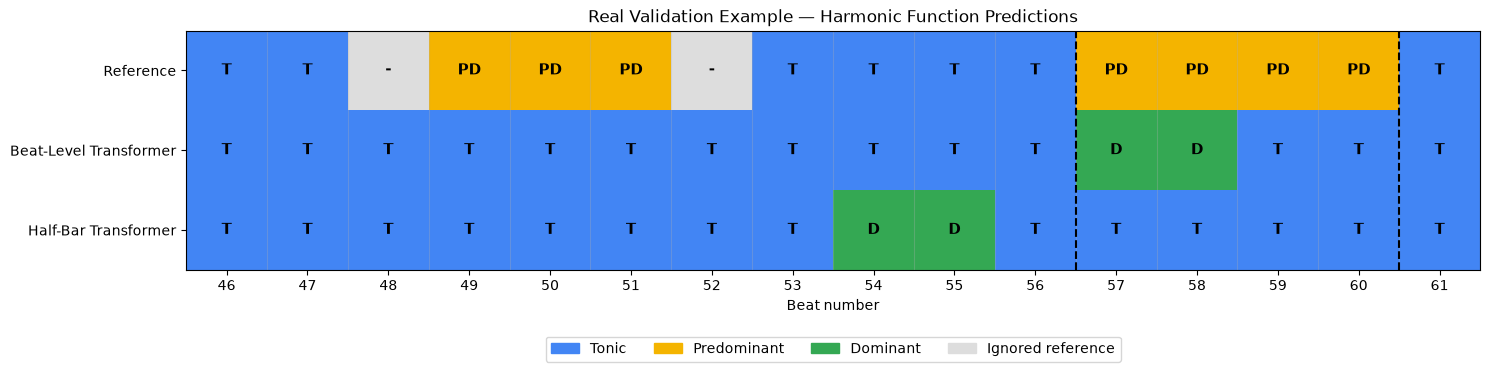


Visualization completed!


In [46]:
# ==========================================
# PHASE 3 — REAL HARMONIC PREDICTION VISUALIZATION
# ==========================================

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# ==========================================
# 1. Load best trained models
# ==========================================

# Beat-level Transformer

beat_checkpoint = torch.load(
    FUNCTION_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

beat_model = create_function_model(
    temporal_strength=TEMPORAL_STRENGTH
)

beat_model.load_state_dict(
    beat_checkpoint["model_state_dict"]
)

beat_model.eval()


# Half-bar Transformer

halfbar_checkpoint = torch.load(
    HALFBAR_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

halfbar_model.load_state_dict(
    halfbar_checkpoint["model_state_dict"]
)

halfbar_model.eval()


# ==========================================
# 2. Find a real validation example
# ==========================================

# Find 16 consecutive beats containing
# at least two reference function changes.
#
# Selection uses labels only, not predictions.

selected = None

for batch in val_loader:

    targets = make_function_targets(batch)

    B, T = targets.shape

    lengths = (
        ~batch["beat_padding_mask"]
    ).sum(dim=1)

    for b in range(B):

        length = int(lengths[b])

        for start in range(length - 15):

            segment = targets[
                b, start:start + 16
            ]

            valid = (
                segment != IGNORE_INDEX
            )

            changes = (
                valid[:-1]
                & valid[1:]
                & (segment[:-1] != segment[1:])
            )

            if (
                changes.sum().item() >= 2
                and valid.sum().item() >= 12
            ):

                selected = (batch, b, start)
                break

        if selected is not None:
            break

    if selected is not None:
        break


assert selected is not None, (
    "No suitable validation segment found."
)

batch, b, start = selected

end = start + 16


# ==========================================
# 3. Generate real predictions
# ==========================================

with torch.no_grad():

    # Beat-level predictions

    beat_inputs = {
        key: batch[key]
        for key in DIRECT_INPUT_KEYS
    }

    beat_logits = beat_model(
        beat_inputs
    )

    beat_predictions = (
        beat_logits.argmax(dim=-1)
    )


    # Half-bar predictions

    (
        region_inputs,
        region_targets,
        beat_to_region
    ) = build_halfbar_batch(batch)

    region_logits = halfbar_model(
        region_inputs
    )

    region_predictions = (
        region_logits.argmax(dim=-1)
    )

    halfbar_predictions = (
        expand_region_predictions(
            region_predictions,
            beat_to_region
        )
    )


# ==========================================
# 4. Extract real sequences
# ==========================================

targets = make_function_targets(batch)

actual = targets[
    b, start:end
].tolist()

pred_beat = beat_predictions[
    b, start:end
].tolist()

pred_halfbar = halfbar_predictions[
    b, start:end
].tolist()


# ==========================================
# 5. Convert class IDs to labels
# ==========================================

SHORT_NAMES = {
    0: "T",
    1: "PD",
    2: "D",
    IGNORE_INDEX: "-"
}

def label_name(value):
    return SHORT_NAMES.get(int(value), "-")


# ==========================================
# 6. Print real prediction sequences
# ==========================================

beat_numbers = list(
    range(start + 1, end + 1)
)

def print_sequence(name, values):

    text = " ".join(
        f"{label_name(v):>4}"
        for v in values
    )

    print(f"{name:<14}{text}")


print("REAL VALIDATION HARMONIC FUNCTIONS")
print("--------------------------------")

print(
    f"{'Beat:':<14}"
    + " ".join(
        f"{n:>4}"
        for n in beat_numbers
    )
)

print_sequence("Actual:", actual)
print_sequence("Beat model:", pred_beat)
print_sequence("Half-bar:", pred_halfbar)


# ==========================================
# 7. Create detailed comparison table
# ==========================================

rows = []

for j in range(16):

    i = start + j

    reference = actual[j]

    beat_pred = pred_beat[j]
    half_pred = pred_halfbar[j]

    valid = reference != IGNORE_INDEX

    actual_change = False

    if j > 0:

        previous = actual[j - 1]

        actual_change = (
            reference != IGNORE_INDEX
            and previous != IGNORE_INDEX
            and reference != previous
        )

    rows.append({
        "Beat": i + 1,

        "Bar": int(
            batch["bar_index"][b, i]
        ) + 1,

        "Position": int(
            batch["beat_position"][b, i]
        ),

        "Time (s)": float(
            batch["beat_time"][b, i, 0]
        ),

        "Actual": label_name(reference),

        "Beat model": label_name(beat_pred),

        "Half-bar model": label_name(half_pred),

        "Actual change":
            "YES" if actual_change else "",

        "Beat correct":
            "✓" if valid and reference == beat_pred
            else ("✗" if valid else "-"),

        "Half-bar correct":
            "✓" if valid and reference == half_pred
            else ("✗" if valid else "-")
    })


comparison_table = pd.DataFrame(rows)

print("\nDETAILED BEAT COMPARISON")
print("--------------------------------")

display(
    comparison_table.round(3)
)


# ==========================================
# 8. Visualize sequences
# ==========================================

# 0 = Tonic
# 1 = Predominant
# 2 = Dominant
# 3 = Ignored reference

def visualization_values(values):

    return [
        3 if value == IGNORE_INDEX
        else int(value)
        for value in values
    ]


matrix = np.array([
    visualization_values(actual),
    visualization_values(pred_beat),
    visualization_values(pred_halfbar)
])


colors = [
    "#4285F4",  # Tonic
    "#F4B400",  # Predominant
    "#34A853",  # Dominant
    "#DDDDDD"   # Ignored
]

cmap = ListedColormap(colors)


fig, ax = plt.subplots(
    figsize=(15, 4)
)

ax.imshow(
    matrix,
    cmap=cmap,
    vmin=-0.5,
    vmax=3.5,
    aspect="auto",
    interpolation="nearest"
)


# ==========================================
# 9. Add labels inside each beat
# ==========================================

for row_index, sequence in enumerate(
    [actual, pred_beat, pred_halfbar]
):

    for column_index, value in enumerate(sequence):

        ax.text(
            column_index,
            row_index,
            label_name(value),
            ha="center",
            va="center",
            fontsize=11,
            fontweight="bold"
        )


# ==========================================
# 10. Highlight actual function changes
# ==========================================

for j in range(1, 16):

    if (
        actual[j] != IGNORE_INDEX
        and actual[j - 1] != IGNORE_INDEX
        and actual[j] != actual[j - 1]
    ):

        ax.axvline(
            x=j - 0.5,
            color="black",
            linestyle="--",
            linewidth=1.5
        )


ax.set_xticks(range(16))

ax.set_xticklabels(
    beat_numbers
)

ax.set_yticks([0, 1, 2])

ax.set_yticklabels([
    "Reference",
    "Beat-Level Transformer",
    "Half-Bar Transformer"
])

ax.set_xlabel("Beat number")

ax.set_title(
    "Real Validation Example — Harmonic Function Predictions"
)

ax.set_xticks(
    np.arange(-0.5, 16, 1),
    minor=True
)

ax.grid(
    which="minor",
    axis="x",
    alpha=0.3
)

ax.tick_params(
    which="minor",
    bottom=False
)


legend_items = [
    Patch(color=colors[0], label="Tonic"),
    Patch(color=colors[1], label="Predominant"),
    Patch(color=colors[2], label="Dominant"),
    Patch(color=colors[3], label="Ignored reference")
]

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=4
)

plt.tight_layout()
plt.show()


print("\nVisualization completed!")

### RANDOM SONG PREDICTION VISUALIZER

RANDOM VALIDATION SONG
--------------------------------
Track: track_1056816
Dataset index: 961
Song windows: 4
Window beats: 64
Displayed beats: 32–63
Beat-Level Accuracy: 89.66%
Half-Bar Accuracy: 79.31%
Songs visited: 11


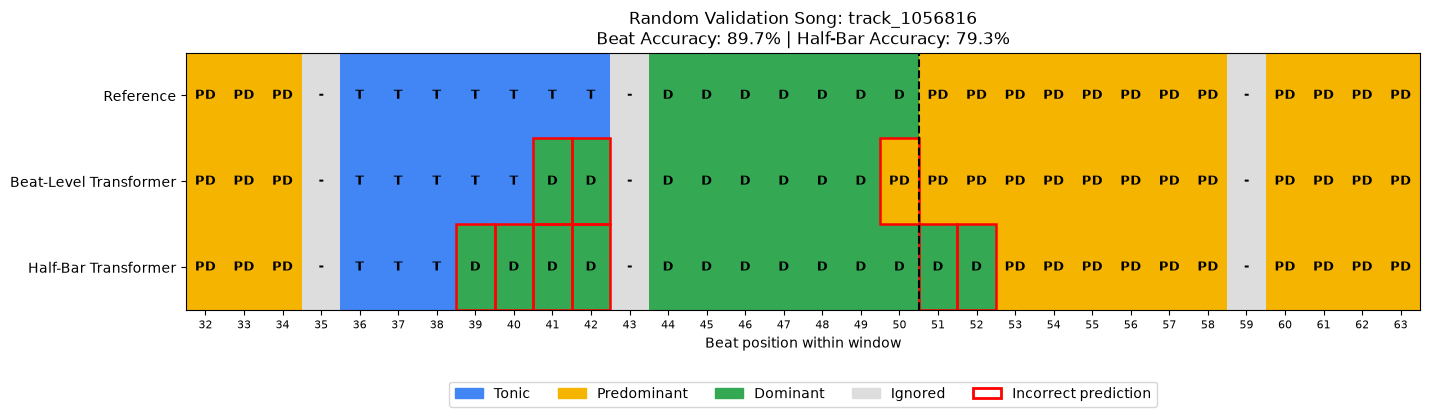


DETAILED PREDICTIONS
--------------------------------


,Beat,Bar,Beat in bar,Reference,Beat prediction,Half-bar prediction,Beat correct,Half-bar correct
0,32,8,4,PD,PD,PD,✓,✓
1,33,9,1,PD,PD,PD,✓,✓
2,34,9,2,PD,PD,PD,✓,✓
3,35,9,3,-,PD,T,-,-
4,36,9,4,T,T,T,✓,✓
5,37,10,1,T,T,T,✓,✓
6,38,10,2,T,T,T,✓,✓
7,39,10,3,T,T,D,✓,✗
8,40,10,4,T,T,D,✓,✗
9,41,11,1,T,D,D,✗,✗



VISUALIZATION SUMMARY
--------------------------------
Random song: track_1056816
Valid reference beats: 29
Beat-level accuracy: 89.66%
Half-bar accuracy: 79.31%
Model weights changed: NO
Dataset modified: NO
Test dataset accessed: NO

Run this cell again for another song!


In [57]:
# ==========================================
# PHASE 3 — RANDOM SONG PREDICTION VISUALIZER
# ==========================================

import json
import random
from pathlib import Path

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch, Rectangle


# ==========================================
# 1. Configuration
# ==========================================

# Number of consecutive beats to display.
# Set to None to show the entire 16-bar window.

DISPLAY_BEATS = 32

DATASET_JSONL = Path(
    "/Users/praise/Developer/vocal-harmonization/"
    "datasets/mtg-jamendo/phase3-prepared/"
    "windows_v2_7family_timing_provisional.jsonl"
)

FUNCTION_NAMES = {
    0: "T",
    1: "PD",
    2: "D",
    -100: "-"
}

FUNCTION_COLORS = [
    "#4285F4",  # Tonic
    "#F4B400",  # Predominant
    "#34A853",  # Dominant
    "#DDDDDD"   # Ignored
]


# ==========================================
# 2. Load validation song metadata
# ==========================================

# Assumption:
# val_dataset preserves the order of validation
# records from the prepared JSONL file.

if "_random_vis_metadata" not in globals():

    validation_records = []

    with open(DATASET_JSONL, "r") as file:

        for line in file:

            record = json.loads(line)

            if record["split"] == "val":
                validation_records.append(record)

    assert len(validation_records) == len(val_dataset), (
        "Validation dataset ordering/count differs "
        "from the JSONL. Check dataset construction."
    )

    song_indices = {}

    for index, record in enumerate(validation_records):

        track_id = record["track_id"]

        song_indices.setdefault(
            track_id, []
        ).append(index)

    _random_vis_metadata = song_indices

song_indices = _random_vis_metadata


# ==========================================
# 3. Select a random song
# ==========================================

# Keep track of previously displayed songs.

if "_visualized_val_songs" not in globals():
    _visualized_val_songs = set()

remaining_songs = [
    track
    for track in song_indices
    if track not in _visualized_val_songs
]

# Start again after all songs are visited.

if not remaining_songs:

    _visualized_val_songs.clear()

    remaining_songs = list(
        song_indices.keys()
    )

selected_track = random.choice(
    remaining_songs
)

_visualized_val_songs.add(
    selected_track
)

# Random window belonging to that song.

selected_index = random.choice(
    song_indices[selected_track]
)


# ==========================================
# 4. Prepare selected example
# ==========================================

# Reuse the existing DataLoader collator.

sample = val_dataset[selected_index]

batch = val_loader.collate_fn(
    [sample]
)

real_beat_count = int(
    (~batch["beat_padding_mask"][0])
    .sum().item()
)


# ==========================================
# 5. Load trained Transformers
# ==========================================

# Beat-level model

beat_model = create_function_model(
    temporal_strength=TEMPORAL_STRENGTH
)

beat_checkpoint = torch.load(
    FUNCTION_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

beat_model.load_state_dict(
    beat_checkpoint["model_state_dict"]
)

beat_model.eval()


# Half-bar model

halfbar_vis_model = create_function_model(
    temporal_strength=TEMPORAL_STRENGTH
)

halfbar_checkpoint = torch.load(
    HALFBAR_CHECKPOINT_PATH,
    map_location="cpu",
    weights_only=True
)

halfbar_vis_model.load_state_dict(
    halfbar_checkpoint["model_state_dict"]
)

halfbar_vis_model.eval()


# ==========================================
# 6. Generate actual predictions
# ==========================================

with torch.no_grad():

    # Reference harmonic functions

    reference = make_function_targets(
        batch
    )[0]


    # Beat-level Transformer

    beat_inputs = {
        key: batch[key]
        for key in DIRECT_INPUT_KEYS
    }

    beat_logits = beat_model(
        beat_inputs
    )

    beat_predictions = (
        beat_logits.argmax(dim=-1)[0]
    )


    # Half-bar Transformer

    (
        region_inputs,
        region_targets,
        beat_to_region
    ) = build_halfbar_batch(batch)

    region_logits = halfbar_vis_model(
        region_inputs
    )

    region_predictions = (
        region_logits.argmax(dim=-1)
    )

    halfbar_predictions = (
        expand_region_predictions(
            region_predictions,
            beat_to_region
        )[0]
    )


# ==========================================
# 7. Select portion to display
# ==========================================

if DISPLAY_BEATS is None:

    display_count = real_beat_count

else:

    display_count = min(
        DISPLAY_BEATS,
        real_beat_count
    )

max_start = (
    real_beat_count - display_count
)

start = random.randint(
    0,
    max_start
)

end = start + display_count


actual = reference[
    start:end
].tolist()

pred_beat = beat_predictions[
    start:end
].tolist()

pred_halfbar = halfbar_predictions[
    start:end
].tolist()


# ==========================================
# 8. Calculate example accuracy
# ==========================================

valid = reference[
    start:end
] != IGNORE_INDEX

valid_count = int(
    valid.sum().item()
)

if valid_count > 0:

    beat_correct = (
        beat_predictions[start:end][valid]
        ==
        reference[start:end][valid]
    ).sum().item()

    halfbar_correct = (
        halfbar_predictions[start:end][valid]
        ==
        reference[start:end][valid]
    ).sum().item()

    beat_accuracy = (
        beat_correct / valid_count
    )

    halfbar_accuracy = (
        halfbar_correct / valid_count
    )

else:

    beat_accuracy = float("nan")
    halfbar_accuracy = float("nan")


# ==========================================
# 9. Print example information
# ==========================================

print("RANDOM VALIDATION SONG")
print("--------------------------------")

print("Track:", selected_track)

print(
    "Dataset index:",
    selected_index
)

print(
    "Song windows:",
    len(song_indices[selected_track])
)

print(
    "Window beats:",
    real_beat_count
)

print(
    "Displayed beats:",
    f"{start + 1}–{end}"
)

print(
    "Beat-Level Accuracy:",
    f"{beat_accuracy:.2%}"
)

print(
    "Half-Bar Accuracy:",
    f"{halfbar_accuracy:.2%}"
)

print(
    "Songs visited:",
    len(_visualized_val_songs)
)


# ==========================================
# 10. Build visualization matrix
# ==========================================

def to_visual_ids(values):

    return [
        3 if value == IGNORE_INDEX
        else int(value)
        for value in values
    ]


matrix = np.array([
    to_visual_ids(actual),
    to_visual_ids(pred_beat),
    to_visual_ids(pred_halfbar)
])


# Hide model predictions at positions
# without reliable reference labels.

for j, target in enumerate(actual):

    if target == IGNORE_INDEX:

        matrix[1, j] = 3
        matrix[2, j] = 3


# ==========================================
# 11. Plot harmonic timeline
# ==========================================

fig_width = max(
    14,
    display_count * 0.45
)

fig, ax = plt.subplots(
    figsize=(fig_width, 4.5)
)

cmap = ListedColormap(
    FUNCTION_COLORS
)

ax.imshow(
    matrix,
    cmap=cmap,
    vmin=-0.5,
    vmax=3.5,
    aspect="auto",
    interpolation="nearest"
)


# ------------------------------------------
# Add labels and incorrect prediction borders
# ------------------------------------------

sequences = [
    actual,
    pred_beat,
    pred_halfbar
]

for row, sequence in enumerate(sequences):

    for j, value in enumerate(sequence):

        if actual[j] == IGNORE_INDEX:
            label = "-"

        else:
            label = FUNCTION_NAMES[value]

        ax.text(
            j,
            row,
            label,
            ha="center",
            va="center",
            fontsize=9,
            fontweight="bold"
        )

        # Highlight incorrect predictions.

        if (
            row > 0
            and actual[j] != IGNORE_INDEX
            and value != actual[j]
        ):

            ax.add_patch(
                Rectangle(
                    (j - 0.5, row - 0.5),
                    1,
                    1,
                    fill=False,
                    edgecolor="red",
                    linewidth=1.8
                )
            )


# ------------------------------------------
# Mark reference harmonic changes
# ------------------------------------------

for j in range(1, display_count):

    if (
        actual[j] != IGNORE_INDEX
        and actual[j - 1] != IGNORE_INDEX
        and actual[j] != actual[j - 1]
    ):

        ax.axvline(
            j - 0.5,
            color="black",
            linestyle="--",
            linewidth=1.5
        )


# ------------------------------------------
# Add labels
# ------------------------------------------

ax.set_yticks([0, 1, 2])

ax.set_yticklabels([
    "Reference",
    "Beat-Level Transformer",
    "Half-Bar Transformer"
])

ax.set_xticks(
    range(display_count)
)

ax.set_xticklabels(
    range(start + 1, end + 1),
    fontsize=8
)

ax.set_xlabel(
    "Beat position within window"
)

ax.set_title(
    f"Random Validation Song: {selected_track}\n"
    f"Beat Accuracy: {beat_accuracy:.1%} | "
    f"Half-Bar Accuracy: {halfbar_accuracy:.1%}"
)

legend_items = [
    Patch(
        color=FUNCTION_COLORS[0],
        label="Tonic"
    ),
    Patch(
        color=FUNCTION_COLORS[1],
        label="Predominant"
    ),
    Patch(
        color=FUNCTION_COLORS[2],
        label="Dominant"
    ),
    Patch(
        color=FUNCTION_COLORS[3],
        label="Ignored"
    ),
    Patch(
        facecolor="none",
        edgecolor="red",
        linewidth=2,
        label="Incorrect prediction"
    )
]

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.25),
    ncol=5
)

plt.tight_layout()
plt.show()


# ==========================================
# 12. Detailed actual prediction table
# ==========================================

rows = []

for j in range(display_count):

    i = start + j

    true_value = actual[j]

    beat_value = pred_beat[j]

    half_value = pred_halfbar[j]

    valid_target = (
        true_value != IGNORE_INDEX
    )

    rows.append({

        "Beat": i + 1,

        "Bar": int(
            batch["bar_index"][0, i]
        ) + 1,

        "Beat in bar": int(
            batch["beat_position"][0, i]
        ),

        "Reference":
            FUNCTION_NAMES[true_value],

        "Beat prediction":
            FUNCTION_NAMES[beat_value],

        "Half-bar prediction":
            FUNCTION_NAMES[half_value],

        "Beat correct":
            (
                "✓" if true_value == beat_value
                else "✗"
            ) if valid_target else "-",

        "Half-bar correct":
            (
                "✓" if true_value == half_value
                else "✗"
            ) if valid_target else "-"
    })


random_prediction_df = pd.DataFrame(
    rows
)

print("\nDETAILED PREDICTIONS")
print("--------------------------------")

display(random_prediction_df)


# ==========================================
# 13. Final summary
# ==========================================

print("\nVISUALIZATION SUMMARY")
print("--------------------------------")

print("Random song:", selected_track)

print(
    "Valid reference beats:",
    valid_count
)

print(
    "Beat-level accuracy:",
    f"{beat_accuracy:.2%}"
)

print(
    "Half-bar accuracy:",
    f"{halfbar_accuracy:.2%}"
)

print("Model weights changed: NO")
print("Dataset modified: NO")
print("Test dataset accessed: NO")

print("\nRun this cell again for another song!")

### RANDOM ROMAN-NUMERAL PREDICTIONS


RANDOM VALIDATION SONG
--------------------------------
Track: track_1012601
Dataset index: 729
Available windows for song: 1
Displayed beats: 1–24
Valid chord targets: 23
Songs visited: 22

MODEL ACCURACY COMPARISON
--------------------------------


,Model,Root accuracy,Family accuracy,Joint accuracy
0,Direct (unweighted),0.5217,0.3478,0.0000
1,Direct (weighted),0.0000,0.6522,0.0000
2,Flat 84-class,0.1304,0.1739,0.0000
3,Temporal,0.3478,0.5652,0.3478
4,Genre,0.2174,0.3478,0.0000
5,Temporal + Genre,0.5652,0.6522,0.4783


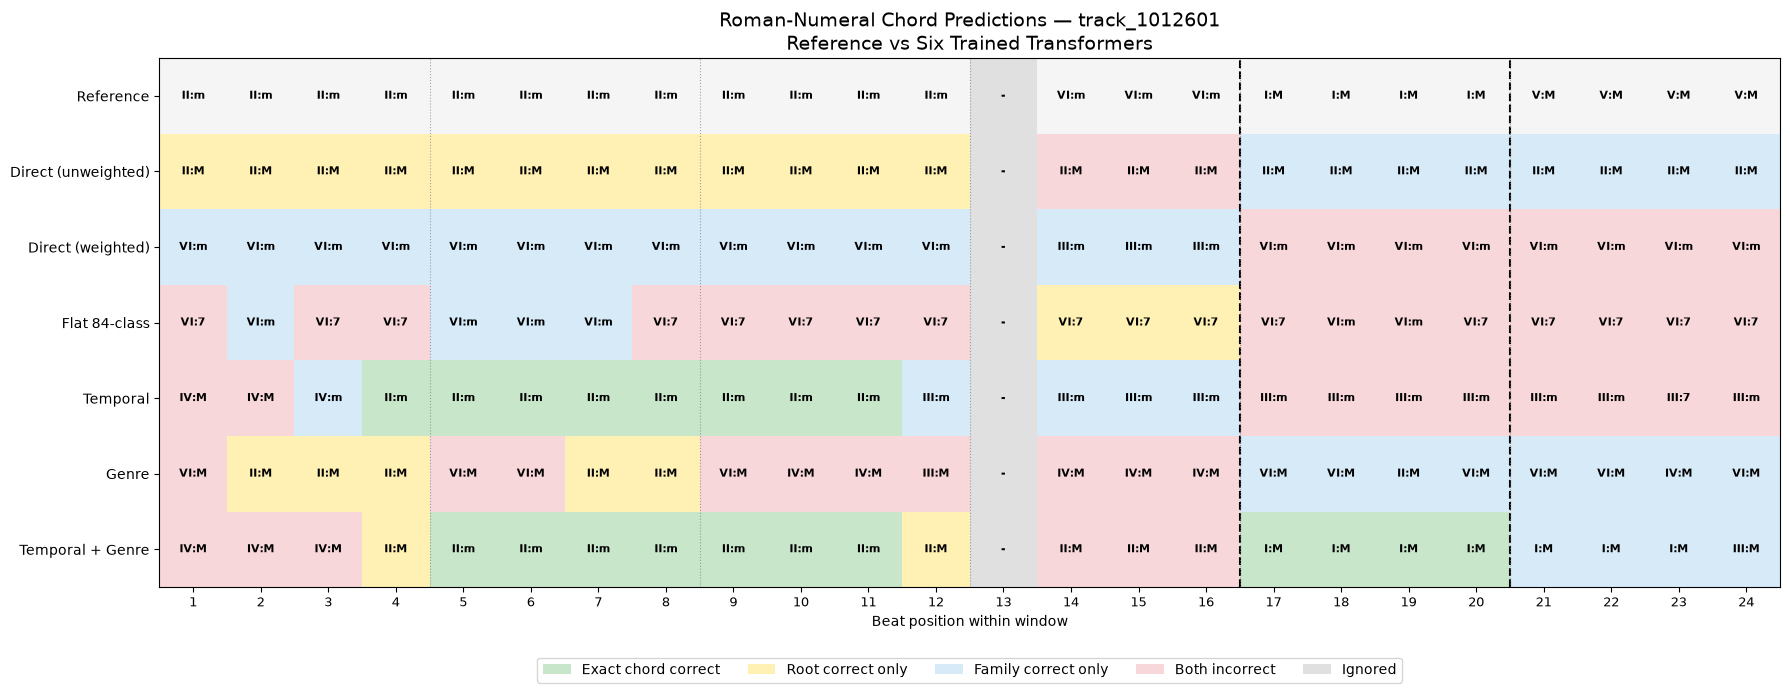


DETAILED ROMAN-NUMERAL PREDICTIONS
--------------------------------


,Beat,Bar,Beat in bar,Reference,Direct (unweighted),Direct (weighted),Flat 84-class,Temporal,Genre,Temporal + Genre
0,1,1,1,II:MIN,II:MAJ,VI:MIN,VI:DOM,IV:MAJ,VI:MAJ,IV:MAJ
1,2,1,2,II:MIN,II:MAJ,VI:MIN,VI:MIN,IV:MAJ,II:MAJ,IV:MAJ
2,3,1,3,II:MIN,II:MAJ,VI:MIN,VI:DOM,IV:MIN,II:MAJ,IV:MAJ
3,4,1,4,II:MIN,II:MAJ,VI:MIN,VI:DOM,II:MIN,II:MAJ,II:MAJ
4,5,2,1,II:MIN,II:MAJ,VI:MIN,VI:MIN,II:MIN,VI:MAJ,II:MIN
5,6,2,2,II:MIN,II:MAJ,VI:MIN,VI:MIN,II:MIN,VI:MAJ,II:MIN
6,7,2,3,II:MIN,II:MAJ,VI:MIN,VI:MIN,II:MIN,II:MAJ,II:MIN
7,8,2,4,II:MIN,II:MAJ,VI:MIN,VI:DOM,II:MIN,II:MAJ,II:MIN
8,9,3,1,II:MIN,II:MAJ,VI:MIN,VI:DOM,II:MIN,VI:MAJ,II:MIN
9,10,3,2,II:MIN,II:MAJ,VI:MIN,VI:DOM,II:MIN,IV:MAJ,II:MIN



VISUALIZATION SUMMARY
--------------------------------
Track: track_1012601
Models compared: 6
Valid reference beats: 23
Best model for this excerpt: Temporal + Genre
Best excerpt joint accuracy: 47.83%
Model parameters changed: NO
Dataset modified: NO
Test dataset accessed: NO

Run this cell again for another song!


In [79]:
# ==========================================
# PHASE 3 — RANDOM ROMAN-NUMERAL PREDICTIONS
# ==========================================

import random
import json
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


# ==========================================
# 1. Configuration
# ==========================================

# Number of beats displayed.
# Use None for the entire window.

DISPLAY_BEATS = 24

# All six previously trained models.

MODEL_NAMES = [
    "Direct (unweighted)",
    "Direct (weighted)",
    "Flat 84-class",
    "Temporal",
    "Genre",
    "Temporal + Genre"
]

# Abbreviations for visualization.

FAMILY_SHORT = {
    "MAJ": "M",
    "MIN": "m",
    "DOM": "7",
    "DIM": "dim",
    "HDIM": "ø",
    "AUG": "+",
    "SUS": "sus"
}

# Colors indicate prediction correctness.

STATUS_COLORS = [
    "#F8D7DA",  # Both incorrect
    "#D6EAF8",  # Family correct
    "#FFF0B3",  # Root correct
    "#C8E6C9",  # Exact match
    "#E0E0E0",  # Ignored
    "#F5F5F5"   # Reference
]


# ==========================================
# 2. Prepare validation song lookup
# ==========================================

# Reuse metadata from Cell 42 when available.

if "_random_vis_metadata" in globals():

    chord_song_indices = _random_vis_metadata

else:

    DATASET_JSONL = Path(
        "/Users/praise/Developer/vocal-harmonization/"
        "datasets/mtg-jamendo/phase3-prepared/"
        "windows_v2_7family_timing_provisional.jsonl"
    )

    validation_records = []

    with open(DATASET_JSONL, "r") as file:

        for line in file:

            record = json.loads(line)

            if record["split"] == "val":
                validation_records.append(record)

    assert len(validation_records) == len(val_dataset)

    chord_song_indices = {}

    for index, record in enumerate(validation_records):

        track = record["track_id"]

        chord_song_indices.setdefault(
            track, []
        ).append(index)


# ==========================================
# 3. Select random validation song
# ==========================================

if "_roman_visited_songs" not in globals():

    _roman_visited_songs = set()


available_songs = [
    track
    for track in chord_song_indices
    if track not in _roman_visited_songs
]

if not available_songs:

    _roman_visited_songs.clear()

    available_songs = list(
        chord_song_indices.keys()
    )


selected_track = random.choice(
    available_songs
)

_roman_visited_songs.add(
    selected_track
)

selected_index = random.choice(
    chord_song_indices[selected_track]
)


# ==========================================
# 4. Prepare validation batch
# ==========================================

sample = val_dataset[selected_index]

# Validate song identity if the Dataset
# exposes its own track identifier.

if isinstance(sample, dict) and "track_id" in sample:

    assert str(sample["track_id"]) == selected_track, (
        "Dataset order does not match JSONL metadata."
    )

batch = val_loader.collate_fn(
    [sample]
)

real_beats = int(
    (~batch["beat_padding_mask"][0])
    .sum().item()
)


# ==========================================
# 5. Select random excerpt
# ==========================================

if DISPLAY_BEATS is None:

    display_count = real_beats

else:

    display_count = min(
        DISPLAY_BEATS,
        real_beats
    )

start = random.randint(
    0,
    real_beats - display_count
)

end = start + display_count


# ==========================================
# 6. Read reference chord labels
# ==========================================

true_root = batch["target_root"][0]

true_family = batch["target_family"][0]

valid_mask = batch[
    "target_valid_mask"
][0].bool()

valid_mask = (
    valid_mask
    & (true_root != IGNORE_INDEX)
    & (true_family != IGNORE_INDEX)
)


# ==========================================
# 7. Roman-numeral label decoder
# ==========================================

def decode_chord(root_id, family_id, short=False):

    root_id = int(root_id)
    family_id = int(family_id)

    if root_id < 0 or family_id < 0:
        return "-"

    root = ROOT_LABELS[root_id]
    family = FAMILY_LABELS[family_id]

    if short:
        family = FAMILY_SHORT.get(
            family,
            family
        )

    return f"{root}:{family}"


# ==========================================
# 8. Load trained models
# ==========================================

# Cache models so running this cell again
# does not reload every checkpoint.

if "_roman_visual_models" not in globals():

    _roman_visual_models = {}

    print("Loading trained Transformers...")

    for spec in model_specs:

        if spec["name"] not in MODEL_NAMES:
            continue

        model, epoch = load_function_model(
            spec
        )

        model.eval()

        _roman_visual_models[
            spec["name"]
        ] = {
            "model": model,
            "epoch": epoch,
            "spec": spec
        }

assert set(MODEL_NAMES).issubset(
    _roman_visual_models.keys()
)


# ==========================================
# 9. Generate chord predictions
# ==========================================

predictions = {}

with torch.no_grad():

    for name in MODEL_NAMES:

        entry = _roman_visual_models[name]

        model = entry["model"]
        spec = entry["spec"]

        input_keys = (
            GENRE_INPUT_KEYS
            if spec["genre"]
            else DIRECT_INPUT_KEYS
        )

        inputs = {
            key: batch[key]
            for key in input_keys
        }

        if spec["joint84"]:

            # Flat 84-class prediction.

            joint_logits = model(inputs)

            joint_ids = (
                joint_logits.argmax(dim=-1)
            )

            pred_root = (
                joint_ids // NUM_FAMILIES
            )

            pred_family = (
                joint_ids % NUM_FAMILIES
            )

        else:

            # Separate root/family prediction.

            root_logits, family_logits = (
                model(inputs)
            )

            pred_root = (
                root_logits.argmax(dim=-1)
            )

            pred_family = (
                family_logits.argmax(dim=-1)
            )

        predictions[name] = {
            "root": pred_root[0],
            "family": pred_family[0]
        }


# ==========================================
# 10. Calculate model accuracies
# ==========================================

valid = valid_mask[start:end]

n_valid = int(
    valid.sum().item()
)

assert n_valid > 0

summary_rows = []

for name in MODEL_NAMES:

    pred_root = predictions[name]["root"][
        start:end
    ]

    pred_family = predictions[name]["family"][
        start:end
    ]

    actual_root = true_root[start:end]
    actual_family = true_family[start:end]

    root_correct = (
        pred_root == actual_root
    )

    family_correct = (
        pred_family == actual_family
    )

    joint_correct = (
        root_correct & family_correct
    )

    summary_rows.append({
        "Model": name,

        "Root accuracy":
            root_correct[valid]
            .float().mean().item(),

        "Family accuracy":
            family_correct[valid]
            .float().mean().item(),

        "Joint accuracy":
            joint_correct[valid]
            .float().mean().item()
    })


roman_summary_df = pd.DataFrame(
    summary_rows
)


# ==========================================
# 11. Print selected song information
# ==========================================

print("\nRANDOM VALIDATION SONG")
print("--------------------------------")

print("Track:", selected_track)

print("Dataset index:", selected_index)

print(
    "Available windows for song:",
    len(chord_song_indices[selected_track])
)

print(
    "Displayed beats:",
    f"{start + 1}–{end}"
)

print("Valid chord targets:", n_valid)

print(
    "Songs visited:",
    len(_roman_visited_songs)
)

print("\nMODEL ACCURACY COMPARISON")
print("--------------------------------")

display(
    roman_summary_df.round(4)
)


# ==========================================
# 12. Build visualization data
# ==========================================

row_names = [
    "Reference"
] + MODEL_NAMES

n_rows = len(row_names)

# Status values:
#
# 0 = Both wrong
# 1 = Family only correct
# 2 = Root only correct
# 3 = Exact match
# 4 = Ignored
# 5 = Reference

status_matrix = np.full(
    (n_rows, display_count),
    5,
    dtype=int
)

text_matrix = [
    [""] * display_count
    for _ in range(n_rows)
]


for j in range(display_count):

    i = start + j

    reference_valid = bool(
        valid_mask[i]
    )

    # ----------------------------------
    # Reference row
    # ----------------------------------

    if reference_valid:

        text_matrix[0][j] = decode_chord(
            true_root[i],
            true_family[i],
            short=True
        )

    else:

        text_matrix[0][j] = "-"
        status_matrix[0, j] = 4

    # ----------------------------------
    # Model prediction rows
    # ----------------------------------

    for model_index, name in enumerate(
        MODEL_NAMES
    ):

        row = model_index + 1

        pred_root = predictions[name][
            "root"
        ][i]

        pred_family = predictions[name][
            "family"
        ][i]

        if not reference_valid:

            status_matrix[row, j] = 4
            text_matrix[row][j] = "-"

            continue

        text_matrix[row][j] = decode_chord(
            pred_root,
            pred_family,
            short=True
        )

        root_correct = (
            pred_root == true_root[i]
        )

        family_correct = (
            pred_family == true_family[i]
        )

        if root_correct and family_correct:

            status = 3

        elif root_correct:

            status = 2

        elif family_correct:

            status = 1

        else:

            status = 0

        status_matrix[row, j] = status


# ==========================================
# 13. Plot predictions
# ==========================================

fig_width = max(
    18,
    display_count * 0.75
)

fig_height = (
    2.5 + n_rows * 0.65
)

fig, ax = plt.subplots(
    figsize=(fig_width, fig_height)
)

cmap = ListedColormap(
    STATUS_COLORS
)

ax.imshow(
    status_matrix,
    cmap=cmap,
    vmin=-0.5,
    vmax=5.5,
    aspect="auto",
    interpolation="nearest"
)


# ==========================================
# 14. Add chord labels
# ==========================================

for row in range(n_rows):

    for col in range(display_count):

        ax.text(
            col,
            row,
            text_matrix[row][col],
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold"
        )


# ==========================================
# 15. Highlight reference chord changes
# ==========================================

for j in range(1, display_count):

    i = start + j

    if (
        valid_mask[i]
        and valid_mask[i - 1]
        and (
            true_root[i] != true_root[i - 1]
            or
            true_family[i] != true_family[i - 1]
        )
    ):

        ax.axvline(
            j - 0.5,
            color="black",
            linestyle="--",
            linewidth=1.5
        )


# ==========================================
# 16. Add bar boundaries
# ==========================================

for j in range(1, display_count):

    i = start + j

    if (
        batch["bar_index"][0, i]
        != batch["bar_index"][0, i - 1]
    ):

        ax.axvline(
            j - 0.5,
            color="gray",
            linestyle=":",
            linewidth=0.8,
            alpha=0.7
        )


# ==========================================
# 17. Format chart
# ==========================================

ax.set_yticks(
    range(n_rows)
)

ax.set_yticklabels(
    row_names,
    fontsize=10
)

ax.set_xticks(
    range(display_count)
)

ax.set_xticklabels(
    range(start + 1, end + 1),
    fontsize=9
)

ax.set_xlabel(
    "Beat position within window"
)

ax.set_title(
    f"Roman-Numeral Chord Predictions — {selected_track}\n"
    "Reference vs Six Trained Transformers",
    fontsize=14
)

legend_items = [
    Patch(
        facecolor=STATUS_COLORS[3],
        label="Exact chord correct"
    ),
    Patch(
        facecolor=STATUS_COLORS[2],
        label="Root correct only"
    ),
    Patch(
        facecolor=STATUS_COLORS[1],
        label="Family correct only"
    ),
    Patch(
        facecolor=STATUS_COLORS[0],
        label="Both incorrect"
    ),
    Patch(
        facecolor=STATUS_COLORS[4],
        label="Ignored"
    )
]

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=5
)

plt.tight_layout()
plt.show()


# ==========================================
# 18. Detailed chord prediction table
# ==========================================

detail_rows = []

for j in range(display_count):

    i = start + j

    reliable = bool(
        valid_mask[i]
    )

    row = {
        "Beat": i + 1,

        "Bar": int(
            batch["bar_index"][0, i]
        ) + 1,

        "Beat in bar": int(
            batch["beat_position"][0, i]
        ),

        "Reference": (
            decode_chord(
                true_root[i],
                true_family[i]
            )
            if reliable
            else "-"
        )
    }

    for name in MODEL_NAMES:

        if reliable:

            label = decode_chord(
                predictions[name]["root"][i],
                predictions[name]["family"][i]
            )

        else:

            label = "-"

        row[name] = label

    detail_rows.append(row)


roman_detail_df = pd.DataFrame(
    detail_rows
)

print("\nDETAILED ROMAN-NUMERAL PREDICTIONS")
print("--------------------------------")

display(roman_detail_df)


# ==========================================
# 19. Final summary
# ==========================================

print("\nVISUALIZATION SUMMARY")
print("--------------------------------")

print("Track:", selected_track)
print("Models compared:", len(MODEL_NAMES))

print("Valid reference beats:", n_valid)

best_row = roman_summary_df.loc[
    roman_summary_df["Joint accuracy"].idxmax()
]

print(
    "Best model for this excerpt:",
    best_row["Model"]
)

print(
    "Best excerpt joint accuracy:",
    f"{best_row['Joint accuracy']:.2%}"
)

print("Model parameters changed: NO")
print("Dataset modified: NO")
print("Test dataset accessed: NO")

print("\nRun this cell again for another song!")

#### How to read the visualization
Unlike the earlier chart, which used colors for the three harmonic functions, this chart uses colors to represent prediction correctness.
| Color | Meaning | Example |
|---|---|---|
| 🟩 Green | Exact chord label correct | Actual `VI:MIN`, predicted `VI:MIN` |
| 🟨 Yellow | Correct root, wrong family | Actual `V:DOM`, predicted `V:MAJ` |
| 🟦 Blue | Wrong root, correct family | Actual `IV:MAJ`, predicted `I:MAJ` |
| 🟥 Red | Both root and family incorrect | Actual `II:MIN`, predicted `V:MAJ` |
| ⬜ Gray | Unreliable reference | No evaluation |